In [159]:
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import os

In [160]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

class LinePatternDataset(Dataset):
    """
    Simple 2-class dataset of line patterns
    
    Class 0: Vertical lines
        columns of alternating full and blank
        | _ | _ | _ |
    
    Class 1: Horizontal lines
        rows of alternating full and blank
        ___
           
        ___
           
    Single channel images with noise
    Images stored as numpy arrays
    converted to tensor on __getitem__
    """
    
    def __init__(self,
                 n_samples:    int   = 500,
                 image_size:   int   = 32,
                 noise_std:    float = 0.1,
                 line_value:   float = 1,
                 blank_value:  float = 0.0,
                 seed:         int   = 42):
        """
        Args:
            n_samples:   total images (split evenly between classes)
            image_size:  H=W of each image
            noise_std:   std of gaussian noise added per image
            line_value:  pixel value for filled lines
            blank_value: pixel value for blank lines
            seed:        random seed for reproducibility
        """
        self.n_samples   = n_samples
        self.image_size  = image_size
        self.noise_std   = noise_std
        self.line_value  = line_value
        self.blank_value = blank_value
        
        self.rng         = np.random.default_rng(seed)
        
        self.images, self.labels = self._generate()
    
    def _make_vertical(self):
        """
        Vertical lines pattern:
            column 0: full  (line_value)
            column 1: blank (blank_value)
            column 2: full
            column 3: blank
            ...
        
        Shape: (image_size, image_size)
        """
        img = np.zeros(
            (self.image_size, self.image_size),
            dtype=np.float32
        )
        # Fill even columns with line_value
        img[:, 0::2] = self.line_value
        return img
    
    def _make_horizontal(self):
        """
        Horizontal lines pattern:
            row 0: full  (line_value)
            row 1: blank (blank_value)
            row 2: full
            row 3: blank
            ...
        
        Shape: (image_size, image_size)
        """
        img = np.zeros(
            (self.image_size, self.image_size),
            dtype=np.float32
        )
        # Fill even rows with line_value
        img[0::2, :] = self.line_value
        return img
    
    def _generate(self):
        """
        Generate all images
        Returns:
            images: (n_samples, 1, H, W) float32
            labels: (n_samples,) int64
        """
        n_per_class = self.n_samples // 2
        n_total     = n_per_class * 2
        
        images = np.zeros(
            (n_total, 1, self.image_size, self.image_size),
            dtype=np.float32
        )
        labels = np.zeros(n_total, dtype=np.int64)
        
        # Base patterns (no noise)
        base_vertical   = self._make_vertical()
        base_horizontal = self._make_horizontal()
        
        # Class 0: vertical lines
        for i in range(n_per_class):
            noise        = self.rng.normal(
                0, self.noise_std,
                size=(self.image_size, self.image_size)
            ).astype(np.float32)
            img          = base_vertical + noise
            img          = np.clip(img, 0.0, 1.0)
            images[i, 0] = img
            labels[i]    = 0
        
        # Class 1: horizontal lines
        for i in range(n_per_class):
            idx          = n_per_class + i
            noise        = self.rng.normal(
                0, self.noise_std,
                size=(self.image_size, self.image_size)
            ).astype(np.float32)
            img            = base_horizontal + noise
            img            = np.clip(img, 0.0, 1.0)
            images[idx, 0] = img
            labels[idx]    = 1
        
        # Shuffle
        perm   = self.rng.permutation(n_total)
        images = images[perm]
        labels = labels[perm]
        
        return images, labels
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        """
        Returns:
            image: torch tensor (1, H, W) float32
            label: torch tensor scalar int64
        """
        img   = torch.from_numpy(self.images[idx])
        label = torch.tensor(self.labels[idx],
                              dtype=torch.long)
        return img, label


def make_line_dataloaders(
    n_train:    int   = 500,
    n_val:      int   = 100,
    image_size: int   = 32,
    noise_std:  float = 0.1,
    batch_size: int   = 32,
    seed:       int   = 42
):
    """
    Create train and val DataLoaders
    for the line pattern dataset
    """
    train_dataset = LinePatternDataset(
        n_samples  = n_train,
        image_size = image_size,
        noise_std  = noise_std,
        seed       = seed
    )
    
    val_dataset = LinePatternDataset(
        n_samples  = n_val,
        image_size = image_size,
        noise_std  = noise_std,
        seed       = seed + 1   # different seed for val
    )
    
    train_loader = DataLoader(
        train_dataset,
        batch_size = batch_size,
        shuffle    = True
    )
    
    val_loader = DataLoader(
        val_dataset,
        batch_size = batch_size,
        shuffle    = False
    )
    
    print(f"Line Pattern Dataset:")
    print(f"  Image size:  {image_size}x{image_size}  "
          f"(1 channel)")
    print(f"  Train:       {n_train} images  "
          f"({n_train//2} per class)")
    print(f"  Val:         {n_val} images  "
          f"({n_val//2} per class)")
    print(f"  Noise std:   {noise_std}")
    print(f"  Batch size:  {batch_size}")
    
    return train_loader, val_loader


def visualize_line_dataset(train_loader, n_show=8):
    """
    Show sample images from each class
    """
    import matplotlib.pyplot as plt
    
    class0_imgs = []
    class1_imgs = []
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if cls == 0 and len(class0_imgs) < n_show:
                class0_imgs.append(img[0].numpy())
            if cls == 1 and len(class1_imgs) < n_show:
                class1_imgs.append(img[0].numpy())
        if (len(class0_imgs) >= n_show and
                len(class1_imgs) >= n_show):
            break
    
    fig, axes = plt.subplots(
        2, n_show,
        figsize=(2 * n_show, 5)
    )
    
    for col in range(n_show):
        
        axes[0, col].imshow(
            class0_imgs[col],
            cmap='gray', vmin=0, vmax=1
        )
        axes[0, col].set_title(
            f'Class 0\nVertical', fontsize=8
        )
        axes[0, col].axis('off')
        
        axes[1, col].imshow(
            class1_imgs[col],
            cmap='gray', vmin=0, vmax=1
        )
        axes[1, col].set_title(
            f'Class 1\nHorizontal', fontsize=8
        )
        axes[1, col].axis('off')
    
    plt.suptitle(
        f'Line Pattern Dataset\n'
        f'Class 0 = Vertical lines  '
        f'Class 1 = Horizontal lines',
        fontsize=13
    )
    plt.tight_layout()
    plt.show()
    
    # Show pixel value distributions
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    c0_flat = np.array(class0_imgs).flatten()
    c1_flat = np.array(class1_imgs).flatten()
    
    axes[0].hist(c0_flat, bins=30, color='blue',
                  alpha=0.7, label='Vertical')
    axes[0].hist(c1_flat, bins=30, color='red',
                  alpha=0.7, label='Horizontal')
    axes[0].set_title('Pixel value distribution')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Show mean images
    axes[1].imshow(
        np.stack([np.mean(class0_imgs, axis=0),
                  np.mean(class1_imgs, axis=0),
                  np.zeros_like(class0_imgs[0])],
                 axis=-1),
        vmin=0, vmax=1
    )
    axes[1].set_title(
        'Mean images\nBlue=Vertical  Red=Horizontal'
    )
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

Line Pattern Dataset:
  Image size:  16x16  (1 channel)
  Train:       500 images  (250 per class)
  Val:         100 images  (50 per class)
  Noise std:   0.8
  Batch size:  32


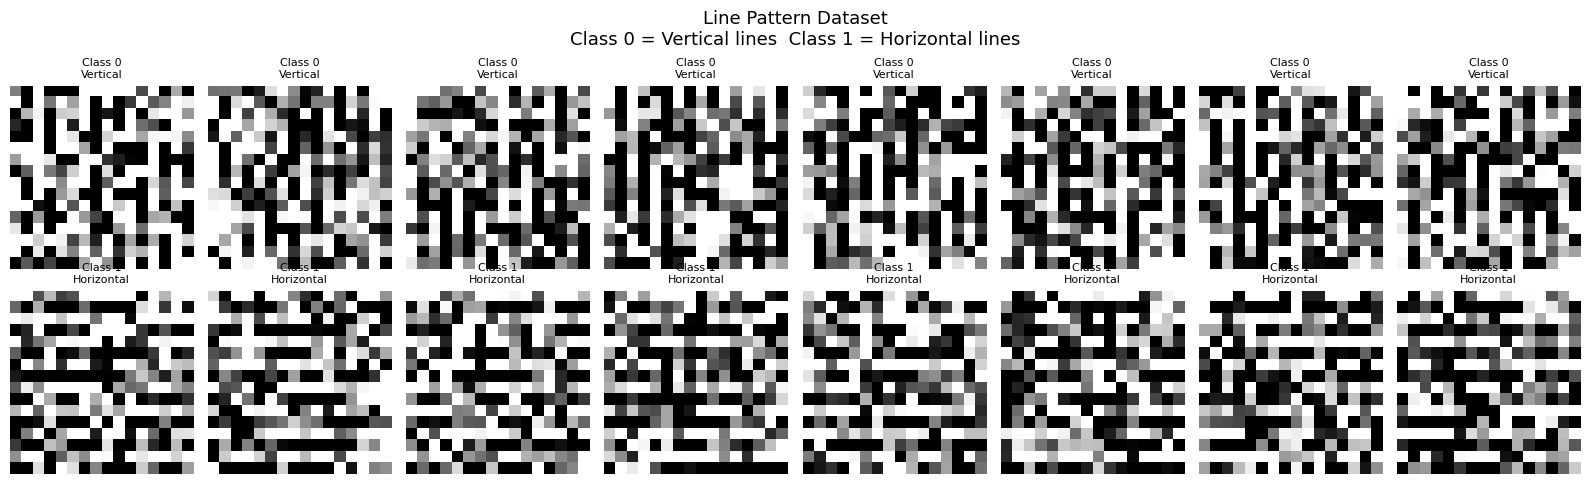

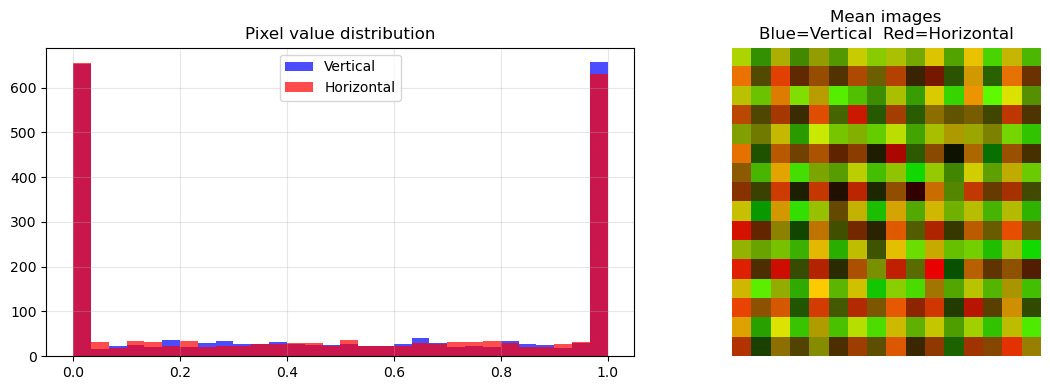

Batch shape: torch.Size([32, 1, 16, 16])
Labels:      tensor([0, 0, 1, 0, 0, 1, 1, 0])
Dtype:       torch.float32
Value range: [0.000, 1.000]


In [161]:
# Create dataloaders
linetrain_loader, lineval_loader = make_line_dataloaders(
    n_train    = 500,
    n_val      = 100,
    image_size = 16,
    noise_std  = 0.8,
    batch_size = 32,
    seed       = 42
)

# Visualize
visualize_line_dataset(linetrain_loader)

# Verify format matches fruit dataset
images, labels = next(iter(linetrain_loader))
print(f"Batch shape: {images.shape}")
print(f"Labels:      {labels[:8]}")
print(f"Dtype:       {images.dtype}")
print(f"Value range: [{images.min():.3f}, "
      f"{images.max():.3f}]")

In [162]:
# Data preprocessing: added lots of augmentations to make model better at generalization
# Has 6 classes with 3 fruits and whether they are fresh or rotten
# Made one dataset on only fresh peaches and fresh pomegranates so easier to train

datadir = "/Users/sasv/Documents/Stanford/REU/archive/"
num_training_images = 229
num_validation_images = 20
num_test_images = 1

class CustomDataset(Dataset):
    def __init__(self, root_dir, rnge, num_class=6, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.images = []
        self.labels = []
        
        # Get class names from folder names
        self.classes = sorted(os.listdir(root_dir))[1:]
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}
        #print(self.class_to_idx)
        
        # Collect all image paths and labels
        class_count = 0
        for class_name in self.classes:
            if class_name.startswith('.'):  # skips .DS_Store and any hidden file
                continue
            print(class_name)
            class_count += 1
            class_path = os.path.join(root_dir, class_name)
            for img_file in os.listdir(class_path)[rnge[0]:rnge[1]]:
                if img_file.endswith(('.jpg')):
                    self.images.append(os.path.join(class_path, img_file))
                    self.labels.append(self.class_to_idx[class_name])
            if class_count == num_class:
                break
        
        print('\n')
    
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        img_path = self.images[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label
    
train_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    
    # Add more augmentation
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.2,
    ),
    transforms.RandomGrayscale(p=0.1),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)  # random shift
    ),
    
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
    
train_dataset = CustomDataset(root_dir=datadir, rnge=(0, num_training_images), transform=train_transforms)
short_dataset = CustomDataset(root_dir=datadir, rnge=(0, num_training_images//6), transform=train_transforms)
twoclasstrain_dataset = CustomDataset(root_dir=datadir, rnge=(0, num_training_images), num_class=2, transform=train_transforms)
print(len(twoclasstrain_dataset))
validation_dataset = CustomDataset(root_dir=datadir, rnge=(num_training_images, num_training_images + num_validation_images), transform=val_transforms)
twoclassval_dataset = CustomDataset(root_dir=datadir, rnge=(num_training_images, num_training_images + num_validation_images), num_class=2, transform=train_transforms)
test_dataset = CustomDataset(root_dir=datadir, rnge=(num_training_images + num_validation_images, num_training_images + num_validation_images + num_test_images), transform=val_transforms)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')
short_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')
twoclasstrain_loader = DataLoader(twoclasstrain_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')
val_loader = DataLoader(validation_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')
twoclassval_loader = DataLoader(twoclassval_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')

fresh_peaches_done
fresh_pomegranates_done
fresh_strawberries_done
rotten_peaches_done
rotten_pomegranates_done
rotten_strawberries_done


fresh_peaches_done
fresh_pomegranates_done
fresh_strawberries_done
rotten_peaches_done
rotten_pomegranates_done
rotten_strawberries_done


fresh_peaches_done
fresh_pomegranates_done


458
fresh_peaches_done
fresh_pomegranates_done
fresh_strawberries_done
rotten_peaches_done
rotten_pomegranates_done
rotten_strawberries_done


fresh_peaches_done
fresh_pomegranates_done


fresh_peaches_done
fresh_pomegranates_done
fresh_strawberries_done
rotten_peaches_done
rotten_pomegranates_done
rotten_strawberries_done




In [203]:
from dataclasses import dataclass, field
from typing import List, Tuple
import math


def U(x: float) -> float:
    """Uncertainty function used in the surrogate gradient."""
    return 0.5 / (1.0 + abs(x))

def Up(x: float) -> float:
    """Derivative of U(x)."""
    s = 1.0 if x > 0 else -1.0
    return -0.5 * s / ((1.0 + abs(x)) ** 2)

def softmax(logits: np.ndarray) -> np.ndarray:
    """
    Convert raw logits into probabilities.

    Args:
        logits: shape (vocab_size,)

    Returns:
        probs: shape (vocab_size,)
    """
    z = logits - np.max(logits)
    ez = np.exp(z)
    return ez / np.sum(ez)

def cross_entropy_from_logits(logits: np.ndarray, target: int) -> Tuple[float, np.ndarray]:
    """
    Compute next-token cross-entropy loss and dL/dlogits.

    Args:
        logits: shape (vocab_size,)
        target: integer target index

    Returns:
        loss: scalar
        grad: shape (vocab_size,)
    """
    probs = softmax(logits)
    loss = -math.log(float(probs[target]) + 1e-12)
    grad = probs.copy()
    grad[target] -= 1.0
    return loss, grad

def learning_rate_schedule(t: int) -> float:
    """Warmup + inverse-square-root decay schedule."""
    if t <= 0:
        return 0.0
    return min(1.0 / math.sqrt(t), t / 4000.0 / math.sqrt(4000.0))

def image_to_numpy(image_path, size=32):
    """Load image and convert to numpy array normalized to [-1, 1]"""
    img    = Image.open(image_path).convert('RGB').resize((size, size))
    arr    = np.array(img).astype(np.float32) / 127.5 - 1.0
    return arr.transpose(2, 0, 1)   # (H,W,C) -> (C,H,W)

def image_lr_schedule(epoch: int, 
                      base_lr: float   = 0.001,
                      decay:   float   = 0.99) -> float:
    """Simple exponential decay schedule"""
    return base_lr * (decay ** epoch)

def preprocess_for_lut(img_tensor: torch.Tensor) -> np.ndarray:
    """
    Convert tensor to numpy and normalize per image
    so LUT comparisons are meaningful
    """
    x    = img_tensor.numpy()   # (3, H, W)
    
    # Normalize each channel to [-1, 1]
    for c in range(x.shape[0]):
        ch   = x[c]
        mean = ch.mean()
        std  = ch.std() + 1e-8
        x[c] = (ch - mean) / std
    
    return x


@dataclass
class LUTCache:
    """
    Cached information from a LUT forward pass.

    Arrays:
        j     : shape (n_tables,)
        r_min : shape (n_tables,)
        u_min : shape (n_tables,)
    """
    j: np.ndarray
    r_min: np.ndarray
    u_min: np.ndarray

    @classmethod
    def empty(cls, n_tables: int) -> "LUTCache":
        return cls(
            j=np.zeros(n_tables, dtype=np.int64),
            r_min=np.zeros(n_tables, dtype=np.int64),
            u_min=np.full(n_tables, np.inf, dtype=np.float64),
        )


@dataclass
class LUT:
    input_dim:        int
    output_dim:       int
    n_tables:         int
    n_comparisons:    int
    total_index_bits: int
    rng:              np.random.Generator
    s_init:           int = 0.1
    
    anchors_a:  np.ndarray = field(init=False)
    anchors_b:  np.ndarray = field(init=False)
    S:          np.ndarray = field(init=False)
    S_momentum: np.ndarray = field(init=False)
    momentum:   float      = 0.9

    def __post_init__(self) -> None:
        self.anchors_a = self.rng.integers(
            0, self.input_dim,
            size=(self.n_tables, self.n_comparisons),
            dtype=np.int64
        )
        self.anchors_b = self.rng.integers(
            0, self.input_dim,
            size=(self.n_tables, self.n_comparisons),
            dtype=np.int64
        )
        same = self.anchors_a == self.anchors_b
        while np.any(same):
            self.anchors_b[same] = self.rng.integers(
                0, self.input_dim, size=np.sum(same)
            )
            same = self.anchors_a == self.anchors_b

        table_size    = 1 << self.total_index_bits
        self.S        = self.rng.normal(
            0, self.s_init,
            size=(self.n_tables, table_size, self.output_dim)
        ).astype(np.float64)
        self.S_momentum = np.zeros_like(self.S)

    def cache_index(self, x: np.ndarray) -> LUTCache:
        cache = LUTCache.empty(self.n_tables)
        for nt in range(self.n_tables):
            index = ""
            umin  = np.inf
            rmin  = 0
            for nc in range(self.n_comparisons):
                u = (x[self.anchors_a[nt][nc]]
                     - x[self.anchors_b[nt][nc]])
                if abs(u) < abs(umin):
                    umin = u
                    rmin = nc
                index += "1" if u > 0 else "0"
            cache.j[nt]     = int(index, 2)
            cache.r_min[nt] = rmin
            cache.u_min[nt] = umin
        return cache

    def forward_from_cache(self,
                            cache:      LUTCache,
                            table_mask: np.ndarray = None
                            ) -> np.ndarray:
        """
        Args:
            cache:      LUTCache from cache_index
            table_mask: optional (n_tables,) float array
                        1.0 = table active
                        0.0 = table dropped
                        None = all tables active
        
        Returns:
            y: (output_dim,) sum of active table outputs
        """
        y = np.zeros(self.output_dim, dtype=np.float64)
        
        for nt in range(self.n_tables):
            
            # Skip dropped tables entirely
            if table_mask is not None:
                if table_mask[nt] == 0.0:
                    continue
            
            contribution = self.S[nt][cache.j[nt]]
            
            if table_mask is not None:
                contribution = contribution * table_mask[nt]
            
            y += contribution
        
        return y

    def backward_from_cache(
        self,
        cache:      LUTCache,
        y_grad:     np.ndarray,
        learning_rate: float,
        table_mask: np.ndarray = None,
    ) -> np.ndarray:
        """
        Args:
            cache:      LUTCache from matching forward
            y_grad:     dL/dy shape (output_dim,)
            learning_rate: scalar
            table_mask: same mask used in forward
                        dropped tables get no gradient
                        and no S update
        """
        x_grad = np.zeros(self.input_dim,  dtype=np.float64)
        count  = np.zeros(self.input_dim,  dtype=np.float64)
        
        for nt in range(self.n_tables):
            
            # Dropped tables:
            #   No S update
            #   No surrogate gradient contribution
            if table_mask is not None:
                if table_mask[nt] == 0.0:
                    continue
            
            j    = cache.j[nt]
            jbar = j ^ (1 << cache.r_min[nt])
            
            diff      = self.S[nt][jbar] - self.S[nt][j]
            
            gnt = np.dot(y_grad, diff)
            v   = gnt * Up(cache.u_min[nt])
            
            a = self.anchors_a[nt][cache.r_min[nt]]
            b = self.anchors_b[nt][cache.r_min[nt]]
            
            x_grad[a] += v
            x_grad[b] -= v
            count[a]  += 1.0
            count[b]  += 1.0
            
            # S update with momentum
            # Scale grad by table_mask for active tables
            # (mask is 1/p_keep for active, 0 for dropped)
            effective_grad = y_grad
            if table_mask is not None:
                effective_grad = y_grad * table_mask[nt]
            
            '''# Momentum update instead of plain SGD
            self.S_momentum[nt][j] = (
                self.momentum * self.S_momentum[nt][j]
                + (1 - self.momentum) * effective_grad     
            )
            self.S[nt][j] -= learning_rate * self.S_momentum[nt][j]'''

            self.S[nt][j] -= learning_rate * effective_grad
            
        
        #count  = np.maximum(count, 1.0)
        x_grad = x_grad# / count
        
        return x_grad

In [183]:
@dataclass
class LUTConvLayerV2:
    """
    Redesigned LUT Conv that mirrors CNN structure
    
    Each table produces ONE output channel
    n_tables = out_channels
    
    For each patch:
        Table 0 -> single number -> channel 0
        Table 1 -> single number -> channel 1
        ...
        Table n_tables-1 -> single number -> channel n_tables-1
    
    S shape: (n_tables, table_size, 1)
             one scalar output per table row
    """
    in_channels:   int
    out_channels:  int          # = n_tables
    kernel_size:   int
    n_comparisons: int          # controls table_size = 2^n_comparisons
    rng:           np.random.Generator
    
    # n_tables is now determined by out_channels
    n_tables:      int        = field(init=False)
    patch_dim:     int        = field(init=False)
    lut:           LUT        = field(init=False)
    all_caches:    list       = field(default_factory=list, init=False)
    input_padded:  np.ndarray = field(init=False)
    j_all:         np.ndarray = field(init=False)
    rmin_all:      np.ndarray = field(init=False)
    umin_all:      np.ndarray = field(init=False)
    patches:       np.ndarray = field(init=False)
    H_out:         int        = field(init=False)
    W_out:         int        = field(init=False)

    def __post_init__(self):
        # n_tables = out_channels
        # each table produces one channel
        self.n_tables  = self.out_channels
        self.patch_dim = self.kernel_size ** 2 * self.in_channels
        
        self.lut = LUT(
            input_dim        = self.patch_dim,
            output_dim       = 1,              # ✅ single scalar per table
            n_tables         = self.n_tables,  # ✅ one table per channel
            n_comparisons    = self.n_comparisons,
            total_index_bits = self.n_comparisons,
            rng              = self.rng
        )
        
        #print(f"  LUTConvLayerV2: {self.in_channels} -> {self.out_channels}")
        #print(f"    n_tables:      {self.n_tables} (= out_channels)")
        #print(f"    n_comparisons: {self.n_comparisons}")
        #print(f"    table_size:    {1 << self.n_comparisons}")
        #print(f"    S shape:       {self.lut.S.shape}")

    def im2col_vectorized(self, x_pad, H_out, W_out):
        from numpy.lib.stride_tricks import as_strided
        C       = self.in_channels
        ks      = self.kernel_size
        shape   = (H_out, W_out, C, ks, ks)
        s       = x_pad.strides
        strides = (s[1], s[2], s[0], s[1], s[2])
        patches = as_strided(x_pad, shape=shape, strides=strides)
        return patches.reshape(H_out * W_out, C * ks * ks).copy()

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Args:
            x: shape (in_channels, H, W)
        Returns:
            out: shape (out_channels, H, W)
                 out[t, i, j] = S[t, binary_index(patch_ij)]
                 each table produces one channel
        """
        C, H, W      = x.shape
        pad          = self.kernel_size // 2
        H_out, W_out = H, W
        n_patches    = H_out * W_out
        
        x_pad             = np.pad(
            x, ((0,0),(pad,pad),(pad,pad)), mode='constant'
        )
        self.input_padded = x_pad.copy()
        
        patches      = self.im2col_vectorized(x_pad, H_out, W_out)
        self.patches = patches
        # patches shape: (n_patches, patch_dim)
        
        # Binary comparisons for ALL patches and ALL tables
        vals_a   = patches[:, self.lut.anchors_a]
        vals_b   = patches[:, self.lut.anchors_b]
        diffs    = vals_a - vals_b
        # diffs shape: (n_patches, n_tables, n_comparisons)
        
        # Binary indices
        powers   = (1 << np.arange(self.n_comparisons))
        bits     = (diffs > 0).astype(np.int64)
        j_all    = (bits * powers[None, None, :]).sum(axis=2)
        # j_all shape: (n_patches, n_tables)
        
        # r_min and u_min
        abs_diffs = np.abs(diffs)
        rmin_all  = abs_diffs.argmin(axis=2)
        umin_all  = diffs[
            np.arange(n_patches)[:, None],
            np.arange(self.n_tables)[None, :],
            rmin_all
        ]
        
        # Table lookup
        # S shape: (n_tables, table_size, 1)
        # For table t, patch p: look up S[t, j_all[p,t], 0]
        table_idx    = np.arange(self.n_tables)[None, :]
        selected     = self.lut.S[table_idx, j_all, 0]
        # selected shape: (n_patches, n_tables)
        # selected[p, t] = scalar output of table t for patch p
        
        # Store for backward
        self.j_all    = j_all
        self.rmin_all = rmin_all
        self.umin_all = umin_all
        self.H_out    = H_out
        self.W_out    = W_out
        
        self.all_caches = [
            LUTCache(j=j_all[p], r_min=rmin_all[p], u_min=umin_all[p])
            for p in range(n_patches)
        ]
        
        # Reshape to spatial output
        # selected: (n_patches, n_tables) = (H*W, out_channels)
        out = selected.reshape(H_out, W_out, self.out_channels)
        out = out.transpose(2, 0, 1)   # (out_channels, H_out, W_out)
        
        return out

    def backward(self, grad_out: np.ndarray,
             learning_rate: float) -> np.ndarray:

        pad       = self.kernel_size // 2
        n_patches = self.H_out * self.W_out

        # (out_channels, H, W) -> (n_patches, n_tables)
        grad_flat = grad_out.transpose(1, 2, 0).reshape(
            n_patches, self.out_channels
        )

        j_all    = self.j_all
        rmin_all = self.rmin_all
        umin_all = self.umin_all
        jbar_all = j_all ^ (1 << rmin_all)

        table_idx = np.arange(self.n_tables)[None, :]

        S_j    = self.lut.S[table_idx, j_all,    0]  # (n_patches, n_tables)
        S_jbar = self.lut.S[table_idx, jbar_all, 0]  # (n_patches, n_tables)

        # ✅ Normalize diff to unit direction
        # keeps direction information from S
        # removes magnitude dependence on S values
        diff      = S_jbar - S_j
        diff_norm = np.abs(diff).mean() + 1e-8
        diff_unit = diff / diff_norm

        gi_all    = grad_flat * diff#_unit              # (n_patches, n_tables)

        # Surrogate: uncertainty weighting only
        # no scale factor dividing by n_tables
        signs  = np.sign(umin_all)
        signs[signs == 0] = 1.0
        Up_all = -0.5 * signs / ((1.0 + np.abs(umin_all)) ** 2)
        v_all  = gi_all * Up_all                       # (n_patches, n_tables)
        # ✅ No surrogate_scale division

        # Anchor indices
        table_idx_1d = np.arange(self.n_tables)
        a_all = self.lut.anchors_a[table_idx_1d, rmin_all]
        b_all = self.lut.anchors_b[table_idx_1d, rmin_all]

        # Accumulate patch gradients
        grad_patches = np.zeros((n_patches, self.patch_dim))
        for t in range(self.n_tables):
            np.add.at(grad_patches,
                      (np.arange(n_patches), a_all[:, t]),
                       v_all[:, t])
            np.add.at(grad_patches,
                      (np.arange(n_patches), b_all[:, t]),
                      -v_all[:, t])
        # ✅ No divide by n_tables here

        # Update S tables
        for t in range(self.n_tables):
            np.add.at(
                self.lut.S[t, :, 0],
                j_all[:, t],
                -learning_rate * grad_flat[:, t]
            )

        # Scatter back to spatial
        grad_patches_spatial = grad_patches.reshape(
            n_patches, self.in_channels,
            self.kernel_size, self.kernel_size
        )

        grad_in_pad = np.zeros((self.in_channels,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        count_pad   = np.zeros((1,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))

        for idx in range(n_patches):
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[:, i:i+self.kernel_size,
                           j:j+self.kernel_size] += \
                grad_patches_spatial[idx]
            count_pad[0, i:i+self.kernel_size,
                         j:j+self.kernel_size] += 1.0

        count_pad = np.maximum(count_pad, 1.0)
        grad_in   = grad_in_pad #/ count_pad
        # ✅ count_pad stays: this is correct spatial normalization
        #    prevents double counting overlapping patches
        #    not the same as the excess normalizations we removed

        if pad > 0:
            return grad_in[:, pad:-pad, pad:-pad]
        return grad_in

In [166]:
@dataclass
class LUTConvLayerV3:
    """
    Extended LUT Conv with multiple tables per output channel
    
    Each output channel = SUM of n_tables_per_channel table outputs
    
    This allows increasing parameters without:
        Increasing n_comparisons (hurts coverage)
        Increasing out_channels  (increases output size)
    
    Architecture:
        n_tables = out_channels * n_tables_per_channel
        
        For output channel c:
            tables used = [c*K, c*K+1, ..., c*K+K-1]
            where K = n_tables_per_channel
            
            output[c, i, j] = sum(
                S[c*K + k, j(patch_ij)] for k in range(K)
            )
    
    S shape: (n_tables, table_size, 1)
             where n_tables = out_channels * n_tables_per_channel
    """
    in_channels:          int
    out_channels:         int
    kernel_size:          int
    n_comparisons:        int
    n_tables_per_channel: int
    rng:                  np.random.Generator
    
    n_tables:   int        = field(init=False)
    patch_dim:  int        = field(init=False)
    lut:        LUT        = field(init=False)
    all_caches: list       = field(default_factory=list,
                                    init=False)
    j_all:      np.ndarray = field(init=False)
    rmin_all:   np.ndarray = field(init=False)
    umin_all:   np.ndarray = field(init=False)
    patches:    np.ndarray = field(init=False)
    H_out:      int        = field(init=False)
    W_out:      int        = field(init=False)

    def __post_init__(self):
        self.n_tables  = self.out_channels * self.n_tables_per_channel
        self.patch_dim = self.kernel_size ** 2 * self.in_channels
        
        self.lut = LUT(
            input_dim        = self.patch_dim,
            output_dim       = 1,
            n_tables         = self.n_tables,
            n_comparisons    = self.n_comparisons,
            total_index_bits = self.n_comparisons,
            rng              = self.rng
        )
        scale = 0.5 / np.sqrt(self.n_tables_per_channel)
        self.lut.S = self.rng.normal(
            0, scale,
            size=self.lut.S.shape
        )
        
        table_size = 1 << self.n_comparisons
        print(f"  LUTConvLayerV3:")
        print(f"    in_channels:          {self.in_channels}")
        print(f"    out_channels:         {self.out_channels}")
        print(f"    n_tables_per_channel: {self.n_tables_per_channel}")
        print(f"    n_tables total:       {self.n_tables}")
        print(f"    n_comparisons:        {self.n_comparisons}")
        print(f"    table_size:           {table_size}")
        print(f"    S shape:              {self.lut.S.shape}")
        print(f"    Total parameters:     "
              f"{self.n_tables * table_size:,}")

    def im2col_vectorized(self, x_pad, H_out, W_out):
        from numpy.lib.stride_tricks import as_strided
        C       = self.in_channels
        ks      = self.kernel_size
        shape   = (H_out, W_out, C, ks, ks)
        s       = x_pad.strides
        strides = (s[1], s[2], s[0], s[1], s[2])
        patches = as_strided(x_pad, shape=shape,
                              strides=strides)
        return patches.reshape(
            H_out * W_out, C * ks * ks
        ).copy()

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Args:
            x: (in_channels, H, W)
        Returns:
            out: (out_channels, H, W)
            
            For channel c:
            out[c] = sum of K table outputs
                   = S[c*K+0, j] + S[c*K+1, j] + ... + S[c*K+K-1, j]
        """
        C, H, W      = x.shape
        pad          = self.kernel_size // 2
        H_out, W_out = H, W
        n_patches    = H_out * W_out
        K            = self.n_tables_per_channel
        
        x_pad    = np.pad(x, ((0,0),(pad,pad),(pad,pad)))
        patches  = self.im2col_vectorized(x_pad, H_out, W_out)
        self.patches = patches
        # patches: (n_patches, patch_dim)
        
        # Comparisons for ALL tables
        vals_a   = patches[:, self.lut.anchors_a]
        vals_b   = patches[:, self.lut.anchors_b]
        diffs    = vals_a - vals_b
        # diffs: (n_patches, n_tables, n_comparisons)
        
        powers   = (1 << np.arange(self.n_comparisons))
        bits     = (diffs > 0).astype(np.int64)
        j_all    = (bits * powers[None, None, :]).sum(axis=2)
        # j_all: (n_patches, n_tables)
        
        abs_diffs = np.abs(diffs)
        rmin_all  = abs_diffs.argmin(axis=2)
        umin_all  = diffs[
            np.arange(n_patches)[:, None],
            np.arange(self.n_tables)[None, :],
            rmin_all
        ]
        
        # Table lookup for all tables
        table_idx = np.arange(self.n_tables)[None, :]
        selected  = self.lut.S[table_idx, j_all, 0]
        # selected: (n_patches, n_tables)
        
        self.j_all    = j_all
        self.rmin_all = rmin_all
        self.umin_all = umin_all
        self.H_out    = H_out
        self.W_out    = W_out
        
        self.all_caches = [
            LUTCache(
                j     = j_all[p],
                r_min = rmin_all[p],
                u_min = umin_all[p]
            )
            for p in range(n_patches)
        ]
        
        # Sum K tables per output channel
        # selected: (n_patches, n_tables)
        # reshape to (n_patches, out_channels, K)
        selected_grouped = selected.reshape(
            n_patches, self.out_channels, K
        )
        # sum over K tables -> (n_patches, out_channels)
        out_flat = selected_grouped.sum(axis=2)
        
        # Reshape to spatial
        out = out_flat.reshape(H_out, W_out, self.out_channels)
        out = out.transpose(2, 0, 1)
        # out: (out_channels, H_out, W_out)
        
        return out

    def backward(self, grad_out: np.ndarray,
                 learning_rate: float) -> np.ndarray:
        """
        Backward pass for V3
        
        Key difference from V2:
            grad_out has shape (out_channels, H, W)
            but S tables are indexed by n_tables
            = out_channels * K
            
            Gradient for table c*K+k
            = gradient for output channel c
            (all K tables in channel c get same gradient
             because output = sum of their values
             d(sum)/d(table_k) = 1 for each k)
        """
        pad       = self.kernel_size // 2
        n_patches = self.H_out * self.W_out
        K         = self.n_tables_per_channel
        
        # grad_out: (out_channels, H, W)
        # -> (n_patches, out_channels)
        grad_per_channel = grad_out.transpose(1, 2, 0).reshape(
            n_patches, self.out_channels
        )
        
        # Expand to all tables
        # Each channel c has K tables: c*K, c*K+1, ..., c*K+K-1
        # All K tables get the SAME gradient from channel c
        # because d(S[c*K+0] + ... + S[c*K+K-1]) / d(S[c*K+k]) = 1
        
        # grad_flat: (n_patches, n_tables)
        # = repeat each channel gradient K times
        grad_flat = np.repeat(grad_per_channel, K, axis=1)
        # grad_flat[:, c*K + k] = grad_per_channel[:, c]
        # for k in range(K)
        
        j_all    = self.j_all
        rmin_all = self.rmin_all
        umin_all = self.umin_all
        jbar_all = j_all ^ (1 << rmin_all)
        
        table_idx = np.arange(self.n_tables)[None, :]
        
        S_j    = self.lut.S[table_idx, j_all,    0]
        S_jbar = self.lut.S[table_idx, jbar_all, 0]
        
        # Normalized diff direction
        diff      = S_jbar - S_j
        diff_norm = np.abs(diff).mean() + 1e-8
        diff_unit = diff / diff_norm
        
        gi_all = grad_flat * diff#_unit
        
        # Surrogate gradient
        signs  = np.sign(umin_all)
        signs[signs == 0] = 1.0
        Up_all = -0.5 * signs / ((1.0 + np.abs(umin_all)) ** 2)
        v_all  = gi_all * Up_all
        # v_all: (n_patches, n_tables)
        
        # Anchor indices for r_min comparison
        table_idx_1d = np.arange(self.n_tables)
        a_all = self.lut.anchors_a[table_idx_1d, rmin_all]
        b_all = self.lut.anchors_b[table_idx_1d, rmin_all]
        
        # Accumulate patch gradients
        grad_patches = np.zeros((n_patches, self.patch_dim))
        for t in range(self.n_tables):
            np.add.at(grad_patches,
                      (np.arange(n_patches), a_all[:, t]),
                       v_all[:, t])
            np.add.at(grad_patches,
                      (np.arange(n_patches), b_all[:, t]),
                      -v_all[:, t])
        
        # Normalize by n_tables_per_channel
        # Each pixel receives gradient from K tables per channel
        # Average over K to keep gradient magnitude consistent
        # regardless of K value
        #grad_patches /= K
        
        # Update S tables
        for t in range(self.n_tables):
            np.add.at(
                self.lut.S[t, :, 0],
                j_all[:, t],
                -learning_rate * grad_flat[:, t]
            )
        
        # Scatter back to spatial
        grad_patches_spatial = grad_patches.reshape(
            n_patches, self.in_channels,
            self.kernel_size, self.kernel_size
        )
        
        grad_in_pad = np.zeros((self.in_channels,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        count_pad   = np.zeros((1,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        
        for idx in range(n_patches):
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[:, i:i+self.kernel_size,
                           j:j+self.kernel_size] += \
                grad_patches_spatial[idx]
            count_pad[0, i:i+self.kernel_size,
                         j:j+self.kernel_size] += 1.0
        
        count_pad = np.maximum(count_pad, 1.0)
        grad_in   = grad_in_pad
        
        if pad > 0:
            return grad_in[:, pad:-pad, pad:-pad]
        return grad_in

In [167]:
@dataclass
class LUTConvLayerV4:
    """
    LUT Conv with multi-dimensional table output
    
    Each table row stores output_dim values
    instead of a single scalar
    
    S shape: (n_tables, table_size, output_dim)
    
    For each patch:
        Table t -> row j -> S[t, j, :]  (output_dim values)
    
    Total output channels = n_tables * output_dim
    
    With n_tables_per_channel=K:
        Groups of K tables are summed
        Each group produces output_dim channels
        Total output channels = n_groups * output_dim
                              = (n_tables/K) * output_dim
    """
    in_channels:          int
    out_channels:         int   # n_groups = n_tables / K
    kernel_size:          int
    n_comparisons:        int
    output_dim:           int   # new: outputs per table row
    n_tables_per_channel: int   # K: tables per group
    rng:                  np.random.Generator
    
    n_tables:    int        = field(init=False)
    patch_dim:   int        = field(init=False)
    lut:         LUT        = field(init=False)
    all_caches:  list       = field(default_factory=list,
                                     init=False)
    j_all:       np.ndarray = field(init=False)
    rmin_all:    np.ndarray = field(init=False)
    umin_all:    np.ndarray = field(init=False)
    patches:     np.ndarray = field(init=False)
    H_out:       int        = field(init=False)
    W_out:       int        = field(init=False)

    def __post_init__(self):
        K              = self.n_tables_per_channel
        D              = self.output_dim
        self.n_tables  = self.out_channels * K
        self.patch_dim = self.kernel_size**2 * self.in_channels
        
        table_size     = 1 << self.n_comparisons
        
        self.lut = LUT(
            input_dim        = self.patch_dim,
            output_dim       = D,              # ✅ D outputs per row
            n_tables         = self.n_tables,
            n_comparisons    = self.n_comparisons,
            total_index_bits = self.n_comparisons,
            rng              = self.rng
        )
        # S shape: (n_tables, table_size, output_dim)
        
        # Scale init so channel output variance
        # stays consistent regardless of K and D
        scale          = 0.5 / np.sqrt(K)
        self.lut.S     = self.rng.normal(
            0, scale,
            size=(self.n_tables, table_size, D)
        ).astype(np.float64)
        
        total_out_ch   = self.out_channels * D
        clf_input      = total_out_ch * 8 * 8
        
        print(f"  LUTConvLayerV4:")
        print(f"    in_channels:          {self.in_channels}")
        print(f"    out_channels (groups):{self.out_channels}")
        print(f"    output_dim:           {D}")
        print(f"    n_tables_per_channel: {K}")
        print(f"    n_tables total:       {self.n_tables}")
        print(f"    table_size:           {table_size}")
        print(f"    S shape:              {self.lut.S.shape}")
        print(f"    Total output channels:{total_out_ch}")
        print(f"    S parameters:         "
              f"{self.n_tables * table_size * D:,}")

    def im2col_vectorized(self, x_pad, H_out, W_out):
        from numpy.lib.stride_tricks import as_strided
        C, ks   = self.in_channels, self.kernel_size
        shape   = (H_out, W_out, C, ks, ks)
        s       = x_pad.strides
        strides = (s[1], s[2], s[0], s[1], s[2])
        patches = as_strided(x_pad, shape=shape,
                              strides=strides)
        return patches.reshape(
            H_out * W_out, C * ks * ks
        ).copy()

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Returns:
            out: (out_channels * output_dim, H, W)
            
            For group g and output dimension d:
            out[g*D + d] = sum over K tables of S[t, j, d]
        """
        C, H, W      = x.shape
        pad          = self.kernel_size // 2
        H_out, W_out = H, W
        n_patches    = H_out * W_out
        K            = self.n_tables_per_channel
        D            = self.output_dim
        
        x_pad    = np.pad(x, ((0,0),(pad,pad),(pad,pad)))
        patches  = self.im2col_vectorized(x_pad, H_out, W_out)
        self.patches = patches
        # patches: (n_patches, patch_dim)
        
        # Binary comparisons
        vals_a   = patches[:, self.lut.anchors_a]
        vals_b   = patches[:, self.lut.anchors_b]
        diffs    = vals_a - vals_b
        
        '''noise_mask = np.zeros(
                self.n_comparisons, dtype=bool
            )
        noise_mask[3::4] = True

        if noise_mask.any():
            n_noise = noise_mask.sum()

            diffs[:, :, noise_mask] = \
                self.rng.normal(
                    loc   = 0.0,
                    scale = 0.5,
                    size  = (n_patches,
                             self.n_tables,
                             n_noise)
                )'''
        # diffs: (n_patches, n_tables, n_comparisons)
        
        powers   = (1 << np.arange(self.n_comparisons))
        bits     = (diffs > 0).astype(np.int64)
        
        '''noise_mask = np.zeros(self.n_comparisons, dtype=bool)
        noise_mask[3::4] = True   # bits 3, 7, 11, ...

        if noise_mask.any():
            n_patches_total = bits.shape[0]
            n_tables_total  = bits.shape[1]
            n_noise_bits    = noise_mask.sum()

            # Random 0 or 1 for noise positions
            random_bits = self.rng.integers(
                0, 2,
                size=(n_patches_total,
                      n_tables_total,
                      n_noise_bits)
            ).astype(np.int64)

            bits[:, :, noise_mask] = random_bits'''
        
        j_all    = (bits * powers[None, None, :]).sum(axis=2)
        # j_all: (n_patches, n_tables)
        
        abs_diffs = np.abs(diffs)
        rmin_all  = abs_diffs.argmin(axis=2)
        umin_all  = diffs[
            np.arange(n_patches)[:, None],
            np.arange(self.n_tables)[None, :],
            rmin_all
        ]
        
        self.j_all    = j_all
        self.rmin_all = rmin_all
        self.umin_all = umin_all
        self.H_out    = H_out
        self.W_out    = W_out
        
        self.all_caches = [
            LUTCache(j=j_all[p],
                     r_min=rmin_all[p],
                     u_min=umin_all[p])
            for p in range(n_patches)
        ]
        
        # Table lookup
        # S: (n_tables, table_size, D)
        # j_all: (n_patches, n_tables)
        # selected: (n_patches, n_tables, D)
        table_idx = np.arange(self.n_tables)
        selected  = self.lut.S[
            table_idx[None, :, None],
            j_all[:, :, None],
            np.arange(D)[None, None, :]
        ]
        # OR more simply:
        selected  = self.lut.S[
            table_idx[None, :],
            j_all,
            :
        ]
        # selected: (n_patches, n_tables, D)
        
        # Group K tables and sum
        # selected: (n_patches, n_tables, D)
        # reshape:  (n_patches, out_channels, K, D)
        selected_grouped = selected.reshape(
            n_patches, self.out_channels, K, D
        )
        # sum over K tables: (n_patches, out_channels, D)
        out_grouped = selected_grouped.sum(axis=2)
        
        # Flatten out_channels and D into one dimension
        # (n_patches, out_channels * D)
        out_flat = out_grouped.reshape(
            n_patches, self.out_channels * D
        )
        
        # Reshape to spatial
        total_out_ch = self.out_channels * D
        out = out_flat.reshape(H_out, W_out, total_out_ch)
        out = out.transpose(2, 0, 1)
        # out: (out_channels * D, H_out, W_out)
        
        return out

    def backward(self, grad_out: np.ndarray,
                 learning_rate: float) -> np.ndarray:
        """
        grad_out: (out_channels * output_dim, H, W)
        
        Key difference from V3:
            Each table outputs D values
            grad arrives with D gradients per table
            S[t, j, d] gets gradient d separately
            
            S update: S[t, j, d] -= lr * grad[d]
            for each d independently
        """
        pad       = self.kernel_size // 2
        n_patches = self.H_out * self.W_out
        K         = self.n_tables_per_channel
        D         = self.output_dim
        
        total_out_ch = self.out_channels * D
        
        # grad_out: (out_channels*D, H, W)
        # -> (n_patches, out_channels*D)
        grad_flat_all = grad_out.transpose(1, 2, 0).reshape(
            n_patches, total_out_ch
        )
        
        # Reshape to (n_patches, out_channels, D)
        grad_per_group = grad_flat_all.reshape(
            n_patches, self.out_channels, D
        )
        
        # Expand to all tables
        # Each table in group g gets same gradient
        # as its group (for each of D dimensions)
        # (n_patches, n_tables, D)
        grad_per_table = np.repeat(
            grad_per_group, K, axis=1
        )
        # grad_per_table[p, g*K+k, d] = grad_per_group[p, g, d]
        
        # ---- S table update ----
        # S[t, j, d] -= lr/K * grad_per_table[p, t, d]
        # for each dimension d independently
        effective_lr = learning_rate# / K
        
        j_all     = self.j_all
        table_idx = np.arange(self.n_tables)
        
        for t in range(self.n_tables):
            # grad_per_table[:, t, :] shape: (n_patches, D)
            # j_all[:, t] shape: (n_patches,)
            # Need to add grad for each d separately
            for d in range(D):
                np.add.at(
                    self.lut.S[t, :, d],
                    j_all[:, t],
                    -effective_lr * grad_per_table[:, t, d]
                )
        
        # ---- Input gradient (surrogate) ----
        rmin_all = self.rmin_all
        umin_all = self.umin_all
        jbar_all = j_all ^ (1 << rmin_all)
        
        # S_j and S_jbar now have shape (n_patches, n_tables, D)
        S_j    = self.lut.S[
            table_idx[None, :],
            j_all,
            :
        ]
        S_jbar = self.lut.S[
            table_idx[None, :],
            jbar_all,
            :
        ]
        # Both: (n_patches, n_tables, D)
        
        # diff: (n_patches, n_tables, D)
        diff      = S_jbar - S_j
        
        # Normalize across all dimensions
        diff_norm = np.abs(diff).mean() + 1e-8
        diff_unit = diff / diff_norm
        
        # gi: (n_patches, n_tables, D)
        # grad_per_table: (n_patches, n_tables, D)
        gi_all    = grad_per_table * diff#_unit
        
        # Surrogate: (n_patches, n_tables)
        signs  = np.sign(umin_all)
        signs[signs == 0] = 1.0
        Up_all = -0.5 * signs / ((1.0 + np.abs(umin_all))**2)
        # Up_all: (n_patches, n_tables)
        # Expand to D dimensions
        Up_all_d = Up_all[:, :, None]   # (n_patches, n_tables, 1)
        
        # v_all: (n_patches, n_tables, D)
        v_all  = gi_all * Up_all_d
        
        # Sum over D to get scalar gradient
        # for each (patch, table) anchor comparison
        # The comparison u = x[a] - x[b] is scalar
        # but contributes to all D outputs
        # So total gradient through comparison:
        # dL/du = sum_d (dL/d_out_d * d_out_d/du)
        #       = sum_d v_all[p, t, d]
        v_summed = v_all.sum(axis=2)
        # v_summed: (n_patches, n_tables)
        
        # Anchor indices for r_min comparison
        table_idx_1d = np.arange(self.n_tables)
        a_all = self.lut.anchors_a[table_idx_1d, rmin_all]
        b_all = self.lut.anchors_b[table_idx_1d, rmin_all]
        
        # Scatter gradients back to patches
        grad_patches = np.zeros((n_patches, self.patch_dim))
        for t in range(self.n_tables):
            np.add.at(grad_patches,
                      (np.arange(n_patches), a_all[:, t]),
                       v_summed[:, t])
            np.add.at(grad_patches,
                      (np.arange(n_patches), b_all[:, t]),
                      -v_summed[:, t])
        
        # Scatter back to spatial image
        grad_patches_spatial = grad_patches.reshape(
            n_patches, self.in_channels,
            self.kernel_size, self.kernel_size
        )
        
        grad_in_pad = np.zeros((self.in_channels,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        count_pad   = np.zeros((1,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        
        for idx in range(n_patches):
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[:, i:i+self.kernel_size,
                           j:j+self.kernel_size] += \
                grad_patches_spatial[idx]
            count_pad[0, i:i+self.kernel_size,
                         j:j+self.kernel_size] += 1.0
        
        count_pad = np.maximum(count_pad, 1.0)
        grad_in   = grad_in_pad
        
        if pad > 0:
            return grad_in[:, pad:-pad, pad:-pad]
        return grad_in

In [168]:
#Note: comparison dropout does not work i dont use it ever

@dataclass
class LUTConvLayerV5:
    """
    LUTConvLayerV4 with comparison dropout
    
    During training:
        Each comparison independently dropped
        with probability comparison_dropout
        
        Dropped comparison:
            diff set to 0
            bit = 0 (since 0 > 0 is False)
            
        This forces the table to hash
        to a row using only active comparisons
        Regularizes individual comparisons
    
    During inference:
        All comparisons active
        No dropout applied
    """
    in_channels:           int
    out_channels:          int
    kernel_size:           int
    n_comparisons:         int
    output_dim:            int
    n_tables_per_channel:  int
    rng:                   np.random.Generator
    comparison_dropout:    float = 0.0
    table_dropout:         float = 0.0
    training:              bool  = True
    
    n_tables:    int        = field(init=False)
    patch_dim:   int        = field(init=False)
    lut:         LUT        = field(init=False)
    all_caches:  list       = field(default_factory=list,
                                     init=False)
    j_all:       np.ndarray = field(init=False)
    rmin_all:    np.ndarray = field(init=False)
    umin_all:    np.ndarray = field(init=False)
    patches:     np.ndarray = field(init=False)
    H_out:       int        = field(init=False)
    W_out:       int        = field(init=False)
    
    # Cache dropout masks for backward
    comp_mask:   np.ndarray = field(init=False)
    table_mask:  np.ndarray = field(init=False)

    def __post_init__(self):
        K              = self.n_tables_per_channel
        D              = self.output_dim
        self.n_tables  = self.out_channels * K
        self.patch_dim = self.kernel_size**2 * self.in_channels
        
        table_size     = 1 << self.n_comparisons
        
        self.lut = LUT(
            input_dim        = self.patch_dim,
            output_dim       = D,
            n_tables         = self.n_tables,
            n_comparisons    = self.n_comparisons,
            total_index_bits = self.n_comparisons,
            rng              = self.rng
        )
        
        scale      = 0.5 / np.sqrt(K)
        self.lut.S = self.rng.normal(
            0, scale,
            size=(self.n_tables, table_size, D)
        ).astype(np.float64)

    def im2col_vectorized(self, x_pad, H_out, W_out):
        from numpy.lib.stride_tricks import as_strided
        C, ks   = self.in_channels, self.kernel_size
        shape   = (H_out, W_out, C, ks, ks)
        s       = x_pad.strides
        strides = (s[1], s[2], s[0], s[1], s[2])
        patches = as_strided(x_pad, shape=shape,
                              strides=strides)
        return patches.reshape(
            H_out * W_out, C * ks * ks
        ).copy()

    def forward(self, x: np.ndarray) -> np.ndarray:
        C, H, W      = x.shape
        pad          = self.kernel_size // 2
        H_out, W_out = H, W
        n_patches    = H_out * W_out
        K            = self.n_tables_per_channel
        D            = self.output_dim
        nc           = self.n_comparisons
        
        x_pad    = np.pad(
            x, ((0,0),(pad,pad),(pad,pad))
        )
        x_pad    = np.ascontiguousarray(x_pad)
        patches  = self.im2col_vectorized(x_pad, H_out, W_out)
        self.patches = patches
        
        vals_a = patches[:, self.lut.anchors_a]
        vals_b = patches[:, self.lut.anchors_b]
        diffs  = vals_a - vals_b
        # diffs: (n_patches, n_tables, nc)
        
        # ========================================
        # Comparison Dropout
        # ========================================
        if self.training and self.comparison_dropout > 0:
            # Independent mask per comparison
            # shape: (1, 1, nc) broadcast over patches+tables
            # Same mask applied to all patches and tables
            # for one forward pass
            
            # OR per-patch per-table mask for more randomness
            # shape: (n_patches, n_tables, nc)
            
            # Per comparison (shared across patches):
            #   Simpler, more like standard dropout
            #   Each comparison either on or off
            
            # Per patch per table:
            #   Maximum randomness
            #   More regularization
            #   Closer to true DropConnect
            
            # We use per-comparison mask
            # (shared across patches and tables)
            # so the same comparisons are active
            # for all patches in one forward pass
            # This is more interpretable
            
            comp_mask = (
                self.rng.random(size=(1, 1, nc))
                > self.comparison_dropout
            ).astype(np.float64)
            # comp_mask: (1, 1, nc)
            # 0 = dropped, 1 = active
            
            self.comp_mask = comp_mask
            
            # Zero out dropped comparison diffs
            # dropped diff = 0 -> bit = 0
            # -> does not contribute to row index
            diffs = diffs * comp_mask
        else:
            self.comp_mask = np.ones((1, 1, nc))
        
        powers    = (1 << np.arange(nc))
        bits      = (diffs > 0).astype(np.int64)
        j_all     = (bits * powers[None, None, :]).sum(axis=2)
        # j_all: (n_patches, n_tables)
        
        abs_diffs = np.abs(diffs)
        rmin_all  = abs_diffs.argmin(axis=2)
        umin_all  = diffs[
            np.arange(n_patches)[:, None],
            np.arange(self.n_tables)[None, :],
            rmin_all
        ]
        
        self.j_all    = j_all
        self.rmin_all = rmin_all
        self.umin_all = umin_all
        self.H_out    = H_out
        self.W_out    = W_out
        
        self.all_caches = [
            LUTCache(j=j_all[p],
                     r_min=rmin_all[p],
                     u_min=umin_all[p])
            for p in range(n_patches)
        ]
        
        # Table lookup
        table_idx        = np.arange(self.n_tables)
        selected         = self.lut.S[
            table_idx[None, :], j_all, :
        ]
        # selected: (n_patches, n_tables, D)
        
        # ========================================
        # Table Dropout
        # ========================================
        if self.training and self.table_dropout > 0:
            # Mask entire table outputs
            # shape: (1, n_tables, 1)
            table_mask = (
                self.rng.random(size=(1, self.n_tables, 1))
                > self.table_dropout
            ).astype(np.float64)
            
            self.table_mask = table_mask
            
            # Scale by 1/(1-p) to maintain expected value
            # (inverted dropout)
            scale          = 1.0 / (1.0 - self.table_dropout
                                    + 1e-8)
            selected       = selected * table_mask * scale
        else:
            self.table_mask = np.ones(
                (1, self.n_tables, 1)
            )
        
        # Group and sum
        selected_grouped = selected.reshape(
            n_patches, self.out_channels, K, D
        )
        out_grouped = selected_grouped.sum(axis=2)
        out_flat    = out_grouped.reshape(
            n_patches, self.out_channels * D
        )
        
        out = out_flat.reshape(H_out, W_out,
                                self.out_channels * D)
        return out.transpose(2, 0, 1)

    def backward(self, grad_out: np.ndarray,
             learning_rate: float) -> np.ndarray:
    
        pad       = self.kernel_size // 2
        n_patches = self.H_out * self.W_out
        K         = self.n_tables_per_channel
        D         = self.output_dim
        nc        = self.n_comparisons

        total_out_ch = self.out_channels * D

        grad_flat_all = grad_out.transpose(1, 2, 0).reshape(
            n_patches, total_out_ch
        )
        grad_per_group = grad_flat_all.reshape(
            n_patches, self.out_channels, D
        )
        grad_per_table = np.repeat(
            grad_per_group, K, axis=1
        )
        
        # table dropout section
        if self.training and self.table_dropout > 0:
            scale          = 1.0 / (1.0 - self.table_dropout + 1e-8)
            grad_per_table = grad_per_table * self.table_mask * scale
        
        rmin_all = self.rmin_all
        j_all    = self.j_all
        jbar_all = j_all ^ (1 << rmin_all)

        table_idx = np.arange(self.n_tables)

        # ─────────────────────────────────────────────
        # SNAPSHOT S BEFORE ANY UPDATE
        # ─────────────────────────────────────────────
        S_j_snapshot    = self.lut.S[
            table_idx[None, :], j_all,    :
        ].copy()  # shape: (n_patches, n_tables, D)

        S_jbar_snapshot = self.lut.S[
            table_idx[None, :], jbar_all, :
        ].copy()  # shape: (n_patches, n_tables, D)

        # ─────────────────────────────────────────────
        # S UPDATE (uses pre-snapshot values implicitly
        # but modifies S in place)
        # ─────────────────────────────────────────────
        effective_lr = learning_rate

        for t in range(self.n_tables):
            for d in range(D):
                np.add.at(
                    self.lut.S[t, :, d],
                    j_all[:, t],
                    -effective_lr * grad_per_table[:, t, d]
                )

        #np.clip(self.lut.S, -50.0, 50.0, out=self.lut.S)

        # ─────────────────────────────────────────────
        # SURROGATE GRADIENT (uses snapshots, not updated S)
        # ─────────────────────────────────────────────
        diff = S_jbar_snapshot - S_j_snapshot  # shape: (n_patches, n_tables, D)

        umin_all  = self.umin_all
        umin_safe = np.clip(umin_all, -1e4, 1e4)
        signs     = np.sign(umin_safe)
        signs[signs == 0] = 1.0
        Up_all    = (-0.5 * signs /
                     (1.0 + np.abs(umin_all))**2)
        #Up_all    = np.nan_to_num(Up_all, nan=0.0,
                                   #posinf=0.0, neginf=0.0)
        Up_all_d  = Up_all[:, :, None]

        gi_all  = grad_per_table * diff
        v_all   = gi_all * Up_all_d

        #comparison dropout section: useless
        if self.training and self.comparison_dropout > 0:
            comp_mask_flat  = self.comp_mask[0, 0, :]
            rmin_was_active = comp_mask_flat[rmin_all]
            v_all           = v_all * rmin_was_active[:, :, None]

        v_summed = v_all.sum(axis=2)  # shape: (n_patches, n_tables)
        
        table_idx_1d = np.arange(self.n_tables)
        a_all = self.lut.anchors_a[table_idx_1d, rmin_all]
        b_all = self.lut.anchors_b[table_idx_1d, rmin_all]
        
        grad_patches = np.zeros((n_patches, self.patch_dim))
        for t in range(self.n_tables):
            np.add.at(grad_patches, (np.arange(n_patches), a_all[:, t]), v_summed[:, t])
            np.add.at(grad_patches, (np.arange(n_patches), b_all[:, t]), -v_summed[:, t])
        
        grad_patches_spatial = grad_patches.reshape(n_patches, self.in_channels, self.kernel_size, self.kernel_size)
        
        grad_in_pad = np.zeros((self.in_channels,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        count_pad   = np.zeros((1,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        
        for idx in range(n_patches):
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[:, i:i+self.kernel_size, j:j+self.kernel_size] += \
                grad_patches_spatial[idx]
            count_pad[0, i:i+self.kernel_size, j:j+self.kernel_size] += 1.0
        
        count_pad = np.maximum(count_pad, 1.0)
        grad_in   = grad_in_pad
        
        if pad > 0:
            return grad_in[:, pad:-pad, pad:-pad]
        return grad_in

In [169]:
@dataclass
class LUTConvLayerV6:
    """
    LUT Conv where each table outputs a full
    vector of size out_channels directly
    
    S shape: (n_tables, table_size, out_channels)
    
    For each patch:
        Table t -> row j -> S[t, j, :]  (out_channels values)
        Sum over all n_tables -> (out_channels,)
    
    This means:
        n_tables_per_channel is removed
        output_dim = out_channels
        All tables contribute to ALL channels
        Each table is a full out_channels predictor
    
    Compared to V5:
        V5: out_channels * K tables, each outputs D scalars
            grouped K per channel then summed
        
        V6: n_tables tables, each outputs out_channels vector
            summed directly over tables
    """
    in_channels:   int
    out_channels:  int
    kernel_size:   int
    n_comparisons: int
    n_tables:      int
    rng:           np.random.Generator
    table_dropout: float = 0.0
    training:      bool  = True
    
    patch_dim:  int        = field(init=False)
    lut:        LUT        = field(init=False)
    j_all:      np.ndarray = field(init=False)
    rmin_all:   np.ndarray = field(init=False)
    umin_all:   np.ndarray = field(init=False)
    patches:    np.ndarray = field(init=False)
    H_out:      int        = field(init=False)
    W_out:      int        = field(init=False)
    table_mask: np.ndarray = field(init=False)

    def __post_init__(self):
        self.patch_dim = (self.kernel_size ** 2
                          * self.in_channels)
        
        table_size = 1 << self.n_comparisons
        
        self.lut = LUT(
            input_dim        = self.patch_dim,
            output_dim       = self.out_channels,
            n_tables         = self.n_tables,
            n_comparisons    = self.n_comparisons,
            total_index_bits = self.n_comparisons,
            rng              = self.rng
        )
        # S shape: (n_tables, table_size, out_channels)
        
        # Scale init so sum of n_tables outputs
        # has same variance as single table
        scale      = 0.5 / np.sqrt(self.n_tables)
        self.lut.S = self.rng.normal(
            0, scale,
            size=(self.n_tables, table_size,
                  self.out_channels)
        ).astype(np.float64)
        
        print(f"  LUTConvLayerV6:")
        print(f"    in_channels:   {self.in_channels}")
        print(f"    out_channels:  {self.out_channels}")
        print(f"    n_tables:      {self.n_tables}")
        print(f"    n_comparisons: {self.n_comparisons}")
        print(f"    table_size:    {table_size}")
        print(f"    S shape:       {self.lut.S.shape}")
        print(f"    S params:      "
              f"{self.n_tables * table_size * self.out_channels:,}")

    def im2col_vectorized(self, x_pad, H_out, W_out):
        from numpy.lib.stride_tricks import as_strided
        C, ks   = self.in_channels, self.kernel_size
        shape   = (H_out, W_out, C, ks, ks)
        s       = x_pad.strides
        strides = (s[1], s[2], s[0], s[1], s[2])
        patches = as_strided(x_pad, shape=shape,
                              strides=strides)
        return patches.reshape(
            H_out * W_out, C * ks * ks
        ).copy()

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        x:   (in_channels, H, W)
        out: (out_channels, H, W)
        
        For each patch p:
            For each table t:
                j = hash(patch_p, table_t)
                contribution = S[t, j, :]  (out_channels,)
            out[p] = sum over t of contribution
        """
        C, H, W      = x.shape
        pad          = self.kernel_size // 2
        H_out, W_out = H, W
        n_patches    = H_out * W_out
        nc           = self.n_comparisons
        
        x_pad    = np.pad(
            x, ((0,0),(pad,pad),(pad,pad))
        )
        x_pad    = np.ascontiguousarray(x_pad)
        patches  = self.im2col_vectorized(
            x_pad, H_out, W_out
        )
        self.patches = patches
        # patches: (n_patches, patch_dim)
        
        # Binary comparisons
        vals_a = patches[:, self.lut.anchors_a]
        vals_b = patches[:, self.lut.anchors_b]
        diffs  = vals_a - vals_b
        # diffs: (n_patches, n_tables, nc)
        
        powers   = (1 << np.arange(nc))
        bits     = (diffs > 0).astype(np.int64)
        j_all    = (bits * powers[None, None, :]).sum(axis=2)
        # j_all: (n_patches, n_tables)
        
        abs_diffs = np.abs(diffs)
        rmin_all  = abs_diffs.argmin(axis=2)
        umin_all  = diffs[
            np.arange(n_patches)[:, None],
            np.arange(self.n_tables)[None, :],
            rmin_all
        ]
        
        self.j_all    = j_all
        self.rmin_all = rmin_all
        self.umin_all = umin_all
        self.H_out    = H_out
        self.W_out    = W_out
        
        # Table lookup
        # S[t, j, :] for each patch and table
        table_idx = np.arange(self.n_tables)
        selected  = self.lut.S[
            table_idx[None, :], j_all, :
        ]
        # selected: (n_patches, n_tables, out_channels)
        
        # Table dropout
        if self.training and self.table_dropout > 0:
            # shape: (1, n_tables, 1)
            table_mask = (
                self.rng.random(
                    size=(1, self.n_tables, 1)
                ) > self.table_dropout
            ).astype(np.float64)
            
            scale      = 1.0 / (
                1.0 - self.table_dropout + 1e-8
            )
            selected   = selected * table_mask * scale
            self.table_mask = table_mask
        else:
            self.table_mask = np.ones(
                (1, self.n_tables, 1)
            )
        
        # Sum over tables
        # (n_patches, n_tables, out_channels)
        # -> (n_patches, out_channels)
        out_flat = selected.sum(axis=1)
        
        # Reshape to spatial
        out = out_flat.reshape(
            H_out, W_out, self.out_channels
        )
        return out.transpose(2, 0, 1)
        # (out_channels, H_out, W_out)

    def backward(self, grad_out: np.ndarray,
                 learning_rate: float) -> np.ndarray:
        """
        grad_out: (out_channels, H, W)
        returns:  (in_channels, H, W)
        
        S update:
            Each table t gets gradient for
            ALL out_channels simultaneously
            S[t, j, :] -= lr * grad_out[p, :]
        
        Surrogate gradient:
            diff = S[t, jbar, :] - S[t, j, :]
            shape: (n_patches, n_tables, out_channels)
            
            Sum diff over out_channels to get
            scalar gradient per (patch, table)
        """
        pad       = self.kernel_size // 2
        n_patches = self.H_out * self.W_out
        nc        = self.n_comparisons
        
        # grad_out: (out_channels, H, W)
        # -> (n_patches, out_channels)
        grad_flat = grad_out.transpose(1, 2, 0).reshape(
            n_patches, self.out_channels
        )
        # grad_flat[p, :] = gradient for patch p
        #                    over all out_channels
        
        # Apply table dropout mask to gradient
        if self.training and self.table_dropout > 0:
            scale     = 1.0 / (
                1.0 - self.table_dropout + 1e-8
            )
            # table_mask: (1, n_tables, 1)
            # grad needs shape (n_patches, n_tables, out_ch)
            # for masking per table
            # but grad_flat is (n_patches, out_channels)
            # same gradient goes to all tables
            # mask applied per table in S update below
        
        j_all    = self.j_all
        rmin_all = self.rmin_all
        umin_all = self.umin_all
        jbar_all = j_all ^ (1 << rmin_all)
        
        table_idx = np.arange(self.n_tables)
        
        # Snapshot S before update
        S_j_snap    = self.lut.S[
            table_idx[None, :], j_all, :
        ].copy()
        # shape: (n_patches, n_tables, out_channels)
        
        S_jbar_snap = self.lut.S[
            table_idx[None, :], jbar_all, :
        ].copy()
        # shape: (n_patches, n_tables, out_channels)
        
        # S update
        # Each table t, row j gets gradient
        # = grad_flat[p, :] for all patches p
        #   that hashed to row j in table t
        # shape of update: (out_channels,)
        for t in range(self.n_tables):
            
            # Apply table dropout
            if self.training and self.table_dropout > 0:
                if self.table_mask[0, t, 0] == 0.0:
                    continue
                t_scale = self.table_mask[0, t, 0] * scale
            else:
                t_scale = 1.0
            
            for d in range(self.out_channels):
                np.add.at(
                    self.lut.S[t, :, d],
                    j_all[:, t],
                    -learning_rate * t_scale
                    * grad_flat[:, d]
                )
        
        # Surrogate gradient
        # diff: (n_patches, n_tables, out_channels)
        diff = S_jbar_snap - S_j_snap
        
        # Compute scalar gi per (patch, table)
        # by dotting grad with diff over out_channels
        # gi[p, t] = grad_flat[p, :] . diff[p, t, :]
        # shape: (n_patches, n_tables)
        gi_all = (grad_flat[:, None, :]
                  * diff).sum(axis=2)
        
        # Surrogate derivative
        umin_safe = np.clip(umin_all, -1e4, 1e4)
        signs     = np.sign(umin_all)
        signs[signs == 0] = 1.0
        Up_all    = (-0.5 * signs /
                     (1.0 + np.abs(umin_all))**2)
        # Up_all: (n_patches, n_tables)
        
        # Apply table dropout to surrogate
        if self.training and self.table_dropout > 0:
            Up_all = Up_all * self.table_mask[0, :, 0]
        
        # v: (n_patches, n_tables)
        v_all = gi_all * Up_all
        
        # Scatter to anchor positions
        table_idx_1d = np.arange(self.n_tables)
        a_all = self.lut.anchors_a[
            table_idx_1d, rmin_all
        ]
        b_all = self.lut.anchors_b[
            table_idx_1d, rmin_all
        ]
        
        grad_patches = np.zeros(
            (n_patches, self.patch_dim)
        )
        for t in range(self.n_tables):
            np.add.at(
                grad_patches,
                (np.arange(n_patches), a_all[:, t]),
                v_all[:, t]
            )
            np.add.at(
                grad_patches,
                (np.arange(n_patches), b_all[:, t]),
                -v_all[:, t]
            )
        
        # Scatter to spatial image
        grad_patches_spatial = grad_patches.reshape(
            n_patches,
            self.in_channels,
            self.kernel_size,
            self.kernel_size
        )
        
        grad_in_pad = np.zeros((
            self.in_channels,
            self.H_out + 2*pad,
            self.W_out + 2*pad
        ))
        count_pad = np.zeros((
            1,
            self.H_out + 2*pad,
            self.W_out + 2*pad
        ))
        
        for idx in range(n_patches):
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[
                :,
                i:i+self.kernel_size,
                j:j+self.kernel_size
            ] += grad_patches_spatial[idx]
            count_pad[
                0,
                i:i+self.kernel_size,
                j:j+self.kernel_size
            ] += 1.0
        
        count_pad = np.maximum(count_pad, 1.0)
        grad_in   = grad_in_pad
        
        if pad > 0:
            return grad_in[:, pad:-pad, pad:-pad]
        return grad_in

In [170]:
@dataclass
class SoftLUTConvLayer:
    """
    LUT Conv with soft binary comparisons
    Gradient flows through sigmoid approximation
    
    During forward: use hard binary (for actual LUT behavior)
    During backward: use soft sigmoid gradient
    """
    in_channels:   int
    out_channels:  int
    kernel_size:   int
    n_comparisons: int
    rng:           np.random.Generator
    temperature:   float = 1.0   # anneals toward 0
    
    n_tables:      int        = field(init=False)
    patch_dim:     int        = field(init=False)
    lut:           LUT        = field(init=False)
    j_all:         np.ndarray = field(init=False)
    rmin_all:      np.ndarray = field(init=False)
    umin_all:      np.ndarray = field(init=False)
    diffs_cache:   np.ndarray = field(init=False)
    H_out:         int        = field(init=False)
    W_out:         int        = field(init=False)
    patches:       np.ndarray = field(init=False)
    all_caches:    list       = field(default_factory=list, init=False)

    def __post_init__(self):
        self.n_tables  = self.out_channels
        self.patch_dim = self.kernel_size ** 2 * self.in_channels
        self.lut = LUT(
            input_dim        = self.patch_dim,
            output_dim       = 1,
            n_tables         = self.n_tables,
            n_comparisons    = self.n_comparisons,
            total_index_bits = self.n_comparisons,
            rng              = self.rng
        )

    def im2col_vectorized(self, x_pad, H_out, W_out):
        from numpy.lib.stride_tricks import as_strided
        C, ks   = self.in_channels, self.kernel_size
        shape   = (H_out, W_out, C, ks, ks)
        s       = x_pad.strides
        strides = (s[1], s[2], s[0], s[1], s[2])
        patches = as_strided(x_pad, shape=shape, strides=strides)
        return patches.reshape(H_out * W_out, C * ks * ks).copy()

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def forward(self, x: np.ndarray) -> np.ndarray:
        C, H, W      = x.shape
        pad          = self.kernel_size // 2
        H_out, W_out = H, W
        n_patches    = H_out * W_out
        
        x_pad    = np.pad(x, ((0,0),(pad,pad),(pad,pad)))
        patches  = self.im2col_vectorized(x_pad, H_out, W_out)
        
        vals_a   = patches[:, self.lut.anchors_a]
        vals_b   = patches[:, self.lut.anchors_b]
        diffs    = vals_a - vals_b
        
        # Cache raw diffs for soft backward
        self.diffs_cache = diffs.copy()
        
        # Hard binary for forward (actual LUT behavior)
        powers   = (1 << np.arange(self.n_comparisons))
        bits     = (diffs > 0).astype(np.int64)
        j_all    = (bits * powers[None, None, :]).sum(axis=2)
        
        rmin_all = np.abs(diffs).argmin(axis=2)
        umin_all = diffs[
            np.arange(n_patches)[:, None],
            np.arange(self.n_tables)[None, :],
            rmin_all
        ]
        
        table_idx  = np.arange(self.n_tables)[None, :]
        lut_vals   = self.lut.S[table_idx, j_all, 0]
        
        self.j_all    = j_all
        self.rmin_all = rmin_all
        self.umin_all = umin_all
        self.H_out    = H_out
        self.W_out    = W_out
        self.patches  = patches
        
        self.all_caches = [
            LUTCache(j=j_all[p], r_min=rmin_all[p], u_min=umin_all[p])
            for p in range(n_patches)
        ]
        
        out = lut_vals.reshape(H_out, W_out, self.out_channels)
        return out.transpose(2, 0, 1)

    def backward(self, grad_out: np.ndarray,
             learning_rate: float) -> np.ndarray:
    
        pad       = self.kernel_size // 2
        n_patches = self.H_out * self.W_out

        grad_flat = grad_out.transpose(1, 2, 0).reshape(
            n_patches, self.out_channels
        )

        j_all = self.j_all
        diffs = self.diffs_cache

        # S update unchanged
        for t in range(self.n_tables):
            np.add.at(
                self.lut.S[t, :, 0],
                j_all[:, t],
                -learning_rate * grad_flat[:, t]
            )

        soft_bits = 1 / (1 + np.exp(-diffs / self.temperature))
        ds_du     = soft_bits * (1 - soft_bits) / self.temperature

        powers    = (1 << np.arange(self.n_comparisons))
        jbar_all  = j_all[:, :, None] ^ powers[None, None, :]

        table_idx = np.arange(self.n_tables)

        S_j    = self.lut.S[
            table_idx[None, :, None],
            j_all[:, :, None] * np.ones(
                (1, 1, self.n_comparisons), dtype=int),
            0
        ]
        S_jbar = self.lut.S[
            table_idx[None, :, None],
            jbar_all,
            0
        ]

        delta_S = S_jbar - S_j

        # Normalize delta_S to unit direction
        # keeps gradient direction but removes magnitude dependence
        delta_S_norm = np.abs(delta_S).mean() + 1e-8
        delta_S_unit = delta_S / delta_S_norm

        grad_u = (
            grad_flat[:, :, None]   # (n_patches, n_tables, 1)
            * delta_S_unit          # normalized direction
            * ds_du                 # uncertainty weighting
        )
        # shape: (n_patches, n_tables, n_comparisons)
        # ✅ No divide by (n_tables * n_comparisons)
        #    The scatter step handles accumulation correctly

        grad_patches = np.zeros((n_patches, self.patch_dim))

        for t in range(self.n_tables):
            for c in range(self.n_comparisons):
                a = self.lut.anchors_a[t, c]
                b = self.lut.anchors_b[t, c]
                grad_patches[:, a] += grad_u[:, t, c]
                grad_patches[:, b] -= grad_u[:, t, c]

        # Scatter back with overlap normalization only
        grad_patches_spatial = grad_patches.reshape(
            n_patches, self.in_channels,
            self.kernel_size, self.kernel_size
        )

        grad_in_pad = np.zeros((self.in_channels,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        count_pad   = np.zeros((1,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))

        for idx in range(n_patches):
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[:, i:i+self.kernel_size,
                           j:j+self.kernel_size] += \
                grad_patches_spatial[idx]
            count_pad[0, i:i+self.kernel_size,
                         j:j+self.kernel_size] += 1.0

        count_pad = np.maximum(count_pad, 1.0)
        grad_in   = grad_in_pad / count_pad

        if pad > 0:
            return grad_in[:, pad:-pad, pad:-pad]
        return grad_in
    
    def anneal_temperature(self, factor=0.95, min_temp=0.1):
        """Call after each epoch to gradually sharpen comparisons"""
        self.temperature = max(
            self.temperature * factor,
            min_temp
        )

In [171]:
@dataclass
class LUTPoolLayer:
    """
    Max pooling has no parameters so we can keep it as is
    Just implemented in numpy
    """
    pool_size: int = 2
    
    # Cache for backward
    max_indices: np.ndarray = field(init=False)
    input_shape: tuple      = field(init=False)
    
    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Args:
            x: shape (C, H, W)
        Returns:
            out: shape (C, H//pool, W//pool)
        """
        C, H, W       = x.shape
        self.input_shape = x.shape
        H_out         = H // self.pool_size
        W_out         = W // self.pool_size
        out           = np.zeros((C, H_out, W_out))
        self.max_indices = np.zeros((C, H_out, W_out, 2), dtype=np.int64)
        
        for c in range(C):
            for i in range(H_out):
                for j in range(W_out):
                    patch = x[c,
                               i*self.pool_size:(i+1)*self.pool_size,
                               j*self.pool_size:(j+1)*self.pool_size]
                    
                    idx             = np.unravel_index(np.argmax(patch), patch.shape)
                    out[c, i, j]    = patch[idx]
                    self.max_indices[c, i, j] = [
                        i*self.pool_size + idx[0],
                        j*self.pool_size + idx[1]
                    ]
        return out
    
    def backward(self, grad_out: np.ndarray) -> np.ndarray:
        """Route gradients back to max locations"""
        grad_in = np.zeros(self.input_shape)
        C, H_out, W_out = grad_out.shape
        
        for c in range(C):
            for i in range(H_out):
                for j in range(W_out):
                    hi, wi = self.max_indices[c, i, j]
                    grad_in[c, hi, wi] += grad_out[c, i, j]
        
        return grad_in

@dataclass
class AvgLUTPoolLayer:
    kernel_size: int   = 2
    input_shape: tuple = field(init=False)
    
    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        x:   (C, H, W)
        out: (C, H//ks, W//ks)
        """
        C, H, W  = x.shape
        ks       = self.kernel_size
        H_out    = H // ks
        W_out    = W // ks
        
        self.input_shape = x.shape
        
        out = x[:, :H_out*ks, :W_out*ks].reshape(
            C, H_out, ks, W_out, ks
        ).mean(axis=(2, 4))
        
        return out
    
    def backward(self, grad_out: np.ndarray) -> np.ndarray:
        """
        grad_out: (C, H_out, W_out)
        returns:  (C, H, W)
        
        Distribute grad equally to all ks*ks
        elements in each pooling window
        """
        C, H, W  = self.input_shape
        ks       = self.kernel_size
        H_out    = H // ks
        W_out    = W // ks
        
        grad_in  = np.zeros(self.input_shape)
        
        # Repeat grad along spatial dims
        # then scale by 1/ks^2
        # grad_out:           (C, H_out, W_out)
        # repeat H axis:      (C, H_out*ks, W_out)
        # repeat W axis:      (C, H_out*ks, W_out*ks)
        # scale:              / ks^2
        
        grad_repeated = np.repeat(
            np.repeat(grad_out, ks, axis=1),
            ks, axis=2
        ) / (ks * ks)
        
        grad_in[:, :H_out*ks, :W_out*ks] = grad_repeated
        
        return grad_in
    
@dataclass
class LUTBatchNorm:
    """
    Simple batch norm in numpy
    Keeps features well distributed for LUT comparisons
    This is critical - without it LUT comparisons become meaningless
    """
    num_channels: int
    eps:          float = 1e-5
    momentum:     float = 0.1
    gamma_max:    float = 2.0
    
    gamma:        np.ndarray = field(init=False)
    beta:         np.ndarray = field(init=False)
    running_mean: np.ndarray = field(init=False)
    running_var:  np.ndarray = field(init=False)
    
    # Cache for backward
    x_norm:       np.ndarray = field(init=False)
    std:          np.ndarray = field(init=False)
    
    def __post_init__(self):
        self.gamma        = np.ones(self.num_channels)
        self.beta         = np.zeros(self.num_channels)
        self.running_mean = np.zeros(self.num_channels)
        self.running_var  = np.ones(self.num_channels)
    
    def forward(self, x: np.ndarray, training: bool = True) -> np.ndarray:
        """x: shape (C, H, W)"""
        if training:
            mean          = x.mean(axis=(1,2))
            var           = x.var(axis=(1,2))
            self.std      = np.sqrt(var + self.eps)
            self.x_norm   = (x - mean[:,None,None]) / self.std[:,None,None]
            
            self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * mean
            self.running_var  = (1 - self.momentum) * self.running_var  + self.momentum * var
        else:
            std           = np.sqrt(self.running_var + self.eps)
            self.x_norm   = (x - self.running_mean[:,None,None]) / std[:,None,None]
        
        return self.gamma[:,None,None] * self.x_norm + self.beta[:,None,None]
    
    def backward(self, grad_out, learning_rate):
        C, H, W  = grad_out.shape
        N        = H * W
        
        dgamma   = (grad_out * self.x_norm).sum(axis=(1,2))
        dbeta    = grad_out.sum(axis=(1,2))
        
        dx_norm  = grad_out * self.gamma[:,None,None]
        dx       = (1/N) / self.std[:,None,None] * (
            N * dx_norm
            - dx_norm.sum(axis=(1,2), keepdims=True)
            - self.x_norm * (dx_norm * self.x_norm).sum(axis=(1,2), keepdims=True)
        )
        
        self.gamma -= learning_rate * dgamma
        self.beta  -= learning_rate * dbeta
        
        # Clip gamma to prevent explosion
        self.gamma = np.clip(self.gamma, -self.gamma_max, self.gamma_max)
        
        return dx

In [200]:
@dataclass
class LUTClassifierConfig:
    input_dim:     int   = 4096
    hidden_dim:    int   = 64
    num_classes:   int   = 6
    n_tables1:      int   = 8
    n_comparisons1: int   = 4
    n_tables2:      int   = 8
    n_comparisons2: int   = 4
    seed:          int   = 0


@dataclass
class LUTClassifier:
    """
    Two layer LUT classifier with proper table dropout
    
    Table dropout:
        Each table independently dropped
        with probability table_dropout
        
        Dropped table:
            Output not added to sum
            S values not updated
            No surrogate gradient contribution
        
        Active tables scaled by 1/(1-p)
        to maintain expected output magnitude
    """
    cfg:           LUTClassifierConfig
    table_dropout: float = 0.0
    training:      bool  = True
    
    rng: np.random.Generator = field(init=False)
    
    hidden_lut:   LUT        = field(init=False)
    output_lut:   LUT        = field(init=False)
    
    input_cache:  np.ndarray = field(init=False)
    hidden_cache: LUTCache   = field(init=False)
    output_cache: LUTCache   = field(init=False)
    hidden_out:   np.ndarray = field(init=False)
    relu_mask:    np.ndarray = field(init=False)
    
    # Dropout masks cached for backward
    hidden_mask:  np.ndarray = field(init=False)
    output_mask:  np.ndarray = field(init=False)

    def __post_init__(self):
        self.rng = np.random.default_rng(self.cfg.seed)
        
        self.hidden_lut = LUT(
            input_dim        = self.cfg.input_dim,
            output_dim       = self.cfg.hidden_dim,
            n_tables         = self.cfg.n_tables1,
            n_comparisons    = self.cfg.n_comparisons1,
            total_index_bits = self.cfg.n_comparisons1,
            s_init           = 0.1,
            rng              = self.rng,
        )
        self.output_lut = LUT(
            input_dim        = self.cfg.input_dim,
            output_dim       = self.cfg.num_classes,
            n_tables         = self.cfg.n_tables2,
            n_comparisons    = self.cfg.n_comparisons2,
            total_index_bits = self.cfg.n_comparisons2,
            s_init           = 0.1,
            rng              = self.rng,
        )
        
        table_size1 = 1 << self.cfg.n_comparisons1
        table_size2 = 1 << self.cfg.n_comparisons2
        h_params    = (self.cfg.n_tables1 * table_size1
                       * self.cfg.hidden_dim)
        o_params    = (self.cfg.n_tables2 * table_size2
                       * self.cfg.num_classes)
        
        print(f"LUT Classifier:")
        print(f"  {self.cfg.input_dim} -> "
              f"{self.cfg.hidden_dim} -> "
              f"{self.cfg.num_classes}")
        print(f"  table_dropout:   {self.table_dropout}")
        print(f"  Hidden S params: {h_params:,}")
        print(f"  Output S params: {o_params:,}")

    def _make_table_mask(self, n_tables: int) -> np.ndarray:
        """
        Generate per-table dropout mask
        
        Returns (n_tables,) array:
            0.0:   table dropped
            scale: table active (scale = 1/(1-p))
        
        If not training or dropout=0:
            Returns all ones (no dropout)
        """
        if not self.training or self.table_dropout <= 0:
            return np.ones(n_tables, dtype=np.float64)
        
        scale = 1.0 / (1.0 - self.table_dropout + 1e-8)
        mask  = (
            self.rng.random(size=n_tables)
            > self.table_dropout
        ).astype(np.float64) * scale
        
        # Ensure at least one table is active
        if mask.sum() == 0:
            mask[self.rng.integers(0, n_tables)] = scale
        
        return mask

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        x: (input_dim,)
        returns logits: (num_classes,)
        """
        self.input_cache = x.copy()
        
        # Generate dropout masks for this forward pass
        self.hidden_mask = self._make_table_mask(
            self.cfg.n_tables1
        )
        self.output_mask = self._make_table_mask(
            self.cfg.n_tables2
        )
        
        # Hidden LUT with table dropout
        '''self.hidden_cache = self.hidden_lut.cache_index(x)
        hidden_out        = self.hidden_lut.forward_from_cache(
            self.hidden_cache,
            table_mask = self.hidden_mask
        )'''
        # hidden_out: (hidden_dim,)
        
        # ReLU
        #self.relu_mask  = (hidden_out > 0)
        #hidden_act      = np.maximum(0, hidden_out)
        #self.hidden_out = hidden_out
        
        # Output LUT with table dropout
        self.output_cache = self.output_lut.cache_index(
            x#hidden_out
        )
        logits = self.output_lut.forward_from_cache(
            self.output_cache,
            table_mask = self.output_mask
        )
        # logits: (num_classes,)
        
        return logits

    def backward(self, logits_grad: np.ndarray,
                 learning_rate:  float) -> np.ndarray:
        """
        logits_grad: (num_classes,)
        returns: input_grad (input_dim,)
        """
        # Output LUT backward
        # Pass same mask used in forward
        # Dropped tables: no S update, no surrogate grad
        hidden_grad = self.output_lut.backward_from_cache(
            self.output_cache,
            logits_grad,
            learning_rate,
            table_mask = self.output_mask
        )
        # hidden_grad: (hidden_dim,)
        
        # ReLU backward
        #hidden_grad = hidden_grad * self.relu_mask
        
        # Hidden LUT backward
        '''input_grad = self.hidden_lut.backward_from_cache(
            self.hidden_cache,
            hidden_grad,
            learning_rate,
            table_mask = self.hidden_mask
        )'''
        # input_grad: (input_dim,)
        
        return hidden_grad

In [193]:
@dataclass
class LinearClassifier:
    """
    Standard linear classifier
    No LUT, pure matrix multiplication
    
    output = input @ W + b
    """
    input_dim:   int
    num_classes: int
    rng:         np.random.Generator
    
    W:           np.ndarray = field(init=False)
    b:           np.ndarray = field(init=False)
    
    # Cache for backward
    input_cache: np.ndarray = field(init=False)

    def __post_init__(self):
        # Xavier initialization
        scale    = np.sqrt(2.0 / (self.input_dim + self.num_classes))
        self.W   = self.rng.normal(
            0, scale,
            size=(self.input_dim, self.num_classes)
        )
        self.b   = np.zeros(self.num_classes)
        
        #print(f"  LinearClassifier:")
        #print(f"    input_dim:   {self.input_dim}")
        #print(f"    num_classes: {self.num_classes}")
        #print(f"    W shape:     {self.W.shape}")
        #print(f"    parameters:  {self.W.size + self.b.size:,}")

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Args:
            x: shape (input_dim,)
        Returns:
            logits: shape (num_classes,)
        """
        self.input_cache = x.copy()
        return x @ self.W + self.b

    def backward(self, grad_out: np.ndarray,
                 learning_rate: float) -> np.ndarray:
        """
        Args:
            grad_out: shape (num_classes,)
        Returns:
            grad_in: shape (input_dim,)
        """
        # Gradient on weights
        dW = np.outer(self.input_cache, grad_out)  # (input_dim, num_classes)
        db = grad_out                               # (num_classes,)
        
        # Gradient on input
        grad_in = self.W @ grad_out                 # (input_dim,)
        
        # Update parameters
        self.W -= learning_rate * dW
        self.b -= learning_rate * db
        
        return grad_in

In [201]:
@dataclass
class LUTConvV2_LinearModel:
    """
    Single LUTConvLayerV2 + Linear Classifier
    
    Architecture:
        LUTConvV2(3, out_channels) -> ReLU -> Pool
        Flatten
        Linear(out_channels * H * W, num_classes)
    
    Input: (3, 32, 32)
    After conv + pool: (out_channels, 16, 16)
    After flatten: out_channels * 16 * 16
    """
    num_classes:   int
    out_channels:  int  = 8
    n_tables:      int  = 16
    n_comparisons: int  = 4
    n_tables_per_channel: int = 1
    output_dim:    int = 1
    table_dropout:       float = 0.0
    seed:          int  = 0
    training:      bool = True
    
    rng:           np.random.Generator = field(init=False)
    conv1:         LUTConvLayerV5      = field(init=False)
    pool1:         AvgLUTPoolLayer     = field(init=False)
    classifier:    LUTClassifier       = field(init=False)
    
    feature_shape: tuple               = field(init=False)
    relu1_mask:    np.ndarray          = field(init=False)
        
    clf_cfg:       LUTClassifierConfig = field(init=False)

    def __post_init__(self):
        self.rng   = np.random.default_rng(self.seed)
        
        # Conv layer
        self.conv1 = LUTConvLayerV5(
            in_channels   = 3,
            out_channels  = self.out_channels,
            kernel_size   = 3,
            n_comparisons = self.n_comparisons,
            #n_tables = self.n_tables,
            output_dim = self.output_dim,
            n_tables_per_channel = self.n_tables_per_channel,
            table_dropout        = self.table_dropout,
            rng           = self.rng
        )
        self.pool1 = AvgLUTPoolLayer(2)
        # 32x32 -> 16x16
        
        # Linear classifier
        clf_input_dim = self.out_channels * self.output_dim * 16 * 16
        # Initialize LUT classifier
        self.clf_cfg = LUTClassifierConfig(
            input_dim     = self.out_channels * self.output_dim*16*16,   # from CNN (4096)
            hidden_dim    = 64,
            num_classes   = 2,
            n_tables1      = 512,
            n_comparisons1 = 4,
            n_tables2      = 1024,
            n_comparisons2 = 4,
            seed          = 43
        )
        self.classifier = LUTClassifier(self.clf_cfg)#4096, 2, self.rng)
        
        #print(f"\nLUTConvV2 + Linear Classifier")
        #print(f"  conv1:      3 -> {self.out_channels} channels  "
        #      f"n_comparisons={self.n_comparisons}  "
        #      f"table_size={1 << self.n_comparisons}")
        #print(f"  pool1:      16x16 -> 8x8")  # Wait need to check
        #print(f"  classifier: {clf_input_dim} -> {self.num_classes}")
        #print(f"  Total LUT params:    "
        #      f"{self.out_channels * (1 << self.n_comparisons):,}")
        #print(f"  Total Linear params: "
        #      f"{clf_input_dim * self.num_classes + self.num_classes:,}")

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Args:
            x: shape (3, 32, 32)
        Returns:
            logits: shape (num_classes,)
        """
        # LUT Conv
        x               = self.conv1.forward(x)
        #self.relu1_mask = (x > 0)
        #x               = np.maximum(0, x)
        x               = self.pool1.forward(x)
        # shape: (out_channels, 16, 16)
        
        # Flatten and classify
        self.feature_shape = x.shape
        logits             = self.classifier.forward(x.flatten())
        
        return logits

    def backward(self, logits_grad: np.ndarray,
                 learning_rate: float) -> None:
        
        def rescale(g, target=0.1, eps=1e-8):
            n = np.linalg.norm(g)
            if n > eps:
                return g * (target / n)
            return g
        
        # Linear classifier backward (exact gradient)
        x_flat_grad = self.classifier.backward(logits_grad, learning_rate)
        x_grad      = x_flat_grad.reshape(self.feature_shape)
        
        # Pool backward
        x_grad      = self.pool1.backward(x_grad)
        
        # ReLU backward
        #x_grad      = x_grad * self.relu1_mask
        #x_grad      = rescale(x_grad)
        
        # LUT Conv backward
        self.conv1.backward(x_grad, learning_rate*100)

In [195]:
# save model

import pickle
import os
from datetime import datetime

def get_lutconvv2_state_dict(model) -> dict:
    """
    Extract all parameters from LUTConvV2_LinearModel
    """
    return {
        'config': {
            'num_classes':   model.num_classes,
            'out_channels':  model.out_channels,
            'n_comparisons': model.n_comparisons,
            'seed':          model.seed,
        },
        'conv1': {
            'S':         model.conv1.lut.S.copy(),
            'anchors_a': model.conv1.lut.anchors_a.copy(),
            'anchors_b': model.conv1.lut.anchors_b.copy(),
        },
        'classifier': {
            'W': model.classifier.W.copy(),
            'b': model.classifier.b.copy(),
        },
        'metadata': {
            'saved_at':    datetime.now().isoformat(),
            'input_shape': (3, 32, 32),
            'model_type':  'LUTConvV2_LinearModel'
        }
    }


def save_lutconvv2_model(model, path: str,
                          history: dict = None) -> None:
    """
    Save LUTConvV2_LinearModel to file
    
    Args:
        model:   LUTConvV2_LinearModel instance
        path:    file path e.g. 'models/conv1.pkl'
        history: optional training history dict
    """
    os.makedirs(
        os.path.dirname(path) if os.path.dirname(path) else '.',
        exist_ok = True
    )
    
    state_dict = get_lutconvv2_state_dict(model)
    
    with open(path, 'wb') as f:
        pickle.dump(state_dict, f)
    
    if history is not None:
        hist_path = path.replace('.pkl', '_history.pkl')
        with open(hist_path, 'wb') as f:
            pickle.dump(history, f)
        print(f"History saved: {hist_path}")
    
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"Model saved:   {path}  ({size_mb:.3f} MB)")
    print(f"  conv1 S:     {state_dict['conv1']['S'].shape}")
    print(f"  classifier W:{state_dict['classifier']['W'].shape}")


def load_lutconvv2_model(path: str) -> LUTConvV2_LinearModel:
    """
    Load LUTConvV2_LinearModel from file
    Reconstructs model from saved config
    
    Args:
        path: file path to load from
    
    Returns:
        model: LUTConvV2_LinearModel with loaded parameters
    """
    with open(path, 'rb') as f:
        state_dict = pickle.load(f)
    
    cfg   = state_dict['config']
    model = LUTConvV2_LinearModel(
        num_classes   = cfg['num_classes'],
        out_channels  = cfg['out_channels'],
        n_comparisons = cfg['n_comparisons'],
        seed          = cfg['seed']
    )
    
    # Load conv1
    model.conv1.lut.S         = state_dict['conv1']['S'].copy()
    model.conv1.lut.anchors_a = state_dict['conv1']['anchors_a'].copy()
    model.conv1.lut.anchors_b = state_dict['conv1']['anchors_b'].copy()
    
    # Load classifier
    model.classifier.W        = state_dict['classifier']['W'].copy()
    model.classifier.b        = state_dict['classifier']['b'].copy()
    
    print(f"Model loaded from: {path}")
    if 'metadata' in state_dict:
        print(f"  Saved at:    {state_dict['metadata']['saved_at']}")
    print(f"  out_channels:  {cfg['out_channels']}")
    print(f"  n_comparisons: {cfg['n_comparisons']}")
    
    return model


def load_conv1_from_lutconvv2(path: str,
                               target_model) -> None:
    """
    Load ONLY conv1 weights from saved LUTConvV2_LinearModel
    into a different model that has a conv1 layer
    
    Used when building a 2-layer model on top
    of a pretrained 1-layer model
    
    Args:
        path:         path to saved LUTConvV2_LinearModel
        target_model: model to load conv1 into
                      must have target_model.conv1.lut
    """
    with open(path, 'rb') as f:
        state_dict = pickle.load(f)
    
    saved_cfg  = state_dict['config']
    target_lut = target_model.conv1.lut
    saved_S    = state_dict['conv1']['S']
    
    # Verify shapes match before loading
    if target_lut.S.shape != saved_S.shape:
        raise ValueError(
            f"Shape mismatch: "
            f"target conv1 S shape {target_lut.S.shape} "
            f"!= saved S shape {saved_S.shape}\n"
            f"Make sure target model has:\n"
            f"  out_channels  = {saved_cfg['out_channels']}\n"
            f"  n_comparisons = {saved_cfg['n_comparisons']}"
        )
    
    target_lut.S         = state_dict['conv1']['S'].copy()
    target_lut.anchors_a = state_dict['conv1']['anchors_a'].copy()
    target_lut.anchors_b = state_dict['conv1']['anchors_b'].copy()
    
    print(f"Conv1 loaded from: {path}")
    print(f"  S shape:      {target_lut.S.shape}")
    print(f"  out_channels: {saved_cfg['out_channels']}")
    
def get_second_lutconvv2_state_dict(model) -> dict:
    return {
        'config': {
            'num_classes':    model.num_classes,
            'out_channels1':  model.out_channels1,
            'out_channels2':  model.out_channels2,
            'n_comparisons1': model.n_comparisons1,
            'n_comparisons2': model.n_comparisons2,
            'seed':           model.seed,
        },
        'conv1': {
            'S':         model.conv1.lut.S.copy(),
            'anchors_a': model.conv1.lut.anchors_a.copy(),
            'anchors_b': model.conv1.lut.anchors_b.copy(),
        },
        'conv2': {
            'S':         model.conv2.lut.S.copy(),
            'anchors_a': model.conv2.lut.anchors_a.copy(),
            'anchors_b': model.conv2.lut.anchors_b.copy(),
        },
        'classifier': {
            'W': model.classifier.W.copy(),
            'b': model.classifier.b.copy(),
        },
        'metadata': {
            'saved_at':   datetime.now().isoformat(),
            'model_type': 'SecondLUTConvV2_LinearModel'
        }
    }


def save_second_lutconvv2_model(model, path: str,
                                 history: dict = None) -> None:
    os.makedirs(
        os.path.dirname(path) if os.path.dirname(path) else '.',
        exist_ok = True
    )
    state_dict = get_second_lutconvv2_state_dict(model)
    with open(path, 'wb') as f:
        pickle.dump(state_dict, f)
    if history is not None:
        hist_path = path.replace('.pkl', '_history.pkl')
        with open(hist_path, 'wb') as f:
            pickle.dump(history, f)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"Model saved: {path}  ({size_mb:.3f} MB)")


def load_second_lutconvv2_model(path: str) -> SecondLUTConvV2_LinearModel:
    with open(path, 'rb') as f:
        state_dict = pickle.load(f)
    cfg   = state_dict['config']
    model = SecondLUTConvV2_LinearModel(
        num_classes    = cfg['num_classes'],
        out_channels1  = cfg['out_channels1'],
        out_channels2  = cfg['out_channels2'],
        n_comparisons1 = cfg['n_comparisons1'],
        n_comparisons2 = cfg['n_comparisons2'],
        seed           = cfg['seed']
    )
    for layer_name in ['conv1', 'conv2']:
        layer             = getattr(model, layer_name)
        sd                = state_dict[layer_name]
        layer.lut.S         = sd['S'].copy()
        layer.lut.anchors_a = sd['anchors_a'].copy()
        layer.lut.anchors_b = sd['anchors_b'].copy()
    model.classifier.W = state_dict['classifier']['W'].copy()
    model.classifier.b = state_dict['classifier']['b'].copy()
    print(f"Model loaded from: {path}")
    return model

In [196]:
def plot_training_history(history, title='LUT CNN Training History'):
    """
    Plot training history with consistent y-axis range
    for loss plot regardless of outliers
    """
    epochs     = history['epochs']
    train_loss = history['train_loss']
    val_loss   = history['val_loss']
    train_acc  = history['train_acc']
    val_acc    = history['val_acc']
    
    best_val_acc  = max(val_acc)
    best_epoch    = val_acc.index(best_val_acc) + 1
    best_val_loss = min(val_loss)
    best_loss_ep  = val_loss.index(best_val_loss) + 1
    random_loss   = -np.log(0.5)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle(title, fontsize=14, fontweight='bold')
    
    # ---- Loss Plot ----
    ax = axes[0]
    
    # Compute sensible y limits ignoring outliers
    all_loss    = np.array(train_loss + val_loss)
    loss_median = np.median(all_loss)
    loss_std    = np.std(all_loss)
    
    # Clip to median +- 3 std but never below 0
    # and always show random loss line
    y_min = max(0.0,
                min(loss_median - 2*loss_std,
                    best_val_loss - 0.05))
    y_max = max(loss_median + 2*loss_std,
                random_loss + 0.1)
    
    # Clip data to plot range for cleaner look
    train_loss_clipped = np.clip(train_loss, y_min, y_max)
    val_loss_clipped   = np.clip(val_loss,   y_min, y_max)
    
    ax.plot(epochs, train_loss_clipped,
            color='#1f77b4', marker='o', markersize=3,
            linewidth=1.5, label='Train Loss')
    ax.plot(epochs, val_loss_clipped,
            color='#ff7f0e', marker='o', markersize=3,
            linewidth=1.5, label='Val Loss')
    
    ax.axhline(y=random_loss, color='#d62728',
               linestyle='--', linewidth=1.5, alpha=0.8,
               label='Random chance loss')
    ax.axvline(x=best_loss_ep, color='#2ca02c',
               linestyle='--', linewidth=1.5, alpha=0.8,
               label=f'Best val loss epoch {best_loss_ep}')
    
    # Annotate best val loss
    ax.annotate(f'{best_val_loss:.4f}',
                xy=(best_loss_ep, best_val_loss),
                xytext=(best_loss_ep + 1,
                        best_val_loss - 0.02),
                color='#d62728', fontsize=10,
                fontweight='bold')
    
    # Mark clipped points with triangles
    for i, (ep, tl, vl) in enumerate(
        zip(epochs, train_loss, val_loss)
    ):
        if tl > y_max:
            ax.plot(ep, y_max - 0.01, 'b^',
                    markersize=6, clip_on=False)
        if vl > y_max:
            ax.plot(ep, y_max - 0.01, '^',
                    color='#ff7f0e', markersize=6,
                    clip_on=False)
    
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel('Loss', fontsize=12)
    ax.set_title('Training vs Validation Loss', fontsize=12)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # ---- Accuracy Plot ----
    ax = axes[1]
    
    ax.plot(epochs, train_acc,
            color='#1f77b4', marker='o', markersize=3,
            linewidth=1.5, label='Train Acc')
    ax.plot(epochs, val_acc,
            color='#ff7f0e', marker='o', markersize=3,
            linewidth=1.5, label='Val Acc')
    
    ax.axhline(y=50, color='#d62728',
               linestyle='--', linewidth=1.5, alpha=0.8,
               label='Random chance (50%)')
    ax.axvline(x=best_epoch, color='#2ca02c',
               linestyle='--', linewidth=1.5, alpha=0.8,
               label=f'Best val acc epoch {best_epoch}')
    
    # Annotate best val accuracy
    ax.annotate(f'{best_val_acc:.1f}%',
                xy=(best_epoch, best_val_acc),
                xytext=(best_epoch + 1,
                        best_val_acc + 1),
                color='#2ca02c', fontsize=11,
                fontweight='bold')
    
    ax.set_ylim(0, 100)
    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel('Accuracy %', fontsize=12)
    ax.set_title('Training vs Validation Accuracy',
                 fontsize=12)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('training_history.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"Best val accuracy: {best_val_acc:.1f}% "
          f"at epoch {best_epoch}")
    print(f"Best val loss:     {best_val_loss:.4f} "
          f"at epoch {best_loss_ep}")

In [204]:
def train_lutconv_linear(model, train_loader, val_loader,
                          pth, num_epochs=50):
    
    print("Training LUTConvV2 + Linear Classifier")
    print("="*50)
    
    if isinstance(model, LUTConvV2_LinearModel):
        save_fn = save_lutconvv2_model
    elif isinstance(model, SecondLUTConvV2_LinearModel):
        save_fn = save_second_lutconvv2_model
    
    best_train_loss = float('inf')
    best_val_acc  = 0.0
    best_val_loss = float('inf')
    
    history = {
        'train_acc':  [],
        'val_acc':    [],
        'train_loss': [],
        'val_loss':   [],
        'epochs':     []
    }
    
    for epoch in range(1, num_epochs + 1):
        
        model.training = True
        correct        = 0
        total          = 0
        epoch_loss     = 0.0
        lr             = image_lr_schedule(epoch)
        
        for images, labels in train_loader:
            for img_tensor, label in zip(images, labels):
                x      = preprocess_for_lut(img_tensor)
                target = label.item()
                
                logits = model.forward(x)
                loss, logits_grad = cross_entropy_from_logits(
                    logits, target
                )
                epoch_loss += loss
                
                if np.argmax(logits) == target:
                    correct += 1
                total += 1
                
                model.backward(logits_grad, lr)
        
        avg_train_loss = epoch_loss / total
        train_acc      = 100 * correct / total
        
        # Validation
        model.training = False
        val_correct    = 0
        val_total      = 0
        val_loss       = 0.0
        
        for images, labels in val_loader:
            for img_tensor, label in zip(images, labels):
                x      = preprocess_for_lut(img_tensor)
                target = label.item()
                logits = model.forward(x)
                loss, _ = cross_entropy_from_logits(logits, target)
                val_loss += loss
                if np.argmax(logits) == target:
                    val_correct += 1
                val_total += 1
        
        avg_val_loss = val_loss / val_total
        val_acc      = 100 * val_correct / val_total
        
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['epochs'].append(epoch)
        
        print(f"Epoch [{epoch:2d}/{num_epochs}]  "
              f"LR: {lr:.5f}  "
              f"Train Loss: {avg_train_loss:.4f}  "
              f"Train Acc: {train_acc:.1f}%  "
              f"Val Loss: {avg_val_loss:.4f}  "
              f"Val Acc: {val_acc:.1f}%")
        
        if avg_train_loss < best_train_loss:
            best_train_loss = avg_train_loss
            #save_fn(model, pth, history=history)
            print(f"  -> Best: val_acc={best_val_acc:.1f}%  "
                  f"val_loss={best_val_loss:.4f}")
    
    plot_training_history(history)
    return history

In [205]:
def train_with_annealing(model, train_loader, val_loader,
                          pth, num_epochs=100,
                          initial_temp=2.0,
                          annealbool=True,
                          anneal_factor=0.95,
                          min_temp=0.1):
    """
    Train with temperature annealing
    Start soft (smooth gradients)
    Gradually harden toward binary
    """
    if isinstance(model, LUTConvV2_LinearModel):
        save_fn = save_lutconvv2_model
    elif isinstance(model, SecondLUTConvV2_LinearModel):
        save_fn = save_second_lutconvv2_model
    
    # Set initial temperature
    if hasattr(model.conv1, 'temperature'):
        model.conv1.temperature = initial_temp
    if hasattr(model, 'conv2') and hasattr(model.conv2, 'temperature'):
        model.conv2.temperature = initial_temp
    
    best_train_loss = float('inf')
    best_val_acc  = 0.0
    best_val_loss = float('inf')
    history       = {
        'train_acc': [], 'val_acc': [],
        'train_loss': [], 'val_loss': [],
        'epochs': [], 'temperature': []
    }
    
    for epoch in range(1, num_epochs + 1):
        
        current_temp = getattr(model.conv1, 'temperature', 0.0)
        lr           = image_lr_schedule(epoch)
        model.training = True
        correct      = 0
        total        = 0
        epoch_loss   = 0.0
        
        for images, labels in train_loader:
            for img_tensor, label in zip(images, labels):
                x      = preprocess_for_lut(img_tensor)
                target = label.item()
                
                logits = model.forward(x)
                loss, logits_grad = cross_entropy_from_logits(
                    logits, target
                )
                epoch_loss += loss
                
                if np.argmax(logits) == target:
                    correct += 1
                total += 1
                
                model.backward(logits_grad, lr)
        
        avg_train_loss = epoch_loss / total
        train_acc      = 100 * correct / total
        
        # Validation
        model.training = False
        val_correct    = 0
        val_total      = 0
        val_loss       = 0.0
        
        for images, labels in val_loader:
            for img_tensor, label in zip(images, labels):
                x      = preprocess_for_lut(img_tensor)
                target = label.item()
                logits = model.forward(x)
                loss, _ = cross_entropy_from_logits(logits, target)
                val_loss += loss
                if np.argmax(logits) == target:
                    val_correct += 1
                val_total += 1
        
        avg_val_loss = val_loss / val_total
        val_acc      = 100 * val_correct / val_total
        
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['epochs'].append(epoch)
        history['temperature'].append(current_temp)
        
        print(f"Epoch [{epoch:3d}/{num_epochs}]  "
              f"T={current_temp:.3f}  "
              f"Train: {train_acc:.1f}%  "
              f"Val: {val_acc:.1f}%  "
              f"Loss: {avg_train_loss:.4f}")
        
        if best_train_loss > avg_train_loss:
            best_train_loss = avg_train_loss
            save_fn(model, pth, history)
            print(f"  -> Best: {best_val_acc:.1f}%")
        
        # Anneal temperature after each epoch
        if annealbool:
            if hasattr(model.conv1, 'anneal_temperature'):
                model.conv1.anneal_temperature(anneal_factor, min_temp)
            if hasattr(model, 'conv2') and \
               hasattr(model.conv2, 'anneal_temperature'):
                model.conv2.anneal_temperature(anneal_factor, min_temp)
    
    plot_training_history(history)
    return history


In [206]:
# Initialize
model2 = LUTConvV2_LinearModel(
    num_classes   = 2,
    out_channels  = 16,
    n_tables = 16,
    n_comparisons = 4,    # table_size = 16*32
    output_dim = 1,
    n_tables_per_channel = 8,
    table_dropout = 0.0,
    seed          = 42
)

# Train
history = train_lutconv_linear(
    model2,
    twoclasstrain_loader,
    twoclassval_loader,
    'linesinglelayercnn.pkl',
    num_epochs = 1000
)

LUT Classifier:
  4096 -> 64 -> 2
  table_dropout:   0.0
  Hidden S params: 524,288
  Output S params: 32,768
Training LUTConvV2 + Linear Classifier
Epoch [ 1/1000]  LR: 0.00099  Train Loss: 1.7191  Train Acc: 51.1%  Val Loss: 1.4759  Val Acc: 47.5%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [ 2/1000]  LR: 0.00098  Train Loss: 1.5210  Train Acc: 55.9%  Val Loss: 1.2933  Val Acc: 65.0%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [ 3/1000]  LR: 0.00097  Train Loss: 1.5140  Train Acc: 57.4%  Val Loss: 1.3745  Val Acc: 55.0%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [ 4/1000]  LR: 0.00096  Train Loss: 1.5903  Train Acc: 51.3%  Val Loss: 1.3027  Val Acc: 65.0%
Epoch [ 5/1000]  LR: 0.00095  Train Loss: 1.4269  Train Acc: 55.0%  Val Loss: 1.7733  Val Acc: 50.0%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [ 6/1000]  LR: 0.00094  Train Loss: 1.2414  Train Acc: 61.4%  Val Loss: 2.0230  Val Acc: 52.5%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [ 7/1000]  LR: 0.00093  Train Loss: 1.4337  Train

Epoch [76/1000]  LR: 0.00047  Train Loss: 0.7904  Train Acc: 67.9%  Val Loss: 0.9274  Val Acc: 60.0%
Epoch [77/1000]  LR: 0.00046  Train Loss: 0.7052  Train Acc: 69.9%  Val Loss: 0.7473  Val Acc: 70.0%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [78/1000]  LR: 0.00046  Train Loss: 0.7480  Train Acc: 69.2%  Val Loss: 0.7073  Val Acc: 70.0%
Epoch [79/1000]  LR: 0.00045  Train Loss: 0.8565  Train Acc: 67.2%  Val Loss: 0.5366  Val Acc: 70.0%
Epoch [80/1000]  LR: 0.00045  Train Loss: 0.7581  Train Acc: 68.8%  Val Loss: 0.9579  Val Acc: 62.5%
Epoch [81/1000]  LR: 0.00044  Train Loss: 0.6986  Train Acc: 71.4%  Val Loss: 0.5480  Val Acc: 72.5%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [82/1000]  LR: 0.00044  Train Loss: 0.8700  Train Acc: 64.0%  Val Loss: 0.6595  Val Acc: 67.5%
Epoch [83/1000]  LR: 0.00043  Train Loss: 0.8422  Train Acc: 69.0%  Val Loss: 0.7767  Val Acc: 67.5%
Epoch [84/1000]  LR: 0.00043  Train Loss: 0.8327  Train Acc: 65.7%  Val Loss: 1.3283  Val Acc: 60.0%
Epoch [85/1000]

Epoch [153/1000]  LR: 0.00021  Train Loss: 0.6328  Train Acc: 73.8%  Val Loss: 0.7137  Val Acc: 72.5%
Epoch [154/1000]  LR: 0.00021  Train Loss: 0.6375  Train Acc: 74.0%  Val Loss: 0.7133  Val Acc: 72.5%
Epoch [155/1000]  LR: 0.00021  Train Loss: 0.6528  Train Acc: 71.8%  Val Loss: 0.7330  Val Acc: 67.5%
Epoch [156/1000]  LR: 0.00021  Train Loss: 0.6240  Train Acc: 72.3%  Val Loss: 0.6027  Val Acc: 72.5%
Epoch [157/1000]  LR: 0.00021  Train Loss: 0.5803  Train Acc: 74.2%  Val Loss: 1.0246  Val Acc: 55.0%
Epoch [158/1000]  LR: 0.00020  Train Loss: 0.6168  Train Acc: 73.8%  Val Loss: 0.6638  Val Acc: 70.0%
Epoch [159/1000]  LR: 0.00020  Train Loss: 0.5901  Train Acc: 71.8%  Val Loss: 0.8297  Val Acc: 60.0%
Epoch [160/1000]  LR: 0.00020  Train Loss: 0.5619  Train Acc: 73.6%  Val Loss: 0.8058  Val Acc: 72.5%
Epoch [161/1000]  LR: 0.00020  Train Loss: 0.6732  Train Acc: 74.5%  Val Loss: 0.5929  Val Acc: 72.5%
Epoch [162/1000]  LR: 0.00020  Train Loss: 0.5732  Train Acc: 74.5%  Val Loss: 0.8

Epoch [230/1000]  LR: 0.00010  Train Loss: 0.6169  Train Acc: 73.8%  Val Loss: 0.6439  Val Acc: 72.5%
Epoch [231/1000]  LR: 0.00010  Train Loss: 0.5096  Train Acc: 75.5%  Val Loss: 0.8479  Val Acc: 67.5%
Epoch [232/1000]  LR: 0.00010  Train Loss: 0.4987  Train Acc: 78.8%  Val Loss: 0.6001  Val Acc: 75.0%
Epoch [233/1000]  LR: 0.00010  Train Loss: 0.5303  Train Acc: 76.0%  Val Loss: 0.6927  Val Acc: 75.0%
Epoch [234/1000]  LR: 0.00010  Train Loss: 0.5138  Train Acc: 77.3%  Val Loss: 0.7204  Val Acc: 75.0%
Epoch [235/1000]  LR: 0.00009  Train Loss: 0.5502  Train Acc: 74.5%  Val Loss: 0.4338  Val Acc: 85.0%
Epoch [236/1000]  LR: 0.00009  Train Loss: 0.5609  Train Acc: 75.3%  Val Loss: 0.7170  Val Acc: 57.5%
Epoch [237/1000]  LR: 0.00009  Train Loss: 0.5583  Train Acc: 76.6%  Val Loss: 0.5479  Val Acc: 80.0%
Epoch [238/1000]  LR: 0.00009  Train Loss: 0.5687  Train Acc: 71.8%  Val Loss: 0.7452  Val Acc: 67.5%
Epoch [239/1000]  LR: 0.00009  Train Loss: 0.5531  Train Acc: 76.0%  Val Loss: 0.7

Epoch [310/1000]  LR: 0.00004  Train Loss: 0.5785  Train Acc: 75.3%  Val Loss: 0.4543  Val Acc: 80.0%
Epoch [311/1000]  LR: 0.00004  Train Loss: 0.5403  Train Acc: 76.0%  Val Loss: 0.7007  Val Acc: 67.5%
Epoch [312/1000]  LR: 0.00004  Train Loss: 0.4806  Train Acc: 75.3%  Val Loss: 0.4909  Val Acc: 85.0%
Epoch [313/1000]  LR: 0.00004  Train Loss: 0.5123  Train Acc: 76.9%  Val Loss: 0.6578  Val Acc: 67.5%
Epoch [314/1000]  LR: 0.00004  Train Loss: 0.4834  Train Acc: 77.3%  Val Loss: 0.4174  Val Acc: 80.0%
Epoch [315/1000]  LR: 0.00004  Train Loss: 0.5485  Train Acc: 75.8%  Val Loss: 0.5282  Val Acc: 75.0%
Epoch [316/1000]  LR: 0.00004  Train Loss: 0.5158  Train Acc: 76.4%  Val Loss: 0.6640  Val Acc: 67.5%
Epoch [317/1000]  LR: 0.00004  Train Loss: 0.4527  Train Acc: 78.4%  Val Loss: 0.6118  Val Acc: 65.0%


KeyboardInterrupt: 

In [97]:
'''# Initialize
model = LUTConvV2_LinearModel(
    num_classes   = 2,
    out_channels  = 16,
    n_comparisons = 8,    # table_size = 16*32
    output_dim = 1,
    n_tables_per_channel = 1,
    seed          = 42
)
'''
# Train
history = train_lutconv_linear(
    model,
    twoclasstrain_loader,
    twoclassval_loader,
    'lutconvv2_linear.pkl',
    num_epochs = 50
)

NameError: name 'model' is not defined

In [179]:
def visualize_gradient_flow(model, train_loader,
                              n_images=10):
    """
    Shows gradient magnitude and properties
    at each point in the backward pass
    
    Points measured:
        1. logits_grad:     from cross entropy
        2. after clf backward: gradient from LUT classifier
        3. after pool backward: gradient after pool
        4. conv1 grad_per_table: what each table receives
        5. conv1 v_summed: surrogate gradient to patches
        6. grad_patches: gradient at patch level
        7. grad_in: final gradient to input pixels
    """
    
    records = []
    counts  = {0: 0, 1: 0}
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_images // 2:
                continue
            
            x      = preprocess_for_lut(img)
            target = cls
            
            # ---- Forward ----
            logits     = model.forward(x)
            loss, grad = cross_entropy_from_logits(
                logits, target
            )
            
            # ---- Backward step by step ----
            # with lr=0 so no S updates
            # just measure gradients
            
            rec = {'class': cls, 'loss': loss}
            
            # 1. logits_grad
            rec['logits_grad_norm']  = float(
                np.linalg.norm(grad)
            )
            rec['logits_grad_mean']  = float(
                np.abs(grad).mean()
            )
            rec['logits_grad_max']   = float(
                np.abs(grad).max()
            )
            
            # 2. after classifier backward
            x_flat_grad = model.classifier.backward(
                grad, 0.0
            )
            rec['clf_out_norm']  = float(
                np.linalg.norm(x_flat_grad)
            )
            rec['clf_out_mean']  = float(
                np.abs(x_flat_grad).mean()
            )
            rec['clf_out_max']   = float(
                np.abs(x_flat_grad).max()
            )
            rec['clf_out_zeros'] = float(
                (x_flat_grad == 0).mean()
            )
            
            # 3. after pool backward
            x_grad = x_flat_grad.reshape(
                model.feature_shape
            )
            x_grad_pool = model.pool1.backward(x_grad)
            rec['pool_out_norm'] = float(
                np.linalg.norm(x_grad_pool)
            )
            rec['pool_out_mean'] = float(
                np.abs(x_grad_pool).mean()
            )
            rec['pool_out_max']  = float(
                np.abs(x_grad_pool).max()
            )
            
            # 4. conv1 grad_per_table
            # manually compute what conv1 backward sees
            conv1    = model.conv1
            K        = conv1.n_tables_per_channel
            D        = conv1.output_dim
            n_p      = conv1.H_out * conv1.W_out
            total_ch = conv1.out_channels * D
            
            gfa = x_grad_pool.transpose(1,2,0).reshape(
                n_p, total_ch
            )
            gpg = gfa.reshape(n_p, conv1.out_channels, D)
            gpt = np.repeat(gpg, K, axis=1)
            # gpt: (n_patches, n_tables, D)
            
            rec['gpt_norm'] = float(
                np.linalg.norm(gpt)
            )
            rec['gpt_mean'] = float(
                np.abs(gpt).mean()
            )
            rec['gpt_max']  = float(
                np.abs(gpt).max()
            )
            
            # 5. surrogate gradient v_summed
            # compute without updating S
            j_all    = conv1.j_all
            rmin_all = conv1.rmin_all
            umin_all = conv1.umin_all
            jbar_all = j_all ^ (1 << rmin_all)
            
            table_idx   = np.arange(conv1.n_tables)
            S_j         = conv1.lut.S[
                table_idx[None,:], j_all, :
            ]
            S_jbar      = conv1.lut.S[
                table_idx[None,:], jbar_all, :
            ]
            diff        = S_jbar - S_j
            
            umin_safe   = np.clip(umin_all, -1e4, 1e4)
            signs       = np.sign(umin_safe)
            signs[signs==0] = 1.0
            Up_all      = (-0.5 * signs /
                           (1.0 + np.abs(umin_safe))**2)
            Up_all_d    = Up_all[:,:,None]
            
            gi_all      = gpt * diff
            v_all       = gi_all * Up_all_d
            v_summed    = v_all.sum(axis=2)
            
            rec['v_norm']     = float(
                np.linalg.norm(v_summed)
            )
            rec['v_mean']     = float(
                np.abs(v_summed).mean()
            )
            rec['v_max']      = float(
                np.abs(v_summed).max()
            )
            rec['v_zeros']    = float(
                (v_summed == 0).mean()
            )
            
            # Fraction of patches with
            # non-negligible surrogate signal
            rec['v_active']   = float(
                (np.abs(v_summed) > 1e-6).mean()
            )
            
            # Up magnitude stats
            rec['Up_mean']    = float(
                np.abs(Up_all).mean()
            )
            rec['umin_mean']  = float(
                np.abs(umin_all).mean()
            )
            
            # diff stats
            rec['diff_norm']  = float(
                np.linalg.norm(diff)
            )
            rec['diff_mean']  = float(
                np.abs(diff).mean()
            )
            
            # 6. grad_patches
            table_idx_1d = np.arange(conv1.n_tables)
            a_all = conv1.lut.anchors_a[
                table_idx_1d, rmin_all
            ]
            b_all = conv1.lut.anchors_b[
                table_idx_1d, rmin_all
            ]
            
            grad_patches = np.zeros(
                (n_p, conv1.patch_dim)
            )
            for t in range(conv1.n_tables):
                np.add.at(
                    grad_patches,
                    (np.arange(n_p), a_all[:,t]),
                    v_summed[:,t]
                )
                np.add.at(
                    grad_patches,
                    (np.arange(n_p), b_all[:,t]),
                    -v_summed[:,t]
                )
            
            rec['gp_norm']    = float(
                np.linalg.norm(grad_patches)
            )
            rec['gp_mean']    = float(
                np.abs(grad_patches).mean()
            )
            rec['gp_zeros']   = float(
                (grad_patches == 0).mean()
            )
            # How many patch positions receive
            # any gradient at all
            rec['gp_active']  = float(
                (np.abs(grad_patches) > 1e-10).mean()
            )
            
            # 7. grad_in (final input gradient)
            grad_ps = grad_patches.reshape(
                n_p,
                conv1.in_channels,
                conv1.kernel_size,
                conv1.kernel_size
            )
            
            pad = conv1.kernel_size // 2
            grad_in_pad = np.zeros((
                conv1.in_channels,
                conv1.H_out + 2*pad,
                conv1.W_out + 2*pad
            ))
            count_pad = np.zeros((
                1,
                conv1.H_out + 2*pad,
                conv1.W_out + 2*pad
            ))
            for idx in range(n_p):
                i = idx // conv1.W_out
                j = idx  % conv1.W_out
                grad_in_pad[:,
                             i:i+conv1.kernel_size,
                             j:j+conv1.kernel_size] += \
                    grad_ps[idx]
                count_pad[0,
                           i:i+conv1.kernel_size,
                           j:j+conv1.kernel_size] += 1.0
            count_pad  = np.maximum(count_pad, 1.0)
            grad_in    = grad_in_pad[:,pad:-pad,pad:-pad]
            
            rec['gin_norm']   = float(
                np.linalg.norm(grad_in)
            )
            rec['gin_mean']   = float(
                np.abs(grad_in).mean()
            )
            rec['gin_zeros']  = float(
                (np.abs(grad_in) < 1e-10).mean()
            )
            rec['gin_active'] = float(
                (np.abs(grad_in) > 1e-10).mean()
            )
            
            records.append(rec)
            counts[cls] += 1
        
        if all(v >= n_images//2 for v in counts.values()):
            break
    
    # ---- Aggregate ----
    def mean_rec(key):
        return np.mean([r[key] for r in records])
    
    # ---- Print ----
    print(f"Gradient Flow Analysis")
    print(f"n_images={len(records)}  "
          f"n_comparisons={model.conv1.n_comparisons}  "
          f"n_tables={model.conv1.n_tables}")
    print()
    
    stages = [
        ('1. logits_grad',
         'logits_grad_norm', 'logits_grad_mean',
         'logits_grad_max',  None),
        ('2. clf backward out',
         'clf_out_norm',     'clf_out_mean',
         'clf_out_max',      'clf_out_zeros'),
        ('3. pool backward out',
         'pool_out_norm',    'pool_out_mean',
         'pool_out_max',     None),
        ('4. grad_per_table',
         'gpt_norm',         'gpt_mean',
         'gpt_max',          None),
        ('5. v_summed (surrogate)',
         'v_norm',           'v_mean',
         'v_max',            'v_zeros'),
        ('6. grad_patches',
         'gp_norm',          'gp_mean',
         None,               'gp_zeros'),
        ('7. grad_in (final)',
         'gin_norm',         'gin_mean',
         None,               'gin_zeros'),
    ]
    
    print(f"{'Stage':<28} {'Norm':>10} {'Mean|g|':>10} "
          f"{'Max|g|':>10} {'Zero%':>8}")
    print(f"{'-'*70}")
    
    for stage, norm_k, mean_k, max_k, zero_k in stages:
        norm  = mean_rec(norm_k)  if norm_k  else 0
        mean  = mean_rec(mean_k)  if mean_k  else 0
        maxv  = mean_rec(max_k)   if max_k   else 0
        zeros = mean_rec(zero_k)  if zero_k  else 0
        
        zero_str = f"{100*zeros:>7.1f}%" if zero_k else f"{'':>8}"
        max_str  = f"{maxv:>10.6f}"      if max_k  else f"{'':>10}"
        
        print(f"{stage:<28} {norm:>10.6f} {mean:>10.6f} "
              f"{max_str} {zero_str}")
    
    print()
    
    # ---- Surrogate specific stats ----
    print("Surrogate Gradient Detail:")
    print(f"  Mean |umin|:          "
          f"{mean_rec('umin_mean'):.6f}")
    print(f"  Mean |Up(umin)|:      "
          f"{mean_rec('Up_mean'):.6f}")
    print(f"  Mean |S_diff|:        "
          f"{mean_rec('diff_mean'):.6f}")
    print(f"  Active surrogates:    "
          f"{100*mean_rec('v_active'):.1f}%"
          f"  (patches with |v|>1e-6)")
    print()
    
    # ---- Coverage stats ----
    print("Coverage:")
    print(f"  Patch positions with gradient: "
          f"{100*mean_rec('gp_active'):.1f}%")
    print(f"  Input pixels with gradient:    "
          f"{100*mean_rec('gin_active'):.1f}%")
    print()
    
    # ---- Attenuation through each stage ----
    print("Gradient Attenuation (norm ratio stage/previous):")
    norms = [
        ('logits->clf',    'logits_grad_norm', 'clf_out_norm'),
        ('clf->pool',      'clf_out_norm',     'pool_out_norm'),
        ('pool->gpt',      'pool_out_norm',    'gpt_norm'),
        ('gpt->v_summed',  'gpt_norm',         'v_norm'),
        ('v->grad_patches','v_norm',           'gp_norm'),
        ('patches->grad_in','gp_norm',         'gin_norm'),
    ]
    
    for label, k1, k2 in norms:
        n1 = mean_rec(k1)
        n2 = mean_rec(k2)
        ratio = n2 / (n1 + 1e-12)
        bar   = '█' * int(min(ratio * 20, 40))
        print(f"  {label:<25} {ratio:>8.4f}x  {bar}")
    
    # ---- Plot ----
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    stage_names = [
        'logits\ngrad',
        'clf\nout',
        'pool\nout',
        'grad\nper\ntable',
        'v\nsummed',
        'grad\npatches',
        'grad\nin'
    ]
    norm_vals = [
        mean_rec('logits_grad_norm'),
        mean_rec('clf_out_norm'),
        mean_rec('pool_out_norm'),
        mean_rec('gpt_norm'),
        mean_rec('v_norm'),
        mean_rec('gp_norm'),
        mean_rec('gin_norm'),
    ]
    
    axes[0,0].plot(norm_vals, 'bo-', linewidth=2,
                   markersize=8)
    axes[0,0].set_xticks(range(len(stage_names)))
    axes[0,0].set_xticklabels(stage_names, fontsize=8)
    axes[0,0].set_ylabel('Gradient Norm')
    axes[0,0].set_title('Gradient Norm Through Backward')
    axes[0,0].grid(True, alpha=0.3)
    axes[0,0].set_yscale('log')
    
    # Attenuation ratios
    ratios = [
        mean_rec('clf_out_norm')  / (mean_rec('logits_grad_norm') + 1e-12),
        mean_rec('pool_out_norm') / (mean_rec('clf_out_norm')      + 1e-12),
        mean_rec('gpt_norm')      / (mean_rec('pool_out_norm')     + 1e-12),
        mean_rec('v_norm')        / (mean_rec('gpt_norm')          + 1e-12),
        mean_rec('gp_norm')       / (mean_rec('v_norm')            + 1e-12),
        mean_rec('gin_norm')      / (mean_rec('gp_norm')           + 1e-12),
    ]
    ratio_labels = [
        'logits\n->clf',
        'clf\n->pool',
        'pool\n->gpt',
        'gpt\n->v',
        'v\n->patches',
        'patches\n->in'
    ]
    colors = ['green' if r >= 1 else 'red'
               for r in ratios]
    axes[0,1].bar(ratio_labels, ratios,
                   color=colors, alpha=0.7,
                   edgecolor='black')
    axes[0,1].axhline(y=1.0, color='black',
                       linestyle='--', alpha=0.5)
    axes[0,1].set_ylabel('Norm ratio')
    axes[0,1].set_title('Attenuation per Stage\n'
                         'Green>1=amplified  Red<1=attenuated')
    axes[0,1].grid(True, alpha=0.3, axis='y')
    
    # Zero fraction
    zero_stages = ['clf out', 'v_summed',
                    'grad_patches', 'grad_in']
    zero_vals   = [
        100*mean_rec('clf_out_zeros'),
        100*mean_rec('v_zeros'),
        100*mean_rec('gp_zeros'),
        100*mean_rec('gin_zeros'),
    ]
    axes[0,2].bar(zero_stages, zero_vals,
                   color='orange', alpha=0.7,
                   edgecolor='black')
    axes[0,2].set_ylabel('% zero elements')
    axes[0,2].set_title('Zero Gradient Fraction\n'
                         'per Stage')
    axes[0,2].grid(True, alpha=0.3, axis='y')
    
    # umin distribution
    all_umin = []
    counts2  = {0:0, 1:0}
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if counts2[cls] >= 5:
                continue
            x = preprocess_for_lut(img)
            _ = model.forward(x)
            all_umin.append(
                np.abs(model.conv1.umin_all).flatten()
            )
            counts2[cls] += 1
        if all(v >= 5 for v in counts2.values()):
            break
    
    all_umin = np.concatenate(all_umin)
    axes[1,0].hist(all_umin, bins=50,
                   color='blue', alpha=0.7,
                   edgecolor='black', density=True)
    axes[1,0].set_xlabel('|umin|')
    axes[1,0].set_ylabel('Density')
    axes[1,0].set_title(f'|umin| Distribution\n'
                         f'Mean={all_umin.mean():.4f}  '
                         f'Median={np.median(all_umin):.4f}')
    axes[1,0].grid(True, alpha=0.3)
    
    # Up distribution
    up_vals = 0.5 / (1 + all_umin)**2
    axes[1,1].hist(up_vals, bins=50,
                   color='green', alpha=0.7,
                   edgecolor='black', density=True)
    axes[1,1].set_xlabel('|Up(umin)|')
    axes[1,1].set_ylabel('Density')
    axes[1,1].set_title(f'Surrogate Derivative |Up|\n'
                         f'Mean={up_vals.mean():.4f}')
    axes[1,1].grid(True, alpha=0.3)
    
    # Active pixel coverage
    coverage_labels = ['patch\npositions',
                        'input\npixels']
    coverage_vals   = [
        100*mean_rec('gp_active'),
        100*mean_rec('gin_active'),
    ]
    axes[1,2].bar(coverage_labels, coverage_vals,
                   color='purple', alpha=0.7,
                   edgecolor='black')
    axes[1,2].set_ylabel('% receiving gradient')
    axes[1,2].set_ylim(0, 100)
    axes[1,2].set_title('Gradient Coverage\n'
                         '% of positions receiving '
                         'non-negligible gradient')
    axes[1,2].grid(True, alpha=0.3, axis='y')
    
    plt.suptitle(
        f'Gradient Flow: LUTConvV2 + LUTClassifier\n'
        f'nc={model.conv1.n_comparisons}  '
        f'n_tables={model.conv1.n_tables}  '
        f'out_channels={model.conv1.out_channels}',
        fontsize=13
    )
    plt.tight_layout()
    plt.savefig('gradient_flow.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    
    return records

LUT Classifier:
  4096 -> 64 -> 2
  table_dropout:   0.0
  Hidden S params: 4,194,304
  Output S params: 2,048
Gradient Flow Analysis
n_images=300  n_comparisons=4  n_tables=128

Stage                              Norm    Mean|g|     Max|g|    Zero%
----------------------------------------------------------------------
1. logits_grad                 0.691868   0.489225   0.489225         
2. clf backward out            1.699477   0.018225   0.147014    18.4%
3. pool backward out           0.849739   0.004556   0.036754         
4. grad_per_table              2.403424   0.004556   0.036754         
5. v_summed (surrogate)        0.255852   0.000382   0.010101    18.4%
6. grad_patches                0.363128   0.001564                1.0%
7. grad_in (final)             0.335183   0.004666                0.0%

Surrogate Gradient Detail:
  Mean |umin|:          0.105557
  Mean |Up(umin)|:      0.437481
  Mean |S_diff|:        0.195555
  Active surrogates:    66.1%  (patches with |v|>1e-6)


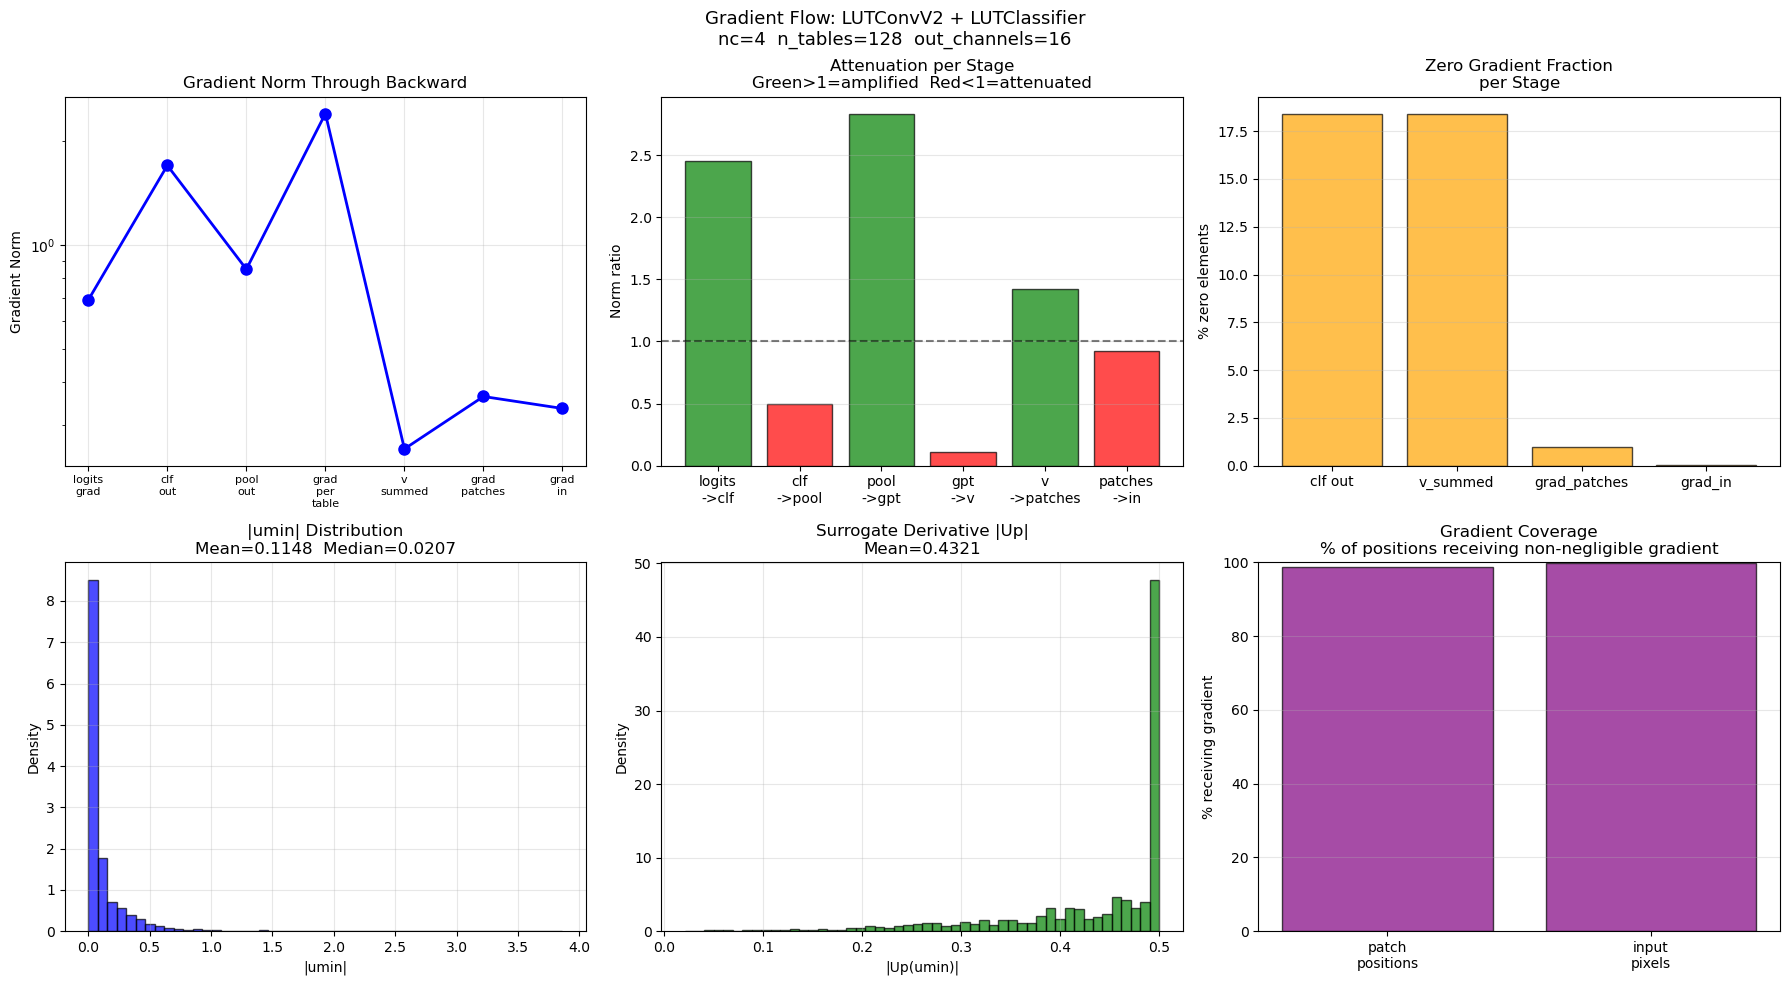

In [180]:
model_1layer = LUTConvV2_LinearModel(
    num_classes   = 2,
    out_channels  = 16,
    n_tables = 16,
    n_comparisons = 4,    # table_size = 16*32
    output_dim = 1,
    n_tables_per_channel = 8,
    table_dropout = 0.0,
    seed          = 42
)
records = visualize_gradient_flow(
    model_1layer,
    twoclasstrain_loader,
    n_images=300
)

In [476]:
def diagnose_k_comparison(model_k1, model_k2,
                           train_loader,
                           n_samples=20):
    """
    Compare gradient flow and S table updates
    between K=1 and K=2 models
    to find why K=2 is not better
    """
    def rescale(g, target=0.1, eps=1e-8):
        n = np.linalg.norm(g)
        return g * (target / n) if n > eps else g
    
    def run_one_backward(model, x, target, lr=0.001):
        """
        Run forward and backward
        return key statistics
        lr=0 so S tables not updated
        """
        logits     = model.forward(x)
        loss, grad = cross_entropy_from_logits(
            logits, target
        )
        
        S_before = model.conv1.lut.S.copy()
        
        xg = model.classifier.backward(grad, lr)
        xg = xg.reshape(model.feature_shape)
        xg = model.pool1.backward(xg)
        xg = xg * model.relu1_mask
        norm_before_rescale = np.linalg.norm(xg)
        xg = rescale(xg)
        model.conv1.backward(xg, lr)
        
        S_after    = model.conv1.lut.S
        s_change   = np.abs(S_after - S_before).max()
        
        # Reset
        model.conv1.lut.S = S_before.copy()
        
        return {
            'loss':               loss,
            'logit_norm':         np.linalg.norm(logits),
            'grad_norm_pre':      norm_before_rescale,
            'max_s_change':       s_change,
            'out_mean':           logits.mean(),
            'out_std':            logits.std(),
        }
    
    print(f"{'Metric':<25} {'K=1':>12} {'K=2':>12} {'Ratio':>8}")
    print(f"{'-'*60}")
    
    k1_stats = {k: [] for k in [
        'loss','logit_norm','grad_norm_pre',
        'max_s_change','out_mean','out_std'
    ]}
    k2_stats = {k: [] for k in k1_stats.keys()}
    
    count = 0
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            if count >= n_samples:
                break
            x      = preprocess_for_lut(img)
            target = label.item()
            
            s1 = run_one_backward(model_k1, x, target)
            s2 = run_one_backward(model_k2, x, target)
            
            for k in k1_stats:
                k1_stats[k].append(s1[k])
                k2_stats[k].append(s2[k])
            count += 1
        if count >= n_samples:
            break
    
    for k in k1_stats:
        v1 = np.mean(k1_stats[k])
        v2 = np.mean(k2_stats[k])
        r  = v2 / (v1 + 1e-10)
        print(f"{k:<25} {v1:>12.6f} {v2:>12.6f} {r:>8.3f}x")
    
    print()
    
    # Check S table value spread
    print("S table value statistics:")
    print(f"{'Metric':<25} {'K=1':>12} {'K=2':>12}")
    print(f"{'-'*50}")
    
    for name, model in [('K=1', model_k1), ('K=2', model_k2)]:
        S = model.conv1.lut.S
        print(f"  {name}:")
        print(f"    Mean |S|:   {np.abs(S).mean():.6f}")
        print(f"    Std  S:     {S.std():.6f}")
        print(f"    Max  |S|:   {np.abs(S).max():.6f}")
        print(f"    n_tables:   {model.conv1.n_tables}")
        print(f"    table_size: {1<<model.conv1.n_comparisons}")
        print(f"    total rows: "
              f"{model.conv1.n_tables * (1<<model.conv1.n_comparisons)}")
    
    # Check per channel output correlation
    print()
    print("Per channel output analysis:")
    
    x      = preprocess_for_lut(next(iter(train_loader))[0][0])
    out_k1 = model_k1.conv1.forward(x)
    out_k2 = model_k2.conv1.forward(x)
    
    print(f"  K=1 conv1 output: "
          f"mean={out_k1.mean():.4f}  "
          f"std={out_k1.std():.4f}  "
          f"max={out_k1.max():.4f}")
    print(f"  K=2 conv1 output: "
          f"mean={out_k2.mean():.4f}  "
          f"std={out_k2.std():.4f}  "
          f"max={out_k2.max():.4f}")
    
    return k1_stats, k2_stats


k1_stats, k2_stats = diagnose_k_comparison(
    model, model2, twoclasstrain_loader
)

Metric                             K=1          K=2    Ratio
------------------------------------------------------------
loss                          0.612287     0.839629    1.371x
logit_norm                    0.988729     0.980488    0.992x
grad_norm_pre                 0.758722     0.896974    1.182x
max_s_change                  0.000085     0.000079    0.930x
out_mean                     -0.373631    -0.039055    0.105x
out_std                       0.520350     0.529322    1.017x

S table value statistics:
Metric                             K=1          K=2
--------------------------------------------------
  K=1:
    Mean |S|:   0.392880
    Std  S:     0.492533
    Max  |S|:   1.482264
    n_tables:   16
    table_size: 16
    total rows: 256
  K=2:
    Mean |S|:   0.267859
    Std  S:     0.344774
    Max  |S|:   1.289909
    n_tables:   32
    table_size: 16
    total rows: 512

Per channel output analysis:
  K=1 conv1 output: mean=0.0124  std=0.5165  max=1.2693
  K=2 conv

In [29]:
def analyze_bit_usefulness(model, train_loader,
                            n_images=50,
                            noise_threshold=0.1):
    """
    For each table and each comparison bit:
        Measure how much flipping that bit
        changes the S row output
    
    A bit is NOISE if the average S difference
    when flipping it is small
    
    Uses two approaches:
    
    1. S-based: look at ALL pairs of rows
                that differ only in bit c
                average the S difference
                Independent of data
    
    2. Data-based: look at actual patches
                   how often does bit c matter
                   for the patches we actually see
    """
    conv      = model.conv1
    n_tables  = conv.n_tables
    nc        = conv.n_comparisons
    table_size= 1 << nc
    D         = conv.output_dim
    S         = conv.lut.S
    # S shape: (n_tables, table_size, D)
    
    # ================================================
    # Method 1: S-based analysis
    # Look at all row pairs differing by bit c
    # ================================================
    
    # For each table t and bit c:
    # collect all pairs (j, j XOR 2^c)
    # and measure |S[t,j,:] - S[t,jbar,:]|
    
    s_diff_per_bit = np.zeros((n_tables, nc))
    # s_diff_per_bit[t, c] = mean norm of S difference
    #                         when flipping bit c
    #                         in table t
    
    for t in range(n_tables):
        for c in range(nc):
            power    = 1 << c
            diffs    = []
            
            for j in range(table_size):
                jbar = j ^ power
                
                # Only count each pair once
                if jbar > j:
                    continue
                
                # Difference vector: shape (D,)
                d = S[t, j, :] - S[t, jbar, :]
                
                # Magnitude of difference
                if D == 1:
                    diffs.append(abs(float(d[0])))
                else:
                    diffs.append(float(np.linalg.norm(d)))
            
            s_diff_per_bit[t, c] = np.mean(diffs)
    
    # ================================================
    # Method 2: Data-based analysis
    # How often does each bit actually vary
    # in the patches we see AND does it matter?
    # ================================================
    
    # Collect all patches
    all_patches = []
    counts      = {0: 0, 1: 0}
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_images:
                continue
            x       = preprocess_for_lut(img)
            C, H, W = x.shape
            pad     = conv.kernel_size // 2
            x_pad   = np.pad(x, ((0,0),(pad,pad),(pad,pad)))
            patches = conv.im2col_vectorized(x_pad, H, W)
            all_patches.append(patches)
            counts[cls] += 1
        if all(v >= n_images for v in counts.values()):
            break
    
    all_patches = np.vstack(all_patches)
    # all_patches: (total_patches, patch_dim)
    
    # Compute bits for all patches and all tables
    vals_a = all_patches[:, conv.lut.anchors_a]
    vals_b = all_patches[:, conv.lut.anchors_b]
    diffs  = vals_a - vals_b
    # diffs: (total_patches, n_tables, nc)
    
    powers = 1 << np.arange(nc)
    bits   = (diffs > 0).astype(np.int64)
    j_all  = (bits * powers[None, None, :]).sum(axis=2)
    # j_all: (total_patches, n_tables)
    
    # For each table and bit:
    # weighted S difference
    # weight by how often the patch hits this row
    
    data_diff_per_bit    = np.zeros((n_tables, nc))
    bit_variance_per_bit = np.zeros((n_tables, nc))
    # bit_variance: does bit c actually vary in data?
    # 0 = always same value (useless)
    # 1 = varies maximally (useful structurally)
    
    for t in range(n_tables):
        for c in range(nc):
            power = 1 << c
            
            # Bit c value for each patch in table t
            bit_c = bits[:, t, c]
            
            # Variance of bit c
            p_c   = bit_c.mean()
            var_c = p_c * (1 - p_c)
            bit_variance_per_bit[t, c] = var_c
            
            # For each patch, what is the S difference
            # if we flip bit c?
            j_actual  = j_all[:, t]
            j_flipped = j_actual ^ power
            
            S_actual  = S[t, j_actual,  :]  # (N, D)
            S_flipped = S[t, j_flipped, :]  # (N, D)
            
            diff_vecs = S_actual - S_flipped  # (N, D)
            
            if D == 1:
                magnitudes = np.abs(diff_vecs[:, 0])
            else:
                magnitudes = np.linalg.norm(diff_vecs, axis=1)
            
            data_diff_per_bit[t, c] = magnitudes.mean()
    
    # ================================================
    # Classify bits as signal or noise
    # ================================================
    
    is_noise_s    = s_diff_per_bit    < noise_threshold
    is_noise_data = data_diff_per_bit < noise_threshold
    
    # A bit is noise if BOTH methods agree
    is_noise      = is_noise_s & is_noise_data
    
    # ================================================
    # Print results
    # ================================================
    
    print(f"Bit Usefulness Analysis")
    print(f"n_tables={n_tables}  n_comparisons={nc}  "
          f"output_dim={D}")
    print(f"noise_threshold={noise_threshold}")
    print()
    
    print(f"{'Table':<7} ", end='')
    for c in range(nc):
        print(f"{'Bit'+str(c):>12}", end='')
    print(f"  {'Noise bits':>10}")
    print(f"{'-'*( 7 + nc*12 + 12)}")
    
    # Print S-based differences
    print("S-based mean |delta_S| when flipping bit:")
    for t in range(n_tables):
        print(f"  {t:<5} ", end='')
        for c in range(nc):
            val    = s_diff_per_bit[t, c]
            marker = '❌' if is_noise_s[t, c] else '✅'
            print(f"  {val:>6.4f}{marker}", end='')
        n_noise = is_noise_s[t].sum()
        print(f"  {n_noise}/{nc}")
    
    print()
    print("Data-based mean |delta_S| when flipping bit:")
    for t in range(n_tables):
        print(f"  {t:<5} ", end='')
        for c in range(nc):
            val    = data_diff_per_bit[t, c]
            marker = '❌' if is_noise_data[t, c] else '✅'
            print(f"  {val:>6.4f}{marker}", end='')
        n_noise = is_noise_data[t].sum()
        print(f"  {n_noise}/{nc}")
    
    print()
    print("Bit variance (how much bit varies in data):")
    print("  0.0 = always same  0.25 = maximum variation")
    for t in range(n_tables):
        print(f"  {t:<5} ", end='')
        for c in range(nc):
            val    = bit_variance_per_bit[t, c]
            marker = '❌' if val < 0.05 else '✅'
            print(f"  {val:>6.4f}{marker}", end='')
        dead = (bit_variance_per_bit[t] < 0.05).sum()
        print(f"  {dead} dead bits")
    
    # ================================================
    # Summary
    # ================================================
    
    total_bits      = n_tables * nc
    noise_bits_s    = is_noise_s.sum()
    noise_bits_data = is_noise_data.sum()
    noise_bits_both = is_noise.sum()
    dead_bits       = (bit_variance_per_bit < 0.05).sum()
    
    print()
    print(f"{'='*50}")
    print(f"Summary:")
    print(f"  Total bits:              {total_bits}")
    print(f"  Noise bits (S-based):    {noise_bits_s} "
          f"({100*noise_bits_s/total_bits:.1f}%)")
    print(f"  Noise bits (data-based): {noise_bits_data} "
          f"({100*noise_bits_data/total_bits:.1f}%)")
    print(f"  Noise bits (both):       {noise_bits_both} "
          f"({100*noise_bits_both/total_bits:.1f}%)")
    print(f"  Dead bits (never vary):  {dead_bits} "
          f"({100*dead_bits/total_bits:.1f}%)")
    
    plot_bit_usefulness(
        s_diff_per_bit,
        data_diff_per_bit,
        bit_variance_per_bit,
        is_noise,
        noise_threshold,
        n_tables, nc
    )
    
    return {
        's_diff':       s_diff_per_bit,
        'data_diff':    data_diff_per_bit,
        'bit_variance': bit_variance_per_bit,
        'is_noise':     is_noise,
        'is_noise_s':   is_noise_s,
        'is_noise_data':is_noise_data,
    }


def plot_bit_usefulness(s_diff, data_diff,
                         bit_variance, is_noise,
                         threshold,
                         n_tables, nc):
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # ---- Plot 1: S-based heatmap ----
    ax  = axes[0]
    im  = ax.imshow(s_diff, aspect='auto',
                     cmap='RdYlGn',
                     vmin=0, vmax=s_diff.max())
    ax.set_xlabel('Bit index')
    ax.set_ylabel('Table index')
    ax.set_title('S-based: mean |delta_S|\nwhen flipping bit\n'
                  'Green=useful  Red=noise')
    ax.set_xticks(range(nc))
    ax.set_xticklabels([f'Bit {c}' for c in range(nc)])
    ax.set_yticks(range(n_tables))
    plt.colorbar(im, ax=ax)
    
    # Mark noise bits
    for t in range(n_tables):
        for c in range(nc):
            if s_diff[t, c] < threshold:
                ax.add_patch(plt.Rectangle(
                    (c-0.5, t-0.5), 1, 1,
                    fill=False,
                    edgecolor='red',
                    linewidth=2
                ))
    
    # ---- Plot 2: Data-based heatmap ----
    ax  = axes[1]
    im  = ax.imshow(data_diff, aspect='auto',
                     cmap='RdYlGn',
                     vmin=0, vmax=data_diff.max())
    ax.set_xlabel('Bit index')
    ax.set_ylabel('Table index')
    ax.set_title('Data-based: mean |delta_S|\nfor actual patches\n'
                  'Green=useful  Red=noise')
    ax.set_xticks(range(nc))
    ax.set_xticklabels([f'Bit {c}' for c in range(nc)])
    ax.set_yticks(range(n_tables))
    plt.colorbar(im, ax=ax)
    
    for t in range(n_tables):
        for c in range(nc):
            if data_diff[t, c] < threshold:
                ax.add_patch(plt.Rectangle(
                    (c-0.5, t-0.5), 1, 1,
                    fill=False,
                    edgecolor='red',
                    linewidth=2
                ))
    
    # ---- Plot 3: Bit variance heatmap ----
    ax  = axes[2]
    im  = ax.imshow(bit_variance, aspect='auto',
                     cmap='RdYlGn',
                     vmin=0, vmax=0.25)
    ax.set_xlabel('Bit index')
    ax.set_ylabel('Table index')
    ax.set_title('Bit variance in data\n'
                  '0=dead  0.25=max variation\n'
                  'Dead bits cannot carry information')
    ax.set_xticks(range(nc))
    ax.set_xticklabels([f'Bit {c}' for c in range(nc)])
    ax.set_yticks(range(n_tables))
    plt.colorbar(im, ax=ax, label='p*(1-p)')
    
    # Mark dead bits
    for t in range(n_tables):
        for c in range(nc):
            if bit_variance[t, c] < 0.05:
                ax.add_patch(plt.Rectangle(
                    (c-0.5, t-0.5), 1, 1,
                    fill=False,
                    edgecolor='black',
                    linewidth=2
                ))
    
    plt.suptitle(
        f'Bit Usefulness Analysis\n'
        f'{n_tables} tables  {nc} bits each  '
        f'threshold={threshold}\n'
        f'Red border = noise bit  '
        f'Black border = dead bit',
        fontsize=13
    )
    plt.tight_layout()
    plt.savefig('bit_usefulness.png',
                dpi=150, bbox_inches='tight')
    plt.show()

In [30]:
def analyze_bit_usefulness_v2(model, train_loader,
                               n_images=50):
    """
    Correct bit usefulness measurement
    
    Instead of comparing S values at (j, jbar):
    
    Measure: if we ZERO OUT bit c
             (force it to 0 always)
             how much does the model output change?
    
    Large change = bit c is important
    Small change = bit c is noise
    
    This directly measures:
    "does this bit contribute to the model output
     for real data?"
    """
    conv       = model.conv1
    n_tables   = conv.n_tables
    nc         = conv.n_comparisons
    D          = conv.output_dim
    K          = conv.n_tables_per_channel
    
    # Collect patches and labels
    all_patches   = []
    all_labels    = []
    counts        = {0: 0, 1: 0}
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_images:
                continue
            x       = preprocess_for_lut(img)
            C, H, W = x.shape
            pad     = conv.kernel_size // 2
            x_pad   = np.pad(x, ((0,0),(pad,pad),(pad,pad)))
            patches = conv.im2col_vectorized(x_pad, H, W)
            all_patches.append(patches)
            all_labels.extend([cls] * len(patches))
            counts[cls] += 1
        if all(v >= n_images for v in counts.values()):
            break
    
    all_patches = np.vstack(all_patches)
    all_labels  = np.array(all_labels)
    n_p         = len(all_patches)
    
    # Compute full bits and j for all patches
    vals_a    = all_patches[:, conv.lut.anchors_a]
    vals_b    = all_patches[:, conv.lut.anchors_b]
    diffs_all = vals_a - vals_b
    powers    = 1 << np.arange(nc)
    bits_all  = (diffs_all > 0).astype(np.int64)
    j_full    = (bits_all * powers[None, None, :]).sum(axis=2)
    # j_full: (n_patches, n_tables)
    
    # Full model output per table
    # S[t, j, :] for each patch and table
    table_idx  = np.arange(n_tables)
    S_full     = conv.lut.S[
        table_idx[None, :], j_full, :
    ]
    # S_full: (n_patches, n_tables, D)
    
    # Sum K tables per channel -> (n_patches, out_ch, D)
    S_grouped  = S_full.reshape(n_p, conv.out_channels, K, D)
    out_full   = S_grouped.sum(axis=2)
    # out_full: (n_patches, out_channels, D)
    
    # ---- Metric 1: Output change when bit is zeroed ----
    # For bit c: force bit c = 0 for all patches
    # See how much output changes
    
    output_change = np.zeros((n_tables, nc))
    
    for c in range(nc):
        power = 1 << c
        
        # j with bit c forced to 0
        j_bit0 = j_full & ~power
        
        S_bit0    = conv.lut.S[
            table_idx[None, :], j_bit0, :
        ]
        S_grouped0 = S_bit0.reshape(
            n_p, conv.out_channels, K, D
        )
        out_bit0   = S_grouped0.sum(axis=2)
        
        # Change in output
        diff = out_full - out_bit0
        # diff: (n_patches, out_channels, D)
        
        # Mean absolute change per table
        # Need per-table not per-channel
        # Use S values directly
        for t in range(n_tables):
            S_t_full = S_full[:, t, :]    # (n_p, D)
            S_t_bit0 = S_bit0[:, t, :]    # (n_p, D)
            change   = np.linalg.norm(
                S_t_full - S_t_bit0, axis=1
            ).mean()
            output_change[t, c] = change
    
    # ---- Metric 2: How much does bit c vary? ----
    bit_p    = bits_all.mean(axis=0)
    # bit_p: (n_tables, nc)  -> P(bit=1) per table per bit
    bit_var  = bit_p * (1 - bit_p)
    # bit_var: (n_tables, nc)
    
    # ---- Metric 3: Class separation per bit ----
    # Does knowing bit c tell you the class?
    mask0     = all_labels == 0
    mask1     = all_labels == 1
    bit_sep   = np.zeros((n_tables, nc))
    
    for t in range(n_tables):
        for c in range(nc):
            p_c_0 = bits_all[mask0, t, c].mean()
            p_c_1 = bits_all[mask1, t, c].mean()
            bit_sep[t, c] = abs(p_c_0 - p_c_1)
    
    # ---- Metric 4: S row class purity per bit ----
    # For each pair (j, jbar) differing in bit c:
    # How different are their class compositions?
    # This requires knowing which patches
    # hit each row AND their classes
    
    row_class_purity = np.zeros((n_tables, nc))
    
    table_size = 1 << nc
    
    for t in range(n_tables):
        j_t = j_full[:, t]   # (n_patches,)
        
        # Count class hits per row
        hits_c0 = np.zeros(table_size)
        hits_c1 = np.zeros(table_size)
        for j in range(table_size):
            mask_j       = j_t == j
            hits_c0[j]   = (mask_j & mask0).sum()
            hits_c1[j]   = (mask_j & mask1).sum()
        
        for c in range(nc):
            power = 1 << c
            purities = []
            for j in range(table_size):
                jbar  = j ^ power
                if jbar <= j:
                    continue
                
                # Class composition of row j
                total_j    = hits_c0[j] + hits_c1[j]
                total_jbar = hits_c0[jbar] + hits_c1[jbar]
                
                if total_j == 0 or total_jbar == 0:
                    continue
                
                p0_j    = hits_c0[j]    / total_j
                p0_jbar = hits_c0[jbar] / total_jbar
                
                # How different are the class compositions?
                purity_diff = abs(p0_j - p0_jbar)
                purities.append(purity_diff)
            
            row_class_purity[t, c] = (
                np.mean(purities) if purities else 0
            )
    
    # ---- Print results ----
    print(f"Bit Usefulness Analysis V2")
    print(f"n_tables={n_tables}  nc={nc}  D={D}")
    print()
    
    metrics = [
        ('Output change (bit zeroed)', output_change,
         'Large = bit matters for output'),
        ('Bit variance p*(1-p)',        bit_var,
         '0=dead  0.25=max'),
        ('Class separation |p0-p1|',    bit_sep,
         'Large = bit predicts class'),
        ('Row class purity diff',        row_class_purity,
         'Large = bit separates classes into rows'),
    ]
    
    for title, mat, note in metrics:
        print(f"{title}  ({note})")
        print(f"  {'Table':<7}", end='')
        for c in range(nc):
            label = f'Bit{c}'
            if c % 4 == 3:
                label += '*'   # mark forced noise bits
            print(f" {label:>10}", end='')
        print()
        for t in range(min(8, n_tables)):
            print(f"  {t:<7}", end='')
            for c in range(nc):
                val    = mat[t, c]
                noise  = (c % 4 == 3)
                marker = '~' if noise else ' '
                print(f" {val:>9.4f}{marker}", end='')
            print()
        print()
    
    plot_bit_usefulness_v2(
        output_change, bit_var,
        bit_sep, row_class_purity,
        n_tables, nc
    )
    
    return {
        'output_change':     output_change,
        'bit_variance':      bit_var,
        'bit_separation':    bit_sep,
        'row_class_purity':  row_class_purity,
    }


def plot_bit_usefulness_v2(output_change, bit_var,
                            bit_sep, row_purity,
                            n_tables, nc):
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    def plot_heatmap(ax, data, title, note, vmax=None):
        vmax = vmax or data.max()
        im   = ax.imshow(data, aspect='auto',
                          cmap='RdYlGn',
                          vmin=0, vmax=vmax)
        ax.set_title(f'{title}\n{note}', fontsize=11)
        ax.set_xlabel('Bit index')
        ax.set_ylabel('Table index')
        ax.set_xticks(range(nc))
        labels = [
            f'Bit {c}' + (' (NOISE)' if c % 4 == 3 else '')
            for c in range(nc)
        ]
        ax.set_xticklabels(labels, rotation=15)
        ax.set_yticks(range(n_tables))
        plt.colorbar(im, ax=ax)
        
        # Highlight noise bit columns
        for c in range(nc):
            if c % 4 == 3:
                ax.axvline(x=c, color='red',
                           alpha=0.3, linewidth=8)
    
    plot_heatmap(
        axes[0,0], output_change,
        'Output Change When Bit Zeroed',
        'Large = bit affects output'
    )
    plot_heatmap(
        axes[0,1], bit_var,
        'Bit Variance p*(1-p)',
        '0=always same  0.25=50/50',
        vmax=0.25
    )
    plot_heatmap(
        axes[1,0], bit_sep,
        'Bit Class Separation |p0-p1|',
        'Large = bit predicts class'
    )
    plot_heatmap(
        axes[1,1], row_purity,
        'Row Class Purity Difference',
        'Large = flipping bit changes class composition'
    )
    
    plt.suptitle(
        f'Bit Usefulness V2\n'
        f'Red columns = forced noise bits (every 4th)\n'
        f'All metrics should be LOW for noise bits '
        f'after training',
        fontsize=13
    )
    plt.tight_layout()
    plt.savefig('bit_usefulness_v2.png',
                dpi=150, bbox_inches='tight')
    plt.show()

Bit Usefulness Analysis
n_tables=16  n_comparisons=12  output_dim=1
noise_threshold=0.1

Table           Bit0        Bit1        Bit2        Bit3        Bit4        Bit5        Bit6        Bit7        Bit8        Bit9       Bit10       Bit11  Noise bits
-------------------------------------------------------------------------------------------------------------------------------------------------------------------
S-based mean |delta_S| when flipping bit:
  0       0.5692✅  0.5549✅  0.5737✅  0.5615✅  0.5619✅  0.5673✅  0.5645✅  0.5655✅  0.5762✅  0.5521✅  0.5754✅  0.5758✅  0/12
  1       0.5613✅  0.5731✅  0.5631✅  0.5567✅  0.5659✅  0.5605✅  0.5759✅  0.5665✅  0.5680✅  0.5639✅  0.5753✅  0.5774✅  0/12
  2       0.5602✅  0.5586✅  0.5773✅  0.5726✅  0.5561✅  0.5620✅  0.5523✅  0.5696✅  0.5675✅  0.5669✅  0.5568✅  0.5663✅  0/12
  3       0.5699✅  0.5653✅  0.5660✅  0.5622✅  0.5855✅  0.5566✅  0.5714✅  0.5782✅  0.5834✅  0.5700✅  0.5703✅  0.5640✅  0/12
  4       0.5625✅  0.5565✅  0.5642✅  0.5570✅  0.

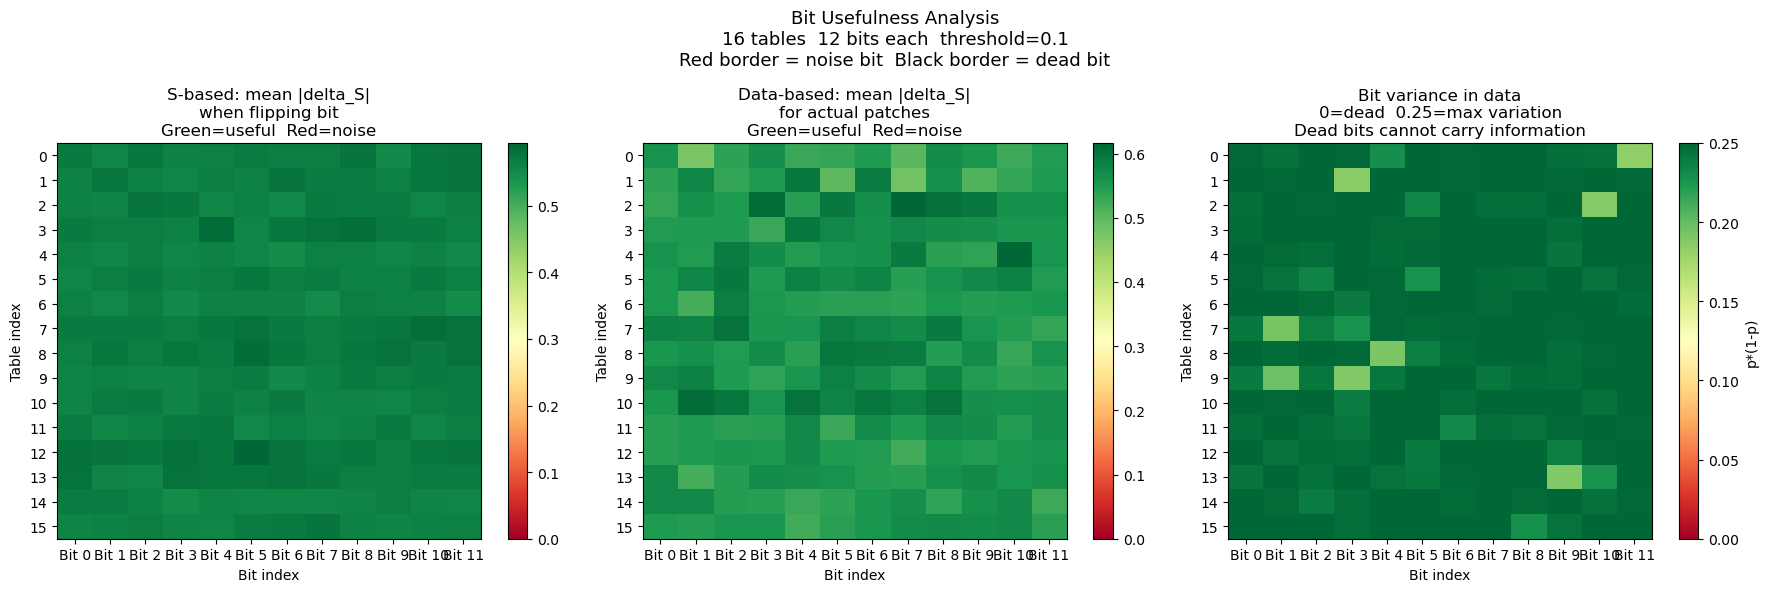

In [36]:


results = analyze_bit_usefulness(
    model            = model2,
    train_loader     = linetrain_loader,
    n_images         = 50,
    #noise_threshold  = 0.1
)

In [527]:
def prove_bits_unused(model, train_loader,
                       n_images=50):
    """
    Most direct test possible:
    
    Compare model output on real patches
    vs model output where ALL bits are
    replaced with random coin flips
    
    If bits are used:
        Random bits -> very different output
        Large output change
    
    If bits are not used:
        Random bits -> same output
        S values are the same regardless
        of which row you land in
    """
    conv      = model.conv1
    n_tables  = conv.n_tables
    nc        = conv.n_comparisons
    D         = conv.output_dim
    K         = conv.n_tables_per_channel
    table_size= 1 << nc
    
    # Collect patches
    all_patches = []
    counts      = {0: 0, 1: 0}
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_images:
                continue
            x       = preprocess_for_lut(img)
            C, H, W = x.shape
            pad     = conv.kernel_size // 2
            x_pad   = np.pad(x,((0,0),(pad,pad),(pad,pad)))
            patches = conv.im2col_vectorized(x_pad, H, W)
            all_patches.append(patches)
            counts[cls] += 1
        if all(v >= n_images for v in counts.values()):
            break
    
    all_patches = np.vstack(all_patches)
    n_p         = len(all_patches)
    rng         = np.random.default_rng(0)
    
    # ---- Real output ----
    vals_a    = all_patches[:, conv.lut.anchors_a]
    vals_b    = all_patches[:, conv.lut.anchors_b]
    diffs     = vals_a - vals_b
    powers    = 1 << np.arange(nc)
    bits_real = (diffs > 0).astype(np.int64)
    j_real    = (bits_real * powers[None,None,:]).sum(axis=2)
    
    S_real    = conv.lut.S[
        np.arange(n_tables)[None,:], j_real, :
    ]
    out_real  = S_real.reshape(
        n_p, conv.out_channels, K, D
    ).sum(axis=2)
    # out_real: (n_p, out_channels, D)
    
    # ---- Random bits output ----
    bits_rand = rng.integers(
        0, 2, size=(n_p, n_tables, nc)
    ).astype(np.int64)
    j_rand    = (bits_rand * powers[None,None,:]).sum(axis=2)
    
    S_rand    = conv.lut.S[
        np.arange(n_tables)[None,:], j_rand, :
    ]
    out_rand  = S_rand.reshape(
        n_p, conv.out_channels, K, D
    ).sum(axis=2)
    
    # ---- Compare ----
    diff_real_rand = np.abs(out_real - out_rand).mean()
    
    # ---- All same row output ----
    # What if every patch goes to row 0?
    j_zero   = np.zeros((n_p, n_tables), dtype=np.int64)
    S_zero   = conv.lut.S[
        np.arange(n_tables)[None,:], j_zero, :
    ]
    out_zero = S_zero.reshape(
        n_p, conv.out_channels, K, D
    ).sum(axis=2)
    
    diff_real_zero = np.abs(out_real - out_zero).mean()
    
    # ---- S table variance ----
    # How different are S rows from each other?
    S_flat   = conv.lut.S.reshape(n_tables, table_size, D)
    S_mean   = S_flat.mean(axis=1, keepdims=True)
    S_var    = ((S_flat - S_mean)**2).mean()
    S_range  = S_flat.max() - S_flat.min()
    
    print("="*55)
    print("Direct bit usage test")
    print("="*55)
    print()
    print("Output difference: real j vs random j:")
    print(f"  Mean |out_real - out_random|: "
          f"{diff_real_rand:.6f}")
    print()
    print("Output difference: real j vs all-zero j:")
    print(f"  Mean |out_real - out_zero|:   "
          f"{diff_real_zero:.6f}")
    print()
    print("S table row variance:")
    print(f"  Variance across rows: {S_var:.6f}")
    print(f"  Range (max-min):      {S_range:.6f}")
    print(f"  Mean |S|:             "
          f"{np.abs(conv.lut.S).mean():.6f}")
    print()
    
    if diff_real_rand < 0.01:
        print("CONCLUSION: Bits are NOT being used")
        print("  Random j gives same output as real j")
        print("  S rows have not specialized")
        print("  All rows have similar values")
        print()
        print("  Root cause: S rows not diverging")
        print("  Check S variance across rows")
        
        if S_var < 0.01:
            print()
            print("  CONFIRMED: S rows are nearly identical")
            print("  All rows learned same value")
            print("  = gradient always cancels across patches")
    else:
        print("CONCLUSION: Bits ARE being used")
        print(f"  Using real j vs random j changes")
        print(f"  output by {diff_real_rand:.4f} on average")
    
    # Per-table S variance
    print()
    print("Per-table S row variance:")
    print(f"{'Table':<8} {'S_var':>10} {'S_range':>10} "
          f"{'Specialized':>12}")
    print(f"{'-'*44}")
    for t in range(min(8, n_tables)):
        S_t   = conv.lut.S[t]    # (table_size, D)
        var_t = S_t.var()
        rng_t = S_t.max() - S_t.min()
        spec  = '✅' if var_t > 0.01 else '❌ flat'
        print(f"{t:<8} {var_t:>10.6f} {rng_t:>10.6f} "
              f"{spec:>12}")
    
    return {
        'diff_real_rand': diff_real_rand,
        'diff_real_zero': diff_real_zero,
        'S_variance':     S_var,
        'S_range':        S_range,
    }

results = prove_bits_unused(model2,
                              twoclasstrain_loader)

Direct bit usage test

Output difference: real j vs random j:
  Mean |out_real - out_random|: 0.517718

Output difference: real j vs all-zero j:
  Mean |out_real - out_zero|:   0.495771

S table row variance:
  Variance across rows: 0.223229
  Range (max-min):      2.731094
  Mean |S|:             0.392342

CONCLUSION: Bits ARE being used
  Using real j vs random j changes
  output by 0.5177 on average

Per-table S row variance:
Table         S_var    S_range  Specialized
--------------------------------------------
0          0.255140   1.634333            ✅
1          0.325711   1.951847            ✅
2          0.116718   1.339160            ✅
3          0.263777   2.150781            ✅
4          0.224936   1.500213            ✅
5          0.231532   1.591194            ✅
6          0.223259   1.588652            ✅
7          0.169958   1.529387            ✅


In [44]:
#Test one normal conv layer CNN for performance comparison with one layer lut conv
class SimplestFruitClassificationCNN(nn.Module):
    def __init__(self, num_classes=2): 
        super(SimplestFruitClassificationCNN, self).__init__()
        
        self.features = nn.Sequential(
            #Block 1
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
            
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [45]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

def train_reg(model, trainloader, valloader, num_epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    
    # Track losses
    train_losses = []
    val_losses   = []
    train_accs   = []
    val_accs     = []
    epochs       = []

    best_val_loss = float('inf')

    for epoch in range(num_epochs):
        model.train()
        running_train_loss = 0.0
        correct_train      = 0
        total_train        = 0
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            # Track loss and accuracy
            running_train_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_train  += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        avg_train_loss = running_train_loss / len(trainloader)
        train_acc      = 100 * correct_train / total_train

        model.eval()  # set model to evaluation mode
        running_val_loss = 0.0
        correct_val      = 0
        total_val        = 0

        with torch.no_grad():  # no gradients needed for validation
            for images, labels in valloader:
                images, labels = images.to(device), labels.to(device)

                outputs  = model(images)
                loss     = criterion(outputs, labels)

                # Track loss and accuracy
                running_val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                total_val    += labels.size(0)
                correct_val  += (predicted == labels).sum().item()

        avg_val_loss = running_val_loss / len(valloader)
        val_acc      = 100 * correct_val / total_val

        # Save losses
        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)
        epochs.append(epoch)

        # Print progress
        print(f"Epoch [{epoch+1}/{num_epochs}]  "
              f"Train Loss: {avg_train_loss:.4f}  Train Acc: {train_acc:.2f}%  "
              f"Val Loss: {avg_val_loss:.4f}  Val Acc: {val_acc:.2f}%")

        # Save model if validation loss improved
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            #torch.save(model.state_dict(), 'oneLayerCompCNN_best_model.pth')
            print(f"  -> Model saved with val loss: {best_val_loss:.4f}")

    history = {
        'train_acc':  train_accs,
        'val_acc':    val_accs,
        'train_loss': train_losses,
        'val_loss':   val_losses,
        'epochs':     epochs,
    }
    plot_training_history(history)

Using device: mps


Epoch [1/300]  Train Loss: 0.9268  Train Acc: 53.49%  Val Loss: 0.5651  Val Acc: 67.50%
  -> Model saved with val loss: 0.5651
Epoch [2/300]  Train Loss: 0.6900  Train Acc: 58.52%  Val Loss: 0.7442  Val Acc: 65.00%
Epoch [3/300]  Train Loss: 0.6723  Train Acc: 61.79%  Val Loss: 0.7187  Val Acc: 50.00%
Epoch [4/300]  Train Loss: 0.7045  Train Acc: 58.30%  Val Loss: 0.8525  Val Acc: 52.50%
Epoch [5/300]  Train Loss: 0.6830  Train Acc: 62.88%  Val Loss: 0.7627  Val Acc: 55.00%
Epoch [6/300]  Train Loss: 0.7734  Train Acc: 60.48%  Val Loss: 0.9133  Val Acc: 52.50%
Epoch [7/300]  Train Loss: 0.7384  Train Acc: 60.48%  Val Loss: 0.6486  Val Acc: 65.00%
Epoch [8/300]  Train Loss: 0.7048  Train Acc: 65.94%  Val Loss: 0.7875  Val Acc: 57.50%
Epoch [9/300]  Train Loss: 0.6753  Train Acc: 63.32%  Val Loss: 0.7184  Val Acc: 55.00%
Epoch [10/300]  Train Loss: 0.6680  Train Acc: 65.50%  Val Loss: 0.5736  Val Acc: 62.50%
Epoch [11/300]  Train Loss: 0.6301  Train Acc: 65.50%  Val Loss: 0.8068  Val Acc

Epoch [92/300]  Train Loss: 0.5291  Train Acc: 74.67%  Val Loss: 0.9318  Val Acc: 60.00%
Epoch [93/300]  Train Loss: 0.6418  Train Acc: 69.00%  Val Loss: 0.5984  Val Acc: 62.50%
Epoch [94/300]  Train Loss: 0.5531  Train Acc: 70.96%  Val Loss: 0.5626  Val Acc: 65.00%
Epoch [95/300]  Train Loss: 0.5219  Train Acc: 76.20%  Val Loss: 0.6194  Val Acc: 62.50%
Epoch [96/300]  Train Loss: 0.5832  Train Acc: 70.96%  Val Loss: 0.4091  Val Acc: 80.00%
Epoch [97/300]  Train Loss: 0.5161  Train Acc: 73.14%  Val Loss: 0.6053  Val Acc: 70.00%
Epoch [98/300]  Train Loss: 0.5864  Train Acc: 70.52%  Val Loss: 0.6351  Val Acc: 75.00%
Epoch [99/300]  Train Loss: 0.5348  Train Acc: 73.14%  Val Loss: 0.4878  Val Acc: 72.50%
Epoch [100/300]  Train Loss: 0.5611  Train Acc: 71.62%  Val Loss: 0.7038  Val Acc: 62.50%
Epoch [101/300]  Train Loss: 0.5823  Train Acc: 69.43%  Val Loss: 0.6633  Val Acc: 62.50%
Epoch [102/300]  Train Loss: 0.5434  Train Acc: 70.52%  Val Loss: 0.4251  Val Acc: 85.00%
Epoch [103/300]  T

Epoch [183/300]  Train Loss: 0.4494  Train Acc: 77.95%  Val Loss: 0.4594  Val Acc: 82.50%
Epoch [184/300]  Train Loss: 0.5000  Train Acc: 77.29%  Val Loss: 0.4051  Val Acc: 82.50%
Epoch [185/300]  Train Loss: 0.4585  Train Acc: 77.07%  Val Loss: 0.5199  Val Acc: 75.00%
Epoch [186/300]  Train Loss: 0.4640  Train Acc: 76.20%  Val Loss: 0.4608  Val Acc: 77.50%
Epoch [187/300]  Train Loss: 0.4902  Train Acc: 74.89%  Val Loss: 0.5540  Val Acc: 70.00%
Epoch [188/300]  Train Loss: 0.4475  Train Acc: 79.48%  Val Loss: 0.3789  Val Acc: 72.50%
Epoch [189/300]  Train Loss: 0.5078  Train Acc: 78.17%  Val Loss: 0.3499  Val Acc: 75.00%
Epoch [190/300]  Train Loss: 0.4867  Train Acc: 77.51%  Val Loss: 0.5650  Val Acc: 77.50%
Epoch [191/300]  Train Loss: 0.5029  Train Acc: 77.07%  Val Loss: 0.6558  Val Acc: 80.00%
Epoch [192/300]  Train Loss: 0.4581  Train Acc: 78.38%  Val Loss: 0.4488  Val Acc: 77.50%
Epoch [193/300]  Train Loss: 0.5449  Train Acc: 73.80%  Val Loss: 0.5222  Val Acc: 65.00%
Epoch [194

Epoch [274/300]  Train Loss: 0.4679  Train Acc: 76.20%  Val Loss: 0.4443  Val Acc: 72.50%
Epoch [275/300]  Train Loss: 0.4093  Train Acc: 82.31%  Val Loss: 0.5386  Val Acc: 77.50%
Epoch [276/300]  Train Loss: 0.4589  Train Acc: 79.91%  Val Loss: 0.5714  Val Acc: 72.50%
Epoch [277/300]  Train Loss: 0.4318  Train Acc: 78.60%  Val Loss: 0.5848  Val Acc: 67.50%
Epoch [278/300]  Train Loss: 0.4610  Train Acc: 78.60%  Val Loss: 0.3387  Val Acc: 87.50%
Epoch [279/300]  Train Loss: 0.4705  Train Acc: 76.42%  Val Loss: 0.4782  Val Acc: 80.00%
Epoch [280/300]  Train Loss: 0.4401  Train Acc: 78.38%  Val Loss: 0.5474  Val Acc: 75.00%
Epoch [281/300]  Train Loss: 0.4564  Train Acc: 76.20%  Val Loss: 0.4620  Val Acc: 75.00%
Epoch [282/300]  Train Loss: 0.4539  Train Acc: 79.69%  Val Loss: 0.4599  Val Acc: 82.50%
Epoch [283/300]  Train Loss: 0.4600  Train Acc: 76.86%  Val Loss: 0.3366  Val Acc: 80.00%
Epoch [284/300]  Train Loss: 0.4059  Train Acc: 80.79%  Val Loss: 0.5363  Val Acc: 72.50%
Epoch [285

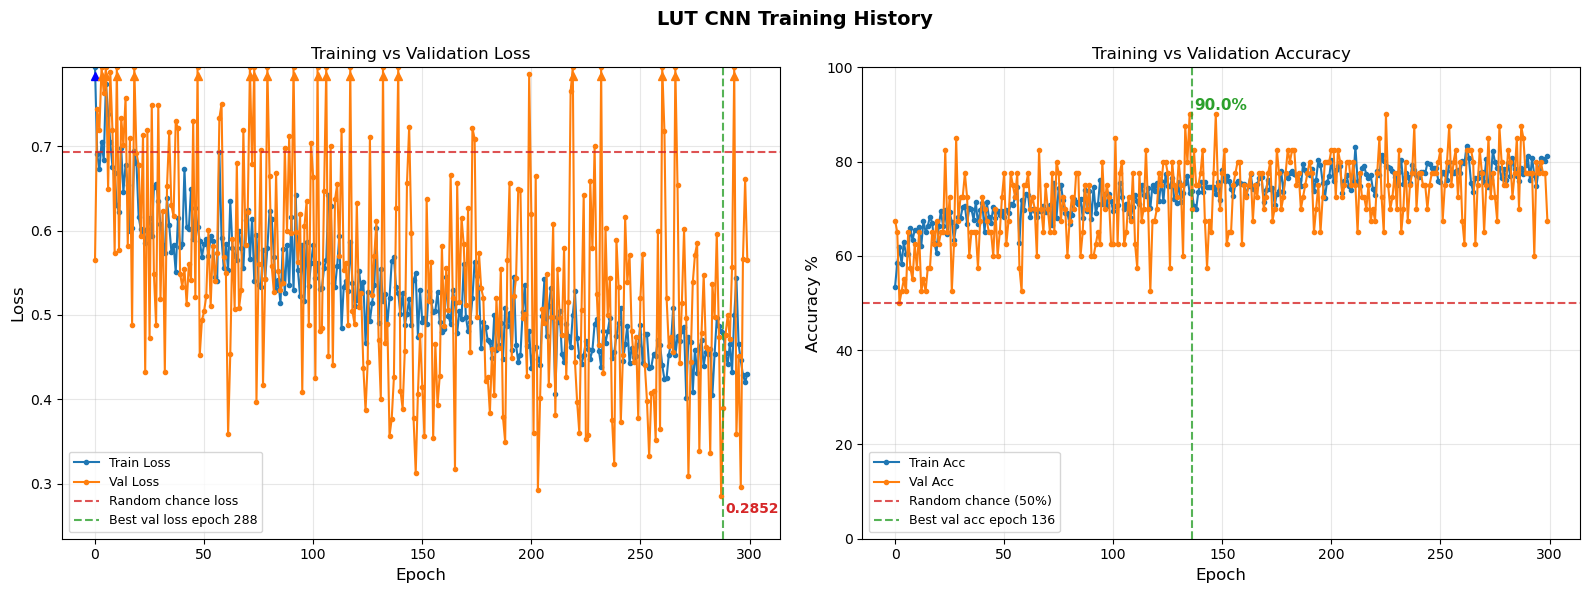

Best val accuracy: 90.0% at epoch 136
Best val loss:     0.2852 at epoch 288


In [48]:
cnn_model = SimplestFruitClassificationCNN(num_classes=2).to(device)
num_epochs = 300
train_reg(cnn_model, twoclasstrain_loader, twoclassval_loader, num_epochs)

In [53]:
#Test one normal conv layer CNN for performance comparison with one layer lut conv
class SecondSimplestFruitClassificationCNN(nn.Module):
    def __init__(self, num_classes=2): 
        super(SecondSimplestFruitClassificationCNN, self).__init__()
        
        self.features = nn.Sequential(
            #Block 1
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            #Block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
            
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32*8*8, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

Epoch [1/300]  Train Loss: 0.7173  Train Acc: 58.08%  Val Loss: 0.8170  Val Acc: 57.50%
  -> Model saved with val loss: 0.8170
Epoch [2/300]  Train Loss: 0.7046  Train Acc: 61.57%  Val Loss: 0.6966  Val Acc: 50.00%
  -> Model saved with val loss: 0.6966
Epoch [3/300]  Train Loss: 0.6746  Train Acc: 61.57%  Val Loss: 0.6644  Val Acc: 67.50%
  -> Model saved with val loss: 0.6644
Epoch [4/300]  Train Loss: 0.6524  Train Acc: 66.16%  Val Loss: 0.7441  Val Acc: 67.50%
Epoch [5/300]  Train Loss: 0.6533  Train Acc: 62.88%  Val Loss: 0.6876  Val Acc: 67.50%
Epoch [6/300]  Train Loss: 0.6611  Train Acc: 65.07%  Val Loss: 0.6585  Val Acc: 65.00%
  -> Model saved with val loss: 0.6585
Epoch [7/300]  Train Loss: 0.6753  Train Acc: 66.38%  Val Loss: 0.7975  Val Acc: 52.50%
Epoch [8/300]  Train Loss: 0.6762  Train Acc: 63.10%  Val Loss: 0.6839  Val Acc: 55.00%
Epoch [9/300]  Train Loss: 0.5871  Train Acc: 67.69%  Val Loss: 0.5222  Val Acc: 70.00%
  -> Model saved with val loss: 0.5222
Epoch [10/300

Epoch [89/300]  Train Loss: 0.4389  Train Acc: 78.17%  Val Loss: 0.6378  Val Acc: 72.50%
Epoch [90/300]  Train Loss: 0.4126  Train Acc: 80.79%  Val Loss: 0.3242  Val Acc: 80.00%
Epoch [91/300]  Train Loss: 0.4160  Train Acc: 81.66%  Val Loss: 0.6084  Val Acc: 70.00%
Epoch [92/300]  Train Loss: 0.4065  Train Acc: 83.62%  Val Loss: 0.2753  Val Acc: 85.00%
  -> Model saved with val loss: 0.2753
Epoch [93/300]  Train Loss: 0.3759  Train Acc: 82.75%  Val Loss: 0.3063  Val Acc: 80.00%
Epoch [94/300]  Train Loss: 0.3818  Train Acc: 84.06%  Val Loss: 0.5199  Val Acc: 72.50%
Epoch [95/300]  Train Loss: 0.3650  Train Acc: 83.41%  Val Loss: 0.3220  Val Acc: 87.50%
Epoch [96/300]  Train Loss: 0.3893  Train Acc: 83.62%  Val Loss: 0.3488  Val Acc: 85.00%
Epoch [97/300]  Train Loss: 0.3877  Train Acc: 82.10%  Val Loss: 0.6160  Val Acc: 82.50%
Epoch [98/300]  Train Loss: 0.3922  Train Acc: 83.62%  Val Loss: 0.4386  Val Acc: 82.50%
Epoch [99/300]  Train Loss: 0.3584  Train Acc: 83.19%  Val Loss: 0.3215

Epoch [179/300]  Train Loss: 0.3351  Train Acc: 84.28%  Val Loss: 0.3898  Val Acc: 80.00%
Epoch [180/300]  Train Loss: 0.3057  Train Acc: 86.68%  Val Loss: 0.5235  Val Acc: 80.00%
Epoch [181/300]  Train Loss: 0.2952  Train Acc: 86.24%  Val Loss: 0.3565  Val Acc: 82.50%
Epoch [182/300]  Train Loss: 0.3357  Train Acc: 85.37%  Val Loss: 0.2608  Val Acc: 85.00%
Epoch [183/300]  Train Loss: 0.3053  Train Acc: 85.15%  Val Loss: 0.2907  Val Acc: 87.50%
Epoch [184/300]  Train Loss: 0.2701  Train Acc: 86.24%  Val Loss: 0.3537  Val Acc: 77.50%
Epoch [185/300]  Train Loss: 0.3086  Train Acc: 84.50%  Val Loss: 0.3422  Val Acc: 82.50%
Epoch [186/300]  Train Loss: 0.2990  Train Acc: 86.03%  Val Loss: 0.5797  Val Acc: 75.00%
Epoch [187/300]  Train Loss: 0.3193  Train Acc: 84.06%  Val Loss: 0.3083  Val Acc: 85.00%
Epoch [188/300]  Train Loss: 0.3044  Train Acc: 85.81%  Val Loss: 0.4840  Val Acc: 72.50%
Epoch [189/300]  Train Loss: 0.2526  Train Acc: 87.34%  Val Loss: 0.2081  Val Acc: 92.50%
Epoch [190

Epoch [270/300]  Train Loss: 0.2176  Train Acc: 90.61%  Val Loss: 0.1930  Val Acc: 90.00%
Epoch [271/300]  Train Loss: 0.2816  Train Acc: 89.52%  Val Loss: 0.3683  Val Acc: 85.00%
Epoch [272/300]  Train Loss: 0.1844  Train Acc: 92.36%  Val Loss: 0.5218  Val Acc: 77.50%
Epoch [273/300]  Train Loss: 0.2999  Train Acc: 88.43%  Val Loss: 0.9009  Val Acc: 85.00%
Epoch [274/300]  Train Loss: 0.3077  Train Acc: 88.21%  Val Loss: 0.4882  Val Acc: 80.00%
Epoch [275/300]  Train Loss: 0.3008  Train Acc: 85.59%  Val Loss: 0.2879  Val Acc: 90.00%
Epoch [276/300]  Train Loss: 0.2655  Train Acc: 88.21%  Val Loss: 0.2165  Val Acc: 95.00%
Epoch [277/300]  Train Loss: 0.2528  Train Acc: 88.65%  Val Loss: 0.1286  Val Acc: 90.00%
Epoch [278/300]  Train Loss: 0.2301  Train Acc: 91.48%  Val Loss: 0.4083  Val Acc: 77.50%
Epoch [279/300]  Train Loss: 0.2207  Train Acc: 90.17%  Val Loss: 0.3860  Val Acc: 92.50%
Epoch [280/300]  Train Loss: 0.2405  Train Acc: 90.61%  Val Loss: 0.4144  Val Acc: 90.00%
Epoch [281

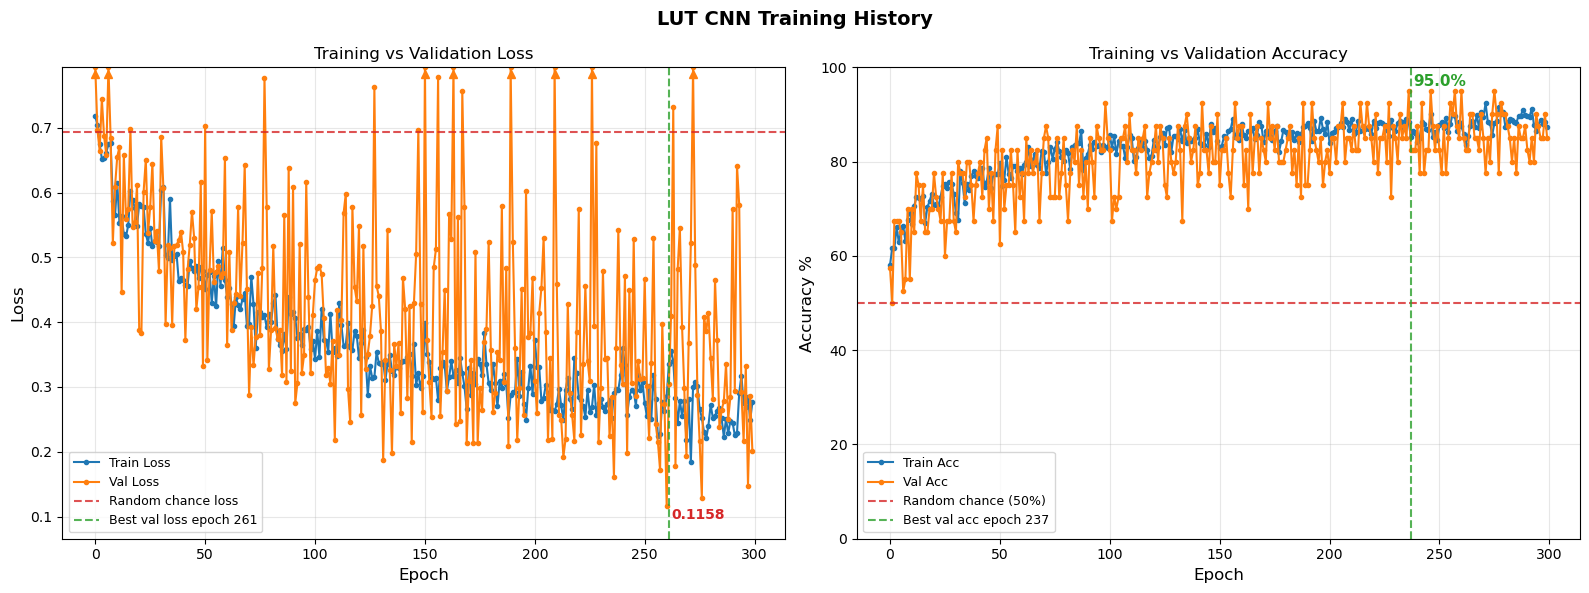

Best val accuracy: 95.0% at epoch 237
Best val loss:     0.1158 at epoch 261


In [54]:
cnn2_model = SecondSimplestFruitClassificationCNN(num_classes=2).to(device)
num_epochs = 300
train_reg(cnn2_model, twoclasstrain_loader, twoclassval_loader, num_epochs)

In [124]:
@dataclass
class SecondLUTConvV2_LinearModel:
    """
    Two LUTConvLayerV2 + Linear Classifier
    
    Architecture:
        LUTConvV2(3, out_channels1) -> ReLU -> Pool
        LUTConvV2(out_channels1, out_channels2) -> ReLU -> Pool
        Flatten
        Linear(out_channels * H * W, num_classes)
    
    Input: (3, 32, 32)
    After conv + pool: (out_channels, 16, 16)
    After flatten: out_channels * 16 * 16
    """
    num_classes:   int
    out_channels1: int  = 16
    out_channels2: int  = 16
    n_tables1:     int  = 16
    n_tables2:     int  = 32
    n_comparisons1:int  = 4
    n_comparisons2:int  = 4
    output_dim1: int = 1
    output_dim2: int = 1
    n_tables_per_channel1: int = 1
    n_tables_per_channel2: int = 4
    seed:          int  = 0
    temperature:   float= 1.0
    training:      bool = True
    freeze_conv1:  bool = True
        
    '''# Initialize LUT classifier
    cfg = LUTClassifierConfig(
        input_dim     = 32*8*8,   # from CNN (4096)
        hidden_dim    = 128,
        num_classes   = 2,
        n_tables      = 128,
        n_comparisons = 4,
        seed          = 43
    )'''
    
    rng:           np.random.Generator = field(init=False)
    conv1:         LUTConvLayerV6      = field(init=False)
    conv2:         LUTConvLayerV6      = field(init=False)
    pool1:         AvgLUTPoolLayer        = field(init=False)
    pool2:         AvgLUTPoolLayer        = field(init=False)
    classifier:    LinearClassifier       = field(init=False)
    
    feature_shape: tuple               = field(init=False)
    relu1_mask:    np.ndarray          = field(init=False)
    relu2_mask:    np.ndarray          = field(init=False)
        
    norm_means:    np.ndarray          = field(init=False)
    norm_stds:      np.ndarray         = field(init=False)
    norm_input:    np.ndarray          = field(init=False)

    def __post_init__(self):
        self.rng   = np.random.default_rng(self.seed)
        
        # Conv layer 1
        self.conv1 = LUTConvLayerV6(
            in_channels   = 3,
            out_channels  = self.out_channels1,
            kernel_size   = 3,
            n_tables      = self.n_tables1, 
            n_comparisons = self.n_comparisons1,
            #output_dim = self.output_dim1,
            #n_tables_per_channel = self.n_tables_per_channel1,
            table_dropout        = 0.0,
            rng           = self.rng,
            #temperature   = self.temperature
        )
        self.pool1 = AvgLUTPoolLayer(2)
        # 32x32 -> 16x16
        
        # Conv layer 2
        self.conv2 = LUTConvLayerV6(
            in_channels   = self.out_channels1,
            out_channels  = self.out_channels2,
            kernel_size   = 3,
            n_tables      = self.n_tables1,
            n_comparisons = self.n_comparisons2,
            #output_dim = self.output_dim2,
            #n_tables_per_channel = self.n_tables_per_channel2,
            table_dropout        = 0.0,
            rng           = self.rng,
            #temperature   = self.temperature
        )
        self.pool2 = AvgLUTPoolLayer(2)
        # 16x16 -> 8x8
        
        # Linear classifier
        cfg = LUTClassifierConfig(
            input_dim     = self.out_channels2 * self.output_dim2 * 4 * 4,   # from CNN (4096)
            hidden_dim    = 128,
            num_classes   = 2,
            n_tables1= 16,
            n_comparisons1= 4,
            n_tables2  = 8,
            n_comparisons2 = 4,
            seed          = 43,
        )
        clf_input_dim = self.out_channels2 * self.output_dim2 * 8 * 8
        self.classifier = LinearClassifier(clf_input_dim, 2, self.rng)
        
        #print(f"\nLUTConvV2 + Linear Classifier")
        #print(f"  conv1:      3 -> {self.out_channels1} channels  "
        #      f"n_comparisons={self.n_comparisons1}  "
        #      f"table_size={1 << self.n_comparisons1}")
        #print(f"  pool1:      32x32 -> 16x16")
        #print(f"  conv2:      {self.out_channels1} -> {self.out_channels2} channels  "
        #      f"n_comparisons={self.n_comparisons2}  "
        #      f"table_size={1 << self.n_comparisons2}")
        #print(f"  pool2:      16x16 -> 8x8")
        #print(f"  classifier: {clf_input_dim} -> {self.num_classes}")
        #print(f"  Total LUT params:    "
        #      f"{self.out_channels1 * (1 << self.n_comparisons1) + self.out_channels2 * (1 << self.n_comparisons2):,}")
        #print(f"  Total Linear params: "
        #      f"{clf_input_dim * self.num_classes + self.num_classes:,}")

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Args:
            x: shape (3, 32, 32)
        Returns:
            logits: shape (num_classes,)
        """
        # LUT Conv 1
        x               = self.conv1.forward(x)
        #self.relu1_mask = (x > 0)
        #x               = np.maximum(0, x)
        x               = self.pool1.forward(x)
        # shape: (out_channels1, 16, 16)
        
        # Normalize conv1 output for conv2
        # Each channel independently normalized
        # so binary comparisons are meaningful
        '''C, H, W = x.shape
        self.norm_means = np.zeros(C)
        self.norm_stds  = np.zeros(C)
        self.norm_input = x.copy()
        
        for c in range(C):
            self.norm_means[c] = x[c].mean()
            self.norm_stds[c]  = x[c].std() + 1e-8
            x[c] = (x[c] - self.norm_means[c]) / self.norm_stds[c]'''
        
        # LUT Conv 1
        x               = self.conv2.forward(x)
        #self.relu2_mask = (x > 0)
        #x               = np.maximum(0, x)
        x               = self.pool2.forward(x)
        # shape: (out_channels2, 8, 8)
        
        # Flatten and classify
        self.feature_shape = x.shape
        logits             = self.classifier.forward(x.flatten())
        
        return logits

    def backward(self, logits_grad: np.ndarray,
                 learning_rate: float) -> None:
        
        def rescale(g, target=0.1, eps=1e-8):
            n = np.linalg.norm(g)
            if n > eps:
                return g * (target / n)
            return g
        
        # Linear classifier backward (exact gradient)
        x_flat_grad = self.classifier.backward(logits_grad, learning_rate)
        x_grad      = x_flat_grad.reshape(self.feature_shape)
        
        # Pool backward
        x_grad      = self.pool2.backward(x_grad)
        
        # ReLU backward
        #x_grad      = x_grad * self.relu2_mask
        #x_grad      = rescale(x_grad)
        
        # LUT Conv 2 backward
        x_grad      = self.conv2.backward(x_grad, learning_rate*100)
        
        # Stop here for just training conv2
        if self.freeze_conv1:
            return
        
        '''C_norm, _, _ = x_grad.shape
        for c in range(C_norm):
            H_norm, W_norm = x_grad[c].shape
            N = H_norm * W_norm
            g = x_grad[c]
            x_norm_c = (self.norm_input[c] - self.norm_means[c]) / self.norm_stds[c]
            # standard batchnorm-style backward for single sample
            x_grad[c] = (1.0 / (N * self.norm_stds[c])) * (
                N * g
                - g.sum()
                - x_norm_c * (g * x_norm_c).sum()
            )
        '''
        # Pool backward
        x_grad      = self.pool1.backward(x_grad)
        
        # ReLU backward
        #x_grad      = x_grad * self.relu1_mask
        #x_grad      = rescale(x_grad)
        
        # LUT Conv 1 backward
        self.conv1.backward(x_grad, learning_rate*100)

In [127]:
# check if soft lut does anything different
model_2layer = SecondLUTConvV2_LinearModel(
    num_classes   = 2,
    out_channels1  = 16,
    out_channels2  = 32,
    n_tables1 = 32,
    n_tables2 = 64,
    n_comparisons1 = 4,
    n_comparisons2 = 4,
    output_dim1 = 1,
    output_dim2 = 1,
    n_tables_per_channel1 = 1,
    n_tables_per_channel2 = 8,
    seed          = 42
)

# Freeze conv1
model_2layer.freeze_conv1 = False

# Train
history = train_lutconv_linear(
    model_2layer,
    twoclasstrain_loader,
    twoclassval_loader,
    'secondlutconvv2_linear.pkl',
    num_epochs = 100,
)

  LUTConvLayerV6:
    in_channels:   3
    out_channels:  16
    n_tables:      32
    n_comparisons: 4
    table_size:    16
    S shape:       (32, 16, 16)
    S params:      8,192
  LUTConvLayerV6:
    in_channels:   16
    out_channels:  32
    n_tables:      32
    n_comparisons: 4
    table_size:    16
    S shape:       (32, 16, 32)
    S params:      16,384
Training LUTConvV2 + Linear Classifier
Epoch [ 1/100]  LR: 0.00095  Train Loss: 0.8084  Train Acc: 56.1%  Val Loss: 0.7642  Val Acc: 52.5%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [ 2/100]  LR: 0.00090  Train Loss: 0.7010  Train Acc: 61.1%  Val Loss: 0.6377  Val Acc: 55.0%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [ 3/100]  LR: 0.00086  Train Loss: 0.6905  Train Acc: 61.8%  Val Loss: 0.8587  Val Acc: 60.0%
  -> Best: val_acc=0.0%  val_loss=inf
Epoch [ 4/100]  LR: 0.00081  Train Loss: 0.7165  Train Acc: 63.5%  Val Loss: 0.4784  Val Acc: 77.5%
Epoch [ 5/100]  LR: 0.00077  Train Loss: 0.6449  Train Acc: 66.2%  Val Loss: 0.

Epoch [71/100]  LR: 0.00003  Train Loss: 0.2815  Train Acc: 88.0%  Val Loss: 0.3595  Val Acc: 85.0%
Epoch [72/100]  LR: 0.00002  Train Loss: 0.3131  Train Acc: 85.4%  Val Loss: 0.2662  Val Acc: 87.5%
Epoch [73/100]  LR: 0.00002  Train Loss: 0.3192  Train Acc: 85.8%  Val Loss: 0.4680  Val Acc: 72.5%
Epoch [74/100]  LR: 0.00002  Train Loss: 0.3170  Train Acc: 84.5%  Val Loss: 0.3782  Val Acc: 85.0%
Epoch [75/100]  LR: 0.00002  Train Loss: 0.3268  Train Acc: 85.6%  Val Loss: 0.5812  Val Acc: 70.0%
Epoch [76/100]  LR: 0.00002  Train Loss: 0.2928  Train Acc: 88.0%  Val Loss: 0.3861  Val Acc: 77.5%
Epoch [77/100]  LR: 0.00002  Train Loss: 0.3284  Train Acc: 83.2%  Val Loss: 0.3467  Val Acc: 85.0%
Epoch [78/100]  LR: 0.00002  Train Loss: 0.2876  Train Acc: 87.6%  Val Loss: 0.5616  Val Acc: 72.5%


KeyboardInterrupt: 

In [ ]:
def verify_patches_per_row(model, train_loader,
                            n_images=20):
    """
    Directly measure how many patches
    actually hit each row in conv2
    
    If mechanism 1 is correct:
        nc2=8: most rows hit by exactly 1 patch
               many rows hit by 0 patches
        nc2=4: rows hit by ~16 patches each
    """
    conv2      = model.conv2
    table_size = 1 << conv2.n_comparisons
    n_tables   = conv2.n_tables
    
    # Accumulate row hit counts across images
    row_hits   = np.zeros((n_tables, table_size),
                           dtype=np.int64)
    n_images_seen = 0
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            if n_images_seen >= n_images:
                break
            
            x    = preprocess_for_lut(img)
            
            # Run conv1 + pool to get conv2 input
            out1 = model.conv1.forward(x)
            out1 = model.pool1.forward(out1)
            
            # Run conv2 forward to get j_all
            _    = model.conv2.forward(out1)
            
            # j_all: (n_patches, n_tables)
            j_all = model.conv2.j_all
            
            for t in range(n_tables):
                for j in model.conv2.j_all[:, t]:
                    row_hits[t, j] += 1
            
            n_images_seen += 1
        if n_images_seen >= n_images:
            break
    
    # Average over images
    row_hits_per_image = row_hits / n_images
    
    # Statistics
    mean_hits = row_hits_per_image.mean()
    zero_rows = (row_hits == 0).sum()
    one_rows  = (row_hits_per_image < 2).sum()
    
    print(f"Conv2 Row Hit Analysis")
    print(f"  n_comparisons: {conv2.n_comparisons}")
    print(f"  table_size:    {table_size}")
    print(f"  n_patches:     {model.conv2.H_out * model.conv2.W_out}")
    print(f"  Expected patches/row: "
          f"{(model.conv2.H_out * model.conv2.W_out) / table_size:.2f}")
    print()
    print(f"  Actual mean patches/row/image: {mean_hits:.3f}")
    print(f"  Rows never hit (over {n_images} images): "
          f"{zero_rows}/{n_tables*table_size}")
    print(f"  Rows hit <2 times per image: "
          f"{one_rows}/{n_tables*table_size}")
    
    # Plot distribution of row hits
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].hist(row_hits_per_image.flatten(),
                  bins=30, color='blue', alpha=0.7,
                  edgecolor='black')
    axes[0].axvline(x=1.0, color='red',
                    linestyle='--',
                    label='1 patch per row')
    axes[0].set_xlabel('Mean patches per row per image')
    axes[0].set_ylabel('Count')
    axes[0].set_title(f'Conv2 Row Hit Distribution\n'
                       f'nc={conv2.n_comparisons}  '
                       f'table_size={table_size}')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Show for one table
    axes[1].bar(range(table_size),
                 row_hits_per_image[0],
                 color='blue', alpha=0.7,
                 edgecolor='black')
    axes[1].axhline(y=1.0, color='red',
                    linestyle='--',
                    label='1 patch/row')
    axes[1].set_xlabel('Row index')
    axes[1].set_ylabel('Mean patches per image')
    axes[1].set_title(f'Table 0 Row Hits\n'
                       f'nc={conv2.n_comparisons}')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return row_hits_per_image

Conv2 Row Hit Analysis
  n_comparisons: 4
  table_size:    16
  n_patches:     256
  Expected patches/row: 16.00

  Actual mean patches/row/image: 16.000
  Rows never hit (over 20 images): 0/4096
  Rows hit <2 times per image: 244/4096


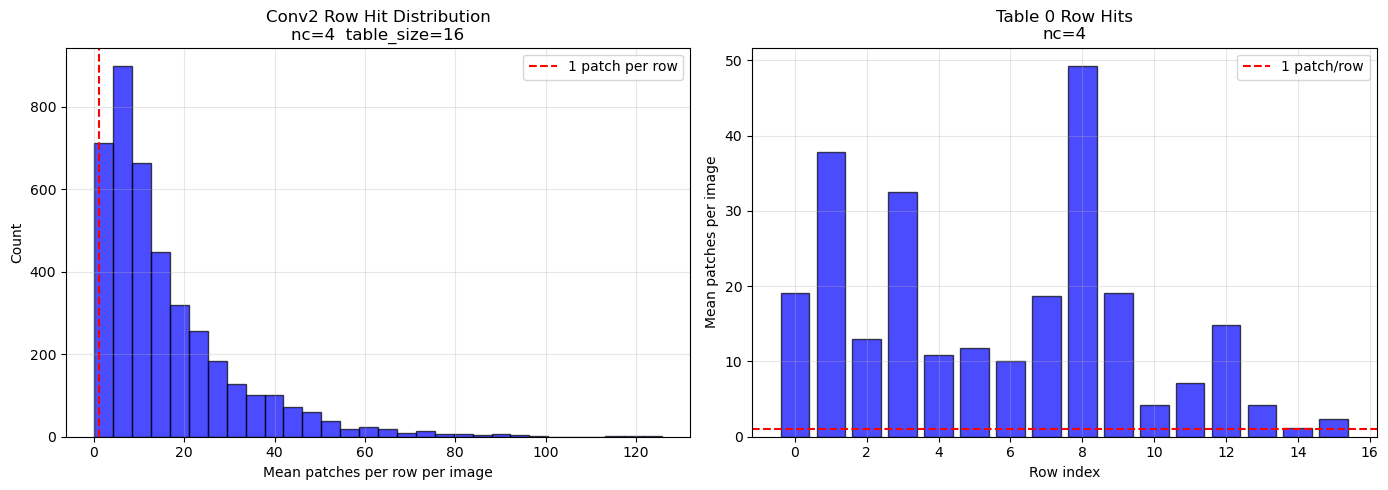

Conv2 Row Hit Analysis
  n_comparisons: 8
  table_size:    256
  n_patches:     256
  Expected patches/row: 1.00

  Actual mean patches/row/image: 1.000
  Rows never hit (over 20 images): 5016/65536
  Rows hit <2 times per image: 57337/65536


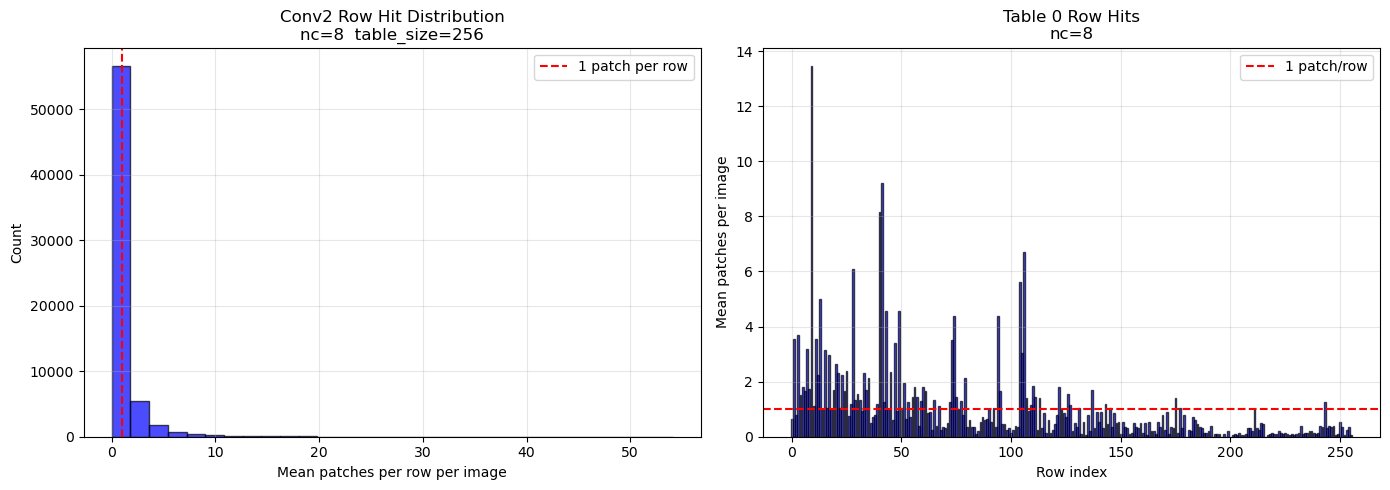

array([[ 0.65,  3.55,  0.8 , ...,  0.25,  0.35,  0.05],
       [ 1.7 ,  2.7 ,  2.4 , ...,  0.15,  0.1 ,  0.05],
       [ 2.1 ,  2.95,  0.75, ...,  0.05,  0.05,  0.  ],
       ...,
       [13.6 ,  2.05, 20.8 , ...,  0.15,  0.05,  0.  ],
       [ 0.9 ,  0.15,  0.3 , ...,  0.75,  0.05,  0.1 ],
       [ 0.5 ,  0.35,  0.35, ...,  0.35,  0.7 ,  0.35]])

In [38]:
modelpatchverify = SecondLUTConvV2_LinearModel(
    num_classes   = 2,
    out_channels1  = 16,
    out_channels2  = 32,
    n_comparisons1 = 4,
    n_comparisons2 = 4,
    output_dim1 = 1,
    output_dim2 = 1,
    n_tables_per_channel1 = 1,
    n_tables_per_channel2 = 8,
    seed          = 42
)
verify_patches_per_row(modelpatchverify, twoclasstrain_loader)
modelpatchverify = SecondLUTConvV2_LinearModel(
    num_classes   = 2,
    out_channels1  = 16,
    out_channels2  = 32,
    n_comparisons1 = 4,
    n_comparisons2 = 8,
    output_dim1 = 1,
    output_dim2 = 1,
    n_tables_per_channel1 = 1,
    n_tables_per_channel2 = 8,
    seed          = 42
)
verify_patches_per_row(modelpatchverify, twoclasstrain_loader)

In [63]:
def measure_gradient_noise(model_1layer,
                            model_2layer,
                            train_loader,
                            n_per_class=50):
    """
    Measure gradient noise by looking at
    variance of gradients across images
    of the SAME CLASS
    
    For a good gradient signal:
        All class 0 images should produce
        gradients pointing in similar directions
        Low variance = consistent signal
    
    For a noisy gradient signal:
        Class 0 images produce gradients
        pointing in different directions
        High variance = noisy signal
    
    This is the correct way to measure noise:
        Not magnitude
        But consistency across same-class samples
    """
    
    def get_gradient_before_conv1(model, x, target):
        """
        Get the gradient vector that arrives
        at conv1 just before conv1 uses it
        Returns flat gradient vector
        """
        is_two_layer = hasattr(model, 'conv2')
        
        logits     = model.forward(x)
        loss, grad = cross_entropy_from_logits(
            logits, target
        )
        
        if is_two_layer:
            x_g = model.classifier.backward(grad, 0.0)
            x_g = x_g.reshape(model.feature_shape)
            x_g = model.pool2.backward(x_g)
            x_g = model.conv2.backward(x_g, 0.0)
            x_g = model.pool1.backward(x_g)
        else:
            x_g = model.classifier.backward(grad, 0.0)
            x_g = x_g.reshape(model.feature_shape)
            x_g = model.pool1.backward(x_g)
        
        return x_g.flatten()
    
    # Collect gradients per class
    grads_by_class_1 = {0: [], 1: []}
    grads_by_class_2 = {0: [], 1: []}
    counts           = {0: 0,  1: 0}
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_per_class:
                continue
            
            x = preprocess_for_lut(img)
            
            g1 = get_gradient_before_conv1(
                model_1layer, x, cls
            )
            g2 = get_gradient_before_conv1(
                model_2layer, x, cls
            )
            
            grads_by_class_1[cls].append(g1)
            grads_by_class_2[cls].append(g2)
            counts[cls] += 1
        
        if all(v >= n_per_class for v in counts.values()):
            break
    
    # Stack into matrices
    # shape: (n_samples, gradient_dim)
    G1_c0 = np.array(grads_by_class_1[0])
    G1_c1 = np.array(grads_by_class_1[1])
    G2_c0 = np.array(grads_by_class_2[0])
    G2_c1 = np.array(grads_by_class_2[1])
    
    def analyze_gradient_consistency(G_c0, G_c1,
                                      name):
        """
        Measures:
        
        1. Mean cosine similarity within class
           High = gradients point same direction
           Low  = gradients point random directions
        
        2. Variance of gradient per dimension
           Low  = consistent signal
           High = noisy signal
        
        3. Mean gradient vs std of gradient
           per dimension (SNR)
        """
        results = {}
        
        for cls, G in [(0, G_c0), (1, G_c1)]:
            
            # Normalize rows to unit vectors
            norms   = np.linalg.norm(G, axis=1,
                                      keepdims=True)
            G_norm  = G / (norms + 1e-10)
            
            # Cosine similarity between all pairs
            cos_sim = G_norm @ G_norm.T
            # Take upper triangle (exclude diagonal)
            n = len(G)
            upper   = cos_sim[np.triu_indices(n, k=1)]
            mean_cos_sim = upper.mean()
            
            # Per-dimension mean and std
            dim_mean = G.mean(axis=0)
            dim_std  = G.std(axis=0)
            
            # SNR per dimension
            snr = (dim_mean**2 /
                   (dim_std**2 + 1e-12))
            mean_snr = snr.mean()
            
            # Fraction of dimensions where
            # mean > std (signal > noise)
            frac_signal = (
                np.abs(dim_mean) > dim_std
            ).mean()
            
            results[cls] = {
                'mean_cos_sim': float(mean_cos_sim),
                'mean_snr':     float(mean_snr),
                'frac_signal':  float(frac_signal),
                'dim_mean_std': float(dim_mean.std()),
                'dim_var_mean': float(dim_std.mean()),
            }
        
        print(f"\n{name}:")
        print(f"  {'Metric':<35} {'Class0':>10} "
              f"{'Class1':>10}")
        print(f"  {'-'*57}")
        
        metrics = [
            ('Mean cosine similarity',  'mean_cos_sim'),
            ('Mean SNR per dimension',  'mean_snr'),
            ('Fraction dims signal>noise','frac_signal'),
            ('Std of per-dim means',    'dim_mean_std'),
            ('Mean per-dim std (noise)','dim_var_mean'),
        ]
        
        for label, key in metrics:
            v0 = results[0][key]
            v1 = results[1][key]
            print(f"  {label:<35} {v0:>10.5f} {v1:>10.5f}")
        
        return results
    
    r1 = analyze_gradient_consistency(
        G1_c0, G1_c1, '1-layer (exact gradient)'
    )
    r2 = analyze_gradient_consistency(
        G2_c0, G2_c1, '2-layer (surrogate gradient)'
    )
    
    # Print comparison
    print(f"\n{'='*60}")
    print(f"Comparison: 1-layer vs 2-layer")
    print(f"{'='*60}")
    print(f"  {'Metric':<35} {'1-layer':>10} "
          f"{'2-layer':>10} {'Ratio':>8}")
    print(f"  {'-'*65}")
    
    for key, label in [
        ('mean_cos_sim', 'Mean cosine similarity'),
        ('mean_snr',     'Mean SNR'),
        ('frac_signal',  'Frac dims signal>noise'),
    ]:
        v1 = (r1[0][key] + r1[1][key]) / 2
        v2 = (r2[0][key] + r2[1][key]) / 2
        print(f"  {label:<35} {v1:>10.5f} "
              f"{v2:>10.5f} "
              f"{v1/(v2+1e-10):>8.3f}x")
    
    # Plot
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    for row, (G_c0, G_c1, name) in enumerate([
        (G1_c0, G1_c1, '1-layer (exact)'),
        (G2_c0, G2_c1, '2-layer (surrogate)'),
    ]):
        # Plot 1: Cosine similarity matrix
        ax = axes[row, 0]
        G_all  = np.vstack([G_c0, G_c1])
        n0, n1 = len(G_c0), len(G_c1)
        norms  = np.linalg.norm(G_all, axis=1,
                                 keepdims=True)
        G_norm = G_all / (norms + 1e-10)
        cos_mat = G_norm @ G_norm.T
        
        im = ax.imshow(cos_mat, cmap='RdBu',
                        vmin=-1, vmax=1)
        ax.axhline(y=n0-0.5, color='yellow',
                   linewidth=2)
        ax.axvline(x=n0-0.5, color='yellow',
                   linewidth=2)
        ax.set_title(f'{name}\nCosine Similarity Matrix\n'
                      f'Yellow line separates classes\n'
                      f'Want: red blocks on diagonal')
        plt.colorbar(im, ax=ax)
        
        # Plot 2: Per-dimension mean gradient
        ax    = axes[row, 1]
        dm_c0 = G_c0.mean(axis=0)
        dm_c1 = G_c1.mean(axis=0)
        ds_c0 = G_c0.std(axis=0)
        ds_c1 = G_c1.std(axis=0)
        
        # Show first 100 dims for clarity
        dims = min(100, len(dm_c0))
        x    = np.arange(dims)
        ax.fill_between(x,
                         dm_c0[:dims] - ds_c0[:dims],
                         dm_c0[:dims] + ds_c0[:dims],
                         alpha=0.3, color='blue')
        ax.fill_between(x,
                         dm_c1[:dims] - ds_c1[:dims],
                         dm_c1[:dims] + ds_c1[:dims],
                         alpha=0.3, color='red')
        ax.plot(x, dm_c0[:dims], color='blue',
                linewidth=1, label='Class 0 mean')
        ax.plot(x, dm_c1[:dims], color='red',
                linewidth=1, label='Class 1 mean')
        ax.axhline(y=0, color='black',
                   linestyle='--', alpha=0.5)
        ax.set_title(f'{name}\nPer-dim Mean ± Std\n'
                      f'Want: mean >> std')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        
        # Plot 3: SNR distribution
        ax  = axes[row, 2]
        snr_c0 = dm_c0**2 / (ds_c0**2 + 1e-12)
        snr_c1 = dm_c1**2 / (ds_c1**2 + 1e-12)
        
        ax.hist(np.log10(snr_c0 + 1e-10),
                 bins=40, alpha=0.6,
                 color='blue', label='Class 0',
                 density=True)
        ax.hist(np.log10(snr_c1 + 1e-10),
                 bins=40, alpha=0.6,
                 color='red', label='Class 1',
                 density=True)
        ax.axvline(x=0, color='black',
                   linestyle='--',
                   label='SNR=1 (signal=noise)')
        ax.set_xlabel('log10(SNR)')
        ax.set_title(f'{name}\nSNR Distribution\n'
                      f'Want: distribution right of 0')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
    
    plt.suptitle(
        'Gradient Noise: 1-layer (exact) vs 2-layer (surrogate)\n'
        'Measuring consistency across same-class images',
        fontsize=13
    )
    plt.tight_layout()
    plt.savefig('gradient_noise.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    
    return r1, r2

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.

1-layer (exact gradient):
  Metric                                  Class0     Class1
  ---------------------------------------------------------
  Mean cosine similarity                 1.00000    1.00000
  Mean SNR per dimension                 8.93261    6.91624
  Fraction dims signal>noise             1.00000    1.00000
  Std of per-dim means                   0.00420    0.00337
  Mean per-dim std (noise)               0.00111    0.00102
Intel MKL WARNING: Support of Intel(R) Streaming SIMD

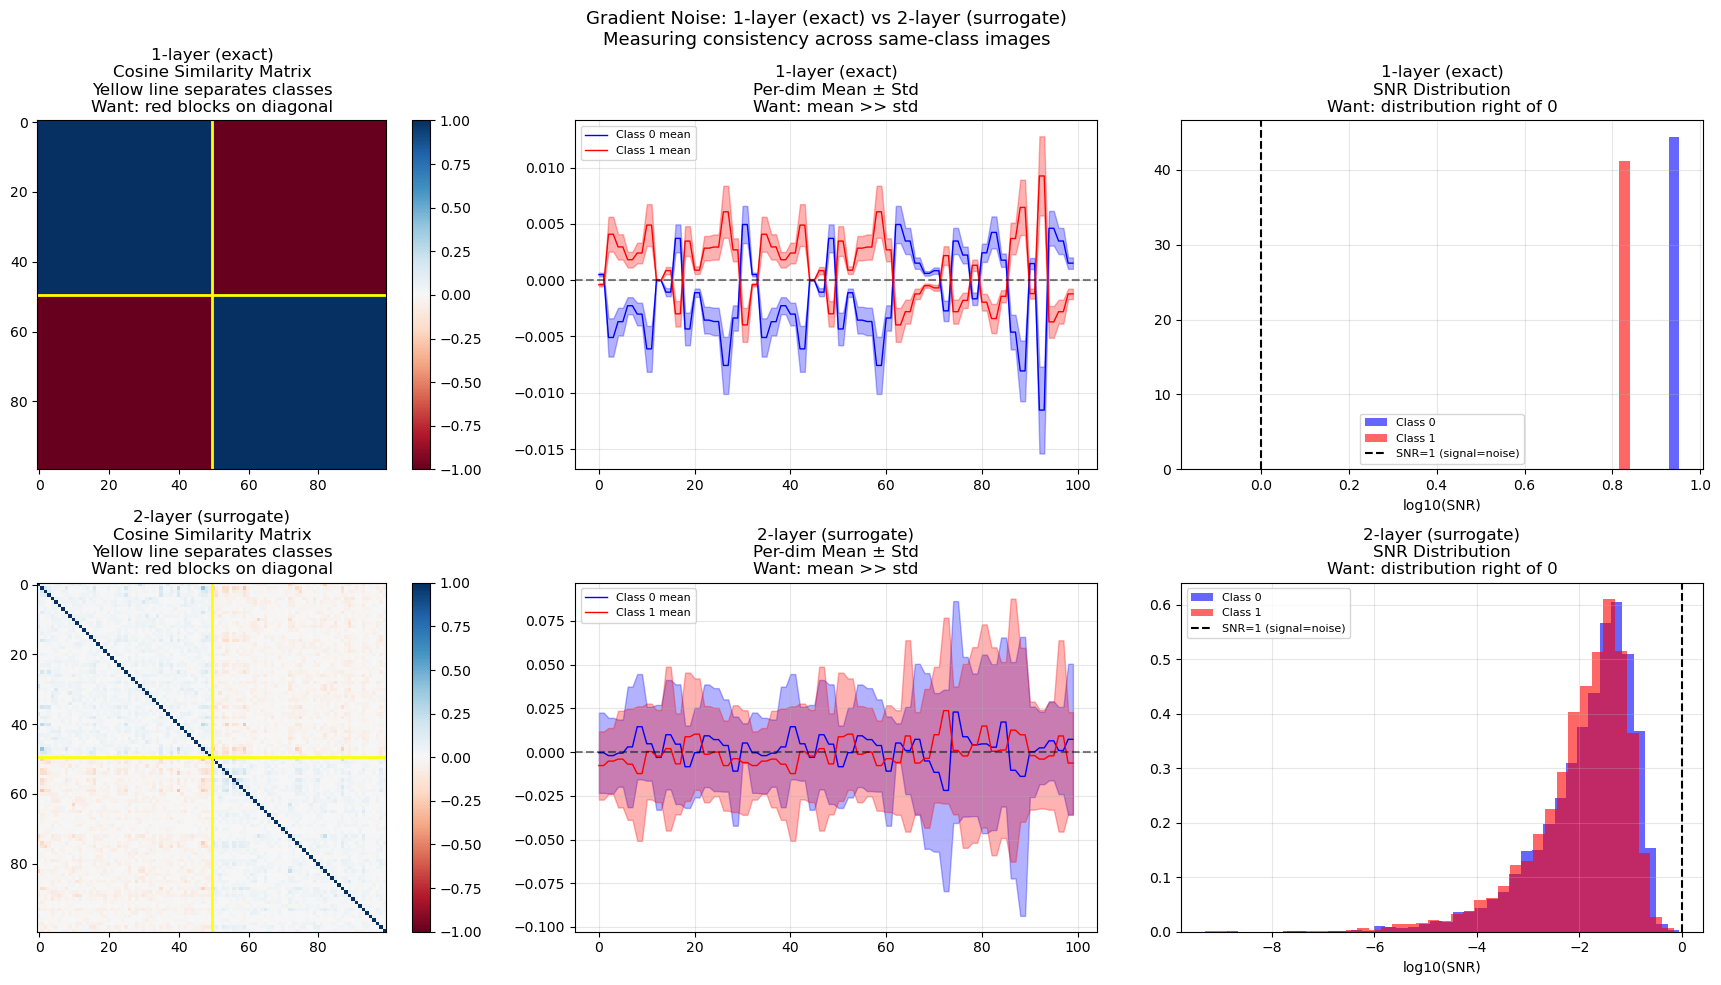

In [81]:
model1layergradvar = LUTConvV2_LinearModel(
    num_classes   = 2,
    out_channels  = 16,
    n_comparisons = 8,    # table_size = 16*32
    output_dim = 1,
    n_tables_per_channel = 1,
    table_dropout = 0.0,
    seed          = 42
)
model2layergradvar = SecondLUTConvV2_LinearModel(
    num_classes   = 2,
    out_channels1  = 16,
    out_channels2  = 32,
    n_comparisons1 = 8,
    n_comparisons2 = 2,
    output_dim1 = 1,
    output_dim2 = 1,
    n_tables_per_channel1 = 1,
    n_tables_per_channel2 = 8,
    seed          = 42
)
res = measure_gradient_noise(model1layergradvar,model2layergradvar,twoclasstrain_loader,n_per_class=50)

In [77]:
def analyze_table_class_separation(model, train_loader,
                                    n_images_per_class=50):
    """
    For each table in conv1 and conv2:
        Measure how well class 0 and class 1
        patches are separated into different rows
    
    Metrics per table:
        1. Row purity:      fraction of rows that are
                            majority one class
        2. Class entropy:   how mixed is each row
        3. Weighted purity: purity weighted by row hit count
        4. Separation score: overall table quality
    """
    model.training = False
    
    # Collect patches and their class labels
    # for each conv layer
    
    conv1_patches_by_class = {0: [], 1: []}
    conv2_patches_by_class = {0: [], 1: []}
    
    counts = {0: 0, 1: 0}
    
    for images, labels in train_loader:
        for img_tensor, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_images_per_class:
                continue
            
            x = preprocess_for_lut(img_tensor)
            
            # Get conv1 patches via forward
            C, H, W  = x.shape
            pad      = model.conv1.kernel_size // 2
            x_pad    = np.pad(x, ((0,0),(pad,pad),(pad,pad)))
            patches1 = model.conv1.im2col_vectorized(
                x_pad, H, W
            )
            # patches1 shape: (n_patches, patch_dim)
            # Store patches with class label
            for p in range(patches1.shape[0]):
                conv1_patches_by_class[cls].append(patches1[p])
            
            # Get conv2 input (conv1 output)
            out1    = model.conv1.forward(x)
            out1    = np.maximum(0, out1)
            out1_p  = model.pool1.forward(out1)
            
            C2, H2, W2 = out1_p.shape
            pad2       = model.conv2.kernel_size // 2
            x2_pad     = np.pad(out1_p,
                                ((0,0),(pad2,pad2),(pad2,pad2)))
            patches2   = model.conv2.im2col_vectorized(
                x2_pad, H2, W2
            )
            for p in range(patches2.shape[0]):
                conv2_patches_by_class[cls].append(patches2[p])
            
            counts[cls] += 1
        
        if all(v >= n_images_per_class for v in counts.values()):
            break
    
    print(f"Collected patches:")
    print(f"  Conv1: {len(conv1_patches_by_class[0])} class0  "
          f"{len(conv1_patches_by_class[1])} class1")
    print(f"  Conv2: {len(conv2_patches_by_class[0])} class0  "
          f"{len(conv2_patches_by_class[1])} class1")
    
    def compute_table_separation(patches_by_class, conv):
        """
        For each table compute how well it
        separates class 0 from class 1 patches
        """
        n_tables    = conv.n_tables
        table_size  = 1 << conv.lut.n_comparisons
        
        # Compute binary index j for each patch
        # for each table
        
        def get_j_all(patches, lut, n_tables, n_comparisons):
            patches = np.array(patches)
            vals_a  = patches[:, lut.anchors_a]
            vals_b  = patches[:, lut.anchors_b]
            diffs   = vals_a - vals_b
            powers  = 1 << np.arange(n_comparisons)
            bits    = (diffs > 0).astype(np.int64)
            j_all   = (bits * powers[None, None, :]).sum(axis=2)
            return j_all
        # j_all shape: (n_patches, n_tables)
        
        p0 = np.array(patches_by_class[0])
        p1 = np.array(patches_by_class[1])
        
        j0 = get_j_all(p0, conv.lut, n_tables,
                        conv.lut.n_comparisons)
        j1 = get_j_all(p1, conv.lut, n_tables,
                        conv.lut.n_comparisons)
        
        table_metrics = []
        
        for t in range(n_tables):
            
            j0_t = j0[:, t]   # which row each class0 patch goes to
            j1_t = j1[:, t]   # which row each class1 patch goes to
            
            # Count class 0 and class 1 hits per row
            hits0 = np.bincount(j0_t, minlength=table_size)
            hits1 = np.bincount(j1_t, minlength=table_size)
            
            total_hits = hits0 + hits1
            
            # ---- Metric 1: Row Purity ----
            # For each row: what fraction is majority class?
            # Pure row: one class dominates
            # Mixed row: both classes present equally
            
            row_purity = []
            row_entropy = []
            
            for row in range(table_size):
                total = hits0[row] + hits1[row]
                if total == 0:
                    continue
                
                p0_row = hits0[row] / total
                p1_row = hits1[row] / total
                
                # Purity = how dominant is majority class
                purity = max(p0_row, p1_row)
                row_purity.append(purity)
                
                # Entropy = how mixed is the row
                # 0 = pure one class
                # 1 = perfectly mixed (50/50)
                eps = 1e-10
                h   = -(p0_row * np.log2(p0_row + eps) +
                         p1_row * np.log2(p1_row + eps))
                row_entropy.append(h)
            
            mean_purity  = np.mean(row_purity) if row_purity else 0
            mean_entropy = np.mean(row_entropy) if row_entropy else 1
            
            # ---- Metric 2: Weighted Purity ----
            # Weight each row by how many patches hit it
            # Rows with more hits matter more
            
            weighted_purity = 0
            total_patches   = total_hits.sum()
            
            if total_patches > 0:
                for row in range(table_size):
                    total = hits0[row] + hits1[row]
                    if total == 0:
                        continue
                    p0_row = hits0[row] / total
                    purity = max(p0_row, 1 - p0_row)
                    weight = total / total_patches
                    weighted_purity += weight * purity
            
            # ---- Metric 3: Class Overlap ----
            # Do class 0 and class 1 hit different rows?
            
            rows_with_class0 = set(np.where(hits0 > 0)[0])
            rows_with_class1 = set(np.where(hits1 > 0)[0])
            
            rows_both  = rows_with_class0 & rows_with_class1
            rows_only0 = rows_with_class0 - rows_with_class1
            rows_only1 = rows_with_class1 - rows_with_class0
            rows_neither = set(range(table_size)) - \
                           rows_with_class0 - rows_with_class1
            
            # Separation score:
            # fraction of USED rows that are class-exclusive
            n_used = len(rows_with_class0 | rows_with_class1)
            n_exclusive = len(rows_only0) + len(rows_only1)
            separation = n_exclusive / n_used if n_used > 0 else 0
            
            # ---- Metric 4: Jensen-Shannon Divergence ----
            # How different are the class distributions
            # over rows?
            # 0 = identical distributions (no separation)
            # 1 = completely different (perfect separation)
            
            p0_dist = hits0 / (hits0.sum() + 1e-10)
            p1_dist = hits1 / (hits1.sum() + 1e-10)
            m_dist  = (p0_dist + p1_dist) / 2
            
            eps = 1e-10
            jsd = 0.5 * np.sum(
                p0_dist * np.log2(p0_dist / (m_dist + eps) + eps)
            ) + 0.5 * np.sum(
                p1_dist * np.log2(p1_dist / (m_dist + eps) + eps)
            )
            jsd = np.clip(jsd, 0, 1)
            
            table_metrics.append({
                'table':            t,
                'mean_purity':      mean_purity,
                'mean_entropy':     mean_entropy,
                'weighted_purity':  weighted_purity,
                'separation':       separation,
                'jsd':              jsd,
                'rows_only_c0':     len(rows_only0),
                'rows_only_c1':     len(rows_only1),
                'rows_both':        len(rows_both),
                'rows_neither':     len(rows_neither),
                'hits0':            hits0,
                'hits1':            hits1,
            })
        
        return table_metrics
    
    print(f"\nAnalyzing conv1 tables...")
    conv1_metrics = compute_table_separation(
        conv1_patches_by_class, model.conv1
    )
    
    print(f"Analyzing conv2 tables...")
    conv2_metrics = compute_table_separation(
        conv2_patches_by_class, model.conv2
    )
    
    plot_table_separation(conv1_metrics, conv2_metrics, model)
    print_table_summary(conv1_metrics, 'Conv1')
    print_table_summary(conv2_metrics, 'Conv2')
    
    return conv1_metrics, conv2_metrics


def print_table_summary(metrics, name):
    """Print per-table separation scores"""
    
    print(f"\n{'='*70}")
    print(f"{name} Table Separation Analysis")
    print(f"{'='*70}")
    print(f"{'Table':<7} {'Purity':>8} {'W.Purity':>10} "
          f"{'JSD':>8} {'Sep':>8} "
          f"{'Only0':>7} {'Only1':>7} {'Both':>7}")
    print(f"{'-'*70}")
    
    for m in metrics:
        bar = '█' * int(m['jsd'] * 20)
        print(f"{m['table']:<7} "
              f"{m['mean_purity']:>8.3f} "
              f"{m['weighted_purity']:>10.3f} "
              f"{m['jsd']:>8.4f} "
              f"{m['separation']:>8.3f} "
              f"{m['rows_only_c0']:>7} "
              f"{m['rows_only_c1']:>7} "
              f"{m['rows_both']:>7}  "
              f"{bar}")
    
    jsds = [m['jsd'] for m in metrics]
    seps = [m['separation'] for m in metrics]
    purs = [m['weighted_purity'] for m in metrics]
    
    print(f"\nSummary:")
    print(f"  Mean JSD:              {np.mean(jsds):.4f}")
    print(f"  Best table JSD:        {max(jsds):.4f} "
          f"(table {np.argmax(jsds)})")
    print(f"  Worst table JSD:       {min(jsds):.4f} "
          f"(table {np.argmin(jsds)})")
    print(f"  Mean separation:       {np.mean(seps):.3f}")
    print(f"  Mean weighted purity:  {np.mean(purs):.3f}")
    
    # How many tables are useful?
    useful = sum(1 for m in metrics if m['jsd'] > 0.1)
    print(f"  Useful tables (JSD>0.1): {useful}/{len(metrics)}")


def plot_table_separation(conv1_metrics, conv2_metrics, model):
    """
    Visualize per-table class separation
    """
    fig, axes = plt.subplots(3, 2, figsize=(18, 16))
    
    for col, (metrics, name) in enumerate([
        (conv1_metrics, 'Conv1'),
        (conv2_metrics, 'Conv2')
    ]):
        tables = [m['table'] for m in metrics]
        jsds   = [m['jsd']              for m in metrics]
        purs   = [m['weighted_purity']  for m in metrics]
        seps   = [m['separation']       for m in metrics]
        
        # ---- Plot 1: JSD per table ----
        ax = axes[0, col]
        colors = ['green' if j > 0.1 else 'red' for j in jsds]
        bars   = ax.bar(tables, jsds, color=colors,
                         alpha=0.8, edgecolor='black')
        ax.axhline(y=0.1, color='black', linestyle='--',
                   alpha=0.7, label='Useful threshold')
        ax.set_xlabel('Table index')
        ax.set_ylabel('Jensen-Shannon Divergence')
        ax.set_title(f'{name}: Class Separation per Table\n'
                      f'Green=useful  Red=not useful')
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_ylim(0, 1)
        
        # Add value labels
        for bar, jsd in zip(bars, jsds):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.01,
                    f'{jsd:.2f}',
                    ha='center', va='bottom', fontsize=7)
        
        # ---- Plot 2: Row distribution heatmap ----
        ax = axes[1, col]
        
        table_size = len(metrics[0]['hits0'])
        n_tables   = len(metrics)
        
        # Build heatmap: fraction of class 0 in each row
        heatmap = np.zeros((n_tables, table_size))
        for i, m in enumerate(metrics):
            total = m['hits0'] + m['hits1']
            mask  = total > 0
            frac  = np.zeros(table_size)
            frac[mask] = m['hits0'][mask] / total[mask]
            heatmap[i] = frac
        
        im = ax.imshow(heatmap, aspect='auto',
                        cmap='RdYlGn', vmin=0, vmax=1)
        ax.set_xlabel('Row index')
        ax.set_ylabel('Table index')
        ax.set_title(f'{name}: Class 0 Fraction per Row\n'
                      f'Green=pure class0  Red=pure class1  '
                      f'Yellow=mixed')
        plt.colorbar(im, ax=ax, label='Fraction class 0')
        
        # ---- Plot 3: Row counts ----
        ax = axes[2, col]
        
        only0   = [m['rows_only_c0'] for m in metrics]
        only1   = [m['rows_only_c1'] for m in metrics]
        both    = [m['rows_both']    for m in metrics]
        neither = [m['rows_neither'] for m in metrics]
        
        x = np.arange(len(metrics))
        w = 0.2
        
        ax.bar(x - 1.5*w, only0,   width=w,
                color='green',  alpha=0.8, label='Only class 0')
        ax.bar(x - 0.5*w, only1,   width=w,
                color='blue',   alpha=0.8, label='Only class 1')
        ax.bar(x + 0.5*w, both,    width=w,
                color='orange', alpha=0.8, label='Both classes')
        ax.bar(x + 1.5*w, neither, width=w,
                color='gray',   alpha=0.8, label='Never hit')
        
        ax.set_xlabel('Table index')
        ax.set_ylabel('Number of rows')
        ax.set_title(f'{name}: Row Usage by Class')
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_xticks(x)
        ax.set_xticklabels(tables)
    
    plt.suptitle('Per-Table Class Separation Analysis\n'
                 'High JSD = table creates class-separating hash',
                 fontsize=14)
    plt.tight_layout()
    plt.savefig('table_separation.png',
                dpi=150, bbox_inches='tight')
    plt.show()

In [409]:
def analyze_table_class_separation2(model, train_loader,
                                    n_images_per_class=50):
    """
    For each table in conv1:
        Measure how well class 0 and class 1
        patches are separated into different rows
    """
    model.training = False
    
    conv1_patches_by_class = {0: [], 1: []}
    counts = {0: 0, 1: 0}
    
    for images, labels in train_loader:
        for img_tensor, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_images_per_class:
                continue
            
            x        = preprocess_for_lut(img_tensor)
            C, H, W  = x.shape
            pad      = model.conv1.kernel_size // 2
            x_pad    = np.pad(x, ((0,0),(pad,pad),(pad,pad)))
            patches1 = model.conv1.im2col_vectorized(x_pad, H, W)
            
            for p in range(patches1.shape[0]):
                conv1_patches_by_class[cls].append(patches1[p])
            
            counts[cls] += 1
        
        if all(v >= n_images_per_class for v in counts.values()):
            break
    
    print(f"Collected patches:")
    print(f"  Conv1: {len(conv1_patches_by_class[0])} class0  "
          f"{len(conv1_patches_by_class[1])} class1")
    
    def compute_table_separation(patches_by_class, conv):
        
        n_tables   = conv.n_tables
        table_size = 1 << conv.lut.n_comparisons
        
        def get_j_all(patches, lut, n_comparisons):
            patches = np.array(patches)
            vals_a  = patches[:, lut.anchors_a]
            vals_b  = patches[:, lut.anchors_b]
            diffs   = vals_a - vals_b
            powers  = 1 << np.arange(n_comparisons)
            bits    = (diffs > 0).astype(np.int64)
            return (bits * powers[None, None, :]).sum(axis=2)
        
        p0    = np.array(patches_by_class[0])
        p1    = np.array(patches_by_class[1])
        j0    = get_j_all(p0, conv.lut, conv.lut.n_comparisons)
        j1    = get_j_all(p1, conv.lut, conv.lut.n_comparisons)
        
        table_metrics = []
        
        for t in range(n_tables):
            
            j0_t  = j0[:, t]
            j1_t  = j1[:, t]
            hits0 = np.bincount(j0_t, minlength=table_size)
            hits1 = np.bincount(j1_t, minlength=table_size)
            total_hits = hits0 + hits1
            
            # Row purity
            row_purity  = []
            row_entropy = []
            for row in range(table_size):
                total = hits0[row] + hits1[row]
                if total == 0:
                    continue
                p0_row = hits0[row] / total
                p1_row = hits1[row] / total
                row_purity.append(max(p0_row, p1_row))
                eps = 1e-10
                h   = -(p0_row * np.log2(p0_row + eps) +
                         p1_row * np.log2(p1_row + eps))
                row_entropy.append(h)
            
            mean_purity  = np.mean(row_purity)  if row_purity  else 0
            mean_entropy = np.mean(row_entropy) if row_entropy else 1
            
            # Weighted purity
            weighted_purity = 0
            total_patches   = total_hits.sum()
            if total_patches > 0:
                for row in range(table_size):
                    total = hits0[row] + hits1[row]
                    if total == 0:
                        continue
                    p0_row  = hits0[row] / total
                    purity  = max(p0_row, 1 - p0_row)
                    weight  = total / total_patches
                    weighted_purity += weight * purity
            
            # Class overlap
            rows0        = set(np.where(hits0 > 0)[0])
            rows1        = set(np.where(hits1 > 0)[0])
            rows_both    = rows0 & rows1
            rows_only0   = rows0 - rows1
            rows_only1   = rows1 - rows0
            rows_neither = set(range(table_size)) - rows0 - rows1
            
            n_used      = len(rows0 | rows1)
            n_exclusive = len(rows_only0) + len(rows_only1)
            separation  = n_exclusive / n_used if n_used > 0 else 0
            
            # JSD
            p0_dist = hits0 / (hits0.sum() + 1e-10)
            p1_dist = hits1 / (hits1.sum() + 1e-10)
            m_dist  = (p0_dist + p1_dist) / 2
            eps     = 1e-10
            jsd     = float(np.clip(
                0.5 * np.sum(
                    p0_dist * np.log2(p0_dist/(m_dist+eps)+eps)
                ) + 0.5 * np.sum(
                    p1_dist * np.log2(p1_dist/(m_dist+eps)+eps)
                ), 0, 1
            ))
            
            table_metrics.append({
                'table':           t,
                'mean_purity':     mean_purity,
                'mean_entropy':    mean_entropy,
                'weighted_purity': weighted_purity,
                'separation':      separation,
                'jsd':             jsd,
                'rows_only_c0':    len(rows_only0),
                'rows_only_c1':    len(rows_only1),
                'rows_both':       len(rows_both),
                'rows_neither':    len(rows_neither),
                'hits0':           hits0,
                'hits1':           hits1,
            })
        
        return table_metrics
    
    print(f"\nAnalyzing conv1 tables...")
    conv1_metrics = compute_table_separation(
        conv1_patches_by_class, model.conv1
    )
    
    plot_table_separation_1layer(conv1_metrics, model)
    print_table_summary(conv1_metrics, 'Conv1')
    
    return conv1_metrics


def plot_table_separation_1layer(conv1_metrics, model):
    """
    Visualize per-table class separation
    for single conv layer model
    """
    fig, axes = plt.subplots(3, 1, figsize=(14, 18))
    
    metrics = conv1_metrics
    name    = 'Conv1'
    
    tables = [m['table']           for m in metrics]
    jsds   = [m['jsd']             for m in metrics]
    purs   = [m['weighted_purity'] for m in metrics]
    
    # ---- Plot 1: JSD per table ----
    ax     = axes[0]
    colors = ['green' if j > 0.1 else 'red' for j in jsds]
    bars   = ax.bar(tables, jsds, color=colors,
                     alpha=0.8, edgecolor='black')
    ax.axhline(y=0.1, color='black', linestyle='--',
               alpha=0.7, label='Useful threshold (0.1)')
    ax.set_xlabel('Table index')
    ax.set_ylabel('Jensen-Shannon Divergence')
    ax.set_title(f'{name}: Class Separation per Table\n'
                  f'Green = JSD > 0.1 (useful)  '
                  f'Red = JSD < 0.1 (not useful)')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1)
    ax.set_xticks(tables)
    
    for bar, jsd in zip(bars, jsds):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01,
                f'{jsd:.3f}',
                ha='center', va='bottom', fontsize=8)
    
    # ---- Plot 2: Row distribution heatmap ----
    ax         = axes[1]
    table_size = len(metrics[0]['hits0'])
    n_tables   = len(metrics)
    
    heatmap = np.zeros((n_tables, table_size))
    for i, m in enumerate(metrics):
        total     = m['hits0'] + m['hits1']
        mask      = total > 0
        frac      = np.zeros(table_size)
        frac[mask]= m['hits0'][mask] / total[mask]
        heatmap[i]= frac
    
    im = ax.imshow(heatmap, aspect='auto',
                    cmap='RdYlGn', vmin=0, vmax=1)
    ax.set_xlabel('Row index')
    ax.set_ylabel('Table index')
    ax.set_title(f'{name}: Class 0 Fraction per Row\n'
                  f'Green = pure class 0  '
                  f'Red = pure class 1  '
                  f'Yellow = mixed')
    ax.set_yticks(range(n_tables))
    ax.set_yticklabels(tables)
    ax.set_xticks(range(table_size))
    plt.colorbar(im, ax=ax, label='Fraction class 0')
    
    # ---- Plot 3: Row counts stacked bar ----
    ax      = axes[2]
    only0   = [m['rows_only_c0'] for m in metrics]
    only1   = [m['rows_only_c1'] for m in metrics]
    both    = [m['rows_both']    for m in metrics]
    neither = [m['rows_neither'] for m in metrics]
    
    x = np.arange(len(metrics))
    w = 0.6
    
    b1 = ax.bar(x, only0,   width=w, color='green',
                 alpha=0.8, label='Only class 0')
    b2 = ax.bar(x, only1,   width=w, color='blue',
                 alpha=0.8, label='Only class 1',
                 bottom=only0)
    b3 = ax.bar(x, both,    width=w, color='orange',
                 alpha=0.8, label='Both classes',
                 bottom=np.array(only0)+np.array(only1))
    b4 = ax.bar(x, neither, width=w, color='gray',
                 alpha=0.8, label='Never hit',
                 bottom=np.array(only0)+np.array(only1)+np.array(both))
    
    ax.axhline(y=table_size, color='black',
               linestyle='--', alpha=0.5,
               label=f'Total rows ({table_size})')
    ax.set_xlabel('Table index')
    ax.set_ylabel('Number of rows')
    ax.set_title(f'{name}: Row Usage by Class\n'
                  f'Ideal = all green + blue, no orange')
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_xticks(x)
    ax.set_xticklabels(tables)
    ax.set_ylim(0, table_size + 1)
    
    plt.suptitle(
        f'Conv1 Table Class Separation Analysis\n'
        f'n_tables={model.conv1.n_tables}  '
        f'n_comparisons={model.conv1.lut.n_comparisons}  '
        f'table_size={table_size}',
        fontsize=13
    )
    plt.tight_layout()
    plt.savefig('table_separation_1layer.png',
                dpi=150, bbox_inches='tight')
    plt.show()

In [420]:
def analyze_table_class_separation_cnn(model, train_loader,
                                        n_images_per_class=50,
                                        device='cpu'):
    """
    For each conv layer in a CNN:
        Measure how well class 0 and class 1
        activations are separated by each filter
    
    Works for both:
        1 layer CNN: SimplestFruitClassificationCNN
        2 layer CNN: any CNN with features.0 and features.4
                     (or similar structure)
    
    Automatically detects number of conv layers
    """
    import torch
    model.eval()
    model.to(device)
    
    # ---- Detect conv layers ----
    conv_layers  = []
    conv_names   = []
    
    for name, module in model.named_modules():
        if isinstance(module, torch.nn.Conv2d):
            conv_layers.append(module)
            conv_names.append(name)
    
    n_conv = len(conv_layers)
    print(f"Detected {n_conv} conv layer(s):")
    for name, layer in zip(conv_names, conv_layers):
        print(f"  {name}: {layer.in_channels} -> "
              f"{layer.out_channels} channels  "
              f"kernel={layer.kernel_size[0]}x"
              f"{layer.kernel_size[0]}")
    print()
    
    # ---- Register hooks on all conv layers ----
    all_outputs  = {i: [] for i in range(n_conv)}
    hooks        = []
    
    def make_hook(layer_idx):
        def hook_fn(module, input, output):
            all_outputs[layer_idx].append(
                output.detach().cpu().numpy()
            )
        return hook_fn
    
    for i, layer in enumerate(conv_layers):
        hooks.append(
            layer.register_forward_hook(make_hook(i))
        )
    
    # ---- Collect activations ----
    activations_by_layer_class = {
        i: {0: [], 1: []} for i in range(n_conv)
    }
    counts = {0: 0, 1: 0}
    
    with torch.no_grad():
        for images, labels in train_loader:
            for img_tensor, label in zip(images, labels):
                cls = label.item()
                if counts[cls] >= n_images_per_class:
                    continue
                
                # Clear previous outputs
                for i in range(n_conv):
                    all_outputs[i].clear()
                
                img_batch = img_tensor.unsqueeze(0).to(device)
                _         = model(img_batch)
                
                # Store activations per layer
                for i in range(n_conv):
                    act = all_outputs[i][-1][0]
                    activations_by_layer_class[i][cls].append(act)
                
                counts[cls] += 1
            
            if all(v >= n_images_per_class
                   for v in counts.values()):
                break
    
    for hook in hooks:
        hook.remove()
    
    print(f"Collected activations:")
    for i in range(n_conv):
        n0 = len(activations_by_layer_class[i][0])
        n1 = len(activations_by_layer_class[i][1])
        sh = activations_by_layer_class[i][0][0].shape
        print(f"  Conv{i+1}: {n0} class0  {n1} class1  "
              f"shape={sh}")
    print()
    
    # ---- Compute metrics per layer ----
    all_layer_metrics = []
    n_bins            = 16
    
    def compute_filter_metrics(acts_c0, acts_c1,
                                n_filters, n_bins):
        """
        Compute separation metrics for all filters
        in one conv layer
        """
        filter_metrics = []
        
        for f in range(n_filters):
            
            f_acts_c0  = acts_c0[:, f, :, :].flatten()
            f_acts_c1  = acts_c1[:, f, :, :].flatten()
            f_acts_all = np.concatenate([f_acts_c0, f_acts_c1])
            
            # Percentile bins
            bin_edges       = np.percentile(
                f_acts_all,
                np.linspace(0, 100, n_bins + 1)
            )
            bin_edges[0]   -= 1e-8
            bin_edges[-1]  += 1e-8
            
            bins_c0 = np.clip(
                np.digitize(f_acts_c0, bin_edges) - 1,
                0, n_bins - 1
            )
            bins_c1 = np.clip(
                np.digitize(f_acts_c1, bin_edges) - 1,
                0, n_bins - 1
            )
            
            hits0      = np.bincount(bins_c0, minlength=n_bins)
            hits1      = np.bincount(bins_c1, minlength=n_bins)
            total_hits = hits0 + hits1
            
            # Row purity
            row_purity  = []
            row_entropy = []
            for row in range(n_bins):
                total = hits0[row] + hits1[row]
                if total == 0:
                    continue
                p0_row = hits0[row] / total
                p1_row = hits1[row] / total
                row_purity.append(max(p0_row, p1_row))
                eps = 1e-10
                h   = -(p0_row * np.log2(p0_row + eps) +
                         p1_row * np.log2(p1_row + eps))
                row_entropy.append(h)
            
            mean_purity  = np.mean(row_purity)  if row_purity  else 0
            mean_entropy = np.mean(row_entropy) if row_entropy else 1
            
            # Weighted purity
            weighted_purity = 0
            total_patches   = total_hits.sum()
            if total_patches > 0:
                for row in range(n_bins):
                    total = hits0[row] + hits1[row]
                    if total == 0:
                        continue
                    p0_row  = hits0[row] / total
                    purity  = max(p0_row, 1 - p0_row)
                    weight  = total / total_patches
                    weighted_purity += weight * purity
            
            # Bin overlap
            rows0        = set(np.where(hits0 > 0)[0])
            rows1        = set(np.where(hits1 > 0)[0])
            rows_both    = rows0 & rows1
            rows_only0   = rows0 - rows1
            rows_only1   = rows1 - rows0
            rows_neither = set(range(n_bins)) - rows0 - rows1
            
            n_used      = len(rows0 | rows1)
            n_exclusive = len(rows_only0) + len(rows_only1)
            separation  = n_exclusive / n_used if n_used > 0 else 0
            
            # JSD
            p0_dist = hits0 / (hits0.sum() + 1e-10)
            p1_dist = hits1 / (hits1.sum() + 1e-10)
            m_dist  = (p0_dist + p1_dist) / 2
            eps     = 1e-10
            jsd     = float(np.clip(
                0.5 * np.sum(
                    p0_dist * np.log2(p0_dist/(m_dist+eps)+eps)
                ) + 0.5 * np.sum(
                    p1_dist * np.log2(p1_dist/(m_dist+eps)+eps)
                ), 0, 1
            ))
            
            # Cohen's d
            mean_c0    = f_acts_c0.mean()
            mean_c1    = f_acts_c1.mean()
            std_c0     = f_acts_c0.std()
            std_c1     = f_acts_c1.std()
            pooled_std = np.sqrt((std_c0**2 + std_c1**2) / 2)
            cohens_d   = abs(mean_c0 - mean_c1) / (pooled_std + 1e-8)
            
            filter_metrics.append({
                'filter':          f,
                'mean_purity':     mean_purity,
                'mean_entropy':    mean_entropy,
                'weighted_purity': weighted_purity,
                'separation':      separation,
                'jsd':             jsd,
                'rows_only_c0':    len(rows_only0),
                'rows_only_c1':    len(rows_only1),
                'rows_both':       len(rows_both),
                'rows_neither':    len(rows_neither),
                'hits0':           hits0,
                'hits1':           hits1,
                'mean_act_c0':     mean_c0,
                'mean_act_c1':     mean_c1,
                'cohens_d':        cohens_d,
            })
        
        return filter_metrics
    
    for i in range(n_conv):
        acts_c0   = np.array(activations_by_layer_class[i][0])
        acts_c1   = np.array(activations_by_layer_class[i][1])
        n_filters = conv_layers[i].out_channels
        
        print(f"Analyzing Conv{i+1} ({conv_names[i]}) "
              f"[{n_filters} filters]...")
        
        metrics = compute_filter_metrics(
            acts_c0, acts_c1, n_filters, n_bins
        )
        all_layer_metrics.append(metrics)
        print_filter_summary(metrics, n_bins,
                              layer_name=f'Conv{i+1}')
    
    plot_filter_separation_multilayer(
        all_layer_metrics, conv_layers,
        conv_names, n_bins
    )
    
    return all_layer_metrics


def print_filter_summary(metrics, n_bins, layer_name='Conv'):
    
    print(f"\n{'='*80}")
    print(f"{layer_name} Filter Class Separation Analysis")
    print(f"(Activations binned into {n_bins} bins)")
    print(f"{'='*80}")
    print(f"{'Filter':<8} {'Purity':>8} {'W.Purity':>10} "
          f"{'JSD':>8} {'Cohen_d':>9} "
          f"{'Only0':>7} {'Only1':>7} {'Both':>7}")
    print(f"{'-'*75}")
    
    for m in metrics:
        bar = '█' * int(m['jsd'] * 20)
        print(f"{m['filter']:<8} "
              f"{m['mean_purity']:>8.3f} "
              f"{m['weighted_purity']:>10.3f} "
              f"{m['jsd']:>8.4f} "
              f"{m['cohens_d']:>9.4f} "
              f"{m['rows_only_c0']:>7} "
              f"{m['rows_only_c1']:>7} "
              f"{m['rows_both']:>7}  "
              f"{bar}")
    
    jsds     = [m['jsd']             for m in metrics]
    cohens   = [m['cohens_d']        for m in metrics]
    purs     = [m['weighted_purity'] for m in metrics]
    useful   = sum(1 for j in jsds if j > 0.1)
    
    print(f"\nSummary:")
    print(f"  Mean JSD:                 {np.mean(jsds):.4f}")
    print(f"  Best filter JSD:          {max(jsds):.4f} "
          f"(filter {np.argmax(jsds)})")
    print(f"  Mean Cohen's d:           {np.mean(cohens):.4f}")
    print(f"  Best Cohen's d:           {max(cohens):.4f} "
          f"(filter {np.argmax(cohens)})")
    print(f"  Mean weighted purity:     {np.mean(purs):.4f}")
    print(f"  Useful filters (JSD>0.1): {useful}/{len(metrics)}")


def plot_filter_separation_multilayer(all_layer_metrics,
                                       conv_layers,
                                       conv_names,
                                       n_bins):
    """
    Plot separation analysis for all conv layers
    4 plots per layer stacked vertically
    """
    n_conv   = len(all_layer_metrics)
    n_rows   = 4 * n_conv   # 4 plots per conv layer
    fig, axes = plt.subplots(n_rows, 1,
                              figsize=(14, 6 * n_conv * 2))
    
    # Make axes always a list even for 1 layer
    if n_rows == 4:
        axes = list(axes)
    
    for layer_idx, metrics in enumerate(all_layer_metrics):
        
        layer      = conv_layers[layer_idx]
        name       = conv_names[layer_idx]
        n_filters  = layer.out_channels
        
        filters   = [m['filter']           for m in metrics]
        jsds      = [m['jsd']              for m in metrics]
        cohens_d  = [m['cohens_d']         for m in metrics]
        purs      = [m['weighted_purity']  for m in metrics]
        
        base = layer_idx * 4   # which row of axes to start at
        
        # ---- Plot 1: JSD per filter ----
        ax     = axes[base + 0]
        colors = ['green' if j > 0.1 else 'red' for j in jsds]
        bars   = ax.bar(filters, jsds, color=colors,
                         alpha=0.8, edgecolor='black')
        ax.axhline(y=0.1, color='black', linestyle='--',
                   alpha=0.7, label='Useful threshold (0.1)')
        ax.set_xlabel('Filter index')
        ax.set_ylabel('JSD')
        ax.set_title(f'[{name}] Filter Class Separation (JSD)\n'
                      f'Green = JSD > 0.1  Red = JSD < 0.1')
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_ylim(0, 1)
        ax.set_xticks(filters)
        for bar, jsd in zip(bars, jsds):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.01,
                    f'{jsd:.3f}',
                    ha='center', va='bottom', fontsize=7)
        
        # ---- Plot 2: Cohen's d per filter ----
        ax     = axes[base + 1]
        colors = ['green'  if d > 0.5 else
                   'orange' if d > 0.2 else
                   'red'    for d in cohens_d]
        bars   = ax.bar(filters, cohens_d, color=colors,
                         alpha=0.8, edgecolor='black')
        ax.axhline(y=0.5, color='green',  linestyle='--',
                   alpha=0.7, label='Medium effect (0.5)')
        ax.axhline(y=0.2, color='orange', linestyle='--',
                   alpha=0.7, label='Small effect (0.2)')
        ax.set_xlabel('Filter index')
        ax.set_ylabel("Cohen's d")
        ax.set_title(f"[{name}] Filter Effect Size (Cohen's d)")
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_xticks(filters)
        for bar, d in zip(bars, cohens_d):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.005,
                    f'{d:.2f}',
                    ha='center', va='bottom', fontsize=7)
        
        # ---- Plot 3: Activation heatmap ----
        ax      = axes[base + 2]
        heatmap = np.zeros((n_filters, n_bins))
        for i, m in enumerate(metrics):
            total       = m['hits0'] + m['hits1']
            mask        = total > 0
            frac        = np.zeros(n_bins)
            frac[mask]  = m['hits0'][mask] / total[mask]
            heatmap[i]  = frac
        
        im = ax.imshow(heatmap, aspect='auto',
                        cmap='RdYlGn', vmin=0, vmax=1)
        ax.set_xlabel('Activation bin (low -> high)')
        ax.set_ylabel('Filter index')
        ax.set_title(f'[{name}] Class 0 Fraction per Bin\n'
                      f'Green=class0  Red=class1  Yellow=mixed')
        ax.set_yticks(range(n_filters))
        ax.set_yticklabels(filters)
        ax.set_xticks(range(n_bins))
        plt.colorbar(im, ax=ax, label='Fraction class 0')
        
        # ---- Plot 4: Stacked bin usage ----
        ax      = axes[base + 3]
        only0   = [m['rows_only_c0'] for m in metrics]
        only1   = [m['rows_only_c1'] for m in metrics]
        both    = [m['rows_both']    for m in metrics]
        neither = [m['rows_neither'] for m in metrics]
        
        x  = np.arange(n_filters)
        w  = 0.6
        ax.bar(x, only0,   width=w, color='green',
                alpha=0.8, label='Only class 0')
        ax.bar(x, only1,   width=w, color='blue',
                alpha=0.8, label='Only class 1',
                bottom=only0)
        ax.bar(x, both,    width=w, color='orange',
                alpha=0.8, label='Both classes',
                bottom=np.array(only0)+np.array(only1))
        ax.bar(x, neither, width=w, color='gray',
                alpha=0.8, label='Never activated',
                bottom=(np.array(only0) +
                         np.array(only1) +
                         np.array(both)))
        ax.axhline(y=n_bins, color='black',
                   linestyle='--', alpha=0.5,
                   label=f'Total bins ({n_bins})')
        ax.set_xlabel('Filter index')
        ax.set_ylabel('Number of bins')
        ax.set_title(f'[{name}] Bin Usage by Class')
        ax.legend(fontsize=9, loc='upper right')
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_xticks(x)
        ax.set_xticklabels(filters)
        ax.set_ylim(0, n_bins + 1)
    
    n_params = sum(p.numel()
                   for l in conv_layers
                   for p in l.parameters())
    
    plt.suptitle(
        f'CNN Filter Class Separation Analysis\n'
        f'{n_conv} conv layer(s)  '
        f'total conv params={n_params}  '
        f'activation_bins={n_bins}',
        fontsize=13
    )
    plt.tight_layout()
    plt.savefig('cnn_filter_separation.png',
                dpi=150, bbox_inches='tight')
    plt.show()

Collected patches:
  Conv1: 51200 class0  51200 class1
  Conv2: 12800 class0  12800 class1

Analyzing conv1 tables...
Analyzing conv2 tables...


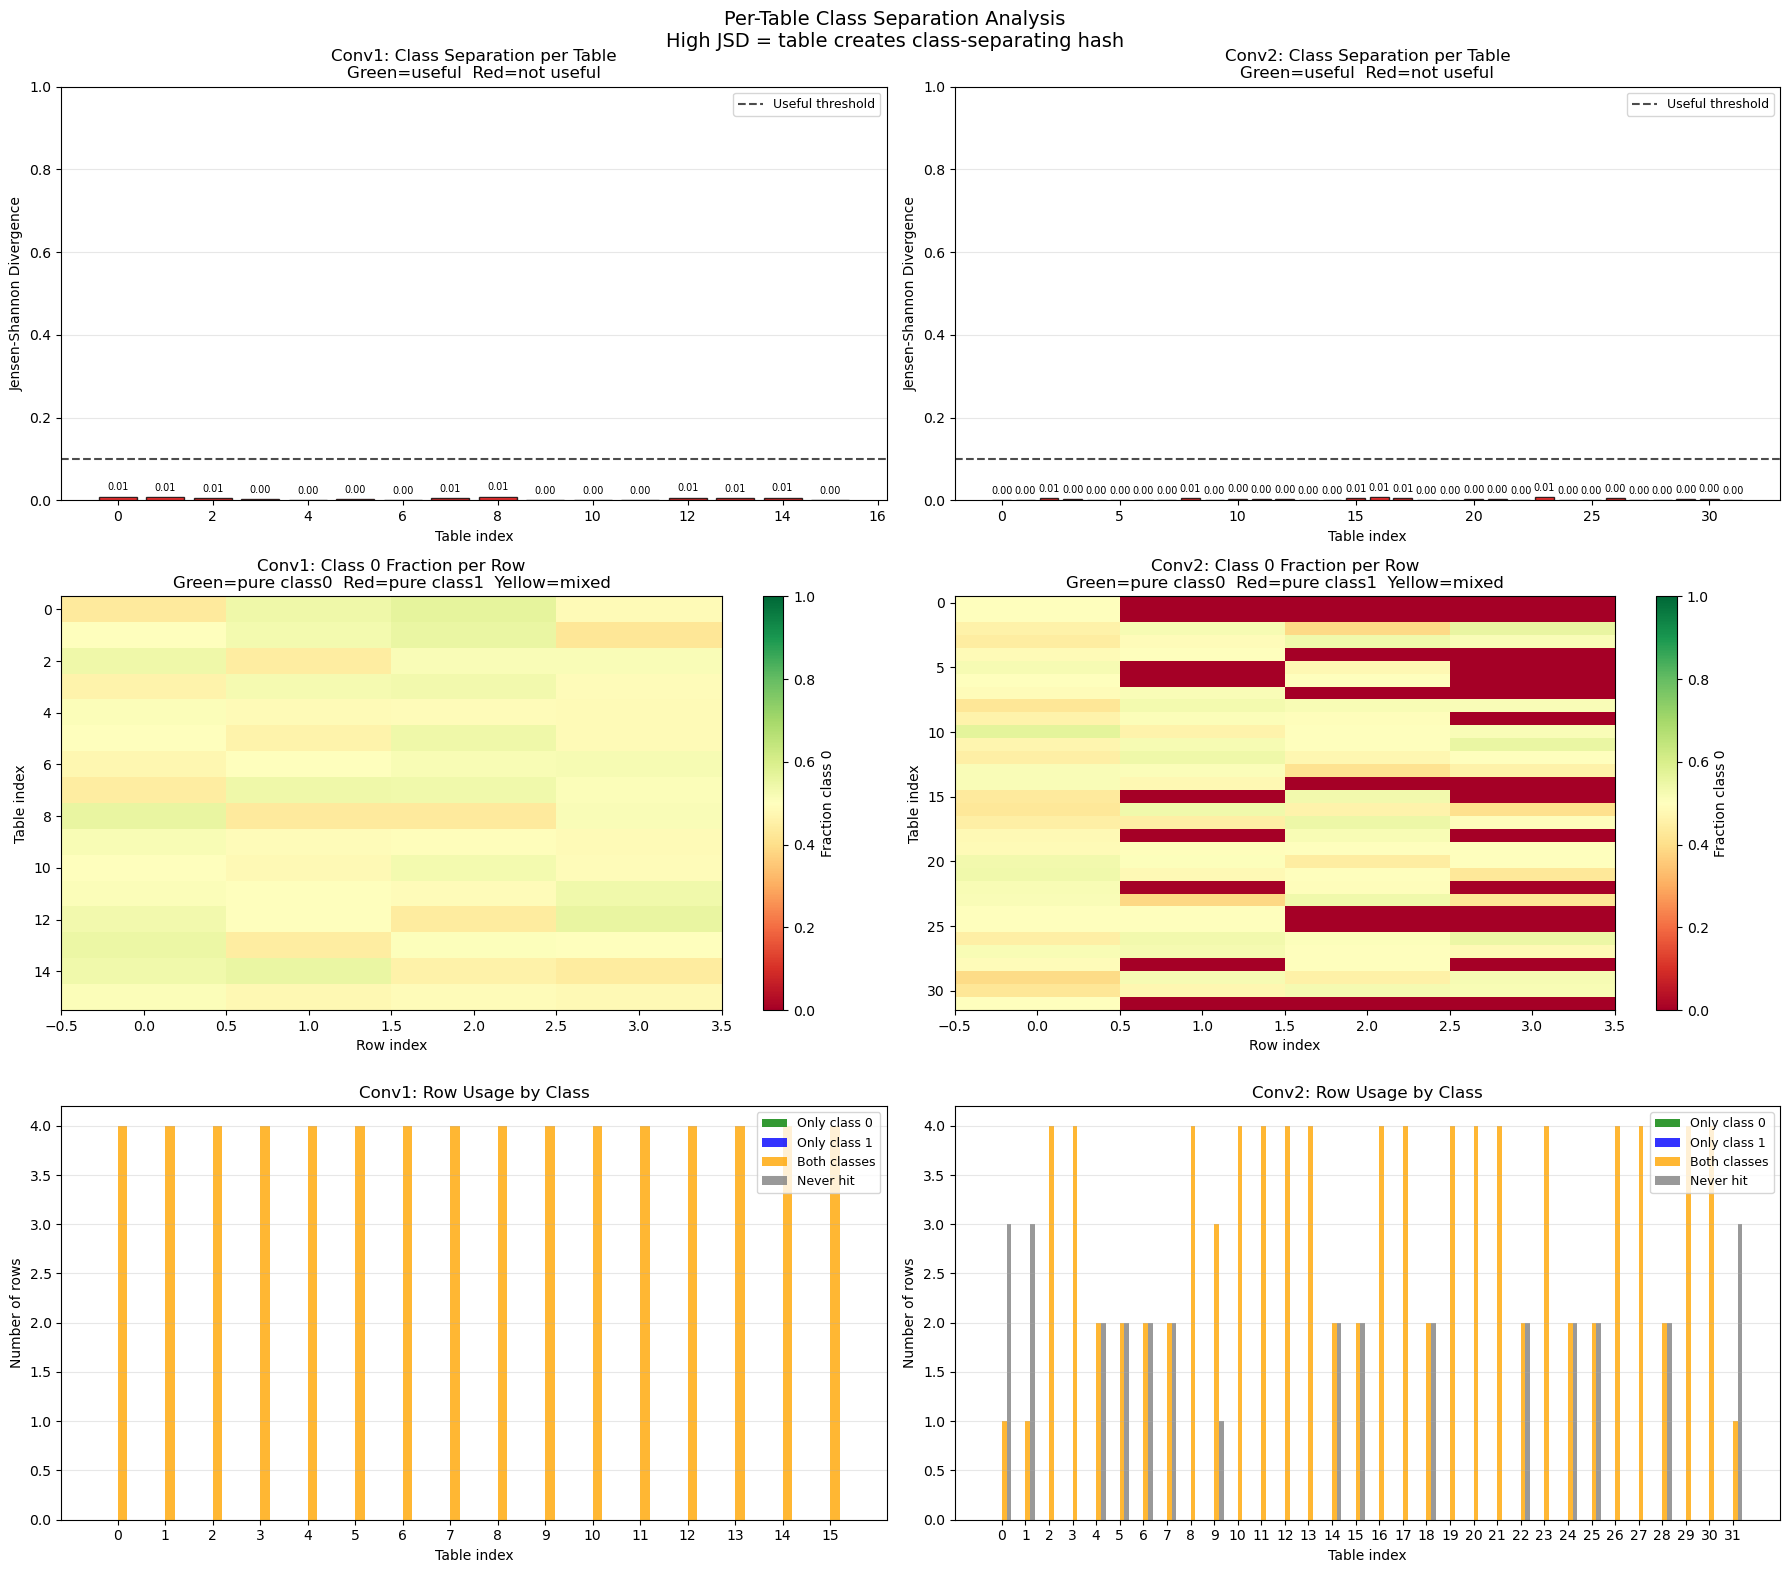


Conv1 Table Separation Analysis
Table     Purity   W.Purity      JSD      Sep   Only0   Only1    Both
----------------------------------------------------------------------
0          0.546      0.553   0.0091    0.000       0       0       4  
1          0.540      0.545   0.0082    0.000       0       0       4  
2          0.531      0.540   0.0055    0.000       0       0       4  
3          0.527      0.531   0.0030    0.000       0       0       4  
4          0.512      0.510   0.0003    0.000       0       0       4  
5          0.525      0.527   0.0028    0.000       0       0       4  
6          0.516      0.511   0.0007    0.000       0       0       4  
7          0.535      0.541   0.0056    0.000       0       0       4  
8          0.551      0.554   0.0093    0.000       0       0       4  
9          0.511      0.510   0.0004    0.000       0       0       4  
10         0.514      0.509   0.0005    0.000       0       0       4  
11         0.515      0.511   0.00

In [354]:
conv1_metrics, conv2_metrics = analyze_table_class_separation(
    model2_layer, twoclasstrain_loader,
    n_images_per_class = 50
)

Collected patches:
  Conv1: 51200 class0  51200 class1

Analyzing conv1 tables...


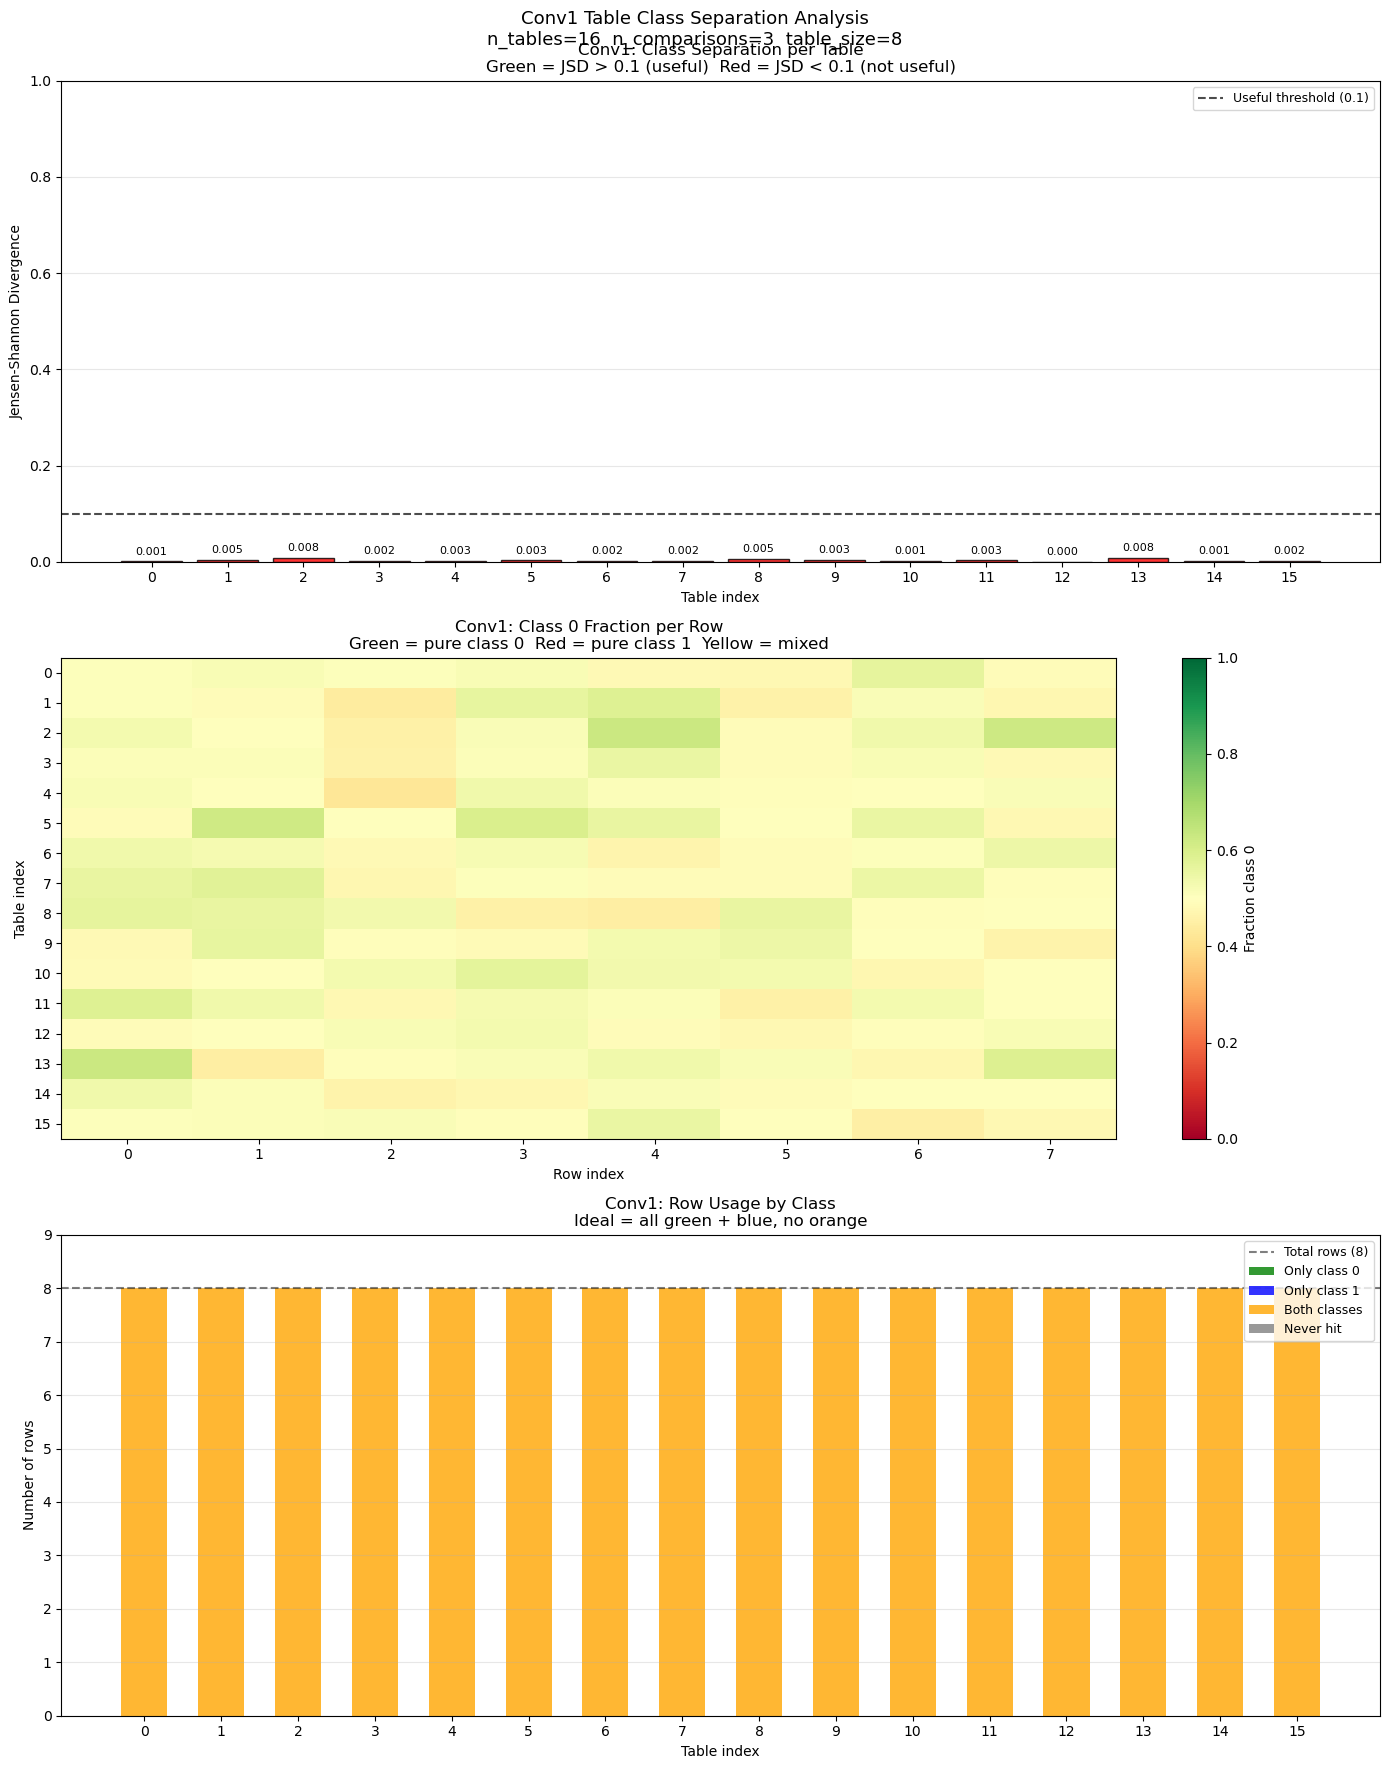


Conv1 Table Separation Analysis
Table     Purity   W.Purity      JSD      Sep   Only0   Only1    Both
----------------------------------------------------------------------
0          0.520      0.514   0.0009    0.000       0       0       8  
1          0.538      0.531   0.0047    0.000       0       0       8  
2          0.549      0.541   0.0084    0.000       0       0       8  
3          0.521      0.521   0.0020    0.000       0       0       8  
4          0.520      0.519   0.0026    0.000       0       0       8  
5          0.546      0.518   0.0028    0.000       0       0       8  
6          0.524      0.525   0.0022    0.000       0       0       8  
7          0.531      0.519   0.0019    0.000       0       0       8  
8          0.539      0.537   0.0053    0.000       0       0       8  
9          0.526      0.527   0.0033    0.000       0       0       8  
10         0.525      0.520   0.0014    0.000       0       0       8  
11         0.532      0.526   0.00

In [413]:
conv1_metrics = analyze_table_class_separation2(
    model,
    twoclasstrain_loader,
    n_images_per_class = 50
)

Detected 2 conv layer(s):
  features.0: 3 -> 16 channels  kernel=3x3
  features.4: 16 -> 32 channels  kernel=3x3

Collected activations:
  Conv1: 50 class0  50 class1  shape=(16, 32, 32)
  Conv2: 50 class0  50 class1  shape=(32, 16, 16)

Analyzing Conv1 (features.0) [16 filters]...

Conv1 Filter Class Separation Analysis
(Activations binned into 16 bins)
Filter     Purity   W.Purity      JSD   Cohen_d   Only0   Only1    Both
---------------------------------------------------------------------------
0           0.537      0.536   0.0086    0.0221       0       0      16  
1           0.558      0.554   0.0141    0.0212       0       0      15  
2           0.548      0.548   0.0100    0.0322       0       0      15  
3           0.551      0.550   0.0118    0.0606       0       0      15  
4           0.552      0.550   0.0107    0.0593       0       0      15  
5           0.543      0.540   0.0102    0.0655       0       0      15  
6           0.555      0.552   0.0144    0.0710    

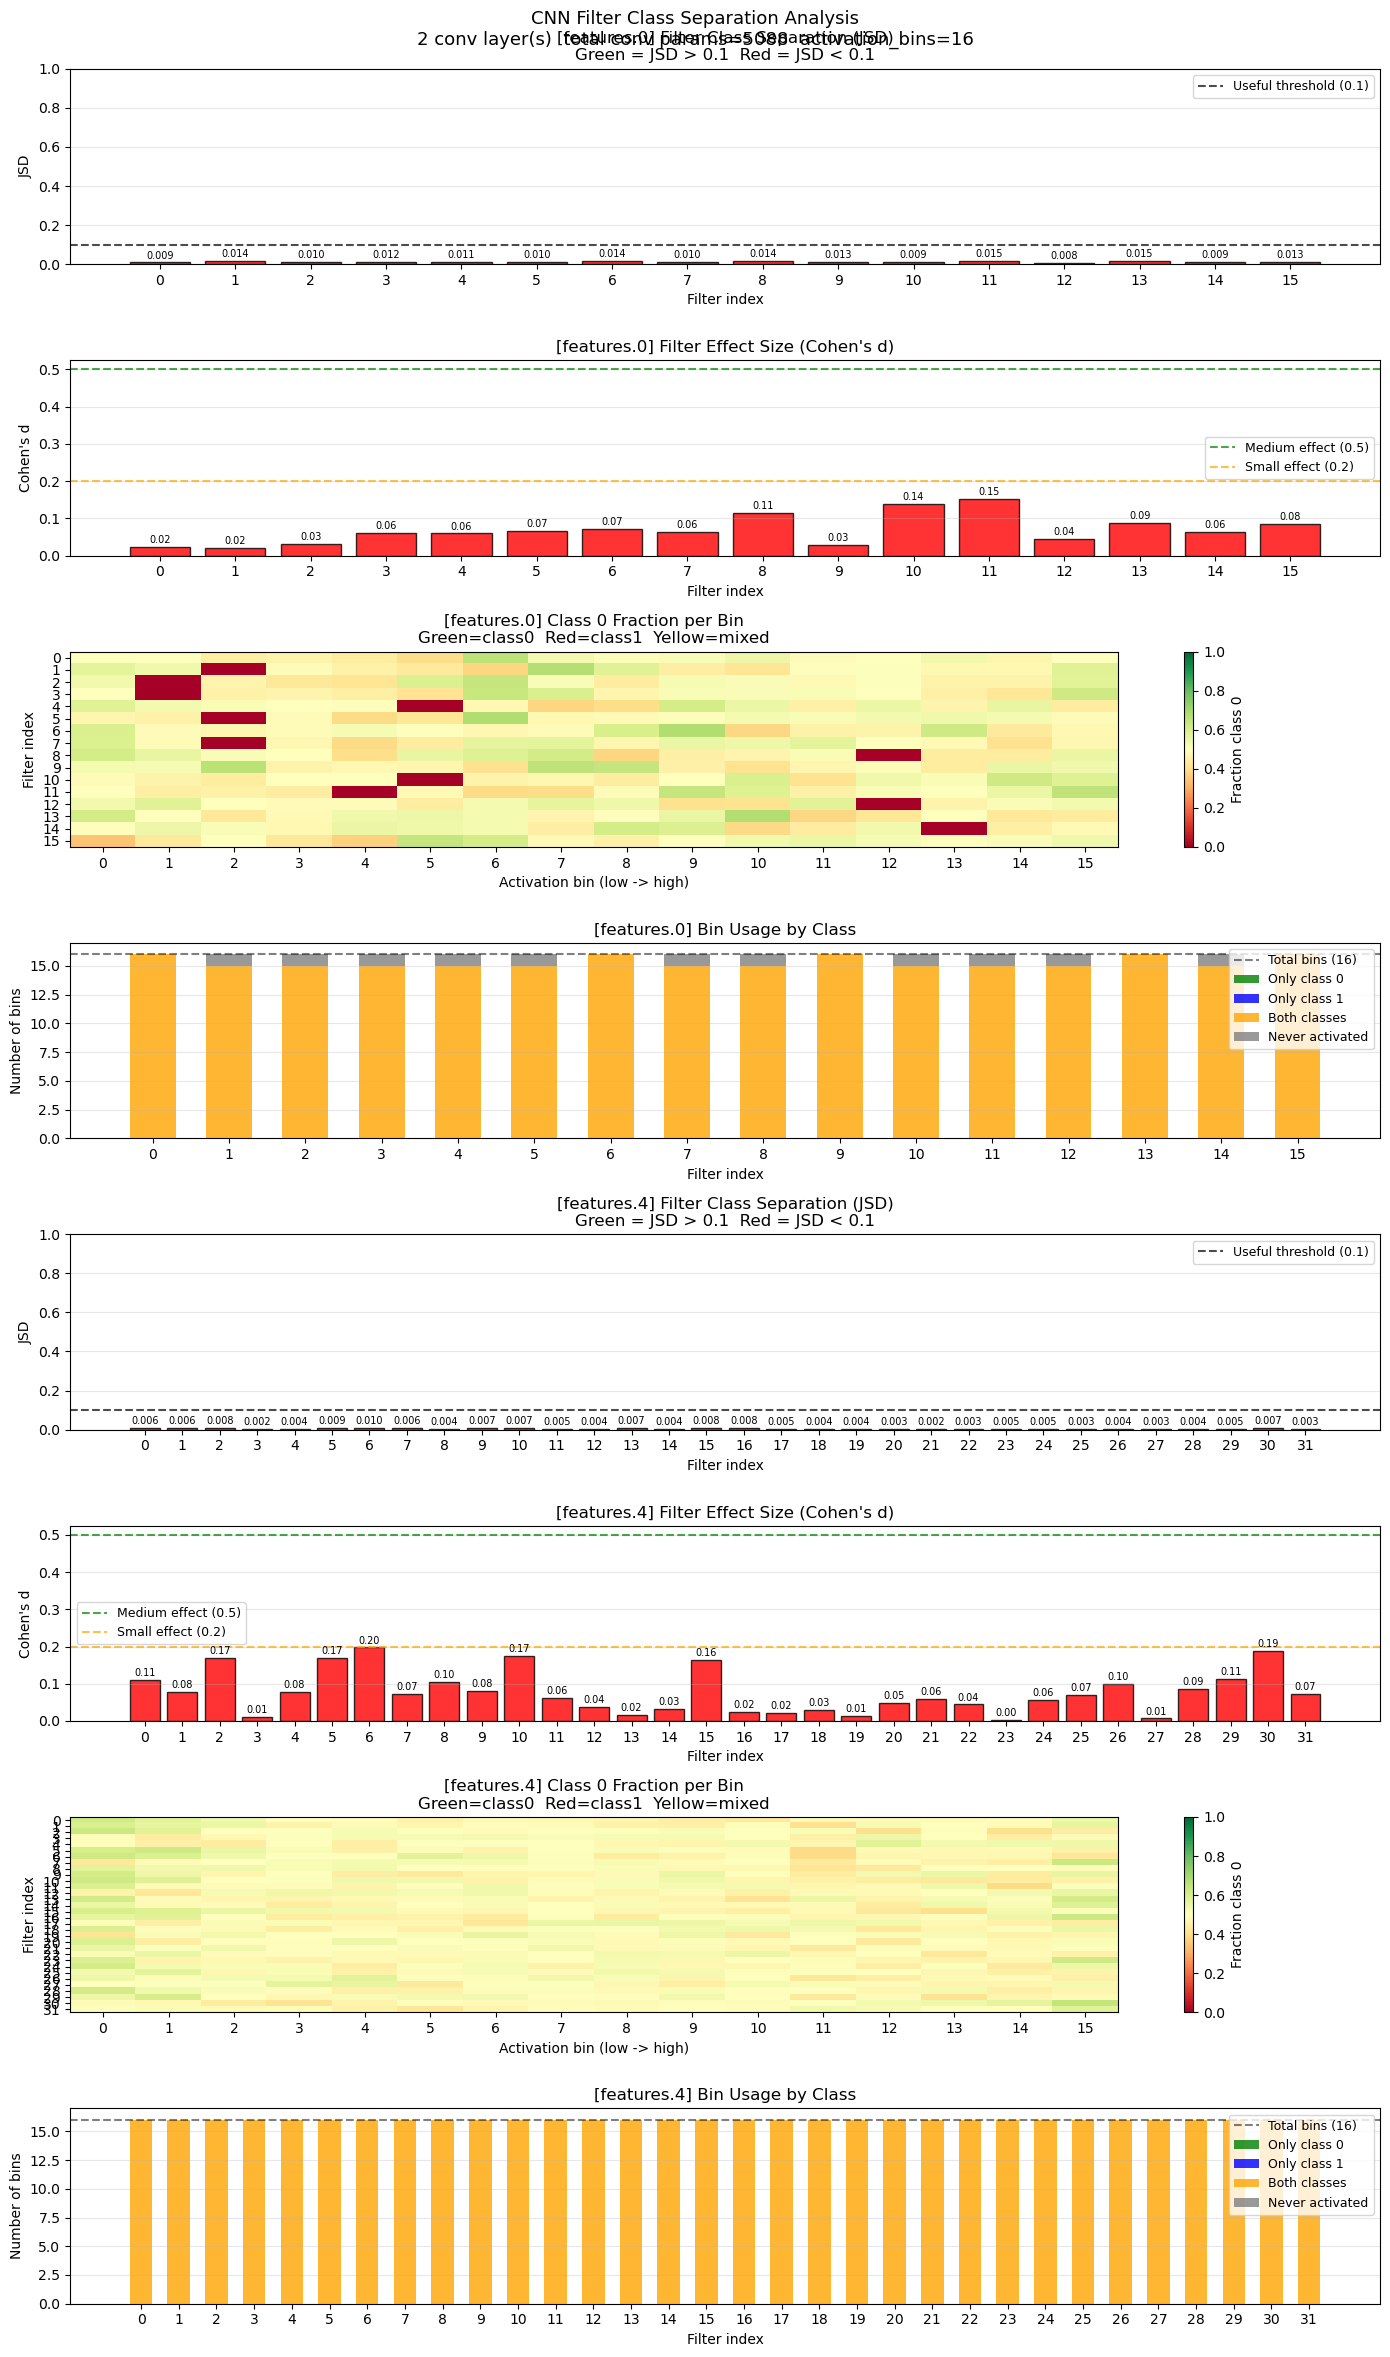

In [421]:
filter_metrics = analyze_table_class_separation_cnn(
    model              = cnn2_model,
    train_loader       = twoclasstrain_loader,
    n_images_per_class = 50,
    device             = 'cpu'
)

In [425]:
def plot_cnn_feature_heatmaps(model, train_loader,
                               device='cpu',
                               n_images=8):
    """
    Visualize what each conv layer responds to
    by showing activation heatmaps overlaid
    on original images
    
    For each image shows:
        Original image
        Conv1 mean activation heatmap
        Conv2 mean activation heatmap
        Conv1 max activation heatmap
        Conv2 max activation heatmap
    """
    import torch
    import torch.nn.functional as F
    
    model.eval()
    model.to(device)
    
    # ---- Detect conv layers ----
    conv_layers = []
    conv_names  = []
    for name, module in model.named_modules():
        if isinstance(module, torch.nn.Conv2d):
            conv_layers.append(module)
            conv_names.append(name)
    
    n_conv = len(conv_layers)
    print(f"Found {n_conv} conv layers: {conv_names}")
    
    # ---- Register hooks ----
    layer_activations = {i: None for i in range(n_conv)}
    hooks             = []
    
    def make_hook(idx):
        def hook_fn(module, input, output):
            layer_activations[idx] = \
                output.detach().cpu()
        return hook_fn
    
    for i, layer in enumerate(conv_layers):
        hooks.append(
            layer.register_forward_hook(make_hook(i))
        )
    
    # ---- Collect images and activations ----
    images_collected  = []
    labels_collected  = []
    acts_collected    = {i: [] for i in range(n_conv)}
    
    with torch.no_grad():
        for images, labels in train_loader:
            for img, label in zip(images, labels):
                if len(images_collected) >= n_images:
                    break
                
                img_batch = img.unsqueeze(0).to(device)
                _         = model(img_batch)
                
                images_collected.append(img)
                labels_collected.append(label.item())
                for i in range(n_conv):
                    acts_collected[i].append(
                        layer_activations[i][0].numpy()
                    )
            
            if len(images_collected) >= n_images:
                break
    
    for hook in hooks:
        hook.remove()
    
    # ---- Helper: activation -> heatmap ----
    def acts_to_heatmap(acts, mode='mean'):
        """
        Convert (n_filters, H, W) activation
        to single (H, W) heatmap
        
        mode='mean': average across filters
        mode='max':  max across filters
        """
        if mode == 'mean':
            hmap = acts.mean(axis=0)
        else:
            hmap = acts.max(axis=0)
        
        # Apply ReLU: only show positive activations
        hmap = np.maximum(hmap, 0)
        
        # Normalize to [0, 1]
        mn, mx = hmap.min(), hmap.max()
        if mx - mn > 1e-8:
            hmap = (hmap - mn) / (mx - mn)
        
        return hmap
    
    def upsample_heatmap(hmap, target_h, target_w):
        """
        Bilinear upsample heatmap to image size
        """
        hmap_t  = torch.tensor(hmap).unsqueeze(0).unsqueeze(0)
        up      = F.interpolate(
            hmap_t,
            size   = (target_h, target_w),
            mode   = 'bilinear',
            align_corners = False
        )
        return up[0, 0].numpy()
    
    def tensor_to_img(img_tensor):
        """
        Convert normalized tensor back to displayable image
        Handles ImageNet normalization if applied
        """
        img = img_tensor.numpy().transpose(1, 2, 0)
        
        # Undo ImageNet normalization if present
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img  = img * std + mean
        img  = np.clip(img, 0, 1)
        
        return img
    
    # ---- Plot ----
    # Rows: one per image
    # Cols: original + conv1_mean + conv1_max + conv2_mean + conv2_max
    #       (+ overlay versions)
    
    n_cols = 1 + n_conv * 2   # original + mean/max per layer
    
    fig, axes = plt.subplots(
        n_images, n_cols,
        figsize = (3 * n_cols, 3 * n_images)
    )
    
    # Handle single row case
    if n_images == 1:
        axes = axes[np.newaxis, :]
    
    class_names = {0: 'Class 0', 1: 'Class 1'}
    
    col_titles = ['Original']
    for i in range(n_conv):
        col_titles.append(f'Conv{i+1}\nMean act')
        col_titles.append(f'Conv{i+1}\nMax act')
    
    # Column headers
    for col, title in enumerate(col_titles):
        axes[0, col].set_title(title, fontsize=11,
                                fontweight='bold')
    
    for row in range(n_images):
        img    = images_collected[row]
        label  = labels_collected[row]
        img_np = tensor_to_img(img)
        H, W   = img_np.shape[:2]
        
        # Original image
        ax = axes[row, 0]
        ax.imshow(img_np)
        ax.set_ylabel(f"Sample {row}\n"
                      f"{class_names.get(label, label)}",
                      fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
        
        # Heatmaps per conv layer
        col = 1
        for layer_idx in range(n_conv):
            acts = acts_collected[layer_idx][row]
            # acts shape: (n_filters, H_act, W_act)
            
            for mode in ['mean', 'max']:
                
                hmap    = acts_to_heatmap(acts, mode=mode)
                hmap_up = upsample_heatmap(hmap, H, W)
                
                ax = axes[row, col]
                
                # Show original image underneath
                ax.imshow(img_np, alpha=0.4)
                
                # Overlay heatmap
                im = ax.imshow(
                    hmap_up,
                    cmap    = 'hot',
                    alpha   = 0.7,
                    vmin    = 0,
                    vmax    = 1
                )
                
                ax.set_xticks([])
                ax.set_yticks([])
                
                col += 1
    
    # Add colorbar
    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
    sm      = plt.cm.ScalarMappable(
        cmap = 'hot',
        norm = plt.Normalize(vmin=0, vmax=1)
    )
    plt.colorbar(sm, cax=cbar_ax,
                  label='Normalized activation')
    
    plt.suptitle(
        f'CNN Activation Heatmaps\n'
        f'{n_conv} conv layers  '
        f'hot = high activation  '
        f'dark = low activation',
        fontsize=14, fontweight='bold',
        y=1.01
    )
    plt.tight_layout(rect=[0, 0, 0.91, 1])
    plt.savefig('cnn_heatmaps.png',
                dpi=150, bbox_inches='tight')
    plt.show()


def plot_cnn_per_filter_heatmaps(model, train_loader,
                                  device       = 'cpu',
                                  n_images     = 4,
                                  n_filters_show = 8):
    """
    Show heatmap for each individual filter
    not just mean/max across all filters
    
    Useful for seeing what each filter detects
    """
    import torch
    import torch.nn.functional as F
    
    model.eval()
    model.to(device)
    
    conv_layers = []
    conv_names  = []
    for name, module in model.named_modules():
        if isinstance(module, torch.nn.Conv2d):
            conv_layers.append(module)
            conv_names.append(name)
    
    n_conv = len(conv_layers)
    
    layer_activations = {i: None for i in range(n_conv)}
    hooks             = []
    
    def make_hook(idx):
        def hook_fn(module, input, output):
            layer_activations[idx] = output.detach().cpu()
        return hook_fn
    
    for i, layer in enumerate(conv_layers):
        hooks.append(
            layer.register_forward_hook(make_hook(i))
        )
    
    images_list = []
    labels_list = []
    acts_list   = {i: [] for i in range(n_conv)}
    
    with torch.no_grad():
        for images, labels in train_loader:
            for img, label in zip(images, labels):
                if len(images_list) >= n_images:
                    break
                img_batch = img.unsqueeze(0).to(device)
                _         = model(img_batch)
                images_list.append(img)
                labels_list.append(label.item())
                for i in range(n_conv):
                    acts_list[i].append(
                        layer_activations[i][0].numpy()
                    )
            if len(images_list) >= n_images:
                break
    
    for hook in hooks:
        hook.remove()
    
    def tensor_to_img(t):
        img  = t.numpy().transpose(1, 2, 0)
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img  = img * std + mean
        return np.clip(img, 0, 1)
    
    def upsample(hmap, H, W):
        t  = torch.tensor(hmap).unsqueeze(0).unsqueeze(0)
        up = F.interpolate(t, size=(H,W),
                            mode='bilinear',
                            align_corners=False)
        return up[0,0].numpy()
    
    # One figure per conv layer
    for layer_idx in range(n_conv):
        
        n_filters = conv_layers[layer_idx].out_channels
        show_f    = min(n_filters_show, n_filters)
        
        # Rows: images
        # Cols: original + one per filter shown
        n_cols = 1 + show_f
        
        fig, axes = plt.subplots(
            n_images, n_cols,
            figsize = (2.5 * n_cols, 2.5 * n_images)
        )
        
        if n_images == 1:
            axes = axes[np.newaxis, :]
        
        # Column headers
        axes[0, 0].set_title('Original', fontsize=9,
                              fontweight='bold')
        for f in range(show_f):
            axes[0, f+1].set_title(f'Filter {f}',
                                    fontsize=9)
        
        for row in range(n_images):
            img_np = tensor_to_img(images_list[row])
            H, W   = img_np.shape[:2]
            acts   = acts_list[layer_idx][row]
            label  = labels_list[row]
            
            # Original
            axes[row, 0].imshow(img_np)
            axes[row, 0].set_ylabel(f'Class {label}',
                                     fontsize=8)
            axes[row, 0].set_xticks([])
            axes[row, 0].set_yticks([])
            
            # Per filter heatmap
            for f in range(show_f):
                hmap    = np.maximum(acts[f], 0)
                mn, mx  = hmap.min(), hmap.max()
                if mx - mn > 1e-8:
                    hmap = (hmap - mn) / (mx - mn)
                hmap_up = upsample(hmap, H, W)
                
                ax = axes[row, f+1]
                ax.imshow(img_np,  alpha=0.4)
                ax.imshow(hmap_up, cmap='hot',
                           alpha=0.7, vmin=0, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
        
        plt.suptitle(
            f'{conv_names[layer_idx]}  '
            f'Per-filter activation heatmaps\n'
            f'Showing {show_f}/{n_filters} filters',
            fontsize=12, fontweight='bold'
        )
        plt.tight_layout()
        plt.savefig(
            f'cnn_heatmaps_layer{layer_idx+1}.png',
            dpi=150, bbox_inches='tight'
        )
        plt.show()

Found 2 conv layers: ['features.0', 'features.4']


/var/folders/2w/rkl41cps2pq3l_gmv8rdpp7w0000gn/T/ipykernel_6153/905135450.py:217: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.91, 1])


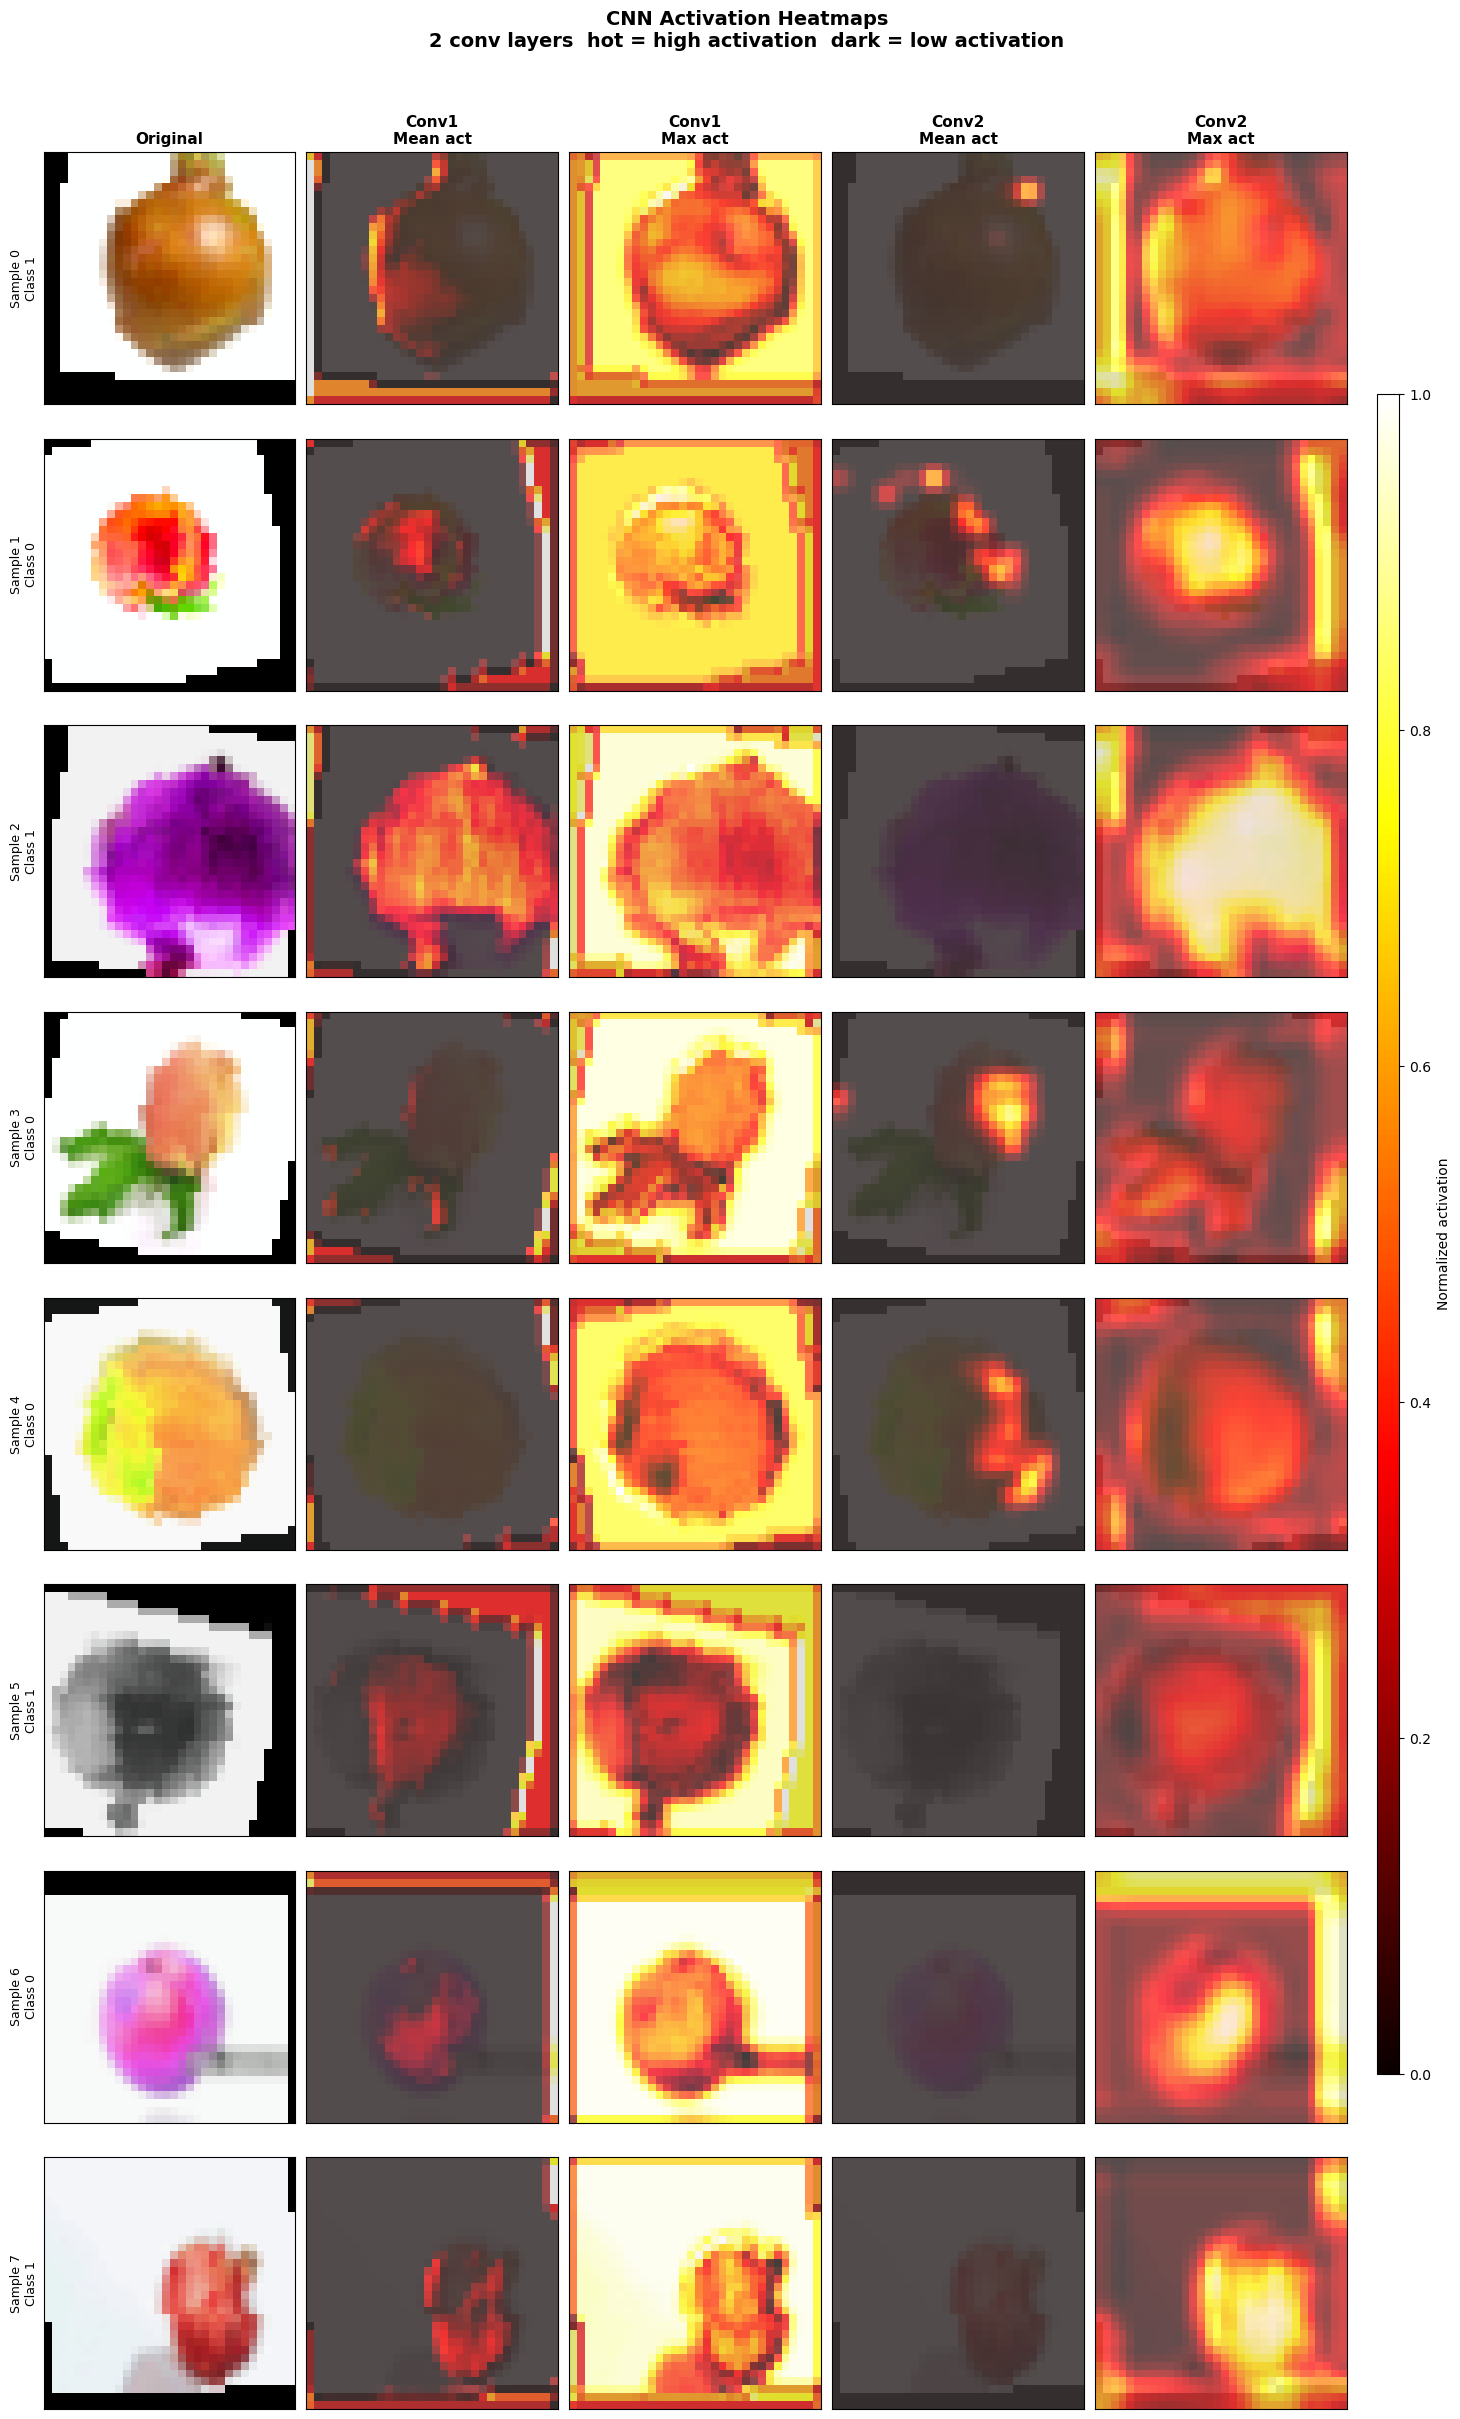

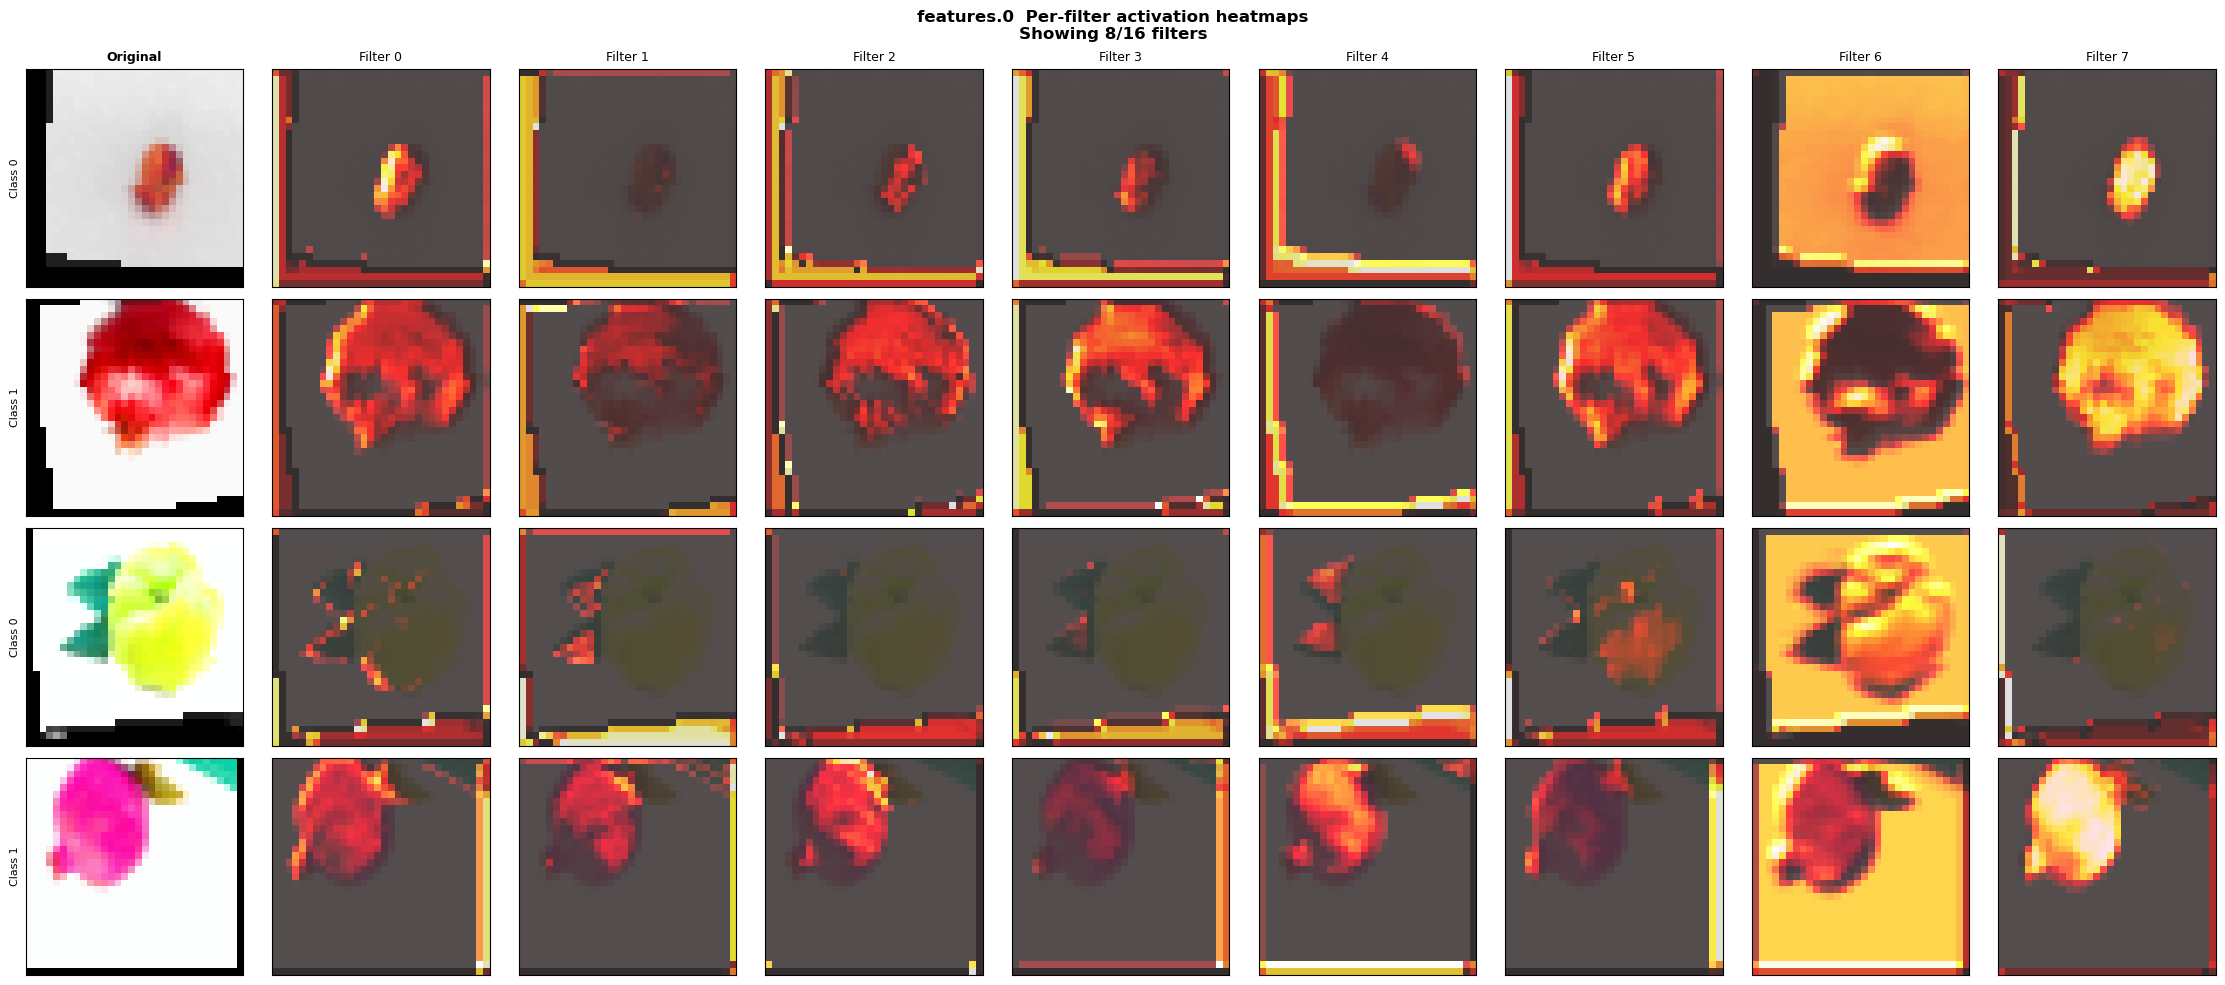

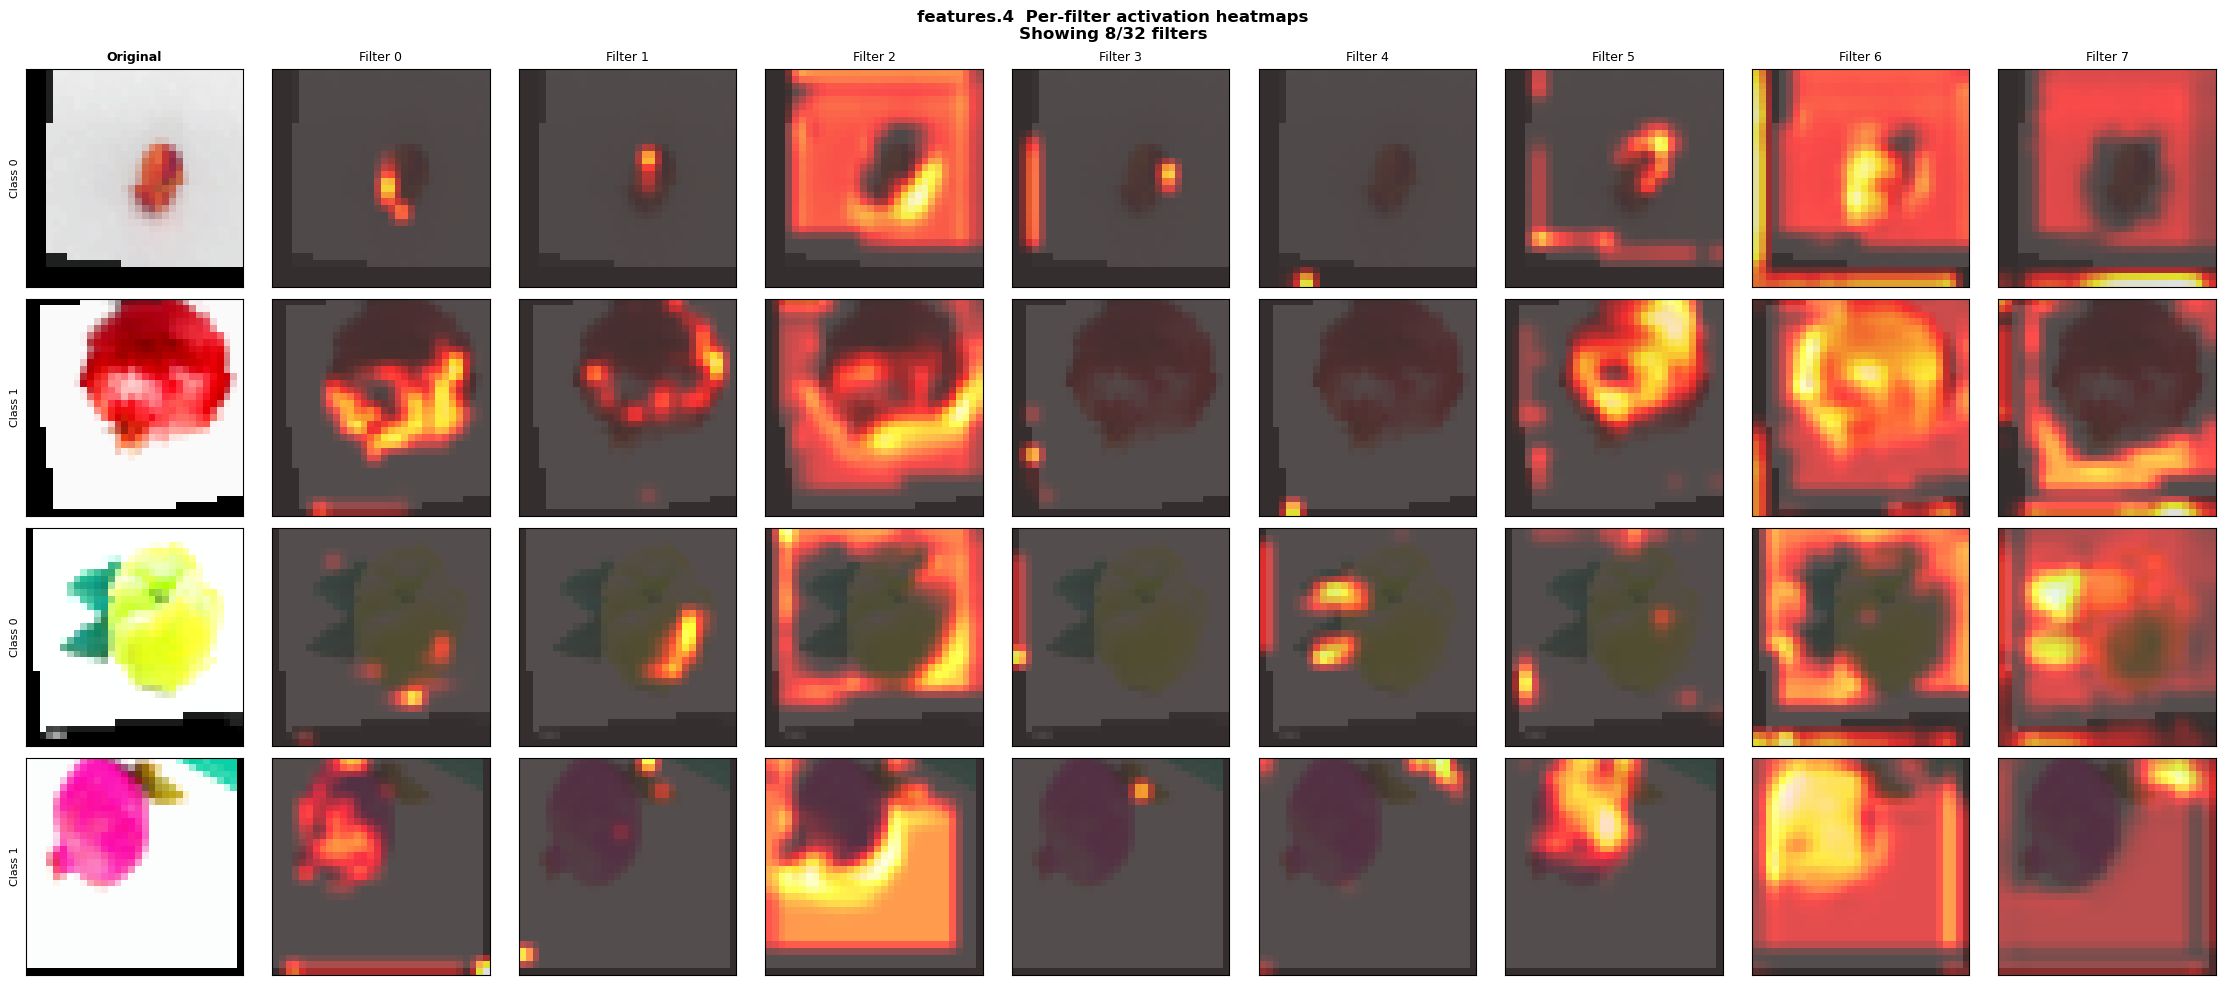

In [427]:
# Summary heatmaps: mean and max per layer
plot_cnn_feature_heatmaps(
    model        = cnn2_model,
    train_loader = twoclasstrain_loader,
    device       = 'cpu',
    n_images     = 8
)

# Per-filter heatmaps for each layer
plot_cnn_per_filter_heatmaps(
    model          = cnn2_model,
    train_loader   = twoclasstrain_loader,
    device         = 'cpu',
    n_images       = 4,
    n_filters_show = 8   # show first 8 filters
)

In [428]:
def plot_lut_feature_heatmaps(model, train_loader,
                               n_images      = 8,
                               model_type    = 'single'):
    """
    Visualize what each LUT conv layer responds to
    by showing S table output heatmaps overlaid
    on original images
    
    Works for:
        model_type='single': LUTConvV2_LinearModel
        model_type='two':    SecondLUTConvV2_LinearModel
    
    For each image shows:
        Original image
        Conv1 mean activation heatmap
        Conv1 max activation heatmap
        Conv2 mean activation heatmap  (if two layer)
        Conv2 max activation heatmap   (if two layer)
    """
    import torch
    import torch.nn.functional as F
    
    model.training = False
    
    # ---- Collect images and activations ----
    images_collected  = []
    labels_collected  = []
    conv1_acts        = []
    conv2_acts        = []
    
    count = 0
    for images, labels in train_loader:
        for img_tensor, label in zip(images, labels):
            if count >= n_images:
                break
            
            x   = preprocess_for_lut(img_tensor)
            cls = label.item()
            
            # Conv1 forward
            out1   = model.conv1.forward(x)
            # out1 shape: (out_channels1, H, W)
            # This is the S table output per spatial location
            # Each channel = one table's output
            
            conv1_acts.append(out1.copy())
            
            # Apply relu and pool to get conv2 input
            out1_r = np.maximum(0, out1)
            out1_p = model.pool1.forward(out1_r)
            
            if model_type == 'two':
                out2 = model.conv2.forward(out1_p)
                conv2_acts.append(out2.copy())
            
            images_collected.append(img_tensor)
            labels_collected.append(cls)
            count += 1
        
        if count >= n_images:
            break
    
    print(f"Collected {count} images")
    print(f"Conv1 output shape: {conv1_acts[0].shape}")
    if model_type == 'two':
        print(f"Conv2 output shape: {conv2_acts[0].shape}")
    print()
    
    # ---- Helper functions ----
    def acts_to_heatmap(acts, mode='mean'):
        """
        Convert (n_tables, H, W) LUT output
        to single (H, W) heatmap
        
        mode='mean': average S table outputs across tables
        mode='max':  max S table output across tables
        mode='std':  std of S table outputs (diversity)
        mode='pos':  mean of positive outputs only
        """
        if mode == 'mean':
            hmap = acts.mean(axis=0)
        elif mode == 'max':
            hmap = acts.max(axis=0)
        elif mode == 'std':
            hmap = acts.std(axis=0)
        elif mode == 'pos':
            pos  = np.maximum(acts, 0)
            hmap = pos.mean(axis=0)
        
        # Normalize to [0, 1]
        mn, mx = hmap.min(), hmap.max()
        if mx - mn > 1e-8:
            hmap = (hmap - mn) / (mx - mn)
        else:
            hmap = np.zeros_like(hmap)
        
        return hmap
    
    def upsample_heatmap(hmap, target_h, target_w):
        """Bilinear upsample to image size"""
        hmap_t = torch.tensor(
            hmap.astype(np.float32)
        ).unsqueeze(0).unsqueeze(0)
        up = F.interpolate(
            hmap_t,
            size          = (target_h, target_w),
            mode          = 'bilinear',
            align_corners = False
        )
        return up[0, 0].numpy()
    
    def tensor_to_img(img_tensor):
        """Convert tensor to displayable RGB image"""
        img  = img_tensor.numpy().transpose(1, 2, 0)
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img  = img * std + mean
        return np.clip(img, 0, 1)
    
    # ---- Build plot layout ----
    if model_type == 'single':
        col_labels = [
            'Original',
            'Conv1\nMean output',
            'Conv1\nMax output',
            'Conv1\nPos mean',
            'Conv1\nStd (diversity)'
        ]
        n_cols = len(col_labels)
    else:
        col_labels = [
            'Original',
            'Conv1\nMean output',
            'Conv1\nMax output',
            'Conv2\nMean output',
            'Conv2\nMax output',
            'Conv2\nPos mean',
        ]
        n_cols = len(col_labels)
    
    fig, axes = plt.subplots(
        n_images, n_cols,
        figsize = (3 * n_cols, 3 * n_images)
    )
    
    if n_images == 1:
        axes = axes[np.newaxis, :]
    
    # Column headers
    for col, title in enumerate(col_labels):
        axes[0, col].set_title(
            title, fontsize=10, fontweight='bold'
        )
    
    for row in range(n_images):
        img_np = tensor_to_img(images_collected[row])
        H, W   = img_np.shape[:2]
        label  = labels_collected[row]
        c1     = conv1_acts[row]   # (n_tables, H1, W1)
        
        # Original image
        axes[row, 0].imshow(img_np)
        axes[row, 0].set_ylabel(
            f'Sample {row}\nClass {label}',
            fontsize=9
        )
        axes[row, 0].set_xticks([])
        axes[row, 0].set_yticks([])
        
        if model_type == 'single':
            
            for col, mode in enumerate(
                ['mean', 'max', 'pos', 'std'],
                start=1
            ):
                hmap    = acts_to_heatmap(c1, mode)
                hmap_up = upsample_heatmap(hmap, H, W)
                
                ax = axes[row, col]
                ax.imshow(img_np,  alpha=0.35)
                ax.imshow(hmap_up, cmap='hot',
                           alpha=0.7, vmin=0, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
        
        else:
            c2 = conv2_acts[row]   # (n_tables2, H2, W2)
            
            configs = [
                (c1, 'mean'),
                (c1, 'max'),
                (c2, 'mean'),
                (c2, 'max'),
                (c2, 'pos'),
            ]
            
            for col, (acts, mode) in enumerate(
                configs, start=1
            ):
                hmap    = acts_to_heatmap(acts, mode)
                hmap_up = upsample_heatmap(hmap, H, W)
                
                ax = axes[row, col]
                ax.imshow(img_np,  alpha=0.35)
                ax.imshow(hmap_up, cmap='hot',
                           alpha=0.7, vmin=0, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
    
    # Colorbar
    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
    sm      = plt.cm.ScalarMappable(
        cmap = 'hot',
        norm = plt.Normalize(vmin=0, vmax=1)
    )
    plt.colorbar(sm, cax=cbar_ax,
                  label='Normalized activation')
    
    # Title info
    ch1 = model.conv1.n_tables
    nc1 = model.conv1.lut.n_comparisons
    if model_type == 'two':
        ch2 = model.conv2.n_tables
        nc2 = model.conv2.lut.n_comparisons
        info = (f'Conv1: {ch1} tables  nc={nc1}  |  '
                f'Conv2: {ch2} tables  nc={nc2}')
    else:
        info = f'Conv1: {ch1} tables  nc={nc1}'
    
    plt.suptitle(
        f'LUT Conv Activation Heatmaps\n{info}\n'
        f'hot = high S table output  '
        f'dark = low S table output',
        fontsize=13, fontweight='bold', y=1.01
    )
    plt.tight_layout(rect=[0, 0, 0.91, 1])
    plt.savefig('lut_heatmaps.png',
                dpi=150, bbox_inches='tight')
    plt.show()


def plot_lut_per_table_heatmaps(model, train_loader,
                                 n_images       = 4,
                                 n_tables_show  = 8,
                                 layer          = 'conv1'):
    """
    Show heatmap for each individual LUT table
    
    Each table produces a spatial map of S[t, j(x,y)]
    Shows which spatial regions trigger each table
    
    layer='conv1': visualize conv1 tables
    layer='conv2': visualize conv2 tables
    """
    import torch
    import torch.nn.functional as F
    
    model.training = False
    
    # Choose which layer to visualize
    if layer == 'conv1':
        conv     = model.conv1
        n_tables = model.conv1.n_tables
    else:
        conv     = model.conv2
        n_tables = model.conv2.n_tables
    
    show_t = min(n_tables_show, n_tables)
    
    images_list = []
    labels_list = []
    acts_list   = []
    
    count = 0
    for images, labels in train_loader:
        for img_tensor, label in zip(images, labels):
            if count >= n_images:
                break
            
            x = preprocess_for_lut(img_tensor)
            
            if layer == 'conv1':
                acts = model.conv1.forward(x)
            else:
                out1   = model.conv1.forward(x)
                out1   = np.maximum(0, out1)
                out1_p = model.pool1.forward(out1)
                acts   = model.conv2.forward(out1_p)
            
            acts_list.append(acts.copy())
            images_list.append(img_tensor)
            labels_list.append(label.item())
            count += 1
        
        if count >= n_images:
            break
    
    def tensor_to_img(t):
        img  = t.numpy().transpose(1, 2, 0)
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img  = img * std + mean
        return np.clip(img, 0, 1)
    
    def upsample(hmap, H, W):
        t  = torch.tensor(
            hmap.astype(np.float32)
        ).unsqueeze(0).unsqueeze(0)
        up = F.interpolate(
            t, size=(H, W),
            mode='bilinear', align_corners=False
        )
        return up[0, 0].numpy()
    
    n_cols = 1 + show_t
    fig, axes = plt.subplots(
        n_images, n_cols,
        figsize = (2.5 * n_cols, 2.5 * n_images)
    )
    
    if n_images == 1:
        axes = axes[np.newaxis, :]
    
    axes[0, 0].set_title('Original', fontsize=9,
                          fontweight='bold')
    for t in range(show_t):
        # Show anchor pair for this table
        a0 = conv.lut.anchors_a[t, 0]
        b0 = conv.lut.anchors_b[t, 0]
        axes[0, t+1].set_title(
            f'Table {t}\n'
            f'anchor[0]:\n'
            f'px{a0}>px{b0}',
            fontsize=7
        )
    
    for row in range(n_images):
        img_np = tensor_to_img(images_list[row])
        H, W   = img_np.shape[:2]
        acts   = acts_list[row]   # (n_tables, H_act, W_act)
        label  = labels_list[row]
        
        axes[row, 0].imshow(img_np)
        axes[row, 0].set_ylabel(f'Class {label}',
                                 fontsize=8)
        axes[row, 0].set_xticks([])
        axes[row, 0].set_yticks([])
        
        for t in range(show_t):
            # S table output for this table
            hmap    = acts[t]
            
            # Normalize
            mn, mx  = hmap.min(), hmap.max()
            if mx - mn > 1e-8:
                hmap = (hmap - mn) / (mx - mn)
            else:
                hmap = np.zeros_like(hmap)
            
            hmap_up = upsample(hmap, H, W)
            
            ax = axes[row, t+1]
            ax.imshow(img_np,  alpha=0.35)
            ax.imshow(hmap_up, cmap='RdBu_r',
                       alpha=0.7, vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
    
    plt.suptitle(
        f'LUT {layer} Per-Table Heatmaps\n'
        f'Showing {show_t}/{n_tables} tables  '
        f'n_comparisons={conv.lut.n_comparisons}\n'
        f'Blue=low S output  Red=high S output',
        fontsize=11, fontweight='bold'
    )
    plt.tight_layout()
    plt.savefig(f'lut_heatmaps_{layer}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

Collected 8 images
Conv1 output shape: (16, 32, 32)
Conv2 output shape: (32, 16, 16)



/var/folders/2w/rkl41cps2pq3l_gmv8rdpp7w0000gn/T/ipykernel_6153/4038862697.py:236: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.91, 1])


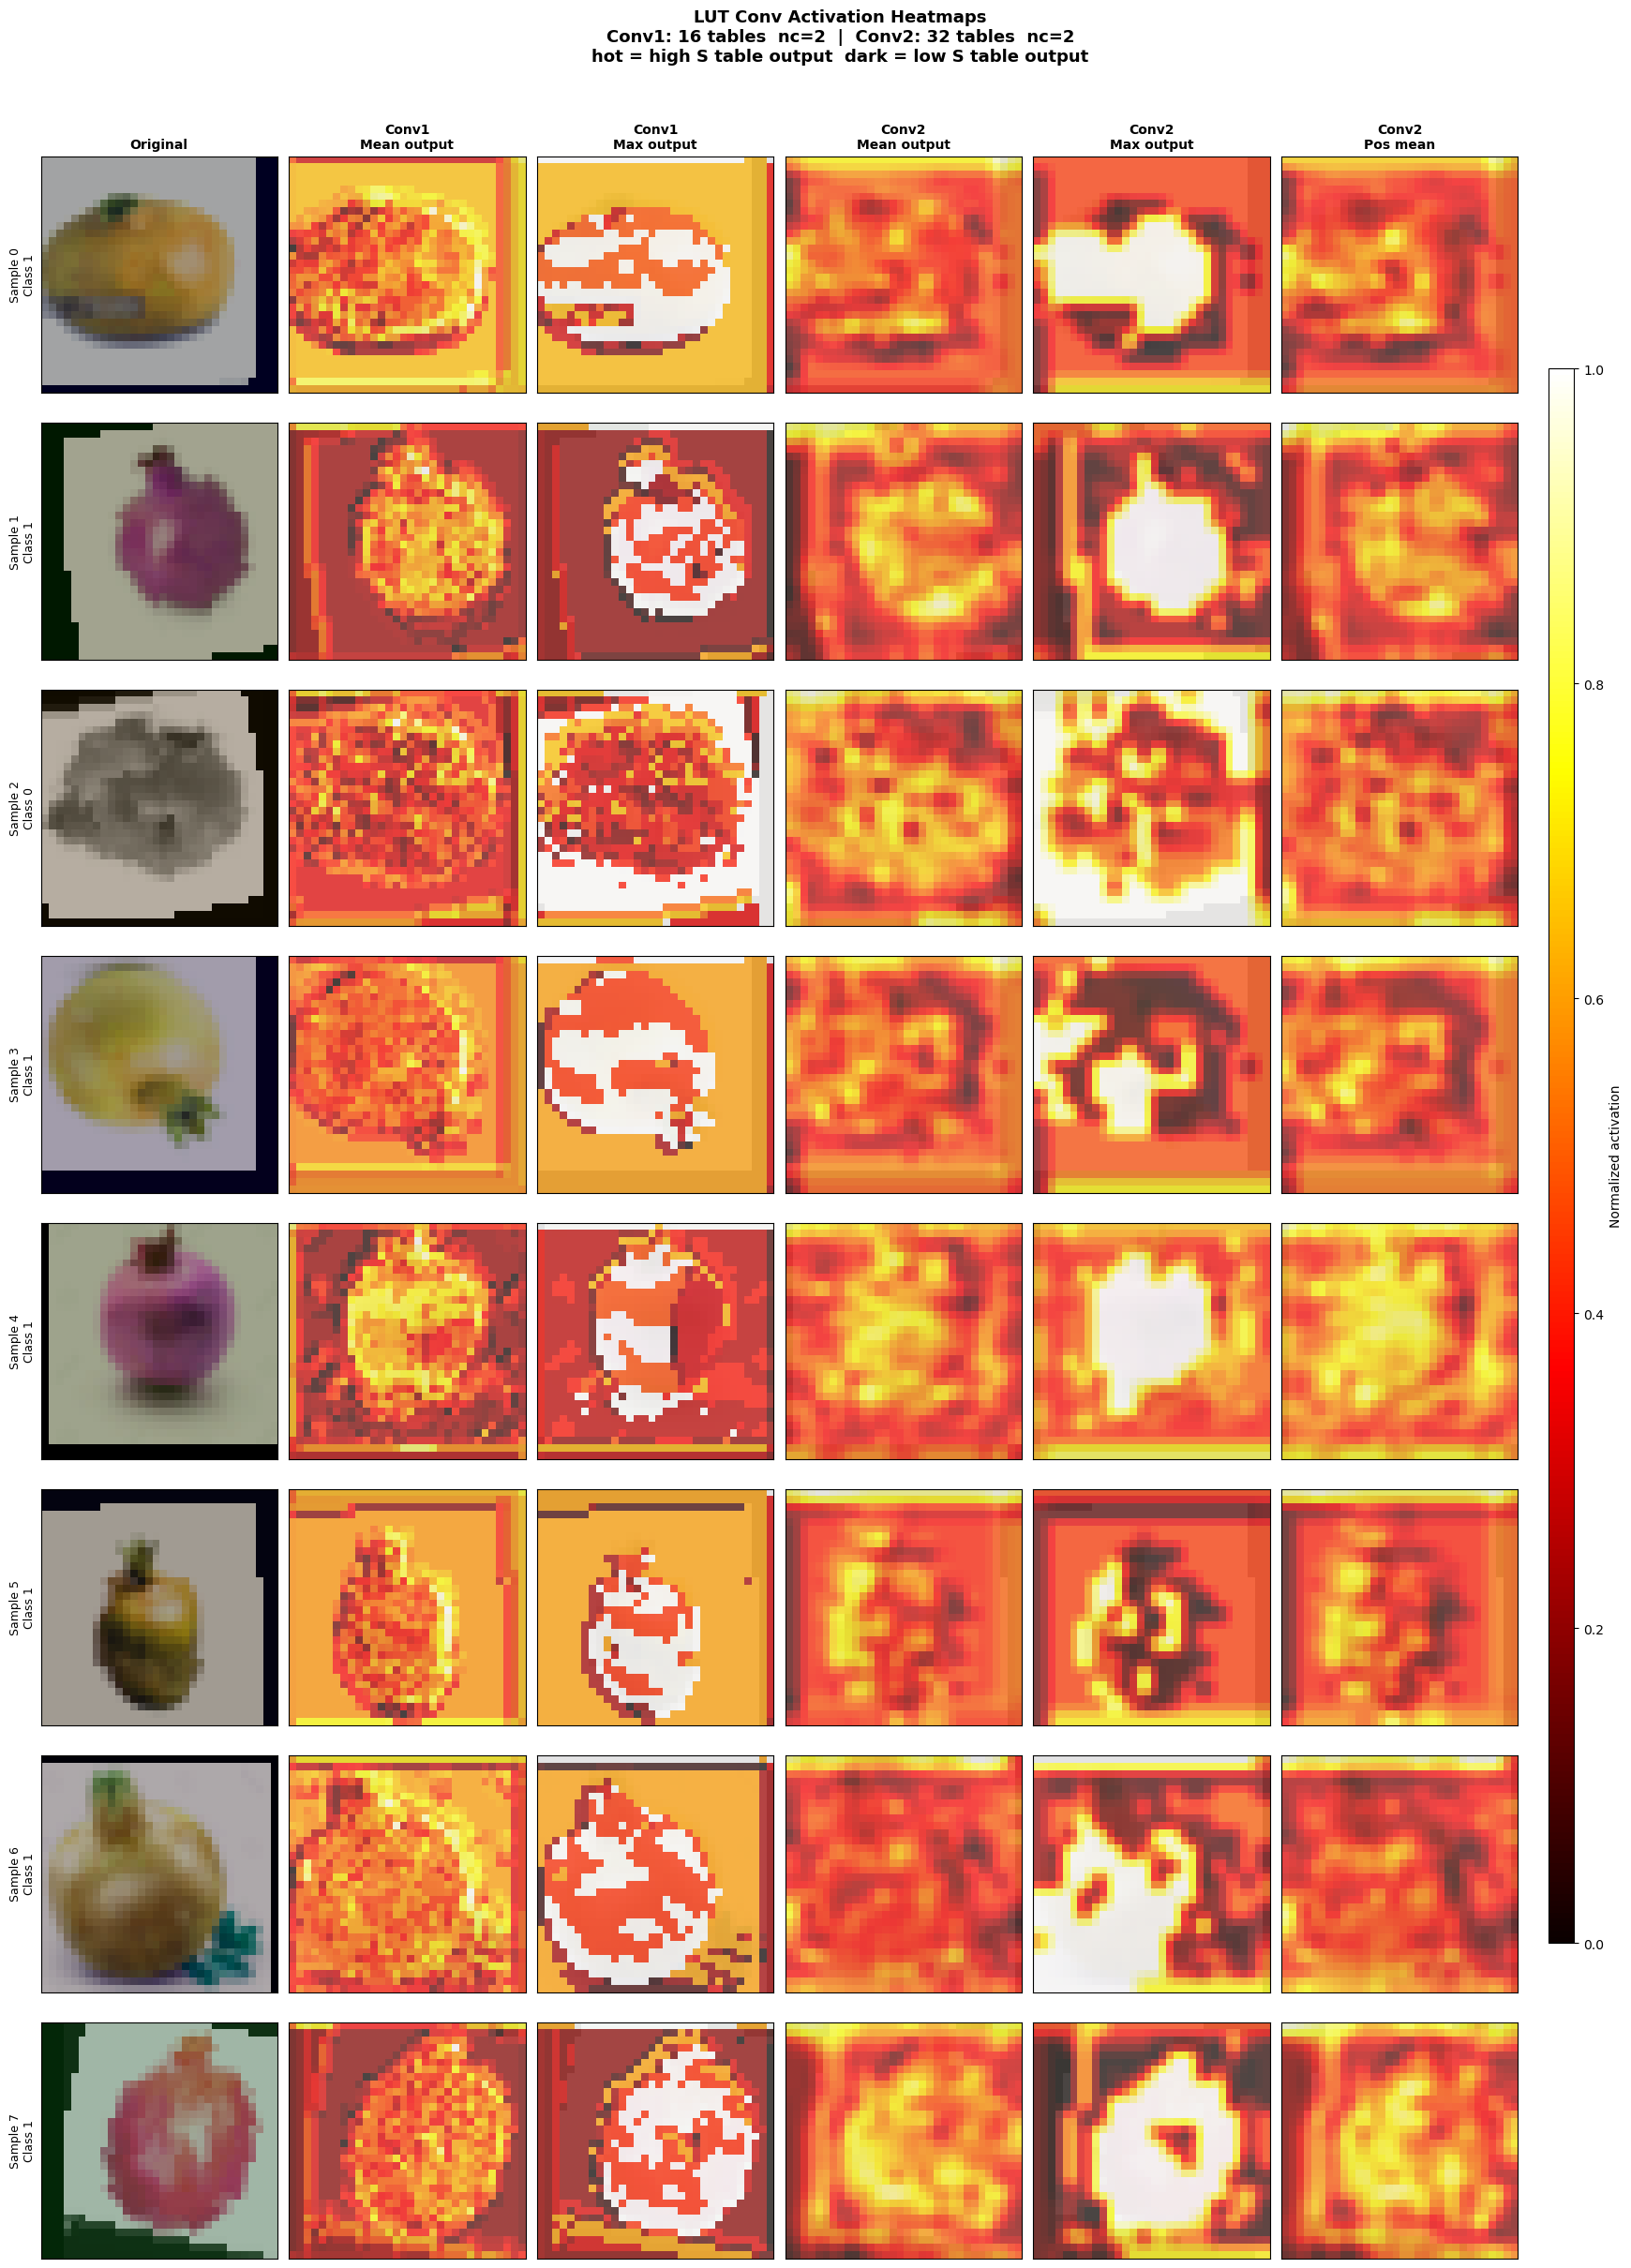

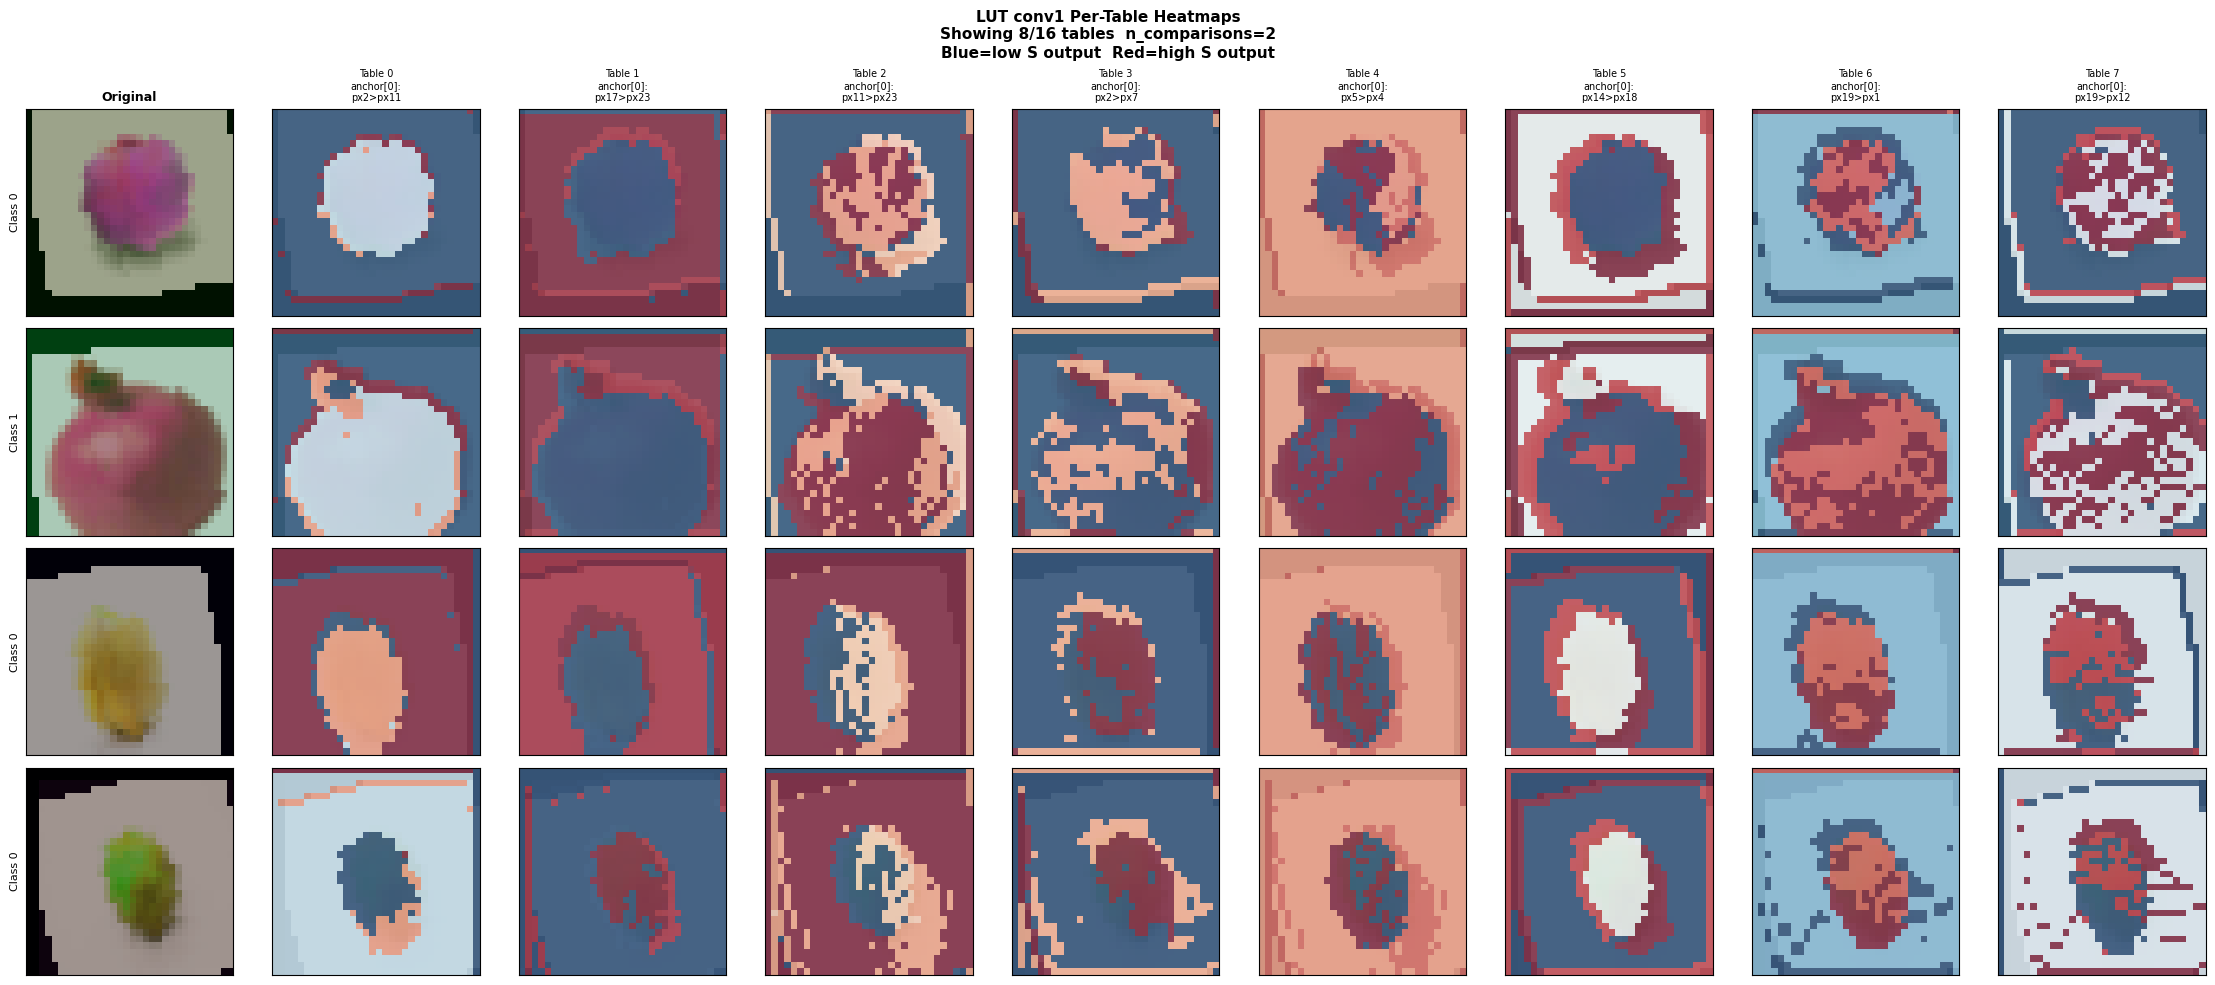

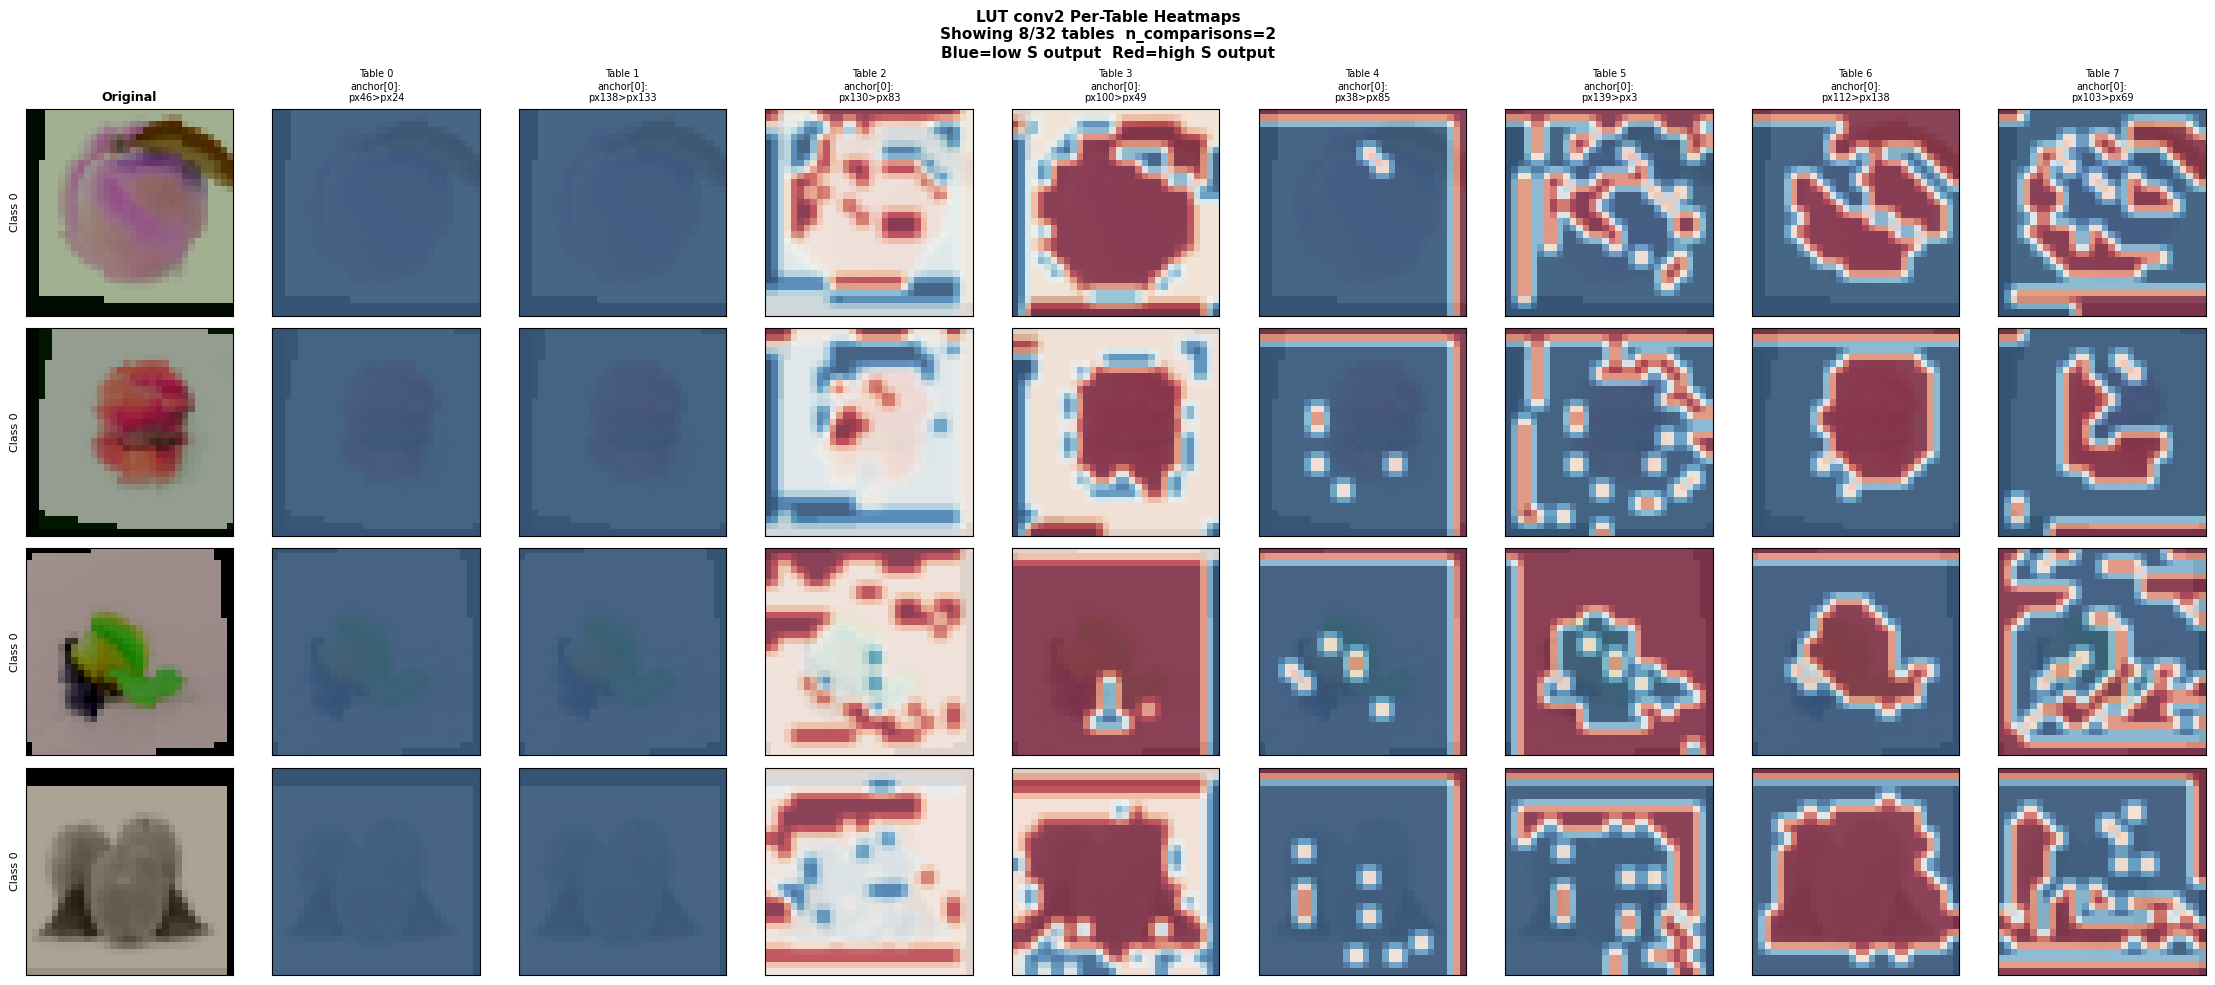

In [429]:

# Two layer model: summary heatmaps
plot_lut_feature_heatmaps(
    model        = model_2layer,
    train_loader = twoclasstrain_loader,
    n_images     = 8,
    model_type   = 'two'
)

# Per-table heatmaps for conv1
plot_lut_per_table_heatmaps(
    model          = model_2layer,
    train_loader   = twoclasstrain_loader,
    n_images       = 4,
    n_tables_show  = 8,
    layer          = 'conv1'
)

# Per-table heatmaps for conv2
plot_lut_per_table_heatmaps(
    model          = model_2layer,
    train_loader   = twoclasstrain_loader,
    n_images       = 4,
    n_tables_show  = 8,
    layer          = 'conv2'
)

In [218]:
def analyze_gradient_flow_2layer(model, train_loader):
    
    model.training = False
    
    images, labels = next(iter(train_loader))
    img_tensor     = images[0]
    label          = labels[0]
    
    x      = preprocess_for_lut(img_tensor)
    target = label.item()
    
    # Forward
    out_conv1        = model.conv1.forward(x)
    relu1_mask       = (out_conv1 > 0)
    out_relu1        = np.maximum(0, out_conv1)
    out_pool1        = model.pool1.forward(out_relu1)
    
    out_conv2        = model.conv2.forward(out_pool1)
    relu2_mask       = (out_conv2 > 0)
    out_relu2        = np.maximum(0, out_conv2)
    out_pool2        = model.pool2.forward(out_relu2)
    
    feature_shape    = out_pool2.shape
    logits           = model.classifier.forward(out_pool2.flatten())
    loss, logit_grad = cross_entropy_from_logits(logits, target)
    
    print(f"{'='*60}")
    print(f"Gradient Flow Analysis")
    print(f"{'='*60}")
    print(f"Loss:       {loss:.4f}")
    print(f"True class: {target}  Predicted: {np.argmax(logits)}")
    print(f"{'='*60}")
    
    def norm(g):
        return np.linalg.norm(g)
    
    def sparsity(g):
        return (np.abs(g) < 1e-6).mean()
    
    # Snapshot before update
    S1_before = model.conv1.lut.S.copy()
    S2_before = model.conv2.lut.S.copy()
    W_before  = model.classifier.W.copy()
    
    print(f"\n{'Step':<35} {'Norm':>10} {'Sparsity':>10}")
    print(f"{'-'*58}")
    print(f"{'logit_grad':<35} {norm(logit_grad):>10.6f} "
          f"{sparsity(logit_grad):>9.1%}")
    
    # Classifier backward
    x_flat_grad = model.classifier.backward(logit_grad, learning_rate=0.001)
    print(f"{'after classifier':<35} {norm(x_flat_grad):>10.6f} "
          f"{sparsity(x_flat_grad):>9.1%}")
    
    x_grad = x_flat_grad.reshape(feature_shape)
    
    # Pool2
    x_grad     = model.pool2.backward(x_grad)
    pool2_zero = (np.abs(x_grad) < 1e-10).mean()
    print(f"{'after pool2':<35} {norm(x_grad):>10.6f} "
          f"{sparsity(x_grad):>9.1%}  "
          f"[{pool2_zero:.0%} zeroed by pooling]")
    
    # ReLU2
    relu2_kill = (relu2_mask == 0).mean()
    x_grad     = x_grad * relu2_mask
    print(f"{'after relu2':<35} {norm(x_grad):>10.6f} "
          f"{sparsity(x_grad):>9.1%}  "
          f"[{relu2_kill:.0%} killed by relu]")
    
    # Rescale2
    n = norm(x_grad)
    if n > 1e-8:
        x_grad = x_grad * (0.1 / n)
    print(f"{'after rescale2':<35} {norm(x_grad):>10.6f} "
          f"{sparsity(x_grad):>9.1%}")
    
    # Conv2
    x_grad_before_conv2 = x_grad.copy()
    x_grad = model.conv2.backward(x_grad, learning_rate=0.001)
    conv2_ratio = norm(x_grad) / norm(x_grad_before_conv2)
    print(f"{'after conv2':<35} {norm(x_grad):>10.6f} "
          f"{sparsity(x_grad):>9.1%}  "
          f"[{conv2_ratio:.4f}x surrogate ratio]")
    
    # Pool1
    x_grad     = model.pool1.backward(x_grad)
    pool1_zero = (np.abs(x_grad) < 1e-10).mean()
    print(f"{'after pool1':<35} {norm(x_grad):>10.6f} "
          f"{sparsity(x_grad):>9.1%}  "
          f"[{pool1_zero:.0%} zeroed by pooling]")
    
    # ReLU1
    relu1_kill = (relu1_mask == 0).mean()
    x_grad     = x_grad * relu1_mask
    print(f"{'after relu1':<35} {norm(x_grad):>10.6f} "
          f"{sparsity(x_grad):>9.1%}  "
          f"[{relu1_kill:.0%} killed by relu]")
    
    # Rescale1
    n = norm(x_grad)
    if n > 1e-8:
        x_grad = x_grad * (0.1 / n)
    print(f"{'after rescale1':<35} {norm(x_grad):>10.6f} "
          f"{sparsity(x_grad):>9.1%}")
    
    # Conv1
    x_grad_before_conv1 = x_grad.copy()
    model.conv1.backward(x_grad, learning_rate=0.001)
    
    # ---- TABLE UPDATE ANALYSIS ----
    
    S1_after  = model.conv1.lut.S
    S2_after  = model.conv2.lut.S
    S1_change = np.abs(S1_after - S1_before)
    S2_change = np.abs(S2_after - S2_before)
    W_change  = np.abs(model.classifier.W - W_before)
    
    print(f"\n{'='*60}")
    print(f"Table Update Analysis")
    print(f"{'='*60}")
    
    # ✅ Fixed row counting
    def count_updated_rows(S_change, threshold=1e-10):
        """
        S_change shape: (n_tables, table_size, 1)
        Count rows where ANY change occurred
        """
        # squeeze last dim: (n_tables, table_size)
        changes    = S_change[:, :, 0]
        # row updated if change > threshold
        updated    = (changes > threshold)
        n_updated  = updated.sum()
        n_total    = changes.size
        return n_updated, n_total, updated
    
    # Conv1
    n_up1, n_tot1, updated1 = count_updated_rows(S1_change)
    print(f"\nConv1 LUT:")
    print(f"  Rows updated:   {n_up1} / {n_tot1}  "
          f"({100*n_up1/n_tot1:.1f}%)")
    print(f"  Max change:     {S1_change.max():.8f}")
    print(f"  Mean change:    {S1_change[S1_change > 0].mean():.8f}  "
          f"(nonzero only)")
    
    print(f"\n  Per channel (conv1):")
    print(f"  {'Ch':<5} {'Max Change':>12} {'Rows Updated':>14} {'%':>6}")
    for ch in range(model.out_channels1):
        ch_change    = S1_change[ch, :, 0]
        max_ch       = ch_change.max()
        rows_updated = (ch_change > 1e-10).sum()
        table_size   = S1_change.shape[1]
        pct          = 100 * rows_updated / table_size
        bar          = '█' * min(int(max_ch * 100000), 20)
        print(f"  {ch:<5} {max_ch:>12.8f} {rows_updated:>14} "
              f"{pct:>5.1f}%  {bar}")
    
    # Conv2
    n_up2, n_tot2, updated2 = count_updated_rows(S2_change)
    print(f"\nConv2 LUT:")
    print(f"  Rows updated:   {n_up2} / {n_tot2}  "
          f"({100*n_up2/n_tot2:.1f}%)")
    print(f"  Max change:     {S2_change.max():.8f}")
    print(f"  Mean change:    {S2_change[S2_change > 0].mean():.8f}  "
          f"(nonzero only)")
    
    print(f"\n  Per channel (conv2):")
    print(f"  {'Ch':<5} {'Max Change':>12} {'Rows Updated':>14} {'%':>6}")
    for ch in range(model.out_channels2):
        ch_change    = S2_change[ch, :, 0]
        max_ch       = ch_change.max()
        rows_updated = (ch_change > 1e-10).sum()
        table_size   = S2_change.shape[1]
        pct          = 100 * rows_updated / table_size
        bar          = '█' * min(int(max_ch * 100000), 20)
        print(f"  {ch:<5} {max_ch:>12.8f} {rows_updated:>14} "
              f"{pct:>5.1f}%  {bar}")
    
    # Classifier
    print(f"\nLinear Classifier W:")
    print(f"  Max change:  {W_change.max():.8f}")
    print(f"  Mean change: {W_change.mean():.8f}")
    
    # ---- HEALTH CHECKS ----
    
    print(f"\n{'='*60}")
    print(f"Health Checks")
    print(f"{'='*60}")
    
    print(f"\nSurrogate gradient ratio:")
    print(f"  Through conv2: {conv2_ratio:.6f}x")
    print(f"  (1.0 = perfect, <0.01 = very weak surrogate)")
    
    print(f"\nReLU dead neurons:")
    print(f"  relu1: {relu1_kill:.1%}  ", end="")
    print("⚠️  >50% dead" if relu1_kill > 0.5 else "✅")
    print(f"  relu2: {relu2_kill:.1%}  ", end="")
    print("⚠️  >50% dead" if relu2_kill > 0.5 else "✅")
    
    print(f"\nRow coverage per channel:")
    avg_coverage1 = (updated1.sum(axis=1) / S1_change.shape[1]).mean()
    avg_coverage2 = (updated2.sum(axis=1) / S2_change.shape[1]).mean()
    print(f"  conv1 avg: {avg_coverage1:.1%}  ", end="")
    print("⚠️  <10%" if avg_coverage1 < 0.1 else "✅")
    print(f"  conv2 avg: {avg_coverage2:.1%}  ", end="")
    print("⚠️  <10%" if avg_coverage2 < 0.1 else "✅")
    
    print(f"\nTable update sizes:")
    print(f"  conv1 max: {S1_change.max():.2e}  ", end="")
    if S1_change.max() < 1e-7:
        print("❌ too small")
    elif S1_change.max() > 0.1:
        print("⚠️  too large")
    else:
        print("✅")
    
    print(f"  conv2 max: {S2_change.max():.2e}  ", end="")
    if S2_change.max() < 1e-7:
        print("❌ too small")
    elif S2_change.max() > 0.1:
        print("⚠️  too large")
    else:
        print("✅")
    
    print(f"  W max:     {W_change.max():.2e}  ", end="")
    if W_change.max() < 1e-7:
        print("❌ too small")
    elif W_change.max() > 0.1:
        print("⚠️  too large")
    else:
        print("✅")
    
    return {
        'loss':              loss,
        'S1_max_change':     S1_change.max(),
        'S2_max_change':     S2_change.max(),
        'W_max_change':      W_change.max(),
        'relu1_dead':        relu1_kill,
        'relu2_dead':        relu2_kill,
        'conv2_surr_ratio':  conv2_ratio,
        'conv1_row_coverage':avg_coverage1,
        'conv2_row_coverage':avg_coverage2,
    }

In [438]:
model = SecondLUTConvV2_LinearModel(
    num_classes   = 2,
    out_channels1  = 16,
    out_channels2  = 32,
    n_comparisons1 = 2,
    n_comparisons2 = 2,
    seed          = 42
)
results = analyze_gradient_flow_2layer(model, twoclasstrain_loader)


Gradient Flow Analysis
Loss:       0.4630
True class: 0  Predicted: 0

Step                                      Norm   Sparsity
----------------------------------------------------------
logit_grad                            0.524120      0.0%
after classifier                      0.734935      0.0%
after pool2                           0.734935     75.0%  [75% zeroed by pooling]
after relu2                           0.584330     83.5%  [46% killed by relu]
after rescale2                        0.100000     83.5%
after conv2                           0.078198     56.6%  [0.7820x surrogate ratio]
after pool1                           0.078198     89.2%  [89% zeroed by pooling]
after relu1                           0.061987     94.5%  [44% killed by relu]
after rescale1                        0.100000     94.5%

Table Update Analysis

Conv1 LUT:
  Rows updated:   27 / 64  (42.2%)
  Max change:     0.00007744
  Mean change:    0.00001401  (nonzero only)

  Per channel (conv1):
  Ch      

In [334]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import copy

def optimize_all_parameters(
    train_loader,
    num_classes,
    
    # Sweep these
    learning_rate_range  = [0.0001, 0.001, 0.01, 0.1],
    s_init_scale_range   = [0.1, 0.5, 1.0, 2.0, 5.0],
    out_channels1_range  = [8, 16, 32],
    n_comparisons1_range = [2, 3, 4, 5, 6],
    
    # Fixed
    out_channels2  = 16,
    n_comparisons2 = 4,
    n_trials       = 5
):
    """
    Sweep the parameters not yet covered
    """
    def rescale(g, tgt=0.1, eps=1e-8):
        n = np.linalg.norm(g)
        return g * (tgt / n) if n > eps else g
    
    def run_config(lr, s_init, ch1, nc1, seed):
        
        model = SecondLUTConvV2_LinearModel(
            num_classes    = num_classes,
            out_channels1  = ch1,
            out_channels2  = out_channels2,
            n_comparisons1 = nc1,
            n_comparisons2 = n_comparisons2,
            seed           = seed
        )
        
        # Set S initialization scale
        for conv in [model.conv1, model.conv2]:
            table_size = 1 << conv.lut.n_comparisons
            conv.lut.S = np.random.default_rng(seed).normal(
                0, s_init,
                size=(conv.n_tables, table_size, 1)
            )
        
        model.training = False
        
        # Collect samples
        class_samples = {0: [], 1: []}
        for images, labels in train_loader:
            for img, label in zip(images, labels):
                t = label.item()
                if len(class_samples[t]) < 5:
                    class_samples[t].append(
                        preprocess_for_lut(img)
                    )
            if all(len(v) >= 5
                   for v in class_samples.values()):
                break
        
        all_samples = class_samples[0] + class_samples[1]
        all_targets = [0]*5 + [1]*5
        
        grad_c2_list = []
        grad_c1_list = []
        s2_list      = []
        s1_list      = []
        
        for x, target in zip(all_samples, all_targets):
            
            S1_before = model.conv1.lut.S.copy()
            S2_before = model.conv2.lut.S.copy()
            
            out1       = model.conv1.forward(x)
            relu1_mask = (out1 > 0)
            out1       = np.maximum(0, out1)
            out1_p     = model.pool1.forward(out1)
            out2       = model.conv2.forward(out1_p)
            relu2_mask = (out2 > 0)
            out2       = np.maximum(0, out2)
            out2_p     = model.pool2.forward(out2)
            feat_shape = out2_p.shape
            logits     = model.classifier.forward(out2_p.flatten())
            loss, grad = cross_entropy_from_logits(logits, target)
            
            # Gradient flow
            xg = model.classifier.backward(grad, learning_rate=0.0)
            xg = xg.reshape(feat_shape)
            xg = model.pool2.backward(xg)
            xg = xg * relu2_mask
            xg = rescale(xg)
            xg = model.conv2.backward(xg, 0.0)
            grad_c2_list.append(np.linalg.norm(xg))
            xg = model.pool1.backward(xg)
            xg = xg * relu1_mask
            xg = rescale(xg)
            xg = model.conv1.backward(xg, 0.0)
            grad_c1_list.append(np.linalg.norm(xg))
            
            # S change with real lr
            xg = model.classifier.backward(grad, lr)
            xg = xg.reshape(feat_shape)
            xg = model.pool2.backward(xg)
            xg = xg * relu2_mask
            xg = rescale(xg)
            xg = model.conv2.backward(xg, lr)
            xg = model.pool1.backward(xg)
            xg = xg * relu1_mask
            xg = rescale(xg)
            model.conv1.backward(xg, lr)
            
            s2_list.append(
                np.abs(model.conv2.lut.S - S2_before).max()
            )
            s1_list.append(
                np.abs(model.conv1.lut.S - S1_before).max()
            )
        
        # FDR
        c0_feats = []
        c1_feats = []
        for x in class_samples[0]:
            out1   = model.conv1.forward(x)
            out1   = np.maximum(0, out1)
            out1_p = model.pool1.forward(out1)
            out2   = model.conv2.forward(out1_p)
            out2   = np.maximum(0, out2)
            out2_p = model.pool2.forward(out2)
            c0_feats.append(out2_p.flatten())
        for x in class_samples[1]:
            out1   = model.conv1.forward(x)
            out1   = np.maximum(0, out1)
            out1_p = model.pool1.forward(out1)
            out2   = model.conv2.forward(out1_p)
            out2   = np.maximum(0, out2)
            out2_p = model.pool2.forward(out2)
            c1_feats.append(out2_p.flatten())
        
        c0  = np.array(c0_feats)
        c1  = np.array(c1_feats)
        m0  = c0.mean(0)
        m1  = c1.mean(0)
        v0  = c0.var(0)
        v1  = c1.var(0)
        within  = (v0 + v1) / 2
        between = (m0 - m1)**2
        valid   = within > 1e-4
        fdr     = float(min(
            (between[valid]/within[valid]).mean()
            if valid.sum() > 0 else 0, 100.0
        ))
        
        return {
            'grad_c2': float(np.mean(grad_c2_list)),
            'grad_c1': float(np.mean(grad_c1_list)),
            's2_max':  float(np.mean(s2_list)),
            's1_max':  float(np.mean(s1_list)),
            'fdr':     fdr,
        }
    
    results_lr     = []
    results_sinit  = []
    results_ch1    = []
    results_nc1    = []
    
    # ---- Sweep learning rate ----
    print("Sweeping learning rate...")
    for lr in learning_rate_range:
        trials = []
        for seed in range(n_trials):
            m = run_config(lr, 0.5, 16, 4, seed*17+42)
            trials.append(m)
        results_lr.append({
            'lr':      lr,
            'grad_c2': np.mean([t['grad_c2'] for t in trials]),
            'grad_c1': np.mean([t['grad_c1'] for t in trials]),
            's2_max':  np.mean([t['s2_max']  for t in trials]),
            's1_max':  np.mean([t['s1_max']  for t in trials]),
            'fdr':     np.mean([t['fdr']     for t in trials]),
            'grad_c2_std': np.std([t['grad_c2'] for t in trials]),
            'grad_c1_std': np.std([t['grad_c1'] for t in trials]),
            's1_max_std':  np.std([t['s1_max']  for t in trials]),
            'fdr_std':     np.std([t['fdr']     for t in trials]),
        })
        print(f"  lr={lr:.4f}  "
              f"s1_max={results_lr[-1]['s1_max']:.2e}  "
              f"fdr={results_lr[-1]['fdr']:.3f}")
    
    # ---- Sweep S init scale ----
    print("\nSweeping S init scale...")
    for s_init in s_init_scale_range:
        trials = []
        for seed in range(n_trials):
            m = run_config(0.001, s_init, 16, 4, seed*17+42)
            trials.append(m)
        results_sinit.append({
            's_init':  s_init,
            'grad_c2': np.mean([t['grad_c2'] for t in trials]),
            'grad_c1': np.mean([t['grad_c1'] for t in trials]),
            's2_max':  np.mean([t['s2_max']  for t in trials]),
            's1_max':  np.mean([t['s1_max']  for t in trials]),
            'fdr':     np.mean([t['fdr']     for t in trials]),
            'grad_c2_std': np.std([t['grad_c2'] for t in trials]),
            'grad_c1_std': np.std([t['grad_c1'] for t in trials]),
            's1_max_std':  np.std([t['s1_max']  for t in trials]),
            'fdr_std':     np.std([t['fdr']     for t in trials]),
        })
        print(f"  s_init={s_init:.1f}  "
              f"s1_max={results_sinit[-1]['s1_max']:.2e}  "
              f"fdr={results_sinit[-1]['fdr']:.3f}")
    
    # ---- Sweep out_channels1 ----
    print("\nSweeping out_channels1...")
    for ch1 in out_channels1_range:
        trials = []
        for seed in range(n_trials):
            m = run_config(0.001, 0.5, ch1, 4, seed*17+42)
            trials.append(m)
        results_ch1.append({
            'ch1':     ch1,
            'grad_c2': np.mean([t['grad_c2'] for t in trials]),
            'grad_c1': np.mean([t['grad_c1'] for t in trials]),
            's2_max':  np.mean([t['s2_max']  for t in trials]),
            's1_max':  np.mean([t['s1_max']  for t in trials]),
            'fdr':     np.mean([t['fdr']     for t in trials]),
            'grad_c2_std': np.std([t['grad_c2'] for t in trials]),
            'grad_c1_std': np.std([t['grad_c1'] for t in trials]),
            's1_max_std':  np.std([t['s1_max']  for t in trials]),
            'fdr_std':     np.std([t['fdr']     for t in trials]),
        })
        print(f"  ch1={ch1}  "
              f"s1_max={results_ch1[-1]['s1_max']:.2e}  "
              f"fdr={results_ch1[-1]['fdr']:.3f}")
    
    # ---- Sweep n_comparisons1 ----
    print("\nSweeping n_comparisons1...")
    for nc1 in n_comparisons1_range:
        trials = []
        for seed in range(n_trials):
            m = run_config(0.001, 0.5, 16, nc1, seed*17+42)
            trials.append(m)
        results_nc1.append({
            'nc1':     nc1,
            'grad_c2': np.mean([t['grad_c2'] for t in trials]),
            'grad_c1': np.mean([t['grad_c1'] for t in trials]),
            's2_max':  np.mean([t['s2_max']  for t in trials]),
            's1_max':  np.mean([t['s1_max']  for t in trials]),
            'fdr':     np.mean([t['fdr']     for t in trials]),
            'grad_c2_std': np.std([t['grad_c2'] for t in trials]),
            'grad_c1_std': np.std([t['grad_c1'] for t in trials]),
            's1_max_std':  np.std([t['s1_max']  for t in trials]),
            'fdr_std':     np.std([t['fdr']     for t in trials]),
        })
        print(f"  nc1={nc1}  "
              f"s1_max={results_nc1[-1]['s1_max']:.2e}  "
              f"fdr={results_nc1[-1]['fdr']:.3f}")
    
    plot_missing_parameters(
        results_lr, results_sinit,
        results_ch1, results_nc1
    )
    
    return results_lr, results_sinit, results_ch1, results_nc1


def plot_missing_parameters(results_lr, results_sinit,
                             results_ch1, results_nc1):
    
    fig = plt.figure(figsize=(20, 24))
    gs  = gridspec.GridSpec(4, 2, figure=fig,
                             hspace=0.5, wspace=0.35)
    
    def plot_two_metrics(ax, xs, results,
                          x_key, x_label,
                          m1_key, m1_label, m1_color,
                          m2_key, m2_label, m2_color,
                          title, log_x=False):
        
        x_vals = [r[x_key] for r in results]
        m1     = np.array([r[m1_key] for r in results])
        m1_std = np.array([r.get(m1_key+'_std', 0)
                            for r in results])
        m2     = np.array([r[m2_key] for r in results])
        m2_std = np.array([r.get(m2_key+'_std', 0)
                            for r in results])
        
        ax.plot(x_vals, m1, color=m1_color,
                marker='o', linewidth=2, markersize=8,
                label=m1_label)
        ax.fill_between(x_vals, m1-m1_std, m1+m1_std,
                         alpha=0.2, color=m1_color)
        ax.set_xlabel(x_label)
        ax.set_ylabel(m1_label, color=m1_color)
        ax.tick_params(axis='y', labelcolor=m1_color)
        
        ax2 = ax.twinx()
        ax2.plot(x_vals, m2, color=m2_color,
                 marker='s', linewidth=2, markersize=8,
                 linestyle='--', label=m2_label)
        ax2.fill_between(x_vals, m2-m2_std, m2+m2_std,
                          alpha=0.2, color=m2_color)
        ax2.set_ylabel(m2_label, color=m2_color)
        ax2.tick_params(axis='y', labelcolor=m2_color)
        
        ax.set_title(title, fontsize=12)
        ax.grid(True, alpha=0.3)
        if log_x:
            ax.set_xscale('log')
        
        lines1, l1 = ax.get_legend_handles_labels()
        lines2, l2 = ax2.get_legend_handles_labels()
        ax.legend(lines1+lines2, l1+l2, fontsize=9)
    
    # Row 1: Learning rate
    plot_two_metrics(
        fig.add_subplot(gs[0, 0]),
        [r['lr'] for r in results_lr], results_lr,
        'lr', 'Learning Rate',
        's1_max', 'S1 Max Change', '#2196F3',
        'fdr',    'FDR',           '#FF5722',
        'S1 Max Change and FDR vs Learning Rate',
        log_x=True
    )
    
    plot_two_metrics(
        fig.add_subplot(gs[0, 1]),
        [r['lr'] for r in results_lr], results_lr,
        'lr', 'Learning Rate',
        'grad_c1', 'Grad after Conv1', '#4CAF50',
        'grad_c2', 'Grad after Conv2', '#9C27B0',
        'Gradient Flow vs Learning Rate',
        log_x=True
    )
    
    # Row 2: S init scale
    plot_two_metrics(
        fig.add_subplot(gs[1, 0]),
        [r['s_init'] for r in results_sinit], results_sinit,
        's_init', 'S Init Scale (std)',
        's1_max', 'S1 Max Change', '#2196F3',
        'fdr',    'FDR',           '#FF5722',
        'S1 Max Change and FDR vs S Init Scale'
    )
    
    plot_two_metrics(
        fig.add_subplot(gs[1, 1]),
        [r['s_init'] for r in results_sinit], results_sinit,
        's_init', 'S Init Scale (std)',
        'grad_c1', 'Grad after Conv1', '#4CAF50',
        'grad_c2', 'Grad after Conv2', '#9C27B0',
        'Gradient Flow vs S Init Scale'
    )
    
    # Row 3: out_channels1
    plot_two_metrics(
        fig.add_subplot(gs[2, 0]),
        [r['ch1'] for r in results_ch1], results_ch1,
        'ch1', 'out_channels1 (conv1 out)',
        's1_max', 'S1 Max Change', '#2196F3',
        'fdr',    'FDR',           '#FF5722',
        'S1 Max Change and FDR vs out_channels1'
    )
    
    plot_two_metrics(
        fig.add_subplot(gs[2, 1]),
        [r['ch1'] for r in results_ch1], results_ch1,
        'ch1', 'out_channels1 (conv1 out)',
        'grad_c1', 'Grad after Conv1', '#4CAF50',
        'grad_c2', 'Grad after Conv2', '#9C27B0',
        'Gradient Flow vs out_channels1'
    )
    
    # Row 4: n_comparisons1
    plot_two_metrics(
        fig.add_subplot(gs[3, 0]),
        [r['nc1'] for r in results_nc1], results_nc1,
        'nc1', 'n_comparisons1 (conv1)',
        's1_max', 'S1 Max Change', '#2196F3',
        'fdr',    'FDR',           '#FF5722',
        'S1 Max Change and FDR vs n_comparisons1'
    )
    
    plot_two_metrics(
        fig.add_subplot(gs[3, 1]),
        [r['nc1'] for r in results_nc1], results_nc1,
        'nc1', 'n_comparisons1 (conv1)',
        'grad_c1', 'Grad after Conv1', '#4CAF50',
        'grad_c2', 'Grad after Conv2', '#9C27B0',
        'Gradient Flow vs n_comparisons1'
    )
    
    plt.suptitle(
        'Missing Parameter Analysis\n'
        'Learning Rate, S Init, Conv1 Architecture',
        fontsize=14, y=1.01
    )
    plt.savefig('missing_parameters.png',
                dpi=150, bbox_inches='tight')
    plt.show()

Sweeping learning rate...
  lr=0.0001  s1_max=4.10e-06  fdr=0.771
  lr=0.0010  s1_max=4.28e-05  fdr=0.658
  lr=0.0100  s1_max=4.42e-04  fdr=1.054
  lr=0.1000  s1_max=3.93e-03  fdr=0.679

Sweeping S init scale...
  s_init=0.1  s1_max=3.96e-05  fdr=0.733
  s_init=0.5  s1_max=4.44e-05  fdr=0.833
  s_init=1.0  s1_max=4.18e-05  fdr=0.674
  s_init=2.0  s1_max=4.27e-05  fdr=0.679
  s_init=5.0  s1_max=2.49e-05  fdr=1.722

Sweeping out_channels1...
  ch1=8  s1_max=4.31e-05  fdr=1.005
  ch1=16  s1_max=4.24e-05  fdr=0.718
  ch1=32  s1_max=3.86e-05  fdr=0.755

Sweeping n_comparisons1...
  nc1=2  s1_max=4.98e-05  fdr=0.709
  nc1=3  s1_max=4.39e-05  fdr=0.661
  nc1=4  s1_max=4.21e-05  fdr=0.765
  nc1=5  s1_max=3.73e-05  fdr=0.715
  nc1=6  s1_max=3.73e-05  fdr=0.704


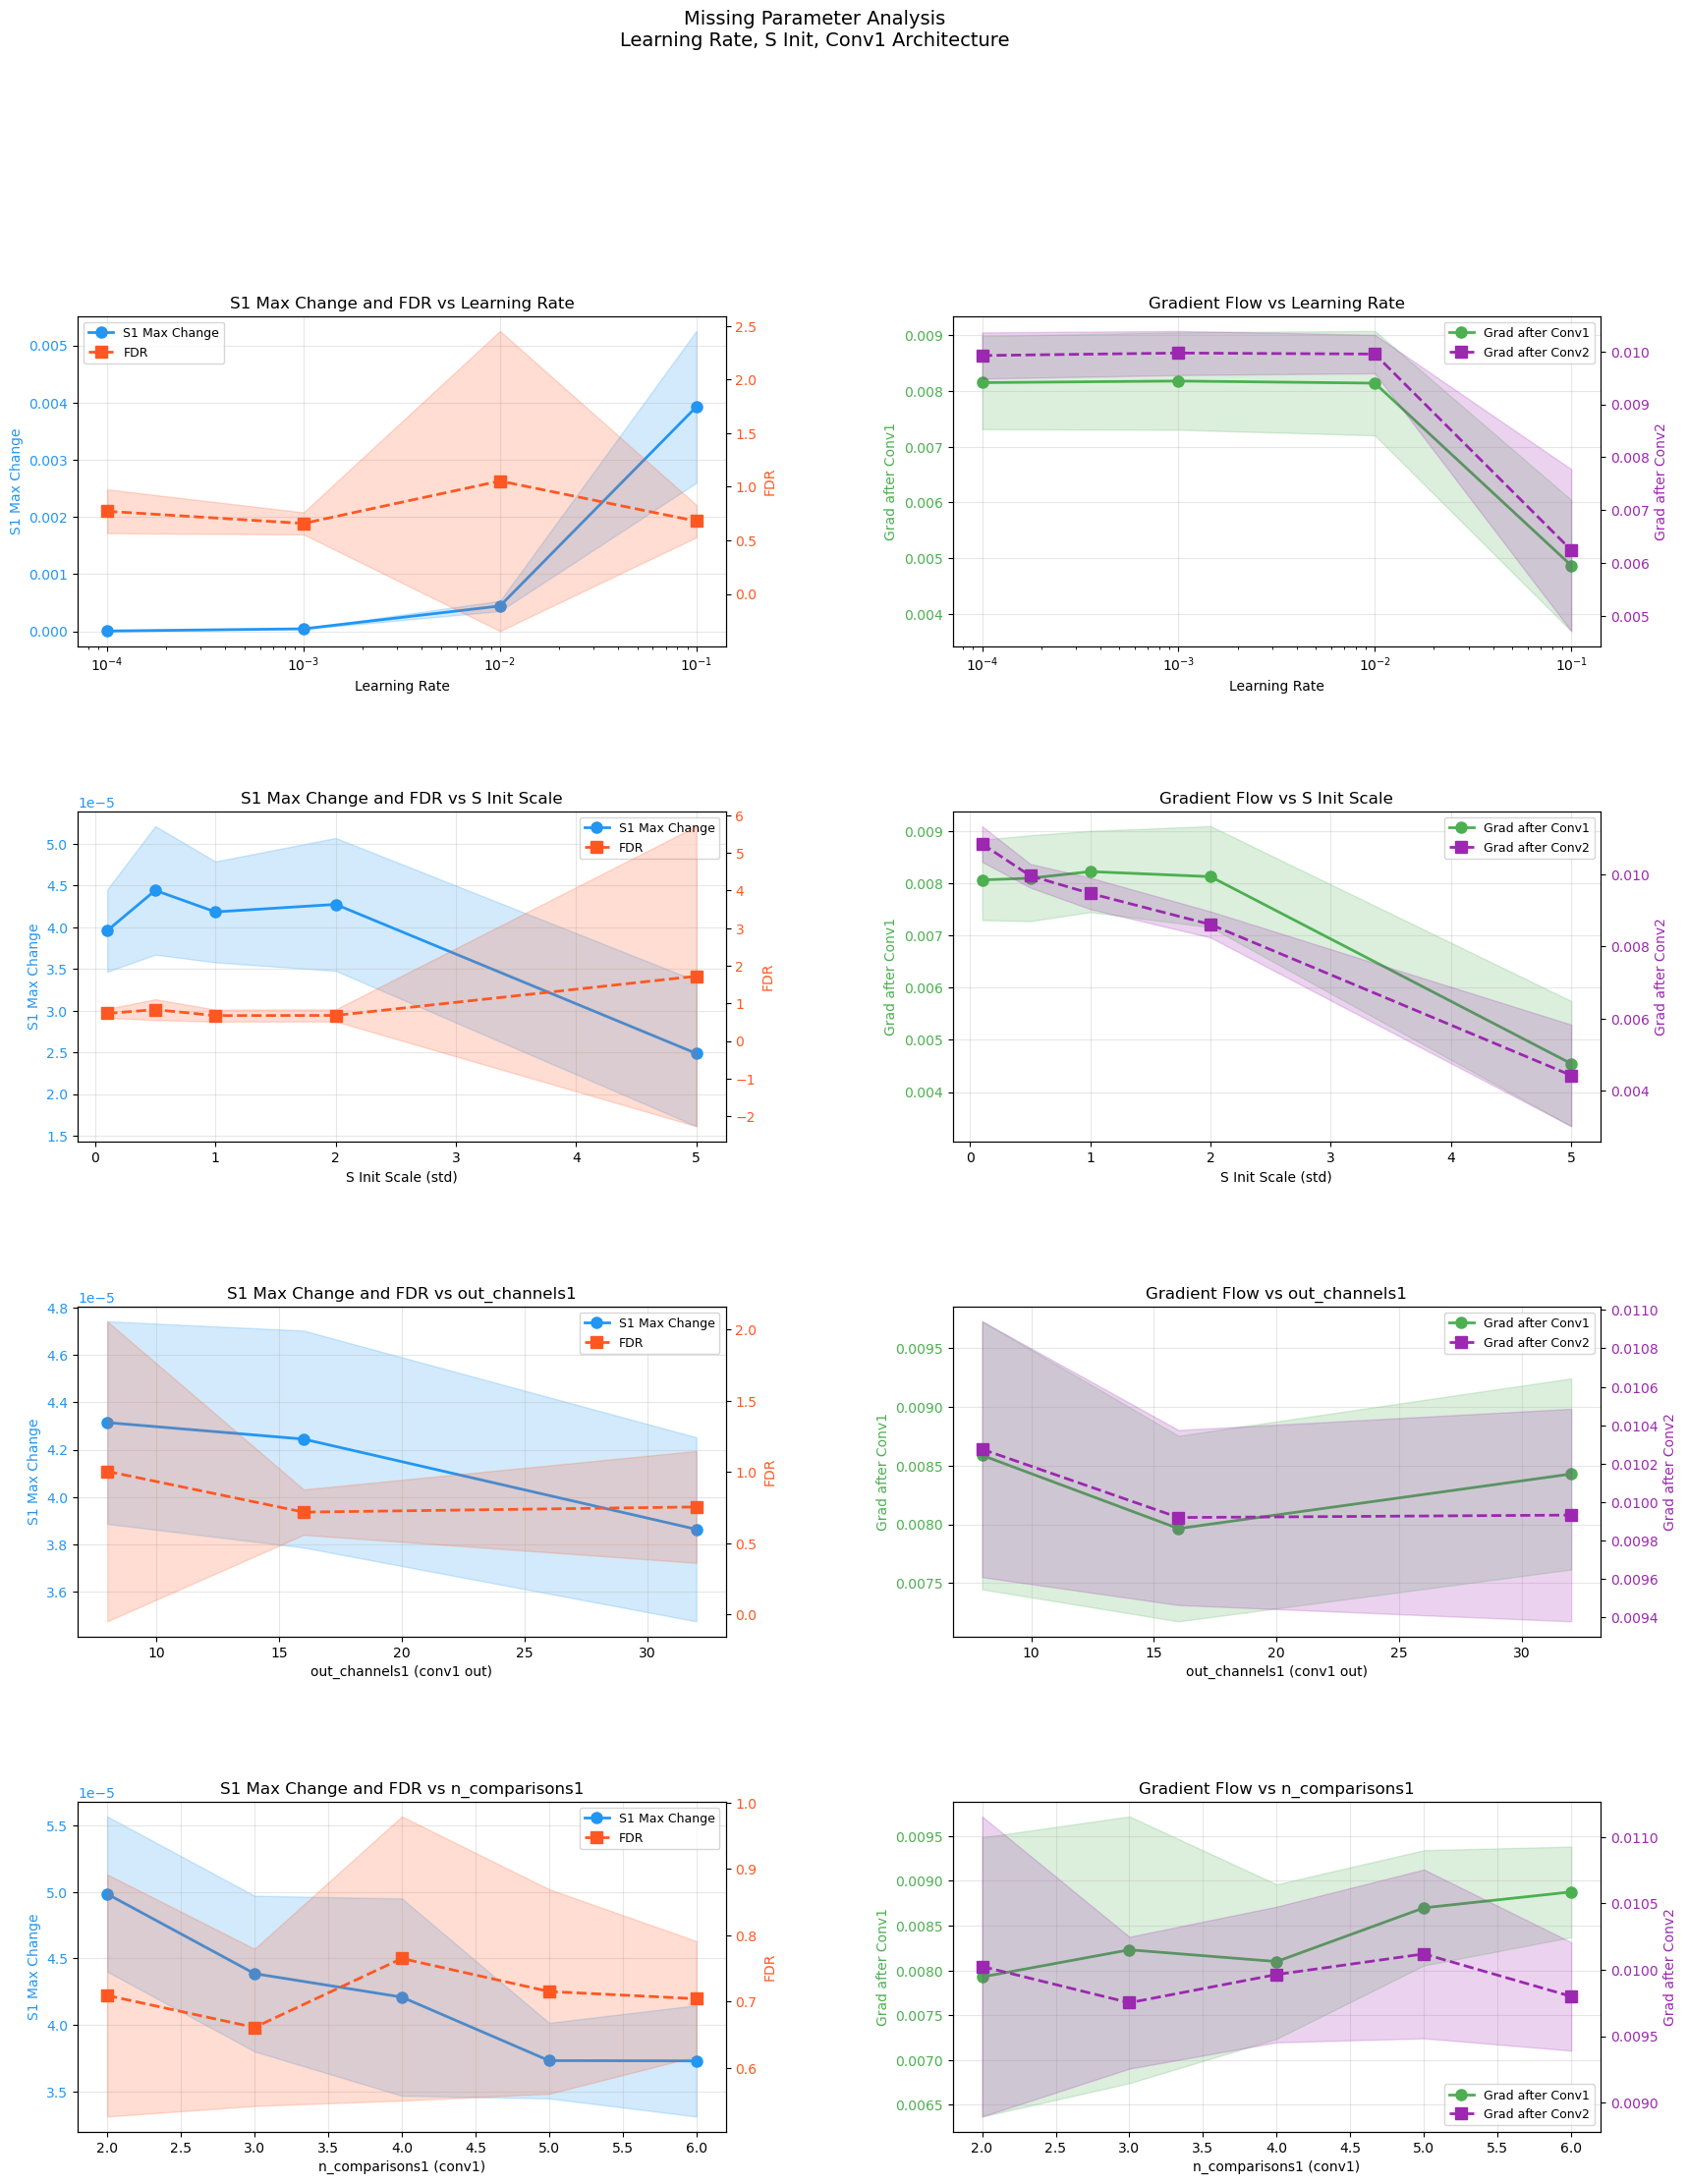

In [336]:
results_lr, results_sinit, results_ch1, results_nc1 = \
    optimize_all_parameters(
        train_loader         = twoclasstrain_loader,
        num_classes          = 2,
        learning_rate_range  = [0.0001, 0.001, 0.01, 0.1],
        s_init_scale_range   = [0.1, 0.5, 1.0, 2.0, 5.0],
        out_channels1_range  = [8, 16, 32],
        n_comparisons1_range = [2, 3, 4, 5, 6],
        n_trials             = 15
    )

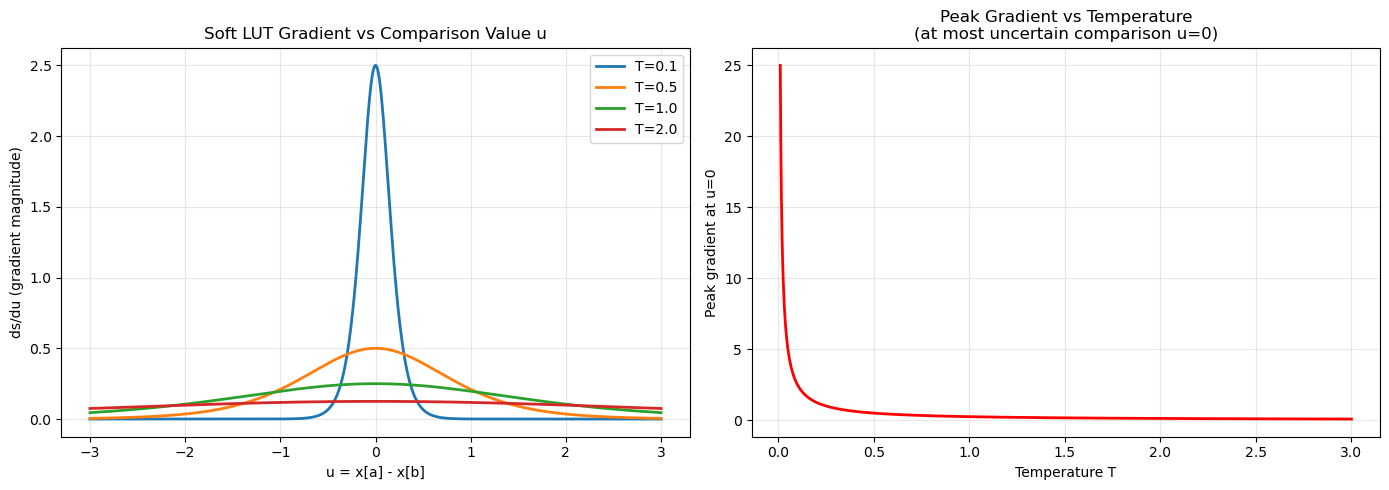

In [272]:
def ds_du(u, T):
    s = 1 / (1 + np.exp(-u / T))
    return s * (1 - s) / T

u_vals = np.linspace(-3, 3, 1000)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: ds_du for different temperatures
temps = [0.1, 0.5, 1.0, 2.0]
for T in temps:
    axes[0].plot(u_vals,
                 [ds_du(u, T) for u in u_vals],
                 label=f'T={T}', linewidth=2)

axes[0].set_xlabel('u = x[a] - x[b]')
axes[0].set_ylabel('ds/du (gradient magnitude)')
axes[0].set_title('Soft LUT Gradient vs Comparison Value u')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Right: peak gradient value at u=0 for each T
T_range = np.linspace(0.01, 3.0, 1000)
peak_grad = [ds_du(0, T) for T in T_range]  # peak is at u=0
axes[1].plot(T_range, peak_grad, color='red', linewidth=2)
axes[1].set_xlabel('Temperature T')
axes[1].set_ylabel('Peak gradient at u=0')
axes[1].set_title('Peak Gradient vs Temperature\n(at most uncertain comparison u=0)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [273]:
def total_gradient_magnitude(T, u_distribution='uniform',
                              u_range=2.0, n_comparisons=4):
    """
    Compute expected total gradient magnitude
    flowing back through n_comparisons
    given a temperature T and distribution of u values
    """
    u_vals = np.linspace(-u_range, u_range, 10000)
    
    if u_distribution == 'uniform':
        # All u values equally likely
        weights = np.ones(len(u_vals)) / len(u_vals)
    elif u_distribution == 'gaussian':
        # Most u values near 0
        weights = np.exp(-u_vals**2 / 2)
        weights /= weights.sum()
    
    # ds_du for each u value
    grads = np.array([ds_du(u, T) for u in u_vals])
    
    # Expected gradient magnitude per comparison
    expected_per_comp = np.sum(weights * grads)
    
    # Total across all comparisons
    total = expected_per_comp * n_comparisons
    
    return total, expected_per_comp

T_range = [0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]

print(f"{'T':<8} {'Total grad':>12} {'Per comp':>12}")
print(f"{'-'*35}")
for T in T_range:
    total, per_comp = total_gradient_magnitude(T)
    print(f"{T:<8} {total:>12.4f} {per_comp:>12.4f}")

T          Total grad     Per comp
-----------------------------------
0.05           0.9999       0.2500
0.1            0.9999       0.2500
0.2            0.9998       0.2500
0.5            0.9639       0.2410
1.0            0.7616       0.1904
2.0            0.4621       0.1155
5.0            0.1974       0.0493


In [281]:
def check_gradients_2layer(model, train_loader):
    """
    Check gradient magnitudes at each layer
    for 2 layer soft LUT conv + linear classifier
    
    Architecture:
        conv1 -> relu1 -> pool1 -> conv2 -> relu2 -> pool2 -> classifier
    """
    images, labels = next(iter(train_loader))
    img_tensor     = images[0]
    label          = labels[0]
    
    x      = preprocess_for_lut(img_tensor)
    target = label.item()
    
    # Forward (need to run manually to cache masks)
    out1            = model.conv1.forward(x)
    relu1_mask      = (out1 > 0)
    out1            = np.maximum(0, out1)
    out1_p          = model.pool1.forward(out1)
    
    out2            = model.conv2.forward(out1_p)
    relu2_mask      = (out2 > 0)
    out2            = np.maximum(0, out2)
    out2_p          = model.pool2.forward(out2)
    
    feature_shape   = out2_p.shape
    logits          = model.classifier.forward(out2_p.flatten())
    loss, logit_grad = cross_entropy_from_logits(logits, target)
    
    print(f"Loss:                    {loss:.4f}")
    print(f"Logit grad norm:         {np.linalg.norm(logit_grad):.6f}")
    print()
    
    # Classifier backward
    x_flat_grad = model.classifier.backward(logit_grad, learning_rate=0.0)
    print(f"After classifier:        {np.linalg.norm(x_flat_grad):.6f}")
    
    x_grad      = x_flat_grad.reshape(feature_shape)
    
    # Pool2 backward
    x_grad      = model.pool2.backward(x_grad)
    print(f"After pool2:             {np.linalg.norm(x_grad):.6f}")
    
    # ReLU2 backward
    x_grad      = x_grad * relu2_mask
    print(f"After relu2:             {np.linalg.norm(x_grad):.6f}  "
          f"[{(relu2_mask==0).mean():.0%} dead]")
    
    # Conv2 backward
    x_grad      = model.conv2.backward(x_grad, learning_rate=0.0)
    print(f"After conv2:             {np.linalg.norm(x_grad):.6f}")
    
    # Pool1 backward
    x_grad      = model.pool1.backward(x_grad)
    print(f"After pool1:             {np.linalg.norm(x_grad):.6f}")
    
    # ReLU1 backward
    x_grad      = x_grad * relu1_mask
    print(f"After relu1:             {np.linalg.norm(x_grad):.6f}  "
          f"[{(relu1_mask==0).mean():.0%} dead]")
    
    # Conv1 backward
    x_grad      = model.conv1.backward(x_grad, learning_rate=0.0)
    print(f"After conv1:             {np.linalg.norm(x_grad):.6f}")
    
    print()
    
    # ---- S table changes with real lr ----
    S1_before   = model.conv1.lut.S.copy()
    S2_before   = model.conv2.lut.S.copy()
    W_before    = model.classifier.W.copy()
    
    # Run again with real lr to measure updates
    out1            = model.conv1.forward(x)
    relu1_mask      = (out1 > 0)
    out1            = np.maximum(0, out1)
    out1_p          = model.pool1.forward(out1)
    out2            = model.conv2.forward(out1_p)
    relu2_mask      = (out2 > 0)
    out2            = np.maximum(0, out2)
    out2_p          = model.pool2.forward(out2)
    feature_shape   = out2_p.shape
    logits          = model.classifier.forward(out2_p.flatten())
    loss, logit_grad = cross_entropy_from_logits(logits, target)
    
    def rescale(g, target=0.1, eps=1e-8):
        n = np.linalg.norm(g)
        return g * (target / n) if n > eps else g
    
    x_flat_grad = model.classifier.backward(logit_grad, learning_rate=0.001)
    x_grad      = x_flat_grad.reshape(feature_shape)
    x_grad      = model.pool2.backward(x_grad)
    x_grad      = x_grad * relu2_mask
    x_grad      = rescale(x_grad)
    x_grad      = model.conv2.backward(x_grad, learning_rate=0.001)
    x_grad      = model.pool1.backward(x_grad)
    x_grad      = x_grad * relu1_mask
    x_grad      = rescale(x_grad)
    model.conv1.backward(x_grad, learning_rate=0.001)
    
    S1_change   = np.abs(model.conv1.lut.S - S1_before)
    S2_change   = np.abs(model.conv2.lut.S - S2_before)
    W_change    = np.abs(model.classifier.W - W_before)
    
    print(f"Conv1 LUT max change:    {S1_change.max():.8f}")
    print(f"Conv2 LUT max change:    {S2_change.max():.8f}")
    print(f"Classifier W max change: {W_change.max():.8f}")
    
    # Temperature info if soft LUT
    if hasattr(model.conv1, 'temperature'):
        print()
        print(f"Conv1 temperature:       {model.conv1.temperature:.4f}")
    if hasattr(model.conv2, 'temperature'):
        print(f"Conv2 temperature:       {model.conv2.temperature:.4f}")

In [327]:
model = SecondLUTConvV2_LinearModel(
    num_classes    = 2,
    out_channels1  = 16,
    out_channels2  = 32,
    n_comparisons1 = 2,
    n_comparisons2 = 4,
    seed           = 42,
    temperature    = 1,
)

check_gradients_2layer(model, twoclasstrain_loader)

Loss:                    0.8057
Logit grad norm:         0.782350

After classifier:        1.097032
After pool2:             1.097032
After relu2:             0.843362  [47% dead]
After conv2:             0.078927
After pool1:             0.078927
After relu1:             0.063505  [43% dead]
After conv1:             0.004341

Conv1 LUT max change:    0.00005407
Conv2 LUT max change:    0.00003213
Classifier W max change: 0.00080355


In [298]:
def check_s_table_values(model):
    """
    Check actual S table values
    to understand why delta_S is small
    """
    print("S Table Statistics:")
    print()
    
    for name, conv in [('conv1', model.conv1),
                        ('conv2', model.conv2)]:
        S = conv.lut.S
        
        # S shape: (n_tables, table_size, 1)
        S_flat = S.flatten()
        
        print(f"{name} S tables:")
        print(f"  Shape:       {S.shape}")
        print(f"  Mean:        {S_flat.mean():.6f}")
        print(f"  Std:         {S_flat.std():.6f}")
        print(f"  Max:         {S_flat.max():.6f}")
        print(f"  Min:         {S_flat.min():.6f}")
        print(f"  Mean |S|:    {np.abs(S_flat).mean():.6f}")
        
        # delta_S: difference between adjacent rows
        # for each table compute avg |S[jbar] - S[j]|
        avg_delta = []
        for t in range(S.shape[0]):
            for j in range(S.shape[1]):
                for c in range(conv.lut.n_comparisons):
                    jbar = j ^ (1 << c)
                    if jbar < S.shape[1]:
                        delta = abs(S[t, j, 0] - S[t, jbar, 0])
                        avg_delta.append(delta)
        
        print(f"  Mean |delta_S|: {np.mean(avg_delta):.6f}")
        print(f"  Max  |delta_S|: {np.max(avg_delta):.6f}")
        print()

check_s_table_values(model)

S Table Statistics:

conv1 S tables:
  Shape:       (16, 16, 1)
  Mean:        -0.014898
  Std:         0.482042
  Max:         1.456928
  Min:         -1.283329
  Mean |S|:    0.379934
  Mean |delta_S|: 0.543703
  Max  |delta_S|: 2.145271

conv2 S tables:
  Shape:       (32, 16, 1)
  Mean:        -0.023727
  Std:         0.512729
  Max:         1.589424
  Min:         -1.824206
  Mean |S|:    0.402810
  Mean |delta_S|: 0.566928
  Max  |delta_S|: 2.692472



In [303]:
def compute_soft_lut_metrics(
    in_channels,
    out_channels,
    n_comparisons,
    temperature,
    n_patches,
    u_mean = 0.5    # typical |u| value in practice
):
    """
    Compute all gradient flow metrics analytically
    for soft LUT with given parameters
    
    Returns metrics that predict training success
    """
    patch_dim  = 9 * in_channels   # kernel=3
    table_size = 2 ** n_comparisons
    overlap    = 9
    
    # S update metrics (same as hard LUT)
    row_hits        = n_patches / table_size
    
    # Pixel coverage (new: includes n_comparisons)
    pixel_coverage  = overlap * out_channels * n_comparisons * (2/patch_dim)
    
    # Gradient magnitude from ds_du at typical u
    s               = 1 / (1 + np.exp(-u_mean / temperature))
    ds_du_typical   = s * (1 - s) / temperature
    
    # Peak gradient at u=0
    ds_du_peak      = 0.25 / temperature
    
    # Fraction of comparisons that get meaningful gradient
    # comparison active if |u| < 3T
    # assuming u uniform in [0, 2]
    active_frac     = min(3 * temperature / 2.0, 1.0)
    active_comps    = n_comparisons * active_frac
    
    # Effective pixel coverage (only active comparisons)
    eff_coverage    = overlap * out_channels * active_comps * (2/patch_dim)
    
    # Total gradient budget
    total_grad      = 0.25 / temperature
    
    # Gradient per covered pixel
    if eff_coverage > 0:
        grad_per_pixel = total_grad / eff_coverage
    else:
        grad_per_pixel = 0
    
    return {
        'row_hits':        row_hits,
        'pixel_coverage':  pixel_coverage,
        'eff_coverage':    eff_coverage,
        'ds_du_peak':      ds_du_peak,
        'ds_du_typical':   ds_du_typical,
        'active_frac':     active_frac,
        'total_grad':      total_grad,
        'grad_per_pixel':  grad_per_pixel,
    }

In [314]:
def optimize_soft_lut_parameters(
    train_loader,
    num_classes,
    base_in_channels    = 16,
    out_channels_range  = [8, 16, 32, 64],
    n_comparisons_range = [2, 3, 4, 5, 6],
    temperature_range   = [0.1, 0.3, 0.5, 1.0, 2.0],
    n_trials            = 5
):
    def rescale(g, tgt=0.1, eps=1e-8):
        n = np.linalg.norm(g)
        return g * (tgt / n) if n > eps else g
    
    def compute_fdr(c0_feats, c1_feats):
        c0     = np.array(c0_feats)
        c1     = np.array(c1_feats)
        if len(c0) < 2 or len(c1) < 2:
            return 0.0
        mean0  = c0.mean(axis=0)
        mean1  = c1.mean(axis=0)
        var0   = c0.var(axis=0)
        var1   = c1.var(axis=0)
        between = (mean0 - mean1) ** 2
        within  = (var0 + var1) / 2
        valid   = within > 1e-4
        if valid.sum() == 0:
            return 0.0
        return float(min((between[valid] / within[valid]).mean(), 100.0))
    
    def run_one_config(ch2, nc2, T, seed):
        model = SecondLUTConvV2_LinearModel(
            num_classes    = num_classes,
            out_channels1  = base_in_channels,
            out_channels2  = ch2,
            n_comparisons1 = 4,
            n_comparisons2 = nc2,
            temperature    = T,
            seed           = seed
        )
        model.training = False
        
        # Collect samples
        class_samples = {0: [], 1: []}
        for images, labels in train_loader:
            for img, label in zip(images, labels):
                t = label.item()
                if len(class_samples[t]) < 5:
                    class_samples[t].append(
                        preprocess_for_lut(img)
                    )
            if all(len(v) >= 5 for v in class_samples.values()):
                break
        
        all_samples = class_samples[0] + class_samples[1]
        all_targets = [0]*5 + [1]*5
        
        grad_c2_list = []
        grad_c1_list = []
        s2_list      = []
        s1_list      = []
        
        for x, target in zip(all_samples, all_targets):
            
            S1_before = model.conv1.lut.S.copy()
            S2_before = model.conv2.lut.S.copy()
            
            # Forward
            out1       = model.conv1.forward(x)
            relu1_mask = (out1 > 0)
            out1       = np.maximum(0, out1)
            out1_p     = model.pool1.forward(out1)
            out2       = model.conv2.forward(out1_p)
            relu2_mask = (out2 > 0)
            out2       = np.maximum(0, out2)
            out2_p     = model.pool2.forward(out2)
            feat_shape = out2_p.shape
            logits     = model.classifier.forward(out2_p.flatten())
            loss, grad = cross_entropy_from_logits(logits, target)
            
            # Gradient flow (lr=0 so no S update)
            xg = model.classifier.backward(grad, learning_rate=0.0)
            xg = xg.reshape(feat_shape)
            xg = model.pool2.backward(xg)
            xg = xg * relu2_mask
            xg = rescale(xg)
            xg = model.conv2.backward(xg, 0.0)
            grad_c2_list.append(np.linalg.norm(xg))
            
            xg = model.pool1.backward(xg)
            xg = xg * relu1_mask
            xg = rescale(xg)
            xg = model.conv1.backward(xg, 0.0)
            grad_c1_list.append(np.linalg.norm(xg))
            
            # S update measurement (lr=0.001)
            xg = model.classifier.backward(grad, learning_rate=0.001)
            xg = xg.reshape(feat_shape)
            xg = model.pool2.backward(xg)
            xg = xg * relu2_mask
            xg = rescale(xg)
            xg = model.conv2.backward(xg, 0.001)
            xg = model.pool1.backward(xg)
            xg = xg * relu1_mask
            xg = rescale(xg)
            model.conv1.backward(xg, 0.001)
            
            s2_list.append(
                np.abs(model.conv2.lut.S - S2_before).max()
            )
            s1_list.append(
                np.abs(model.conv1.lut.S - S1_before).max()
            )
        
        # FDR
        c0_feats = []
        c1_feats = []
        for x in class_samples[0]:
            out1   = model.conv1.forward(x)
            out1   = np.maximum(0, out1)
            out1_p = model.pool1.forward(out1)
            out2   = model.conv2.forward(out1_p)
            out2   = np.maximum(0, out2)
            out2_p = model.pool2.forward(out2)
            c0_feats.append(out2_p.flatten())
        for x in class_samples[1]:
            out1   = model.conv1.forward(x)
            out1   = np.maximum(0, out1)
            out1_p = model.pool1.forward(out1)
            out2   = model.conv2.forward(out1_p)
            out2   = np.maximum(0, out2)
            out2_p = model.pool2.forward(out2)
            c1_feats.append(out2_p.flatten())
        
        fdr = compute_fdr(c0_feats, c1_feats)
        
        return {
            'grad_c2': float(np.mean(grad_c2_list)),
            'grad_c1': float(np.mean(grad_c1_list)),
            's2_max':  float(np.mean(s2_list)),
            's1_max':  float(np.mean(s1_list)),
            'fdr':     fdr,
        }
    
    # ---- Run all configs ----
    results = []
    total   = (len(out_channels_range) *
               len(n_comparisons_range) *
               len(temperature_range))
    done    = 0
    
    for ch2 in out_channels_range:
        for nc2 in n_comparisons_range:
            for T in temperature_range:
                
                trial_metrics = []
                for trial in range(n_trials):
                    m = run_one_config(ch2, nc2, T,
                                       seed=trial*17+42)
                    trial_metrics.append(m)
                
                def avg(key):
                    return float(np.mean(
                        [m[key] for m in trial_metrics]
                    ))
                def std(key):
                    return float(np.std(
                        [m[key] for m in trial_metrics]
                    ))
                
                results.append({
                    'ch2':         ch2,
                    'nc2':         nc2,
                    'T':           T,
                    'grad_c2':     avg('grad_c2'),
                    'grad_c1':     avg('grad_c1'),
                    'grad_c2_std': std('grad_c2'),
                    'grad_c1_std': std('grad_c1'),
                    's2_max':      avg('s2_max'),
                    's1_max':      avg('s1_max'),
                    'fdr':         avg('fdr'),
                    'fdr_std':     std('fdr'),
                })
                
                done += 1
                if done % 5 == 0:
                    r = results[-1]
                    print(f"  {done:3d}/{total}  "
                          f"ch2={ch2:3d} nc2={nc2} T={T:.1f}  "
                          f"grad_c2={r['grad_c2']:.5f}  "
                          f"grad_c1={r['grad_c1']:.5f}  "
                          f"fdr={r['fdr']:.4f}")
    
    return results


def plot_soft_lut_optimization(results):
    """
    Plot parameter relationships without pandas
    """
    # Extract unique values
    ch2s  = sorted(set(r['ch2'] for r in results))
    nc2s  = sorted(set(r['nc2'] for r in results))
    temps = sorted(set(r['T']   for r in results))
    
    def get_vals(filter_key, filter_val,
                  group_key, metric_key):
        """Group results by group_key where filter_key==filter_val"""
        grouped = {}
        for r in results:
            if r[filter_key] == filter_val:
                k = r[group_key]
                if k not in grouped:
                    grouped[k] = []
                grouped[k].append(r[metric_key])
        
        xs   = sorted(grouped.keys())
        ys   = [np.mean(grouped[x]) for x in xs]
        stds = [np.std(grouped[x])  for x in xs]
        return xs, ys, stds
    
    def get_grid(fix_key, fix_val, row_key, col_key, metric):
        """Get 2D grid of metric values"""
        row_vals = sorted(set(r[row_key] for r in results))
        col_vals = sorted(set(r[col_key] for r in results))
        grid     = np.zeros((len(row_vals), len(col_vals)))
        
        for i, rv in enumerate(row_vals):
            for j, cv in enumerate(col_vals):
                vals = [r[metric] for r in results
                        if r[fix_key] == fix_val
                        and r[row_key] == rv
                        and r[col_key] == cv]
                grid[i, j] = np.mean(vals) if vals else 0
        
        return grid, row_vals, col_vals
    
    def normalize(arr):
        mn, mx = arr.min(), arr.max()
        if mx - mn < 1e-10:
            return np.zeros_like(arr)
        return (arr - mn) / (mx - mn)
    
    colors_T  = plt.cm.viridis(np.linspace(0, 1, len(temps)))
    colors_ch = plt.cm.Blues(np.linspace(0.4, 1, len(ch2s)))
    colors_nc = plt.cm.Oranges(np.linspace(0.4, 1, len(nc2s)))
    
    fig = plt.figure(figsize=(22, 20))
    gs  = gridspec.GridSpec(4, 3, figure=fig,
                             hspace=0.5, wspace=0.35)
    
    def plot_lines(ax, x_key, y_key, group_key,
                    group_vals, colors, title,
                    xlabel, ylabel, log_y=False):
        for val, color in zip(group_vals, colors):
            xs, ys, stds = get_vals(group_key, val,
                                     x_key, y_key)
            ys   = np.array(ys)
            stds = np.array(stds)
            ax.plot(xs, ys, color=color, marker='o',
                    linewidth=2, markersize=7,
                    label=f'{group_key}={val}')
            ax.fill_between(xs, ys-stds, ys+stds,
                             alpha=0.15, color=color)
        ax.set_title(title, fontsize=11)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        if log_y:
            ax.set_yscale('log')
    
    # ================================================================
    # Row 1: grad_c2
    # ================================================================
    plot_lines(fig.add_subplot(gs[0, 0]),
               'ch2', 'grad_c2', 'T',
               temps, colors_T,
               'Grad after Conv2 vs out_channels2\n(line per T)',
               'out_channels2', 'gradient norm')
    
    plot_lines(fig.add_subplot(gs[0, 1]),
               'nc2', 'grad_c2', 'T',
               temps, colors_T,
               'Grad after Conv2 vs n_comparisons2\n(line per T)',
               'n_comparisons2', 'gradient norm')
    
    ax = fig.add_subplot(gs[0, 2])
    for ch2, color in zip(ch2s, colors_ch):
        xs, ys, stds = get_vals('ch2', ch2, 'T', 'grad_c2')
        ys   = np.array(ys)
        stds = np.array(stds)
        ax.plot(xs, ys, color=color, marker='o',
                linewidth=2, markersize=7, label=f'ch={ch2}')
        ax.fill_between(xs, ys-stds, ys+stds,
                         alpha=0.15, color=color)
    T_th  = np.linspace(min(temps), max(temps), 100)
    ax2_t = ax.twinx()
    ax2_t.plot(T_th, 0.25/T_th, 'r--',
               linewidth=1.5, label='Theory 0.25/T')
    ax2_t.set_ylabel('Theory: 0.25/T', color='red')
    ax2_t.tick_params(axis='y', labelcolor='red')
    ax.set_title('Grad after Conv2 vs Temperature', fontsize=11)
    ax.set_xlabel('Temperature')
    ax.set_ylabel('gradient norm')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    
    # ================================================================
    # Row 2: grad_c1 (most important)
    # ================================================================
    plot_lines(fig.add_subplot(gs[1, 0]),
               'ch2', 'grad_c1', 'T',
               temps, colors_T,
               'Grad after Conv1 vs out_channels2\n(line per T)',
               'out_channels2', 'gradient norm')
    
    plot_lines(fig.add_subplot(gs[1, 1]),
               'nc2', 'grad_c1', 'T',
               temps, colors_T,
               'Grad after Conv1 vs n_comparisons2\n(line per T)',
               'n_comparisons2', 'gradient norm')
    
    ax = fig.add_subplot(gs[1, 2])
    for nc2, color in zip(nc2s, colors_nc):
        xs, ys, stds = get_vals('nc2', nc2, 'T', 'grad_c1')
        ys   = np.array(ys)
        stds = np.array(stds)
        ax.plot(xs, ys, color=color, marker='s',
                linewidth=2, markersize=7, label=f'nc={nc2}')
        ax.fill_between(xs, ys-stds, ys+stds,
                         alpha=0.15, color=color)
    ax.set_title('Grad after Conv1 vs Temperature', fontsize=11)
    ax.set_xlabel('Temperature')
    ax.set_ylabel('gradient norm')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    
    # ================================================================
    # Row 3: FDR and S changes
    # ================================================================
    plot_lines(fig.add_subplot(gs[2, 0]),
               'T', 'fdr', 'nc2',
               nc2s, colors_nc,
               'FDR vs Temperature\n(line per n_comparisons)',
               'Temperature', 'FDR (capped at 100)')
    
    plot_lines(fig.add_subplot(gs[2, 1]),
               'T', 's1_max', 'ch2',
               ch2s, colors_ch,
               'S1 Max Change vs Temperature\n(line per out_channels)',
               'Temperature', 'S1 max change', log_y=True)
    
    plot_lines(fig.add_subplot(gs[2, 2]),
               'nc2', 's1_max', 'T',
               temps, colors_T,
               'S1 Max Change vs n_comparisons\n(line per T)',
               'n_comparisons2', 'S1 max change', log_y=True)
    
    # ================================================================
    # Row 4: Composite score heatmaps for each temperature
    # ================================================================
    n_T_to_show = min(3, len(temps))
    T_subset    = temps[:n_T_to_show]
    
    for plot_idx, T_val in enumerate(T_subset):
        ax = fig.add_subplot(gs[3, plot_idx])
        
        grid, row_vals, col_vals = get_grid(
            'T', T_val, 'nc2', 'ch2', 'fdr'
        )
        fdr_norm = normalize(grid)
        
        grid_c1, _, _ = get_grid(
            'T', T_val, 'nc2', 'ch2', 'grad_c1'
        )
        c1_norm = normalize(grid_c1)
        
        grid_s1, _, _ = get_grid(
            'T', T_val, 'nc2', 'ch2', 's1_max'
        )
        s1_norm = normalize(grid_s1)
        
        score = 0.4*fdr_norm + 0.4*c1_norm + 0.2*s1_norm
        
        im = ax.imshow(score, aspect='auto',
                        cmap='RdYlGn', vmin=0, vmax=1)
        ax.set_xticks(range(len(col_vals)))
        ax.set_xticklabels(col_vals)
        ax.set_yticks(range(len(row_vals)))
        ax.set_yticklabels(row_vals)
        ax.set_xlabel('out_channels2')
        ax.set_ylabel('n_comparisons2')
        
        best = np.unravel_index(score.argmax(), score.shape)
        ax.add_patch(plt.Rectangle(
            (best[1]-0.5, best[0]-0.5), 1, 1,
            fill=False, edgecolor='blue', linewidth=3
        ))
        best_ch = col_vals[best[1]]
        best_nc = row_vals[best[0]]
        ax.set_title(f'Composite Score  T={T_val}\n'
                      f'Best: ch={best_ch} nc={best_nc}',
                      fontsize=10)
        plt.colorbar(im, ax=ax)
    
    plt.suptitle('Soft LUT Parameter Optimization\n'
                 'FDR capped at 100, no pandas',
                 fontsize=14, y=1.01)
    plt.savefig('soft_lut_optimization.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    
    # ---- Print summary table ----
    print(f"\n{'='*70}")
    print(f"Top 10 configurations")
    print(f"{'='*70}")
    
    all_scores = []
    fdr_all    = np.array([r['fdr']    for r in results])
    c1_all     = np.array([r['grad_c1']for r in results])
    s1_all     = np.array([r['s1_max'] for r in results])
    
    fdr_norm = normalize(fdr_all)
    c1_norm  = normalize(c1_all)
    s1_norm  = normalize(s1_all)
    
    for i, r in enumerate(results):
        score = (0.4*fdr_norm[i] +
                 0.4*c1_norm[i]  +
                 0.2*s1_norm[i])
        all_scores.append((score, r))
    
    all_scores.sort(key=lambda x: -x[0])
    
    print(f"{'ch2':<6} {'nc2':<5} {'T':<6} "
          f"{'grad_c1':>10} {'fdr':>8} "
          f"{'s1_max':>10} {'score':>8}")
    print(f"{'-'*58}")
    for score, r in all_scores[:10]:
        print(f"{r['ch2']:<6} {r['nc2']:<5} {r['T']:<6.2f} "
              f"{r['grad_c1']:>10.6f} {r['fdr']:>8.4f} "
              f"{r['s1_max']:>10.6f} {score:>8.4f}")
    
    return results, all_scores

    5/100  ch2=  8 nc2=2 T=2.0  grad_c2=0.00419  grad_c1=0.00503  fdr=0.6625
   10/100  ch2=  8 nc2=3 T=2.0  grad_c2=0.00490  grad_c1=0.00509  fdr=0.6019
   15/100  ch2=  8 nc2=4 T=2.0  grad_c2=0.00580  grad_c1=0.00512  fdr=0.7902
   20/100  ch2=  8 nc2=5 T=2.0  grad_c2=0.00648  grad_c1=0.00520  fdr=1.2722
   25/100  ch2=  8 nc2=6 T=2.0  grad_c2=0.00716  grad_c1=0.00514  fdr=0.6961
   30/100  ch2= 16 nc2=2 T=2.0  grad_c2=0.00384  grad_c1=0.00518  fdr=0.7088
   35/100  ch2= 16 nc2=3 T=2.0  grad_c2=0.00505  grad_c1=0.00516  fdr=0.8646
   40/100  ch2= 16 nc2=4 T=2.0  grad_c2=0.00593  grad_c1=0.00521  fdr=0.5946
   45/100  ch2= 16 nc2=5 T=2.0  grad_c2=0.00647  grad_c1=0.00531  fdr=0.7300
   50/100  ch2= 16 nc2=6 T=2.0  grad_c2=0.00698  grad_c1=0.00511  fdr=0.7458
   55/100  ch2= 32 nc2=2 T=2.0  grad_c2=0.00409  grad_c1=0.00514  fdr=0.6512
   60/100  ch2= 32 nc2=3 T=2.0  grad_c2=0.00501  grad_c1=0.00513  fdr=0.9136
   65/100  ch2= 32 nc2=4 T=2.0  grad_c2=0.00578  grad_c1=0.00521  fdr=0.6652

/var/folders/2w/rkl41cps2pq3l_gmv8rdpp7w0000gn/T/ipykernel_6153/280109642.py:120: RuntimeWarning: overflow encountered in exp
  soft_bits = 1 / (1 + np.exp(-diffs / self.temperature))


   75/100  ch2= 32 nc2=6 T=2.0  grad_c2=0.00697  grad_c1=0.00519  fdr=0.6972
   80/100  ch2= 64 nc2=2 T=2.0  grad_c2=0.00410  grad_c1=0.00512  fdr=0.6355
   85/100  ch2= 64 nc2=3 T=2.0  grad_c2=0.00486  grad_c1=0.00521  fdr=0.7048
   90/100  ch2= 64 nc2=4 T=2.0  grad_c2=0.00573  grad_c1=0.00518  fdr=0.8149
   95/100  ch2= 64 nc2=5 T=2.0  grad_c2=0.00638  grad_c1=0.00515  fdr=0.6744
  100/100  ch2= 64 nc2=6 T=2.0  grad_c2=0.00711  grad_c1=0.00515  fdr=0.6407


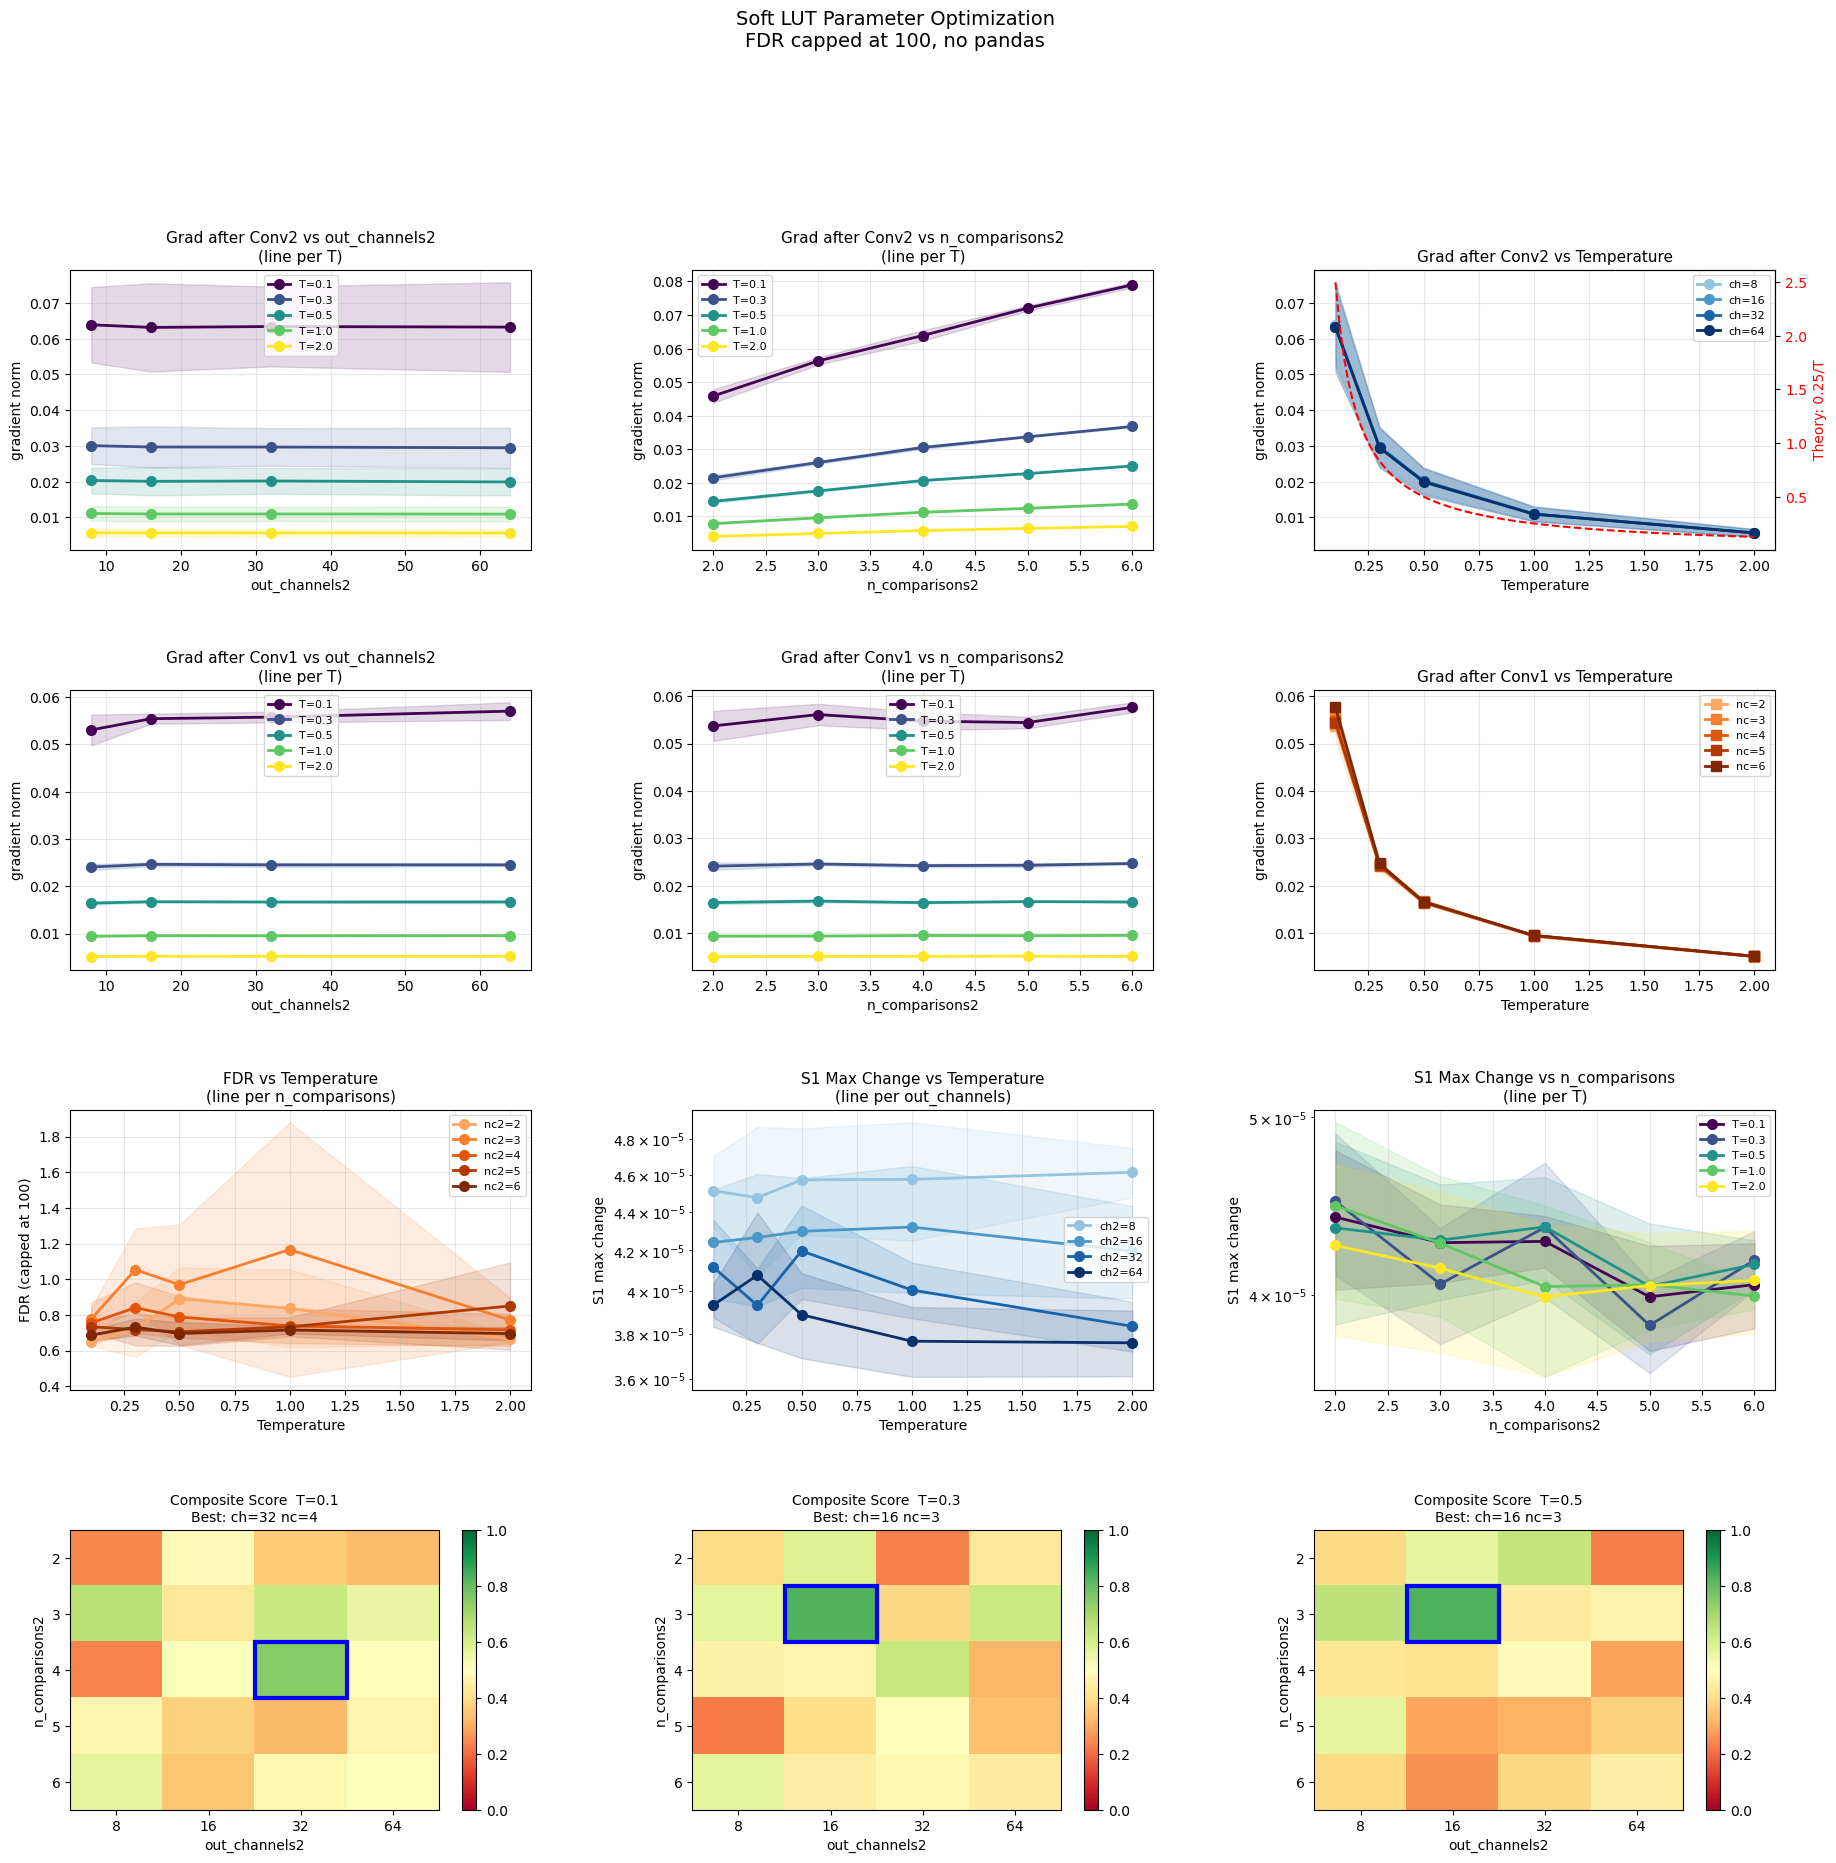


Top 10 configurations
ch2    nc2   T         grad_c1      fdr     s1_max    score
----------------------------------------------------------
16     3     1.00     0.009412   2.3846   0.000046   0.5728
8      3     0.10     0.055228   0.8377   0.000046   0.5562
32     4     0.10     0.055303   0.9376   0.000043   0.5500
8      6     0.10     0.057834   0.7046   0.000044   0.5275
16     2     0.10     0.056125   0.6691   0.000046   0.5255
16     4     0.10     0.056387   0.6951   0.000044   0.5181
32     3     0.10     0.056108   0.8419   0.000042   0.5154
8      5     0.10     0.052416   0.7791   0.000044   0.5065
8      2     0.10     0.048295   0.6474   0.000049   0.5010
16     3     0.10     0.053445   0.7235   0.000044   0.4966


In [315]:
results = optimize_soft_lut_parameters(
    train_loader        = twoclasstrain_loader,
    num_classes         = 2,
    base_in_channels    = 16,
    out_channels_range  = [8, 16, 32, 64],
    n_comparisons_range = [2, 3, 4, 5, 6],
    temperature_range   = [0.1, 0.3, 0.5, 1.0, 2.0],
    n_trials            = 5
)

results, ranked = plot_soft_lut_optimization(results)

In [381]:
@dataclass
class RewirableLUTConvLayerV2:
    """
    Improved rewiring that:
        1. Evaluates tables as units not individual pairs
        2. Uses layer-appropriate criteria
        3. Rewards informativeness for early layers
        4. Rewards class separation for late layers
    """
    in_channels:   int
    out_channels:  int
    kernel_size:   int
    n_comparisons: int
    rng:           np.random.Generator
    layer_type:    str   = 'early'   # 'early' or 'late'
    
    # Rewiring hyperparameters
    theta_h:       float = 20.0
    theta_l:       float = -20.0
    r_pr:          float = 0.1
    
    n_tables:      int        = field(init=False)
    patch_dim:     int        = field(init=False)
    lut:           LUT        = field(init=False)
    
    # One longevity per TABLE (not per anchor pair)
    longevity:     np.ndarray = field(init=False)
    frozen:        np.ndarray = field(init=False)
    rewire_count:  np.ndarray = field(init=False)
    best_quality:  np.ndarray = field(init=False)
    
    # Forward cache
    j_all:         np.ndarray = field(init=False)
    rmin_all:      np.ndarray = field(init=False)
    umin_all:      np.ndarray = field(init=False)
    H_out:         int        = field(init=False)
    W_out:         int        = field(init=False)
    patches:       np.ndarray = field(init=False)
    all_caches:    list       = field(default_factory=list,
                                      init=False)

    def __post_init__(self):
        self.n_tables  = self.out_channels
        self.patch_dim = self.kernel_size**2 * self.in_channels
        
        self.lut = LUT(
            input_dim        = self.patch_dim,
            output_dim       = 1,
            n_tables         = self.n_tables,
            n_comparisons    = self.n_comparisons,
            total_index_bits = self.n_comparisons,
            rng              = self.rng
        )
        
        # Longevity is now per TABLE
        self.longevity    = np.zeros(self.n_tables)
        self.frozen       = np.zeros(self.n_tables, dtype=bool)
        self.rewire_count = np.zeros(self.n_tables, dtype=int)
        self.best_quality = np.zeros(self.n_tables)
    
    def im2col_vectorized(self, x_pad, H_out, W_out):
        from numpy.lib.stride_tricks import as_strided
        C, ks   = self.in_channels, self.kernel_size
        shape   = (H_out, W_out, C, ks, ks)
        s       = x_pad.strides
        strides = (s[1], s[2], s[0], s[1], s[2])
        patches = as_strided(x_pad, shape=shape, strides=strides)
        return patches.reshape(H_out * W_out, C * ks * ks).copy()
    
    def get_patches(self, x):
        C, H, W = x.shape
        pad     = self.kernel_size // 2
        x_pad   = np.pad(x, ((0,0),(pad,pad),(pad,pad)))
        return self.im2col_vectorized(x_pad, H, W)
    
    def rewire_table(self, table_idx):
        """
        Redraw ALL anchor pairs for a table
        We rewire the whole table because
        anchor pairs within a table interact
        """
        for c in range(self.n_comparisons):
            new_a = self.rng.integers(0, self.patch_dim)
            new_b = self.rng.integers(0, self.patch_dim)
            while new_b == new_a:
                new_b = self.rng.integers(0, self.patch_dim)
            self.lut.anchors_a[table_idx, c] = new_a
            self.lut.anchors_b[table_idx, c] = new_b
        
        self.longevity[table_idx]    = 0.0
        self.rewire_count[table_idx] += 1
    
    def compute_table_quality(self, patches_c0,
                               patches_c1,
                               table_idx):
        """
        Evaluate quality of ALL anchor pairs
        in a table TOGETHER
        
        Uses the actual row distribution produced
        by the table as a whole
        not individual comparison bits
        
        This captures the interaction between comparisons
        """
        table_size = 1 << self.n_comparisons
        
        # Compute which row each patch hashes to
        def get_rows(patches):
            vals_a = patches[:, self.lut.anchors_a[table_idx]]
            vals_b = patches[:, self.lut.anchors_b[table_idx]]
            diffs  = vals_a - vals_b
            powers = 1 << np.arange(self.n_comparisons)
            bits   = (diffs > 0).astype(np.int64)
            return (bits * powers[None, :]).sum(axis=1)
        
        rows_c0 = get_rows(patches_c0)   # (n_patches_0,)
        rows_c1 = get_rows(patches_c1)   # (n_patches_1,)
        
        # Row hit distributions
        hits_c0 = np.bincount(rows_c0, minlength=table_size)
        hits_c1 = np.bincount(rows_c1, minlength=table_size)
        
        # Normalize to distributions
        dist_c0  = hits_c0 / (hits_c0.sum() + 1e-10)
        dist_c1  = hits_c1 / (hits_c1.sum() + 1e-10)
        dist_all = (hits_c0 + hits_c1) / (
            hits_c0.sum() + hits_c1.sum() + 1e-10
        )
        
        # ---- Table quality metrics ----
        
        # 1. Row coverage: how evenly are rows used?
        # Ideal: all rows used equally (uniform distribution)
        # Bad: all patches go to one row
        n_used   = (hits_c0 + hits_c1 > 0).sum()
        coverage = n_used / table_size
        
        # Entropy of overall distribution
        # High entropy = even coverage = good
        eps  = 1e-10
        H_all = -(dist_all * np.log2(dist_all + eps)).sum()
        H_max = np.log2(table_size)
        coverage_entropy = H_all / H_max   # normalized to [0,1]
        
        # 2. Class separation at table level (JSD)
        # How different are the class distributions
        # over rows?
        m_dist  = (dist_c0 + dist_c1) / 2
        jsd     = 0.5 * np.sum(
            dist_c0 * np.log2(dist_c0 / (m_dist + eps) + eps)
        ) + 0.5 * np.sum(
            dist_c1 * np.log2(dist_c1 / (m_dist + eps) + eps)
        )
        jsd     = float(np.clip(jsd, 0, 1))
        
        # 3. Row purity (weighted by usage)
        total_hits = hits_c0 + hits_c1
        purity     = 0.0
        for row in range(table_size):
            total = total_hits[row]
            if total == 0:
                continue
            p0_row = hits_c0[row] / total
            row_purity = max(p0_row, 1 - p0_row)
            weight     = total / total_hits.sum()
            purity    += weight * row_purity
        
        # ---- Combine by layer type ----
        if self.layer_type == 'early':
            quality = coverage_entropy

        elif self.layer_type == 'late':
            quality = 0.3 * coverage_entropy + 0.7 * jsd
        
        stats = {
            'coverage':         coverage,
            'coverage_entropy': coverage_entropy,
            'jsd':              jsd,
            'purity':           purity,
            'n_used':           n_used,
            'quality':          quality,
        }
        
        return quality, stats
    
    def compute_table_quality_early(self, patches_all,
                                 table_idx):
        """
        For early layers use ALL patches together
        without class labels

        Goal: find anchor pairs that create
        diverse row assignments
        = detect real image structure

        Do not use class labels at all
        """
        table_size = 1 << self.n_comparisons

        def get_rows(patches):
            vals_a = patches[:, self.lut.anchors_a[table_idx]]
            vals_b = patches[:, self.lut.anchors_b[table_idx]]
            diffs  = vals_a - vals_b
            powers = 1 << np.arange(self.n_comparisons)
            bits   = (diffs > 0).astype(np.int64)
            return (bits * powers[None, :]).sum(axis=1)

        rows = get_rows(patches_all)

        hits = np.bincount(rows, minlength=table_size)
        dist = hits / (hits.sum() + 1e-10)

        # Entropy of row distribution
        eps       = 1e-10
        H         = -(dist * np.log2(dist + eps)).sum()
        H_max     = np.log2(table_size)
        quality   = H / H_max   # normalized entropy [0,1]

        # High quality = patches spread evenly across rows
        # = anchor pair detects real image structure
        # = different patches -> different rows

        return quality
    
    def compute_table_quality_v2(self, patches_c0,
                               patches_c1, table_idx):
        """
        Improved table quality for conv2

        Core insight:
            We do not need conv1 output to have high FDR
            We need conv2 anchor pairs to find
            consistent ORDERING differences between classes

            x[a] > x[b] should be more likely for class 0
            even if both x[a] and x[b] are similar in magnitude

        The right question is not:
            Are class 0 and class 1 in different rows?
            (requires high FDR in conv1 output)

        But rather:
            Is the ORDERING of conv1 channels
            different between classes?
            (requires only consistent relative differences)

        This is a much weaker and more achievable condition
        """
        table_size   = 1 << self.n_comparisons

        def get_rows(patches):
            vals_a = patches[:, self.lut.anchors_a[table_idx]]
            vals_b = patches[:, self.lut.anchors_b[table_idx]]
            diffs  = vals_a - vals_b
            powers = 1 << np.arange(self.n_comparisons)
            bits   = (diffs > 0).astype(np.int64)
            return (bits * powers[None, :]).sum(axis=1)

        rows_c0 = get_rows(patches_c0)
        rows_c1 = get_rows(patches_c1)

        hits_c0  = np.bincount(rows_c0, minlength=table_size)
        hits_c1  = np.bincount(rows_c1, minlength=table_size)

        dist_c0  = hits_c0 / (hits_c0.sum() + 1e-10)
        dist_c1  = hits_c1 / (hits_c1.sum() + 1e-10)
        dist_all = (hits_c0 + hits_c1) / (
            hits_c0.sum() + hits_c1.sum() + 1e-10
        )

        # Coverage entropy
        eps     = 1e-10
        H_all   = -(dist_all * np.log2(dist_all + eps)).sum()
        H_max   = np.log2(table_size)
        coverage_entropy = H_all / H_max

        # JSD
        m_dist  = (dist_c0 + dist_c1) / 2
        jsd     = 0.5 * np.sum(
            dist_c0 * np.log2(dist_c0 / (m_dist + eps) + eps)
        ) + 0.5 * np.sum(
            dist_c1 * np.log2(dist_c1 / (m_dist + eps) + eps)
        )
        jsd     = float(np.clip(jsd, 0, 1))

        # ---- New: Per-comparison bit separation ----
        # Even if full table JSD is low
        # individual comparison bits might show
        # consistent class differences
        # This is what actually drives learning

        bit_separations = []
        for c in range(self.n_comparisons):
            a = self.lut.anchors_a[table_idx, c]
            b = self.lut.anchors_b[table_idx, c]

            bits_0 = (patches_c0[:, a] > patches_c0[:, b])
            bits_1 = (patches_c1[:, a] > patches_c1[:, b])

            p0  = bits_0.mean()
            p1  = bits_1.mean()
            sep = abs(p0 - p1)
            bit_separations.append(sep)

        mean_bit_sep = np.mean(bit_separations)
        max_bit_sep  = np.max(bit_separations)

        # Quality combines:
        # coverage:    do patches spread across rows?
        # bit_sep:     do individual comparisons
        #              show class differences?
        # jsd:         does full table separate classes?

        if self.layer_type == 'late':
            # Weight bit separation more than full JSD
            # because bit separation can be detected
            # even when full JSD is near zero
            # (JSD requires COMBINED bits to differ
            #  bit_sep only requires ONE bit to differ)
            quality = (0.3 * coverage_entropy +
                       0.4 * mean_bit_sep * 2 +  # scale to [0,1]
                       0.3 * jsd)
        else:
            quality = coverage_entropy

        stats = {
            'coverage_entropy': coverage_entropy,
            'jsd':              jsd,
            'mean_bit_sep':     mean_bit_sep,
            'max_bit_sep':      max_bit_sep,
            'quality':          quality,
        }

        return quality, stats
    
    def rewiring_step(self, patches_c0, patches_c1):

        n_rewired = 0
        n_frozen  = 0

        patches_all = np.vstack([patches_c0, patches_c1])
    
        for t in range(self.n_tables):
            if self.frozen[t]:
                continue

            if self.layer_type == 'early':
                # Use unsupervised criterion
                # no class labels needed
                quality = self.compute_table_quality_early(
                    patches_all, t
                )
                _, stats = self.compute_table_quality(
                    patches_c0, patches_c1, t
                )
            else:
                quality, stats = self.compute_table_quality(
                    patches_c0, patches_c1, t
                )

            delta_L = quality - 0.5
            self.longevity[t] += delta_L

            if self.longevity[t] > self.theta_h:
                self.frozen[t]  = True
                n_frozen       += 1
            elif self.longevity[t] < self.theta_l:
                self.rewire_table(t)
                n_rewired += 1

        return n_rewired, n_frozen
    
    def run_rewiring_phase(self, train_loader,
                        num_classes,
                        n_epochs_max  = 50,
                        verbose       = True):
        """
        Fixed version that handles both:
            torch tensor input (conv1 rewiring)
            numpy array input  (conv2 rewiring)
        """
        history = {
            'epoch':           [],
            'n_frozen':        [],
            'n_rewired':       [],
            'mean_quality':    [],
            'mean_coverage':   [],
            'mean_jsd':        [],
            'frac_frozen':     [],
        }

        import torch

        def to_numpy_image(img):
            """
            Convert img to numpy array (C, H, W)
            regardless of whether it is:
                torch tensor (from train_loader)
                numpy array  (from conv2_loader)
            """
            if isinstance(img, torch.Tensor):
                # Normal image from train_loader
                # needs preprocess_for_lut
                return preprocess_for_lut(img)
            elif isinstance(img, np.ndarray):
                # Already numpy from conv2_loader
                # already in correct format (C, H, W)
                return img
            else:
                raise ValueError(
                    f"Unexpected image type: {type(img)}"
                )

        print(f"Starting rewiring phase")
        print(f"  Layer type:  {self.layer_type}")
        print(f"  Tables:      {self.n_tables}")
        print(f"  Comparisons: {self.n_comparisons}")
        print(f"  Patch dim:   {self.patch_dim}")
        print()

        for epoch in range(1, n_epochs_max + 1):

            patches_by_class = {c: [] for c in range(num_classes)}

            for images, labels in train_loader:
                for img, label in zip(images, labels):

                    # Handle both int label and tensor label
                    if isinstance(label, (int, np.integer)):
                        cls = int(label)
                    else:
                        cls = label.item()

                    # Convert to numpy regardless of input type
                    x       = to_numpy_image(img)
                    patches = self.get_patches(x)
                    patches_by_class[cls].append(patches)

            class_patches = {}
            for c in range(num_classes):
                if patches_by_class[c]:
                    class_patches[c] = np.vstack(
                        patches_by_class[c]
                    )

            if len(class_patches) < 2:
                print(f"  Warning: only {len(class_patches)} "
                      f"classes found in batch")
                continue

            # Rewiring step
            n_r, n_f = self.rewiring_step(
                class_patches[0],
                class_patches[1]
            )

            # Statistics
            all_qualities = []
            all_coverages = []
            all_jsds      = []

            for t in range(self.n_tables):
                q, s = self.compute_table_quality(
                    class_patches[0],
                    class_patches[1], t
                )
                all_qualities.append(q)
                all_coverages.append(s['coverage_entropy'])
                all_jsds.append(s['jsd'])

            n_frozen     = self.frozen.sum()
            frac_frozen  = n_frozen / self.n_tables
            mean_quality = np.mean(all_qualities)
            mean_cov     = np.mean(all_coverages)
            mean_jsd     = np.mean(all_jsds)

            history['epoch'].append(epoch)
            history['n_frozen'].append(int(n_frozen))
            history['n_rewired'].append(int(n_r))
            history['mean_quality'].append(float(mean_quality))
            history['mean_coverage'].append(float(mean_cov))
            history['mean_jsd'].append(float(mean_jsd))
            history['frac_frozen'].append(float(frac_frozen))

            if verbose:
                print(f"Epoch {epoch:3d}  "
                      f"Frozen: {n_frozen}/{self.n_tables} "
                      f"({100*frac_frozen:.0f}%)  "
                      f"Quality: {mean_quality:.3f}  "
                      f"Coverage: {mean_cov:.3f}  "
                      f"JSD: {mean_jsd:.3f}")

            if n_frozen == self.n_tables:
                print(f"\nAll tables frozen at epoch {epoch}")
                break

        self.plot_rewiring_history(history)
        self.print_final_table_quality(
            class_patches[0],
            class_patches[1]
        )

        return history
    
    def run_rewiring_phase(self, train_loader,
                        num_classes,
                        n_epochs_max = 50,
                        verbose      = True):
        """
        Updated to show bit separation metrics
        which are more meaningful than JSD
        for conv2 rewiring
        """
        import torch

        def to_numpy_image(img):
            if isinstance(img, torch.Tensor):
                return preprocess_for_lut(img)
            elif isinstance(img, np.ndarray):
                return img
            else:
                raise ValueError(f"Unexpected type: {type(img)}")

        history = {
            'epoch':        [],
            'n_frozen':     [],
            'n_rewired':    [],
            'mean_quality': [],
            'mean_coverage':[],
            'mean_jsd':     [],
            'mean_bit_sep': [],
            'frac_frozen':  [],
        }

        print(f"Starting rewiring: layer_type={self.layer_type}")
        print(f"  Tables:      {self.n_tables}")
        print(f"  Comparisons: {self.n_comparisons}")
        print(f"  Patch dim:   {self.patch_dim}")
        print()

        for epoch in range(1, n_epochs_max + 1):

            patches_by_class = {c: [] for c in range(num_classes)}

            for images, labels in train_loader:
                for img, label in zip(images, labels):
                    cls = (label.item()
                           if hasattr(label, 'item')
                           else int(label))
                    x       = to_numpy_image(img)
                    patches = self.get_patches(x)
                    patches_by_class[cls].append(patches)

            class_patches = {
                c: np.vstack(patches_by_class[c])
                for c in range(num_classes)
                if patches_by_class[c]
            }

            if len(class_patches) < 2:
                continue

            # Rewiring step
            n_r, n_f = self.rewiring_step(
                class_patches[0], class_patches[1]
            )

            # Collect stats
            all_quality  = []
            all_coverage = []
            all_jsd      = []
            all_bit_sep  = []

            for t in range(self.n_tables):
                q, s = self.compute_table_quality_v2(
                    class_patches[0], class_patches[1], t
                )
                all_quality.append(q)
                all_coverage.append(s['coverage_entropy'])
                all_jsd.append(s['jsd'])
                all_bit_sep.append(s['mean_bit_sep'])

            n_frozen     = self.frozen.sum()
            frac_frozen  = n_frozen / self.n_tables

            history['epoch'].append(epoch)
            history['n_frozen'].append(int(n_frozen))
            history['n_rewired'].append(int(n_r))
            history['mean_quality'].append(np.mean(all_quality))
            history['mean_coverage'].append(np.mean(all_coverage))
            history['mean_jsd'].append(np.mean(all_jsd))
            history['mean_bit_sep'].append(np.mean(all_bit_sep))
            history['frac_frozen'].append(float(frac_frozen))

            if verbose:
                print(f"Epoch {epoch:3d}  "
                      f"Frozen: {n_frozen}/{self.n_tables}  "
                      f"Quality: {np.mean(all_quality):.3f}  "
                      f"Coverage: {np.mean(all_coverage):.3f}  "
                      f"BitSep: {np.mean(all_bit_sep):.3f}  "
                      f"JSD: {np.mean(all_jsd):.3f}")

            if n_frozen == self.n_tables:
                print(f"\nAll tables frozen at epoch {epoch}")
                break

        self.plot_rewiring_history_v2(history)
        return history
    
    def print_final_table_quality(self, patches_c0, patches_c1):
        """Show final quality of each frozen table"""
        
        print(f"\nFinal Table Quality ({self.layer_type} layer):")
        print(f"{'Table':<7} {'Quality':>9} {'Coverage':>10} "
              f"{'JSD':>8} {'Purity':>8} "
              f"{'Rows used':>10} {'Rewires':>8}")
        print(f"{'-'*68}")
        
        for t in range(self.n_tables):
            q, s = self.compute_table_quality(
                patches_c0, patches_c1, t
            )
            table_size = 1 << self.n_comparisons
            bar = '█' * int(q * 20)
            print(f"{t:<7} {q:>9.3f} "
                  f"{s['coverage_entropy']:>10.3f} "
                  f"{s['jsd']:>8.3f} "
                  f"{s['purity']:>8.3f} "
                  f"{s['n_used']:>4}/{table_size:<4} "
                  f"{self.rewire_count[t]:>8}  {bar}")
    
    def plot_rewiring_history(self, history):
        fig, axes = plt.subplots(1, 4, figsize=(22, 5))
        
        epochs = history['epoch']
        
        axes[0].plot(epochs, history['n_frozen'],
                     color='green', linewidth=2)
        axes[0].axhline(y=self.n_tables, color='red',
                        linestyle='--', label='Total tables')
        axes[0].set_title('Tables Frozen')
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Count')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)
        
        axes[1].plot(epochs, history['mean_quality'],
                     color='blue', linewidth=2,
                     label='Overall quality')
        axes[1].plot(epochs, history['mean_coverage'],
                     color='green', linewidth=2,
                     linestyle='--', label='Coverage')
        axes[1].plot(epochs, history['mean_jsd'],
                     color='red', linewidth=2,
                     linestyle='--', label='JSD')
        axes[1].set_title(f'Table Quality ({self.layer_type})')
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Score')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        
        axes[2].plot(epochs, history['n_rewired'],
                     color='orange', linewidth=2)
        axes[2].set_title('Rewires per Epoch')
        axes[2].set_xlabel('Epoch')
        axes[2].grid(True, alpha=0.3)
        
        axes[3].plot(epochs, history['frac_frozen'],
                     color='purple', linewidth=2)
        axes[3].set_ylim(0, 1)
        axes[3].set_title('Fraction Frozen')
        axes[3].set_xlabel('Epoch')
        axes[3].grid(True, alpha=0.3)
        
        plt.suptitle(
            f'Rewiring Phase: {self.layer_type} layer\n'
            f'Quality = '
            f'{"0.7*coverage + 0.3*JSD" if self.layer_type == "early" else "0.3*coverage + 0.7*JSD"}',
            fontsize=12
        )
        plt.tight_layout()
        plt.show()
        
    def plot_rewiring_history_v2(self, history):
        """Plot with bit separation metric"""
        fig, axes = plt.subplots(1, 4, figsize=(22, 5))

        epochs = history['epoch']

        axes[0].plot(epochs, history['n_frozen'],
                     color='green', linewidth=2)
        axes[0].axhline(y=self.n_tables, color='red',
                        linestyle='--')
        axes[0].set_title('Tables Frozen')
        axes[0].set_xlabel('Epoch')
        axes[0].grid(True, alpha=0.3)

        axes[1].plot(epochs, history['mean_quality'],
                     color='blue', linewidth=2,
                     label='Quality')
        axes[1].axhline(y=0, color='gray', linestyle='--')
        axes[1].set_title('Mean Table Quality')
        axes[1].set_xlabel('Epoch')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)

        axes[2].plot(epochs, history['mean_bit_sep'],
                     color='purple', linewidth=2,
                     label='Bit separation')
        axes[2].plot(epochs, history['mean_jsd'],
                     color='orange', linewidth=2,
                     linestyle='--', label='JSD')
        axes[2].set_title('Bit Sep vs JSD\n'
                           'Bit sep more sensitive signal')
        axes[2].set_xlabel('Epoch')
        axes[2].legend()
        axes[2].grid(True, alpha=0.3)

        axes[3].plot(epochs, history['mean_coverage'],
                     color='green', linewidth=2)
        axes[3].set_title('Coverage Entropy')
        axes[3].set_xlabel('Epoch')
        axes[3].grid(True, alpha=0.3)

        plt.suptitle(
            f'Rewiring: {self.layer_type} layer\n'
            f'BitSep = mean |p0-p1| per comparison',
            fontsize=12
        )
        plt.tight_layout()
        plt.show()

    # Forward and backward identical to LUTConvLayerV2
    def forward(self, x):
        C, H, W      = x.shape
        pad          = self.kernel_size // 2
        H_out, W_out = H, W
        n_patches    = H_out * W_out
        
        x_pad    = np.pad(x, ((0,0),(pad,pad),(pad,pad)))
        patches  = self.im2col_vectorized(x_pad, H_out, W_out)
        self.patches = patches
        
        vals_a   = patches[:, self.lut.anchors_a]
        vals_b   = patches[:, self.lut.anchors_b]
        diffs    = vals_a - vals_b
        
        powers   = (1 << np.arange(self.n_comparisons))
        bits     = (diffs > 0).astype(np.int64)
        j_all    = (bits * powers[None, None, :]).sum(axis=2)
        
        rmin_all = np.abs(diffs).argmin(axis=2)
        umin_all = diffs[
            np.arange(n_patches)[:, None],
            np.arange(self.n_tables)[None, :],
            rmin_all
        ]
        
        table_idx  = np.arange(self.n_tables)[None, :]
        lut_vals   = self.lut.S[table_idx, j_all, 0]
        
        self.j_all    = j_all
        self.rmin_all = rmin_all
        self.umin_all = umin_all
        self.H_out    = H_out
        self.W_out    = W_out
        
        self.all_caches = [
            LUTCache(j=j_all[p],
                     r_min=rmin_all[p],
                     u_min=umin_all[p])
            for p in range(n_patches)
        ]
        
        out = lut_vals.reshape(H_out, W_out, self.out_channels)
        return out.transpose(2, 0, 1)
    
    def backward(self, grad_out, learning_rate):
        pad       = self.kernel_size // 2
        n_patches = self.H_out * self.W_out
        
        grad_flat = grad_out.transpose(1, 2, 0).reshape(
            n_patches, self.out_channels
        )
        
        j_all    = self.j_all
        rmin_all = self.rmin_all
        umin_all = self.umin_all
        jbar_all = j_all ^ (1 << rmin_all)
        
        table_idx = np.arange(self.n_tables)[None, :]
        S_j       = self.lut.S[table_idx, j_all,    0]
        S_jbar    = self.lut.S[table_idx, jbar_all, 0]
        
        diff      = S_jbar - S_j
        diff_norm = np.abs(diff).mean() + 1e-8
        diff_unit = diff / diff_norm
        
        gi_all    = grad_flat * diff_unit
        
        signs     = np.sign(umin_all)
        signs[signs == 0] = 1.0
        Up_all    = -0.5*signs / ((1.0 + np.abs(umin_all))**2)
        v_all     = gi_all * Up_all
        
        table_idx_1d = np.arange(self.n_tables)
        a_all = self.lut.anchors_a[table_idx_1d, rmin_all]
        b_all = self.lut.anchors_b[table_idx_1d, rmin_all]
        
        grad_patches = np.zeros((n_patches, self.patch_dim))
        for t in range(self.n_tables):
            np.add.at(grad_patches,
                      (np.arange(n_patches), a_all[:, t]),
                       v_all[:, t])
            np.add.at(grad_patches,
                      (np.arange(n_patches), b_all[:, t]),
                      -v_all[:, t])
        
        for t in range(self.n_tables):
            np.add.at(
                self.lut.S[t, :, 0],
                j_all[:, t],
                -learning_rate * grad_flat[:, t]
            )
        
        grad_patches_spatial = grad_patches.reshape(
            n_patches, self.in_channels,
            self.kernel_size, self.kernel_size
        )
        
        grad_in_pad = np.zeros((self.in_channels,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        count_pad   = np.zeros((1,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))
        
        for idx in range(n_patches):
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[:, i:i+self.kernel_size,
                           j:j+self.kernel_size] += \
                grad_patches_spatial[idx]
            count_pad[0, i:i+self.kernel_size,
                         j:j+self.kernel_size] += 1.0
        
        count_pad = np.maximum(count_pad, 1.0)
        grad_in   = grad_in_pad / count_pad
        
        if pad > 0:
            return grad_in[:, pad:-pad, pad:-pad]
        return grad_in

In [382]:
def full_rewiring_and_training_pipeline(
    train_loader,
    val_loader,
    out_channels1   = 16,
    out_channels2   = 32,
    n_comparisons1  = 4,
    n_comparisons2  = 4,
    n_epochs_rewire = 30,
    n_epochs_train  = 50,
    theta_h         = 20.0,
    theta_l         = -20.0,
    r_pr            = 0.1
):
    """
    Faithful adaptation of DendroNN pipeline:
    
    Stage 1: Rewire conv1 (early layer criterion)
    Stage 2: Rewire conv2 using frozen conv1 output
             (late layer criterion)
    Stage 3: Supervised training of S + classifier
             Both conv layers frozen
    """
    rng = np.random.default_rng(42)
    
    # ================================================
    # STAGE 1: Rewire Conv1
    # ================================================
    print("="*60)
    print("STAGE 1: Rewiring Conv1")
    print("Layer type: early (coverage focused)")
    print("="*60)
    
    conv1_rewire = RewirableLUTConvLayerV2(
        in_channels   = 3,
        out_channels  = out_channels1,
        kernel_size   = 3,
        n_comparisons = n_comparisons1,
        rng           = rng,
        layer_type    = 'early',
        theta_h       = theta_h,
        theta_l       = theta_l,
        r_pr          = r_pr
    )
    
    history_rewire1 = conv1_rewire.run_rewiring_phase(
        train_loader,
        num_classes  = 2,
        n_epochs_max = n_epochs_rewire
    )
    
    print(f"\nConv1 rewiring complete")
    print(f"Frozen tables: {conv1_rewire.frozen.sum()}"
          f"/{out_channels1}")
    
    # ================================================
    # STAGE 2: Rewire Conv2 using frozen Conv1 output
    # ================================================
    print("\n" + "="*60)
    print("STAGE 2: Rewiring Conv2")
    print("Layer type: late (separation focused)")
    print("Input: frozen Conv1 output")
    print("="*60)
    
    conv2_rewire = RewirableLUTConvLayerV2(
        in_channels   = out_channels1,
        out_channels  = out_channels2,
        kernel_size   = 3,
        n_comparisons = n_comparisons2,
        rng           = rng,
        layer_type    = 'late',
        theta_h       = theta_h,
        theta_l       = theta_l,
        r_pr          = r_pr
    )
    
    # Build conv2 input loader from frozen conv1
    # Conv1 is now frozen so output is stable
    def make_conv2_loader(conv1_layer, pool, loader):
        """
        Generate patches at conv2 input level
        by running images through frozen conv1
        
        Returns same interface as train_loader
        but yields conv1 outputs instead of raw images
        """
        class Conv2Loader:
            def __iter__(self_inner):
                for images, labels in loader:
                    conv2_inputs = []
                    for img in images:
                        x      = preprocess_for_lut(img)
                        # Run through frozen conv1
                        out1   = conv1_layer.forward(x)
                        out1   = np.maximum(0, out1)
                        out1_p = pool.forward(out1)
                        # out1_p is input to conv2
                        # shape: (out_channels1, 16, 16)
                        conv2_inputs.append(out1_p)
                    yield conv2_inputs, labels
        
        return Conv2Loader()
    
    # Build a temporary pool layer for conv1 output
    pool1_temp = LUTPoolLayer(2)
    
    conv2_loader = make_conv2_loader(
        conv1_rewire, pool1_temp, train_loader
    )
    
    # Rewire conv2 with conv1-processed patches
    # conv2_rewire.get_patches() will extract patches
    # from conv1 output (16 channel feature maps)
    # instead of raw 3 channel images
    
    history_rewire2 = conv2_rewire.run_rewiring_phase(
        conv2_loader,
        num_classes  = 2,
        n_epochs_max = n_epochs_rewire
    )
    
    print(f"\nConv2 rewiring complete")
    print(f"Frozen tables: {conv2_rewire.frozen.sum()}"
          f"/{out_channels2}")
    
    # ================================================
    # STAGE 3: Supervised Training (S + classifier)
    # Both conv layers frozen
    # ================================================
    print("\n" + "="*60)
    print("STAGE 3: Supervised Training")
    print("Conv1 anchors: FROZEN")
    print("Conv2 anchors: FROZEN")
    print("Training: S tables + linear classifier only")
    print("="*60)
    
    # Build final model
    model = SecondLUTConvV2_LinearModel(
        num_classes    = 2,
        out_channels1  = out_channels1,
        out_channels2  = out_channels2,
        n_comparisons1 = n_comparisons1,
        n_comparisons2 = n_comparisons2,
        seed           = 42
    )
    
    # Install rewired anchors (both layers frozen)
    model.conv1.lut.anchors_a = conv1_rewire.lut.anchors_a.copy()
    model.conv1.lut.anchors_b = conv1_rewire.lut.anchors_b.copy()
    model.conv2.lut.anchors_a = conv2_rewire.lut.anchors_a.copy()
    model.conv2.lut.anchors_b = conv2_rewire.lut.anchors_b.copy()
    
    # Check gradient flow before training
    print("\nGradient check with rewired anchors:")
    check_gradients_2layer(model, train_loader)
    
    # Train only S values and classifier
    # Anchors do not change
    train_history = train_lutconv_linear(
        model,
        train_loader,
        val_loader,
        'rewired_2layer.pkl',
        num_epochs = n_epochs_train
    )
    
    return {
        'model':           model,
        'rewire_history1': history_rewire1,
        'rewire_history2': history_rewire2,
        'train_history':   train_history,
        'conv1_rewire':    conv1_rewire,
        'conv2_rewire':    conv2_rewire,
    }

STAGE 1: Rewiring Conv1
Layer type: early (coverage focused)
Starting rewiring phase
  Layer type:  early
  Tables:      16
  Comparisons: 4
  Patch dim:   27

Epoch   1  Frozen: 16/16 (100%)  Quality: 0.819  Coverage: 0.819  JSD: 0.003

All tables frozen at epoch 1


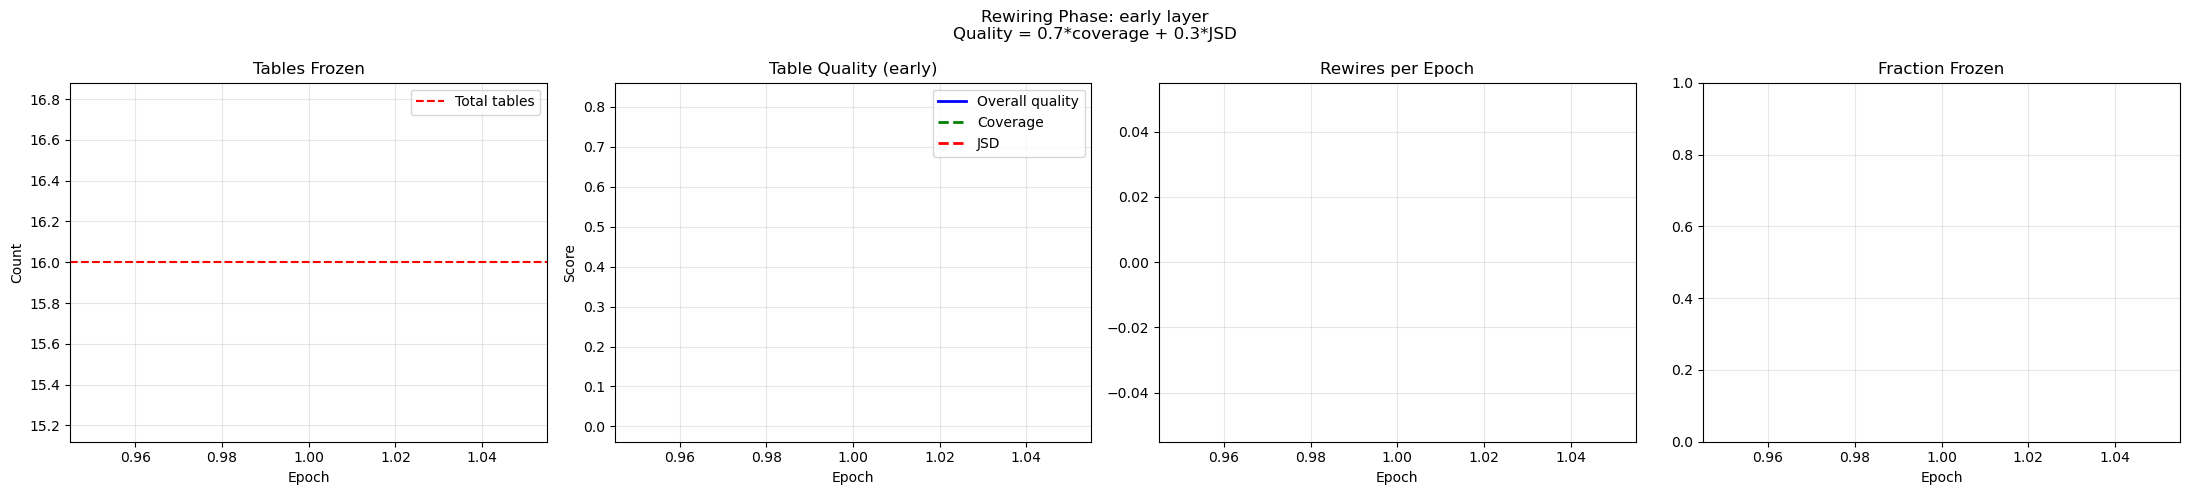


Final Table Quality (early layer):
Table     Quality   Coverage      JSD   Purity  Rows used  Rewires
--------------------------------------------------------------------
0           0.871      0.871    0.001    0.516   16/16          0  █████████████████
1           0.865      0.865    0.003    0.528   16/16          0  █████████████████
2           0.877      0.877    0.004    0.533   16/16          0  █████████████████
3           0.795      0.795    0.002    0.525   16/16          0  ███████████████
4           0.857      0.857    0.004    0.527   16/16          0  █████████████████
5           0.890      0.890    0.003    0.527   16/16          0  █████████████████
6           0.807      0.807    0.003    0.525   16/16          0  ████████████████
7           0.807      0.807    0.002    0.526   16/16          0  ████████████████
8           0.814      0.814    0.002    0.522   16/16          0  ████████████████
9           0.784      0.784    0.004    0.522   16/16          0  █

KeyboardInterrupt: 

In [385]:
results = full_rewiring_and_training_pipeline(
    train_loader    = twoclasstrain_loader,
    val_loader      = twoclassval_loader,
    out_channels1   = 16,
    out_channels2   = 32,
    n_comparisons1  = 4,
    n_comparisons2  = 4,
    n_epochs_rewire = 30,
    n_epochs_train  = 50,
    theta_h         = 0.1,
    theta_l         = -0.5,
    r_pr            = 0.1
)

model = results['model']

In [392]:
def alternating_train_and_rewire_v2(
    train_loader, val_loader,
    num_classes       = 2,
    out_channels1     = 16,
    out_channels2     = 32,
    n_comparisons1    = 4,
    n_comparisons2    = 4,
    n_epochs_warmup   = 10,
    n_epochs_rewire2  = 20,
    n_epochs_final    = 40,
    theta_h           = 5.0,
    theta_l           = -5.0,
    r_pr              = 0.1,
    lr                = 0.01,
    seed              = 42
):
    rng   = np.random.default_rng(seed)
    model = SecondLUTConvV2_LinearModel(
        num_classes    = num_classes,
        out_channels1  = out_channels1,
        out_channels2  = out_channels2,
        n_comparisons1 = n_comparisons1,
        n_comparisons2 = n_comparisons2,
        seed           = seed
    )
    
    full_history = {
        'train_acc': [], 'val_acc': [],
        'train_loss': [], 'val_loss': [],
        'epochs': [], 'phase': []
    }
    
    # Phase 1: warmup
    print("="*60)
    print(f"PHASE 1: Warmup ({n_epochs_warmup} epochs)")
    print("="*60)
    
    h1 = train_n_epochs(
        model, train_loader, val_loader,
        n_epochs_warmup, lr, 'warmup'
    )
    append_history(full_history, h1, 'warmup')
    
    # Diagnose signal before rewiring
    print("\nDiagnosing conv1 output signal...")
    best_jsd, fdr_per_dim, n_useful = \
        diagnose_conv2_rewiring_signal(
            model, train_loader
        )
    
    # Phase 2: rewire conv2
    print("\n" + "="*60)
    print(f"PHASE 2: Rewire Conv2 ({n_epochs_rewire2} epochs)")
    print(f"Available signal: best_jsd={best_jsd:.4f}  "
          f"useful_pairs={n_useful}")
    print("="*60)
    
    conv2_rewire = RewirableLUTConvLayerV2(
        in_channels   = out_channels1,
        out_channels  = out_channels2,
        kernel_size   = 3,
        n_comparisons = n_comparisons2,
        rng           = rng,
        layer_type    = 'late',
        theta_h       = theta_h,
        theta_l       = theta_l,
        r_pr          = r_pr
    )
    
    # Start from current conv2 anchors
    conv2_rewire.lut.anchors_a = \
        model.conv2.lut.anchors_a.copy()
    conv2_rewire.lut.anchors_b = \
        model.conv2.lut.anchors_b.copy()
    
    class TrainedConv1Loader:
        def __iter__(self_inner):
            for images, labels in train_loader:
                batch_out    = []
                batch_labels = []
                for img, label in zip(images, labels):
                    x      = preprocess_for_lut(img)
                    out1   = model.conv1.forward(x)
                    out1   = np.maximum(0, out1)
                    out1_p = model.pool1.forward(out1)
                    batch_out.append(out1_p)
                    batch_labels.append(
                        label.item()
                        if hasattr(label, 'item')
                        else int(label)
                    )
                yield batch_out, batch_labels
    
    rewire_history = conv2_rewire.run_rewiring_phase(
        TrainedConv1Loader(),
        num_classes  = num_classes,
        n_epochs_max = n_epochs_rewire2
    )
    
    # Install rewired anchors
    model.conv2.lut.anchors_a = \
        conv2_rewire.lut.anchors_a.copy()
    model.conv2.lut.anchors_b = \
        conv2_rewire.lut.anchors_b.copy()
    
    # Phase 3: final training
    print("\n" + "="*60)
    print(f"PHASE 3: Final Training ({n_epochs_final} epochs)")
    print("="*60)
    
    h3 = train_n_epochs(
        model, train_loader, val_loader,
        n_epochs_final, lr, 'final'
    )
    append_history(full_history, h3, 'final')
    
    save_second_lutconvv2_model(
        model, 'alternating_rewire_v2.pkl', full_history
    )
    plot_full_history(full_history)
    
    return model, full_history, rewire_history

def train_n_epochs(model, train_loader, val_loader,
                    n_epochs, lr, phase_name=''):
    """
    Train for exactly n_epochs
    Returns history dict
    """
    history = {
        'train_acc':  [],
        'val_acc':    [],
        'train_loss': [],
        'val_loss':   [],
        'epochs':     []
    }
    
    best_val_acc  = 0.0
    best_val_loss = float('inf')
    
    def rescale(g, tgt=0.1, eps=1e-8):
        n = np.linalg.norm(g)
        return g * (tgt / n) if n > eps else g
    
    for epoch in range(1, n_epochs + 1):
        
        model.training = True
        correct        = 0
        total          = 0
        epoch_loss     = 0.0
        
        for images, labels in train_loader:
            for img_tensor, label in zip(images, labels):
                x      = preprocess_for_lut(img_tensor)
                target = label.item()
                
                logits            = model.forward(x)
                loss, logits_grad = cross_entropy_from_logits(
                    logits, target
                )
                epoch_loss += loss
                
                if np.argmax(logits) == target:
                    correct += 1
                total += 1
                
                model.backward(logits_grad, lr)
        
        avg_train_loss = epoch_loss / total
        train_acc      = 100 * correct / total
        
        model.training = False
        val_correct    = 0
        val_total      = 0
        val_loss       = 0.0
        
        for images, labels in val_loader:
            for img_tensor, label in zip(images, labels):
                x      = preprocess_for_lut(img_tensor)
                target = label.item()
                logits = model.forward(x)
                loss, _ = cross_entropy_from_logits(
                    logits, target
                )
                val_loss += loss
                if np.argmax(logits) == target:
                    val_correct += 1
                val_total += 1
        
        avg_val_loss = val_loss / val_total
        val_acc      = 100 * val_correct / val_total
        
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['epochs'].append(epoch)
        
        print(f"[{phase_name}] Epoch {epoch:3d}/{n_epochs}  "
              f"Train: {train_acc:.1f}%  "
              f"Val: {val_acc:.1f}%  "
              f"Loss: {avg_train_loss:.4f}")
    
    return history


def append_history(full_history, phase_history, phase_name):
    """Append phase history to full history"""
    offset = len(full_history['epochs'])
    for i, epoch in enumerate(phase_history['epochs']):
        full_history['epochs'].append(offset + epoch)
        full_history['train_acc'].append(
            phase_history['train_acc'][i]
        )
        full_history['val_acc'].append(
            phase_history['val_acc'][i]
        )
        full_history['train_loss'].append(
            phase_history['train_loss'][i]
        )
        full_history['val_loss'].append(
            phase_history['val_loss'][i]
        )
        full_history['phase'].append(phase_name)


def check_s_table_quality(conv_layer, name='conv'):
    """
    Check how much S tables have diverged from zero
    More divergence = more meaning
    """
    S = conv_layer.lut.S
    
    mean_abs = np.abs(S).mean()
    max_abs  = np.abs(S).max()
    std_S    = S.std()
    
    print(f"  {name} S table statistics:")
    print(f"    Mean |S|: {mean_abs:.4f}")
    print(f"    Max  |S|: {max_abs:.4f}")
    print(f"    Std  S:   {std_S:.4f}")
    
    if mean_abs < 0.1:
        print(f"    ⚠️  S tables barely diverged from zero")
        print(f"    Conv1 output still near random")
        print(f"    Consider more warmup epochs")
    elif mean_abs > 0.5:
        print(f"    ✅ S tables well diverged")
        print(f"    Conv1 output should be meaningful")
    else:
        print(f"    ✅ S tables partially diverged")
    
    return mean_abs


def check_conv1_output_fdr(model, train_loader,
                             n_samples=30):
    """
    Measure FDR of conv1 output after warmup
    Higher FDR = more class-separating conv1 output
    = better input for conv2 rewiring
    """
    c0_feats = []
    c1_feats = []
    counts   = {0: 0, 1: 0}
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_samples:
                continue
            x      = preprocess_for_lut(img)
            out1   = model.conv1.forward(x)
            out1   = np.maximum(0, out1)
            out1_p = model.pool1.forward(out1)
            if cls == 0:
                c0_feats.append(out1_p.flatten())
            else:
                c1_feats.append(out1_p.flatten())
            counts[cls] += 1
        if all(v >= n_samples for v in counts.values()):
            break
    
    c0   = np.array(c0_feats)
    c1   = np.array(c1_feats)
    m0   = c0.mean(0)
    m1   = c1.mean(0)
    v0   = c0.var(0)
    v1   = c1.var(0)
    within = (v0 + v1) / 2
    valid  = within > 1e-4
    fdr    = float(
        (((m0-m1)**2)[valid] / within[valid]).mean()
    ) if valid.sum() > 0 else 0
    fdr    = min(fdr, 100)
    
    print(f"  Conv1 output FDR: {fdr:.4f}")
    if fdr < 0.1:
        print(f"  ⚠️  Very low FDR")
        print(f"  Conv2 rewiring may still struggle")
        print(f"  Consider more warmup epochs")
    elif fdr > 0.5:
        print(f"  ✅ Good FDR - conv2 rewiring should work")
    
    return fdr


def check_conv2_table_quality(model, train_loader,
                               n_samples=30):
    """
    After rewiring: check if conv2 tables improved
    Compare JSD before and after
    """
    # Collect conv2 input patches
    c0_patches = []
    c1_patches = []
    counts     = {0: 0, 1: 0}
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_samples:
                continue
            x      = preprocess_for_lut(img)
            out1   = model.conv1.forward(x)
            out1   = np.maximum(0, out1)
            out1_p = model.pool1.forward(out1)
            
            # Get conv2 patches
            C, H, W = out1_p.shape
            pad     = model.conv2.kernel_size // 2
            x_pad   = np.pad(out1_p,
                             ((0,0),(pad,pad),(pad,pad)))
            patches = model.conv2.im2col_vectorized(
                x_pad, H, W
            )
            if cls == 0:
                c0_patches.append(patches)
            else:
                c1_patches.append(patches)
            counts[cls] += 1
        if all(v >= n_samples for v in counts.values()):
            break
    
    c0_patches = np.vstack(c0_patches)
    c1_patches = np.vstack(c1_patches)
    
    # Measure JSD per table using conv2 anchors
    table_size = 1 << model.conv2.lut.n_comparisons
    jsds       = []
    
    for t in range(model.conv2.n_tables):
        
        def get_rows(patches):
            vals_a = patches[:, model.conv2.lut.anchors_a[t]]
            vals_b = patches[:, model.conv2.lut.anchors_b[t]]
            diffs  = vals_a - vals_b
            powers = 1 << np.arange(
                model.conv2.lut.n_comparisons
            )
            bits   = (diffs > 0).astype(np.int64)
            return (bits * powers[None, :]).sum(axis=1)
        
        rows0 = get_rows(c0_patches)
        rows1 = get_rows(c1_patches)
        
        h0 = np.bincount(rows0, minlength=table_size)
        h1 = np.bincount(rows1, minlength=table_size)
        
        d0  = h0 / (h0.sum() + 1e-10)
        d1  = h1 / (h1.sum() + 1e-10)
        m   = (d0 + d1) / 2
        eps = 1e-10
        jsd = 0.5 * np.sum(
            d0 * np.log2(d0 / (m + eps) + eps)
        ) + 0.5 * np.sum(
            d1 * np.log2(d1 / (m + eps) + eps)
        )
        jsds.append(float(np.clip(jsd, 0, 1)))
    
    print(f"  Conv2 table JSD after rewiring:")
    print(f"    Mean JSD: {np.mean(jsds):.4f}")
    print(f"    Max  JSD: {np.max(jsds):.4f}")
    print(f"    Tables with JSD>0.05: "
          f"{sum(j>0.05 for j in jsds)}/{len(jsds)}")
    
    return jsds


def plot_full_history(full_history):
    """
    Plot training history with phase markers
    """
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    epochs     = full_history['epochs']
    train_acc  = full_history['train_acc']
    val_acc    = full_history['val_acc']
    train_loss = full_history['train_loss']
    val_loss   = full_history['val_loss']
    phases     = full_history['phase']
    
    # Find phase transition points
    transitions = []
    for i in range(1, len(phases)):
        if phases[i] != phases[i-1]:
            transitions.append(epochs[i])
    
    for ax, (y1, y2, title, ylabel) in zip(axes, [
        (train_acc, val_acc,
         'Accuracy', 'Accuracy %'),
        (train_loss, val_loss,
         'Loss', 'Loss')
    ]):
        ax.plot(epochs, y1, label='Train',
                color='blue', linewidth=2)
        ax.plot(epochs, y2, label='Val',
                color='orange', linewidth=2)
        
        # Mark phase transitions
        for t in transitions:
            ax.axvline(x=t, color='red',
                       linestyle='--', alpha=0.7)
        
        # Label phases
        if transitions:
            mid1 = transitions[0] / 2
            ax.text(mid1, ax.get_ylim()[0],
                    'Warmup', ha='center',
                    fontsize=9, color='gray')
            
            if len(transitions) > 1:
                mid3 = (transitions[-1] +
                        epochs[-1]) / 2
            else:
                mid3 = (transitions[0] +
                        epochs[-1]) / 2
            ax.text(mid3, ax.get_ylim()[0],
                    'Final Training', ha='center',
                    fontsize=9, color='gray')
        
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    # Add rewiring annotation
    plt.suptitle(
        'Alternating Train and Rewire Pipeline\n'
        'Red dashed line = conv2 rewiring phase',
        fontsize=13
    )
    plt.tight_layout()
    plt.savefig('alternating_rewire_history.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    
def diagnose_conv2_rewiring_signal(model, train_loader,
                                    n_samples=50):
    """
    Understand what signal is available
    for conv2 rewiring
    
    Key question:
        Even if conv1 FDR is low
        is there a consistent PATTERN
        in conv1 outputs that differs between classes?
        
    Measures:
        1. FDR per conv1 channel (expected low)
        2. Cross channel correlation difference
           between classes
        3. Whether ANY anchor pair comparison
           of conv1 outputs achieves JSD > 0.02
    """
    c0_feats = []
    c1_feats = []
    counts   = {0: 0, 1: 0}
    
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            cls = label.item()
            if counts[cls] >= n_samples:
                continue
            x      = preprocess_for_lut(img)
            out1   = model.conv1.forward(x)
            out1   = np.maximum(0, out1)
            out1_p = model.pool1.forward(out1)
            
            if cls == 0:
                c0_feats.append(out1_p.flatten())
            else:
                c1_feats.append(out1_p.flatten())
            counts[cls] += 1
        if all(v >= n_samples for v in counts.values()):
            break
    
    c0 = np.array(c0_feats)   # (n, out_channels*H*W)
    c1 = np.array(c1_feats)
    
    feat_dim = c0.shape[1]
    
    print(f"Conv1 output shape: {c0.shape}")
    print()
    
    # ---- Metric 1: FDR per dimension ----
    m0     = c0.mean(0)
    m1     = c1.mean(0)
    v0     = c0.var(0)
    v1     = c1.var(0)
    within = (v0 + v1) / 2
    valid  = within > 1e-4
    
    fdr_per_dim = np.zeros(feat_dim)
    fdr_per_dim[valid] = (
        (m0[valid] - m1[valid])**2 / within[valid]
    )
    
    print(f"Per-dimension FDR:")
    print(f"  Mean:              {fdr_per_dim.mean():.4f}")
    print(f"  Max:               {fdr_per_dim.max():.4f}")
    print(f"  Dims with FDR>0.1: "
          f"{(fdr_per_dim > 0.1).sum()}/{feat_dim}")
    print(f"  Dims with FDR>0.5: "
          f"{(fdr_per_dim > 0.5).sum()}/{feat_dim}")
    print()
    
    # ---- Metric 2: Are ANY anchor pair comparisons useful? ----
    # Sample subset of dimensions for speed
    n_test    = min(feat_dim, 200)
    test_dims = np.random.choice(feat_dim, n_test,
                                  replace=False)
    
    best_jsd  = 0
    best_pair = (0, 1)
    n_above_threshold = 0
    
    for a in test_dims:
        for b in test_dims:
            if a == b:
                continue
            bits_0  = (c0[:, a] > c0[:, b]).astype(float)
            bits_1  = (c1[:, a] > c1[:, b]).astype(float)
            p0      = bits_0.mean()
            p1      = bits_1.mean()
            
            eps     = 1e-10
            m       = (p0 + p1) / 2
            
            def h(p):
                if p < eps or p > 1-eps:
                    return 0
                return -(p*np.log2(p+eps) +
                          (1-p)*np.log2(1-p+eps))
            
            jsd = h(m) - 0.5*(h(p0) + h(p1))
            
            if jsd > best_jsd:
                best_jsd  = jsd
                best_pair = (a, b)
                best_p0   = p0
                best_p1   = p1
            
            if jsd > 0.02:
                n_above_threshold += 1
    
    print(f"Pairwise comparison of conv1 outputs:")
    print(f"  Tested {n_test*n_test} pairs (sample)")
    print(f"  Best JSD:          {best_jsd:.4f}")
    print(f"  Best pair:         dim {best_pair[0]} "
          f"vs dim {best_pair[1]}")
    print(f"  Best p0={best_p0:.3f}  p1={best_p1:.3f}")
    print(f"  Pairs with JSD>0.02: {n_above_threshold}")
    print()
    
    # ---- Metric 3: Cross-table pattern difference ----
    # Reshape to (n, out_channels, H*W)
    out_ch  = model.out_channels1
    spatial = c0.shape[1] // out_ch
    
    c0_ch   = c0.reshape(len(c0), out_ch, spatial)
    c1_ch   = c1.reshape(len(c1), out_ch, spatial)
    
    # Mean activation per channel per class
    c0_mean_per_ch = c0_ch.mean(axis=(0, 2))   # (out_ch,)
    c1_mean_per_ch = c1_ch.mean(axis=(0, 2))   # (out_ch,)
    
    print(f"Per-channel mean activation:")
    print(f"{'Ch':<5} {'Class0':>8} {'Class1':>8} "
          f"{'Diff':>8}")
    print(f"{'-'*35}")
    
    max_diff = 0
    for ch in range(out_ch):
        diff = abs(c0_mean_per_ch[ch] - c1_mean_per_ch[ch])
        if diff > max_diff:
            max_diff = diff
        bar = '█' * int(diff * 50)
        print(f"{ch:<5} {c0_mean_per_ch[ch]:>8.4f} "
              f"{c1_mean_per_ch[ch]:>8.4f} "
              f"{diff:>8.4f}  {bar}")
    
    print()
    print(f"Max per-channel mean diff: {max_diff:.4f}")
    
    if best_jsd < 0.02:
        print()
        print("CONCLUSION:")
        print("  No useful signal for conv2 rewiring yet")
        print("  Conv1 S tables need more training")
        print(f"  Current best JSD = {best_jsd:.4f}")
        print(f"  Need JSD > 0.02 for rewiring to work")
    else:
        print()
        print("CONCLUSION:")
        print(f"  Signal available for conv2 rewiring")
        print(f"  Best JSD = {best_jsd:.4f}")
        print(f"  {n_above_threshold} useful anchor pairs found")
    
    return best_jsd, fdr_per_dim, n_above_threshold

PHASE 1: Warmup (10 epochs)
[warmup] Epoch   1/10  Train: 51.7%  Val: 60.0%  Loss: 0.7505
[warmup] Epoch   2/10  Train: 53.1%  Val: 67.5%  Loss: 0.7452
[warmup] Epoch   3/10  Train: 63.1%  Val: 45.0%  Loss: 0.6777
[warmup] Epoch   4/10  Train: 60.9%  Val: 65.0%  Loss: 0.6752
[warmup] Epoch   5/10  Train: 62.9%  Val: 52.5%  Loss: 0.6534
[warmup] Epoch   6/10  Train: 61.8%  Val: 50.0%  Loss: 0.6922
[warmup] Epoch   7/10  Train: 59.4%  Val: 70.0%  Loss: 0.6781
[warmup] Epoch   8/10  Train: 63.1%  Val: 70.0%  Loss: 0.6572
[warmup] Epoch   9/10  Train: 63.8%  Val: 55.0%  Loss: 0.6560
[warmup] Epoch  10/10  Train: 62.2%  Val: 55.0%  Loss: 0.6702

Diagnosing conv1 output signal...
Conv1 output shape: (50, 4096)

Per-dimension FDR:
  Mean:              0.0475
  Max:               0.5517
  Dims with FDR>0.1: 575/4096
  Dims with FDR>0.5: 4/4096

Pairwise comparison of conv1 outputs:
  Tested 40000 pairs (sample)
  Best JSD:          0.1348
  Best pair:         dim 160 vs dim 3881
  Best p0=0.90

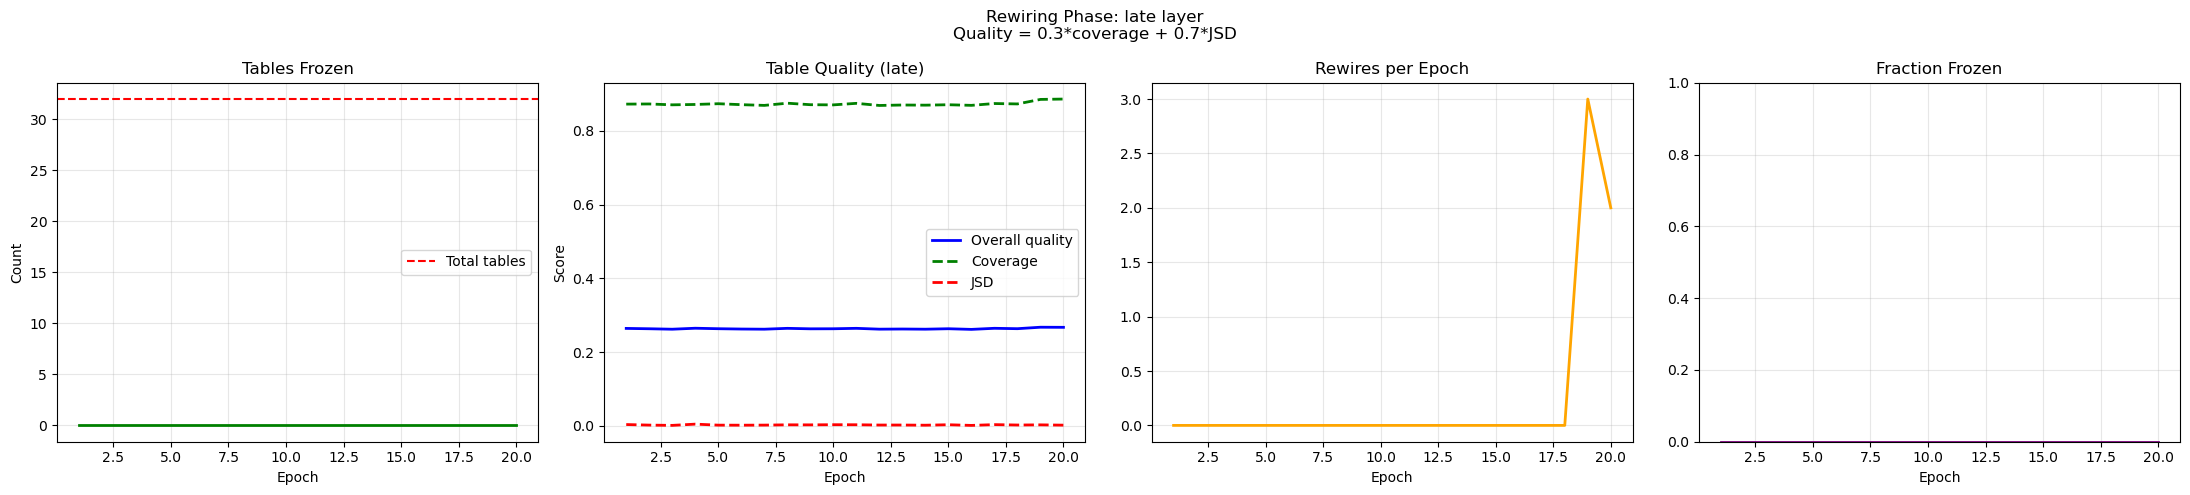


Final Table Quality (late layer):
Table     Quality   Coverage      JSD   Purity  Rows used  Rewires
--------------------------------------------------------------------
0           0.255      0.845    0.002    0.521   16/16          0  █████
1           0.281      0.932    0.001    0.519   16/16          0  █████
2           0.277      0.917    0.002    0.518   16/16          0  █████
3           0.256      0.848    0.003    0.521   16/16          0  █████
4           0.273      0.904    0.002    0.518   16/16          0  █████
5           0.257      0.852    0.001    0.516   16/16          0  █████
6           0.263      0.874    0.002    0.518   16/16          0  █████
7           0.248      0.825    0.001    0.513   16/16          0  ████
8           0.273      0.908    0.001    0.511   16/16          0  █████
9           0.276      0.915    0.003    0.526   16/16          0  █████
10          0.257      0.852    0.002    0.521   16/16          1  █████
11          0.275      0.91

KeyboardInterrupt: 

In [393]:
model, history, rewire_hist = alternating_train_and_rewire_v2(
    train_loader      = twoclasstrain_loader,
    val_loader        = twoclassval_loader,
    out_channels1     = 16,
    out_channels2     = 32,
    n_comparisons1    = 4,
    n_comparisons2    = 4,
    n_epochs_warmup   = 10,
    n_epochs_rewire2  = 20,
    n_epochs_final    = 40,
    theta_h           = 5.0,
    theta_l           = -5.0,
    lr                = 0.001
)
